# 📊 Phase 02B — GPR EDA & Data Cleaning  [v7]
### Research Project: Regime Detection — NIFTY50 · BANKNIFTY · NIFTYNEXT50
**Author:** Swagato M25AI2107 | **Drive Folder:** `MyDrive/Regime_Detection_Swagato_M25AI2107/`

---

## 🗺️ What This Notebook Does

This notebook performs comprehensive **Exploratory Data Analysis (EDA) and Data Cleaning** of all Phase 01B v7 outputs. It saves a base cleaned monthly table (`gpr_combined_monthly_clean_base.csv`) for feature engineering, then saves a cleaned-plus-engineered table (`gpr_combined_monthly_clean.csv`) for Phase 03 modelling.

| # | Section | Purpose |
|---|---------|---------|
| 0 | **[SETUP]** | Libraries, paths, shared helpers |
| 1 | **[LOAD]** | Load & inventory all Phase 01B outputs |
| 2 | **[COVERAGE]** | Missing-data analysis & source-flag audit |
| 2D | **[CLEAN]** | Data cleaning pipeline (dedup, impute, winsorise, derive) |
| 3 | **[GPR]** | GPR Index deep dive (global, India, sub-components, variants) |
| 4 | **[CORPUS]** | News corpus composition & word-cloud |
| 5 | **[SENTIMENT]** | Net sentiment trends, uncertainty, momentum, per-category |
| 6 | **[RISK-CAT]** | Risk-category distribution & keyword-density scores |
| 7 | **[EVENTS]** | Regime-event frequency, density, reform & high-event analysis |
| 8 | **[FRED]** | FRED macro feature coverage, trends, distributions |
| 9 | **[CORR]** | Cross-feature Spearman correlation heatmap & scatter plots |
| 10 | **[COMPOSITE]** | Composite GPR stress score & quartile validation |
| 11 | **[ERAS]** | Temporal regime segmentation across 9 market eras |
| 12 | **[ANOMALY]** | Outlier detection (|z| > 3σ) per feature |
| 13 | **[FEAT-VAL]** | Derived FRED feature validation & GPR/sentiment sub-period correlation |
| 14 | **[MACRO-SIG]** | Yield-curve inversion, ACF/PACF lag structure, INR depreciation |
| 15 | **[SRC-QUAL]** | Article-density diagnostics & title-quality audit |
| 16 | **[AV]** | Alpha Vantage sentiment EDA |
| 17 | **[GDELT2]** | GDELT 2.0 volume & tone analysis |
| 18 | **[EVENT-GPR]** | Regime-event driven GPR decomposition |
| 19 | **[SUSTAIN]** | Sustainability & Climate-Risk EDA (§4.2.6) |
| 19h | **[CPU-FEAT]** | CPU 3M/6M MA & spike flag validation |
| 19i | **[GDELT1-TONE]** | GDELT 1.0 tone proxy vs FinBERT deep validation |
| 19j | **[MARKET-DATA]** | India VIX · USD/INR · Gold — EDA & regime signals |
| 20 | **[SUMMARY]** | EDA scorecard & Phase 03 readiness recommendations |

---

## 📂 Input Files (Phase 01B v7 outputs)

```
Data/
├── cleaned/
|   ├── news_corpus_all.csv            ← Unified deduplicated news corpus (all 5 sources, 2000–2026)
|   ├── news_corpus_all_sentiment.csv  ← Corpus with FinBERT sentiment scores added
|   └── gpr_combined_monthly.csv       ← Master feature table — one row per month, all features
├── raw/
│   ├── gpr/gpr_monthly.csv
│   ├── sentiment/news_sentiment_monthly.csv     ← Monthly sentiment + category counts
│   ├── regime_events/regime_events.csv
│   ├── regime_events/regime_events_monthly.csv
│   ├── fred/fred_india_macro.csv
│   ├── alphavantage/av_monthly_sentiment.csv
│   ├── gdelt/gdelt2_master.csv
│   ├── gdelt/gdelt1_monthly_tone.csv
│   ├── climate_policy/cpu_monthly.csv
│   ├── other_market_data/other_market_data_combined.csv
│   ├── rss/news_master.csv
│   └── yfinance/yfinance_news.csv
```

## 📂 Output Files

```
Data/cleaned/gpr_combined_monthly_clean_base.csv  ← Base cleaned table for feature engineering
Data/cleaned/gpr_combined_monthly_clean.csv       ← Cleaned + engineered Phase 03 input
Output/EDA_Plots/                                 ← All EDA figures (PNG)
```

---

---
## 0. Setup: Install Libraries & Configure Paths

In [1]:
# ── Mount Google Drive (skip if running locally) ──────────────────────────────
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    print('✅ Running in Colab — Drive mounted')
except ImportError:
    IN_COLAB = False
    print('ℹ️  Running locally — set DATA_DIR below')

Mounted at /content/drive
✅ Running in Colab — Drive mounted


In [2]:
!pip install -q missingno wordcloud scipy statsmodels plotly pandas_market_calendars

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.9/134.9 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 213.3/213.3 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ibis-framework 9.5.0 requires toolz<1,>=0.11, but you have toolz 1.1.0 which is incompatible.


In [3]:
import os, warnings, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from scipy.stats import spearmanr, mannwhitneyu, kruskal
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from wordcloud import WordCloud
import missingno as msno
import pandas_market_calendars as mcal

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10, 'figure.facecolor': 'white'})
sns.set_theme(style='darkgrid', palette='muted')

# ── Shared helpers & constants ────────────────────────────────────────────────
STRESS_COLORS = {'low': '#2ecc71', 'moderate': '#f39c12', 'elevated': '#e67e22', 'high': '#e74c3c'}
wedge_colors  = ['#3498db', '#e67e22', '#2ecc71', '#e74c3c', '#9b59b6', '#1abc9c']

def _save(fname):
    """Save current figure to PLOT_DIR."""
    path = os.path.join(PLOT_DIR, fname)
    plt.savefig(path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {path}')

print('✅ Libraries ready.')

✅ Libraries ready.


In [4]:
GDRIVE_BASE  = '/content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107'
DATA_ROOT    = os.path.join(GDRIVE_BASE, 'Data')
RAW          = os.path.join(DATA_ROOT, 'raw')
CLEANED_DIR  = os.path.join(GDRIVE_BASE, 'Data', 'cleaned')
PLOT_DIR     = os.path.join(GDRIVE_BASE, 'Output', 'EDA_Plots')
os.makedirs(PLOT_DIR, exist_ok=True)

# ── Input paths (Phase 01B v6 outputs) ────────────────────────────────────────
COMBINED_PATH    = os.path.join(CLEANED_DIR,          'gpr_combined_monthly.csv')
CORPUS_PATH      = os.path.join(CLEANED_DIR,          'news_corpus_all.csv')
CORPUS_SENT_PATH = os.path.join(CLEANED_DIR,          'news_corpus_all_sentiment.csv')
GPR_PATH         = os.path.join(RAW, 'gpr',           'gpr_monthly.csv')
SENTIMENT_PATH   = os.path.join(RAW, 'sentiment',     'news_sentiment_monthly.csv')
EVENTS_PATH      = os.path.join(RAW, 'regime_events', 'regime_events.csv')
EVENTS_MON_PATH  = os.path.join(RAW, 'regime_events', 'regime_events_monthly.csv')
FRED_PATH        = os.path.join(RAW, 'fred',          'fred_india_macro.csv')
AV_PATH          = os.path.join(RAW, 'alphavantage',  'av_monthly_sentiment.csv')
GDELT2_PATH      = os.path.join(RAW, 'gdelt',         'gdelt2_master.csv')
GDELT1_PATH      = os.path.join(RAW, 'gdelt',         'gdelt1_monthly_tone.csv')
RSS_PATH         = os.path.join(RAW, 'rss',           'news_master.csv')
YF_PATH          = os.path.join(RAW, 'yfinance',       'yfinance_news.csv')
CPU_MONTHLY_PATH   = os.path.join(RAW, 'climate_policy','cpu_monthly.csv')
MARKET_DATA_PATH  = os.path.join(RAW, 'other_market_data','other_market_data_combined.csv')

# ── Output paths ───────────────────────────────────────────────────────────────
CLEAN_BASE_OUT = os.path.join(CLEANED_DIR, 'gpr_combined_monthly_clean_base.csv')
CLEAN_OUT      = os.path.join(CLEANED_DIR, 'gpr_combined_monthly_clean.csv')
os.makedirs(CLEANED_DIR, exist_ok=True)

# ── Phase01B v7 project date range ────────────────────────────────────────────
GPR_START = '2000-01'
GPR_END   = '2026-03'

print('✅ Paths configured.')
print(f'   Data root     : {DATA_ROOT}')
print(f'   Combined      : {COMBINED_PATH}')
print(f'   Base clean    : {CLEAN_BASE_OUT}')
print(f'   Clean output  : {CLEAN_OUT}')


✅ Paths configured.
   Data root     : /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Data
   Combined      : /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Data/cleaned/gpr_combined_monthly.csv
   Base clean    : /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Data/cleaned/gpr_combined_monthly_clean_base.csv
   Clean output  : /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Data/cleaned/gpr_combined_monthly_clean.csv


---
## 1. Data Loading & Inventory
**Research note**: Before any analysis, we establish what data is available, date coverage, and basic shape. This is the 'ground truth' audit of Phase 01B v7 outputs.

In [5]:
# ── Load master combined table ────────────────────────────────────────────────
df = pd.read_csv(COMBINED_PATH)

# Parse period as datetime for plotting
df['period_dt'] = pd.to_datetime(df['period'].astype(str) + '-01', errors='coerce')
df = df.sort_values('period_dt').reset_index(drop=True)

print('=' * 60)
print('MASTER COMBINED TABLE')
print('=' * 60)
print(f'Shape             : {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Date range        : {df["period"].min()} → {df["period"].max()}')
print(f'Total months      : {df["period"].nunique()}')
print(f'\nColumn categories :')
gpr_cols      = [c for c in df.columns if 'gpr' in c.lower()]
cpu_cols      = [c for c in df.columns if 'cpu' in c.lower()]
sent_cols     = [c for c in df.columns if any(x in c for x in ['sent', 'sentiment', 'positive', 'negative', 'neutral', 'pct_'])]
event_cols    = [c for c in df.columns if 'event' in c]
fred_cols     = [c for c in df.columns if any(x in c for x in ['rate_', 'fx_', 'inf_', 'mon_', 'gdp', 'credit', 'trade_', 'biz_', 'lead_', 'act_', 'mkt_', 'bop_', 'asset_'])]
risk_cat_cols = [c for c in df.columns if c.startswith('count_') or c.startswith('score_')]
sustain_cols  = [c for c in df.columns if any(x in c for x in ['climate', 'green_transition', 'esg', 'cpu', 'sustain'])]

for label, cols in [('GPR', gpr_cols), ('CPU', cpu_cols), ('Sentiment', sent_cols), ('Events', event_cols), ('FRED Macro', fred_cols), ('Risk Categories', risk_cat_cols), ('Sustainability', sustain_cols)]:
    print(f'  {label:25s}: {len(cols):2d} columns')
    print(f'  {" "*25}: {cols} columns')

other_n = list(set(df.columns).difference(set(gpr_cols+sent_cols+event_cols+fred_cols+risk_cat_cols+sustain_cols)))
print(f'  {"Other non-essential":25s}: {len(other_n):2d} columns')
print(f'  {" "*25}: {other_n} columns')

MASTER COMBINED TABLE
Shape             : 315 rows × 87 columns
Date range        : 2000-01 → 2026-03
Total months      : 315

Column categories :
  GPR                      : 13 columns
                           : ['gpr_global', 'gpr_global_threats', 'gpr_global_acts', 'gpr_global_hist', 'gpr_global_hist_threats', 'gpr_global_hist_acts', 'gpr_share', 'gpr_news_count', 'gpr_global_noew', 'gpr_global_and', 'gpr_global_basic', 'gpr_india', 'gpr_india_hist'] columns
  CPU                      :  3 columns
                           : ['cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis'] columns
  Sentiment                : 15 columns
                           : ['positive_mean', 'negative_mean', 'neutral_mean', 'net_sentiment_mean', 'net_sentiment_std', 'pct_positive', 'pct_negative', 'pct_neutral', 'sent_financial', 'sent_political', 'sent_climate', 'sent_green_transition', 'av_sentiment_mean', 'av_sentiment_std', 'credit_total_nonfin_pct_gdp'] columns
  Events              

In [6]:
# ── Load all Phase 01B v7 output files ────────────────────────────────────────
datasets = {}
load_map = {
    'corpus'     : CORPUS_PATH,
    'events'     : EVENTS_PATH,
    'events_mon' : EVENTS_MON_PATH,
    'sentiment'  : SENTIMENT_PATH,
    'fred'       : FRED_PATH,
    'gpr'        : GPR_PATH,
    'av'         : AV_PATH,
    'gdelt2'     : GDELT2_PATH,
    'gdelt1'     : GDELT1_PATH,
    'cpu_monthly'  : CPU_MONTHLY_PATH,
    'market_data'  : MARKET_DATA_PATH,
}
for name, path in load_map.items():
    if os.path.exists(path):
        datasets[name] = pd.read_csv(path)
        print(f'✅ {name:12s}: {datasets[name].shape[0]:>8,} rows × {datasets[name].shape[1]:>3} cols | {os.path.basename(path)}')
    else:
        datasets[name] = pd.DataFrame()
        print(f'⚠️  {name:12s}: NOT FOUND — {path}')

corpus      = datasets.get('corpus',     pd.DataFrame())
events      = datasets.get('events',     pd.DataFrame())
events_mon  = datasets.get('events_mon', pd.DataFrame())
fred        = datasets.get('fred',       pd.DataFrame())
av_sent     = datasets.get('av',         pd.DataFrame())
gdelt2      = datasets.get('gdelt2',     pd.DataFrame())
gdelt1      = datasets.get('gdelt1',     pd.DataFrame())
cpu_monthly  = datasets.get('cpu_monthly',  pd.DataFrame())
market_data  = datasets.get('market_data',  pd.DataFrame())
risk_cat_df  = datasets.get('sentiment',    pd.DataFrame())

print(f'\n\n✅ Loaded all datasets')

✅ corpus      :   12,940 rows ×  10 cols | news_corpus_all.csv
✅ events      :      207 rows ×   5 cols | regime_events.csv
✅ events_mon  :      315 rows ×   9 cols | regime_events_monthly.csv
✅ sentiment   :      215 rows ×  23 cols | news_sentiment_monthly.csv
✅ fred        :      314 rows ×  24 cols | fred_india_macro.csv
✅ gpr         :    1,517 rows ×  14 cols | gpr_monthly.csv
✅ av          :        2 rows ×   4 cols | av_monthly_sentiment.csv
✅ gdelt2      :   25,816 rows ×   7 cols | gdelt2_master.csv
✅ gdelt1      :       22 rows ×   5 cols | gdelt1_monthly_tone.csv
✅ cpu_monthly :      462 rows ×   4 cols | cpu_monthly.csv
✅ market_data :      308 rows ×  10 cols | other_market_data_combined.csv


✅ Loaded all datasets


In [7]:
# ── Display first few rows of combined table ───────────────────────────────────
print('Sample rows (combined table):')
display(df[['period'] + gpr_cols[:4] + sent_cols[:4] + event_cols[:3]].head(5))

Sample rows (combined table):


,period,gpr_global,gpr_global_threats,gpr_global_acts,gpr_global_hist,positive_mean,negative_mean,neutral_mean,net_sentiment_mean,event_election,event_union_budget,event_rbi_policy
0,2000-01,64.457809,65.573601,64.250412,52.966461,NaN,NaN,NaN,NaN,0,0,1
1,2000-02,63.541721,57.651360,68.082169,54.460442,NaN,NaN,NaN,NaN,0,1,0
2,2000-03,50.101986,55.030735,40.816406,39.381897,NaN,NaN,NaN,NaN,0,0,0
3,2000-04,48.682739,53.304905,40.917027,39.660149,NaN,NaN,NaN,NaN,0,0,1
4,2000-05,79.482880,77.269699,83.227814,60.203789,NaN,NaN,NaN,NaN,0,0,0


---
## 2. Coverage & Completeness Analysis
**Research note**: Missing data is not random — pre-2015 gaps reflect structural source limitations (no GDELT 2.0, limited Wayback coverage). Documenting this patterns Phase 02 imputation strategy.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot12a_missing_pct_by_feature.png


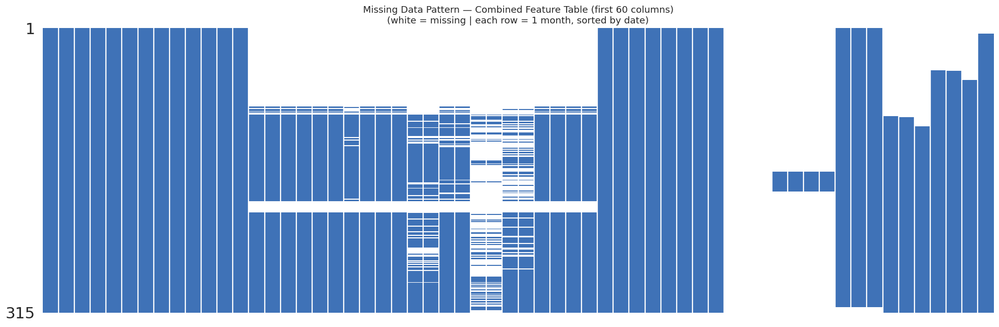

In [8]:
# ── 2a. Missing value heatmap ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(18, 6))
msno.matrix(df.drop(columns=['period', 'period_dt'], errors='ignore').iloc[:, :60],
            ax=ax, sparkline=False, color=(0.25, 0.45, 0.72))
ax.set_title('Missing Data Pattern — Combined Feature Table (first 60 columns)\n'
             '(white = missing | each row = 1 month, sorted by date)', fontsize=12)
plt.tight_layout()
_fig_name = 'Plot12a_missing_pct_by_feature.png'
_fig_path = os.path.join(PLOT_DIR, _fig_name)
plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
print(f'📁 Saved → {_fig_path}')
plt.show()

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot12b_missing_pct_by_feature.png


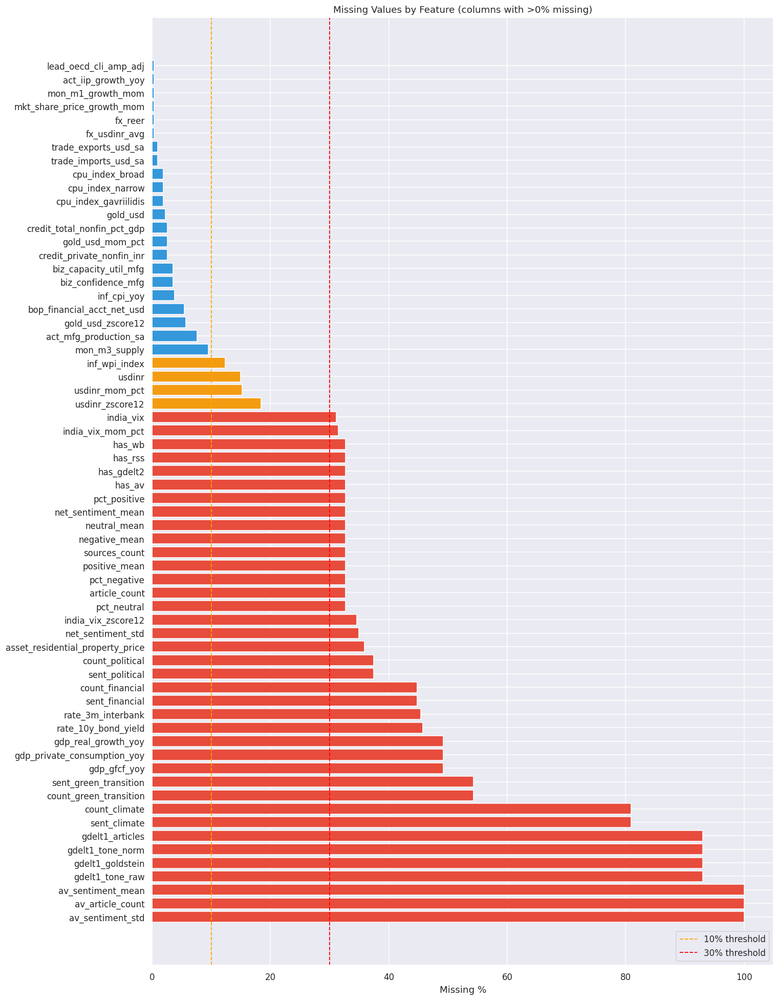


📊 Features with >30% missing: 38
   Features with 10–30% missing: 4
   Features with <10% missing:   22


In [9]:
# ── 2b. Missing % per column (grouped by feature category) ───────────────────
miss_pct = df.isnull().mean() * 100
miss_df  = miss_pct[miss_pct > 0].sort_values(ascending=False).reset_index()
miss_df.columns = ['feature', 'missing_pct']

if not miss_df.empty:
    fig, ax = plt.subplots(figsize=(14, max(6, len(miss_df) * 0.28)))
    colors = ['#e74c3c' if p > 30 else '#f39c12' if p > 10 else '#3498db'
              for p in miss_df['missing_pct']]
    ax.barh(miss_df['feature'], miss_df['missing_pct'], color=colors)
    ax.axvline(10, color='orange', linestyle='--', lw=1.2, label='10% threshold')
    ax.axvline(30, color='red',    linestyle='--', lw=1.2, label='30% threshold')
    ax.set_xlabel('Missing %')
    ax.set_title('Missing Values by Feature (columns with >0% missing)')
    ax.legend(loc='lower right')
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot12b_missing_pct_by_feature.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()
    print(f'\n📊 Features with >30% missing: {(miss_df.missing_pct > 30).sum()}')
    print(f'   Features with 10–30% missing: {((miss_df.missing_pct > 10) & (miss_df.missing_pct <= 30)).sum()}')
    print(f'   Features with <10% missing:   {(miss_df.missing_pct <= 10).sum()}')
else:
    print('✅ No missing values found in the combined table!')

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot12c_article_coverage.png


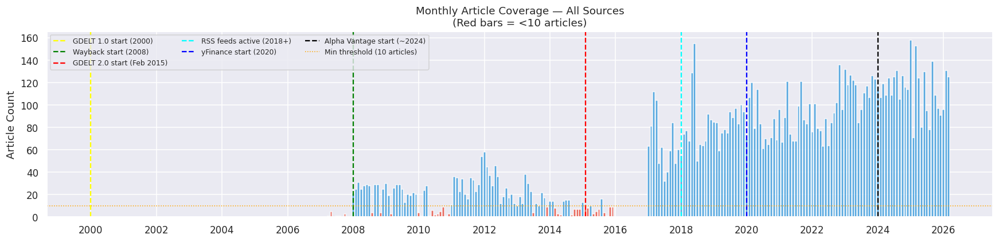


Article count stats:
  Median: 56 articles/month
  Min   : 1  Max: 158
  Sparse months (<10 articles): 139
  Sparse periods: ['2000-01', '2000-02', '2000-03', '2000-04', '2000-05', '2000-06', '2000-07', '2000-08', '2000-09', '2000-10', '2000-11', '2000-12', '2001-01', '2001-02', '2001-03', '2001-04', '2001-05', '2001-06', '2001-07', '2001-08']


In [10]:
# ── 2c. Article coverage over time ────────────────────────────────────────────
if 'article_count' in df.columns:
    fig, ax = plt.subplots(figsize=(16, 4))
    ax.bar(df['period_dt'], df['article_count'].fillna(0),
           color=['#e74c3c' if v < 10 else '#3498db' for v in df['article_count'].fillna(0)],
           width=25, alpha=0.8)
    ax.axvline(pd.Timestamp('2000-01-01'), color='yellow',  lw=1.5, linestyle='--', label='GDELT 1.0 start (2000)')
    ax.axvline(pd.Timestamp('2008-01-01'), color='green',   lw=1.5, linestyle='--', label='Wayback start (2008)')
    ax.axvline(pd.Timestamp('2015-02-01'), color='red',     lw=1.5, linestyle='--', label='GDELT 2.0 start (Feb 2015)')
    ax.axvline(pd.Timestamp('2018-01-01'), color='cyan',    lw=1.5, linestyle='--', label='RSS feeds active (2018+)')
    ax.axvline(pd.Timestamp('2020-01-01'), color='blue',    lw=1.5, linestyle='--', label='yFinance start (2020)')
    ax.axvline(pd.Timestamp('2024-01-01'), color='black',   lw=1.5, linestyle='--', label='Alpha Vantage start (~2024)')
    ax.axhline(10, color='orange', lw=1.0, linestyle=':', label='Min threshold (10 articles)')
    ax.set_title('Monthly Article Coverage — All Sources\n(Red bars = <10 articles)', fontsize=12)
    ax.set_ylabel('Article Count')
    ax.legend(fontsize=8, ncol=3)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _fig_name = 'Plot12c_article_coverage.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

    print(f'\nArticle count stats:')
    print(f'  Median: {df["article_count"].median():.0f} articles/month')
    print(f'  Min   : {df["article_count"].min():.0f}  Max: {df["article_count"].max():.0f}')
    sparse_months = df[df['article_count'].fillna(0) < 10]
    print(f'  Sparse months (<10 articles): {len(sparse_months)}')
    if not sparse_months.empty:
        print(f'  Sparse periods: {sparse_months["period"].tolist()[:20]}')


---
## 2D. Data Cleaning Pipeline
**Research note**: Systematic cleaning before EDA prevents plotting artifacts and misleading statistics. This section creates a complete month-by-month table and then prepares model-safe columns.

Cleaning steps applied here:
1. Trim to the project window and remove duplicate periods.
2. Reindex to the full monthly grid (`2000-01` → `2026-03`) so missing months are explicit.
3. Enforce numeric types while preserving identifiers.
4. Fill structural-zero columns (`event_*`, `count_*`, `has_*`, article/source counts) with 0.
5. Preserve raw sentiment, then create `net_sentiment_model` for EDA/model use.
6. Audit FRED quarterly-like columns without destroying valid non-null history.
7. Winsorise continuous macro columns only.
8. Deduplicate the article corpus.
9. Save `cleaned/gpr_combined_monthly_clean_base.csv` for feature engineering, then Section 2D-9 saves `cleaned/gpr_combined_monthly_clean.csv` with derived features.


In [11]:
# ── 2D-1. Trim, deduplicate, and force complete monthly grid ────────────────
GPR_START = '2000-01'
GPR_END   = '2026-03'

df_clean = df.copy()

# Drop duplicate columns defensively after repeated merges/notebook reruns.
dup_cols = df_clean.columns[df_clean.columns.duplicated()].tolist()
if dup_cols:
    df_clean = df_clean.loc[:, ~df_clean.columns.duplicated()]
    print(f'✅ Dropped duplicate columns: {dup_cols}')

# Normalise period key.
df_clean['period'] = df_clean['period'].astype(str).str.slice(0, 7)
df_clean['period_dt'] = pd.to_datetime(df_clean['period'] + '-01', errors='coerce')
df_clean = df_clean.dropna(subset=['period_dt'])
df_clean['period'] = df_clean['period_dt'].dt.to_period('M').astype(str)

# Trim project window.
df_clean = df_clean[
    (df_clean['period_dt'] >= pd.Timestamp(GPR_START + '-01')) &
    (df_clean['period_dt'] <= pd.Timestamp(GPR_END   + '-28'))
]

# Drop exact duplicate periods (keep first), then sort.
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset='period', keep='first')
df_clean = df_clean.sort_values('period_dt').reset_index(drop=True)
print(f'✅ Period dedup: {before} → {len(df_clean)} rows (dropped {before - len(df_clean)} duplicates)')

# Reindex to complete monthly grid so gaps are explicit rows, not invisible absences.
all_months = pd.period_range(GPR_START, GPR_END, freq='M')
present_before_grid = set(df_clean['period'].astype(str))
missing_m = [str(m) for m in all_months if str(m) not in present_before_grid]

df_clean = (
    df_clean.set_index(pd.PeriodIndex(df_clean['period'], freq='M'))
    .reindex(all_months)
    .rename_axis('period_idx')
    .reset_index()
)
df_clean['period'] = df_clean['period_idx'].astype(str)
df_clean = df_clean.drop(columns=['period_idx'])
df_clean['period_dt'] = df_clean['period'].apply(lambda x: pd.Period(x, freq='M').to_timestamp())
df_clean['missing_source_row'] = df_clean['period'].isin(missing_m).astype(int)

print(f'   Total expected months : {len(all_months)}')
print(f'   Present before grid   : {len(present_before_grid)}')
print(f'   Missing months added  : {len(missing_m)}')
if missing_m:
    print(f'   → Added gap periods: {missing_m[:10]}{"..." if len(missing_m) > 10 else ""}')

# Pre-define era labels here so downstream imputation can use them.
def assign_era(period_dt):
    yr = period_dt.year
    if yr < 2003: return '2000-02_Post_dotcom'
    elif yr < 2008: return '2003-07_Bull_Run'
    elif yr < 2010: return '2008-09_GFC'
    elif yr < 2014: return '2010-13_Recovery'
    elif yr < 2016: return '2014-15_Modi1'
    elif yr < 2020: return '2016-19_Reform'
    elif yr < 2022: return '2020-21_COVID'
    elif yr < 2024: return '2022-23_RateHike'
    else: return '2024plus_NewCycle'

df_clean['era'] = df_clean['period_dt'].apply(assign_era)
print('✅ Complete monthly grid + era labels ready.')


✅ Period dedup: 315 → 315 rows (dropped 0 duplicates)
   Total expected months : 315
   Present before grid   : 315
   Missing months added  : 0
✅ Complete monthly grid + era labels ready.


In [12]:
# ── 2D-2. Column-type enforcement and structural-zero fills. Force feature columns to numeric while preserving identifier/label columns.
str_cols = [
    'period', 'period_dt', 'era', 'gpr_stress_quartile',
    'source', 'source_group', 'sentiment_source'
]
str_cols = [c for c in str_cols if c in df_clean.columns]

for col in df_clean.columns:
    if col not in str_cols:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Structural zeros: absence of an event/source/count in a valid month means 0, not unknown. Continuous economic/sentiment/GPR values remain NaN until their own cleaning/imputation rules handle them.
event_flag_cols = [c for c in df_clean.columns if c.startswith('event_')]
source_flag_cols = [c for c in df_clean.columns if c.startswith('has_')]
count_cols = [c for c in df_clean.columns if c.startswith('count_') or c in ['article_count', 'sources_count', 'event_count', 'av_article_count', 'gdelt1_articles']]

for col in sorted(set(event_flag_cols + source_flag_cols + count_cols + ['missing_source_row'])):
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna(0).astype(int)

# Recompute high_event_month after event_count zero-fill if available.
if 'event_count' in df_clean.columns:
    df_clean['high_event_month'] = (df_clean['event_count'] >= 2).astype(int)

print('✅ Column type enforcement + structural-zero fills complete.')
print(f'   Numeric columns       : {df_clean.select_dtypes(include=np.number).shape[1]}')
print(f'   Object columns        : {df_clean.select_dtypes(include=object).shape[1]}')
print(f'   Event flag columns    : {len(event_flag_cols)}')
print(f'   Source flag columns   : {len(source_flag_cols)}')
print(f'   Count columns filled  : {len(count_cols)}')


✅ Column type enforcement + structural-zero fills complete.
   Numeric columns       : 86
   Object columns        : 2
   Event flag columns    : 7
   Source flag columns   : 4
   Count columns filled  : 9


In [13]:
# ── 2D-3. Structured sentiment preparation ─────────────────────────────────
# Phase 01B now saves collected monthly sentiment and GDELT1 tone separately.
# In EDA/cleaning we preserve raw `net_sentiment_mean`, then create a model-ready
# `net_sentiment_model` that can use GDELT1 tone for pre-2015 gaps.

if 'net_sentiment_mean' in df_clean.columns:
    df_clean['net_sentiment_raw'] = df_clean['net_sentiment_mean']

    # Binary flag: 1 = article-level FinBERT/AV monthly sentiment available.
    df_clean['is_finbert_sentiment'] = (
        (df_clean['period_dt'] >= '2015-02-01') &
        df_clean['net_sentiment_raw'].notna()
    ).astype(int)

    df_clean['sentiment_source'] = np.where(
        df_clean['net_sentiment_raw'].notna(),
        'finbert_av',
        'missing'
    )

    df_clean['net_sentiment_model'] = df_clean['net_sentiment_raw']

    # Use GDELT1 tone only as an EDA/model-ready proxy, never overwriting raw sentiment.
    if 'gdelt1_tone_norm' in df_clean.columns:
        pre2015 = df_clean['period_dt'] < '2015-02-01'
        gdelt_proxy_mask = pre2015 & df_clean['net_sentiment_model'].isna() & df_clean['gdelt1_tone_norm'].notna()
        df_clean.loc[gdelt_proxy_mask, 'net_sentiment_model'] = df_clean.loc[gdelt_proxy_mask, 'gdelt1_tone_norm']
        df_clean.loc[gdelt_proxy_mask, 'sentiment_source'] = 'gdelt1_tone_proxy'
        print(f'✅ GDELT1 tone proxy used for {gdelt_proxy_mask.sum()} pre-2015 sentiment gaps.')

    # Forward-fill only short gaps in the model-ready feature; raw column remains untouched.
    before_short_fill = df_clean['net_sentiment_model'].notna().sum()
    df_clean['net_sentiment_model'] = df_clean['net_sentiment_model'].ffill(limit=3)

    # Remaining gaps use era medians for a complete modelling column.
    if 'era' in df_clean.columns:
        df_clean['net_sentiment_model'] = df_clean.groupby('era')['net_sentiment_model'].transform(
            lambda x: x.fillna(x.median())
        )

    # Keep original downstream name usable for EDA sections, but preserve raw separately.
    df_clean['net_sentiment_mean'] = df_clean['net_sentiment_model']

    for col in ['pct_positive', 'pct_negative', 'pct_neutral',
                'positive_mean', 'negative_mean', 'neutral_mean']:
        if col in df_clean.columns:
            df_clean[col] = df_clean[col].ffill(limit=3)

    print('✅ Sentiment preparation done.')
    print(f'   FinBERT/AV months       : {df_clean["is_finbert_sentiment"].sum()}')
    print(f'   Model sentiment filled  : {df_clean["net_sentiment_model"].notna().sum()}')
    print(f'   Raw sentiment non-null  : {df_clean["net_sentiment_raw"].notna().sum()}')
    print(f'   Short-fill added        : {df_clean["net_sentiment_model"].notna().sum() - before_short_fill}')


✅ GDELT1 tone proxy used for 0 pre-2015 sentiment gaps.
✅ Sentiment preparation done.
   FinBERT/AV months       : 122
   Model sentiment filled  : 279
   Raw sentiment non-null  : 212
   Short-fill added        : 67


In [14]:
# ── 2D-4. FRED quarterly-series staleness audit ─────────────────────────────
# Phase01B already forward-fills quarterly FRED series to monthly with limit=3.
# Do not null out long non-null runs here: many FRED monthly series are naturally
# continuous, and a blanket run-length cap can destroy valid macro history.

quarterly_hint_cols = [c for c in df_clean.columns if any(x in c for x in [
    'gdp', 'credit', 'bop_', 'biz_', 'asset_residential', 'naex'
])]

if quarterly_hint_cols:
    print(f'✅ FRED quarterly-like columns audited: {len(quarterly_hint_cols)}')
    print('   No additional nulling applied in Phase02B; use release-date-aware lagging in Phase03 if needed.')
    q_cov = (df_clean[quarterly_hint_cols].notna().mean() * 100).sort_values(ascending=False)
    print(q_cov.head(10).to_string())
else:
    print('ℹ️  No quarterly-like FRED columns found for audit.')


✅ FRED quarterly-like columns audited: 9
   No additional nulling applied in Phase02B; use release-date-aware lagging in Phase03 if needed.
credit_private_nonfin_inr           97.460317
credit_total_nonfin_pct_gdp         97.460317
biz_capacity_util_mfg               96.507937
biz_confidence_mfg                  96.507937
bop_financial_acct_net_usd          94.603175
asset_residential_property_price    64.126984
gdp_real_growth_yoy                 50.793651
gdp_private_consumption_yoy         50.793651
gdp_gfcf_yoy                        50.793651


In [15]:
# ── 2D-5. Outlier capping (Winsorization at 1%–99%) ──────────────────────────
# Apply only to continuous FRED/macro series; leave GPR index and event flags raw.
winsor_cols = [c for c in df_clean.columns if any(x in c for x in [
    'rate_', 'fx_', 'inf_', 'mon_', 'trade_', 'gdp', 'credit', 'biz_', 'lead_', 'act_', 'mkt_', 'bop_'
]) and df_clean[c].dtype in [np.float64, np.float32, float]]

capped_summary = []
for col in winsor_cols:
    s = df_clean[col].dropna()
    if len(s) < 10:
        continue
    lo, hi = s.quantile(0.01), s.quantile(0.99)
    n_lo = (df_clean[col] < lo).sum()
    n_hi = (df_clean[col] > hi).sum()
    if n_lo + n_hi > 0:
        df_clean[col] = df_clean[col].clip(lo, hi)
        capped_summary.append({'col': col, 'n_lo': n_lo, 'n_hi': n_hi, 'lo': lo, 'hi': hi})

if capped_summary:
    print(f'✅ Winsorization applied to {len(capped_summary)} columns:')
    for r in capped_summary:
        print(f'   {r["col"]:40s}  lo_cap={r["lo"]:8.3f} ({r["n_lo"]}pts)  hi_cap={r["hi"]:8.3f} ({r["n_hi"]}pts)')
else:
    print('✅ No outlier capping needed (all values within 1%–99% range).')


✅ Winsorization applied to 19 columns:
   rate_10y_bond_yield                       lo_cap=   5.882 (2pts)  hi_cap=   8.867 (2pts)
   rate_3m_interbank                         lo_cap=   3.180 (2pts)  hi_cap=   9.531 (2pts)
   fx_reer                                   lo_cap=  85.101 (4pts)  hi_cap= 104.627 (4pts)
   fx_usdinr_avg                             lo_cap=  39.552 (4pts)  hi_cap=  88.800 (4pts)
   inf_cpi_yoy                               lo_cap=   1.865 (4pts)  hi_cap=  14.846 (4pts)
   inf_wpi_index                             lo_cap=  47.065 (3pts)  hi_cap= 139.023 (3pts)
   mon_m3_supply                             lo_cap=11493059600000.000 (3pts)  hi_cap=232751192000000.031 (3pts)
   mon_m1_growth_mom                         lo_cap=  -0.888 (4pts)  hi_cap=   3.486 (4pts)
   act_mfg_production_sa                     lo_cap=  37.813 (3pts)  hi_cap= 126.570 (3pts)
   act_iip_growth_yoy                        lo_cap= -16.327 (4pts)  hi_cap=  20.321 (4pts)
   lead_oecd_cli_amp

In [16]:
# ── 2D-6. Corpus deduplication ────────────────────────────────────────────────
if not corpus.empty and 'title' in corpus.columns:
    before_corp = len(corpus)
    corpus = corpus.dropna(subset=['title'])
    corpus['_title_norm'] = corpus['title'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
    corpus = corpus.drop_duplicates(subset=['_title_norm'], keep='first').drop(columns=['_title_norm'])
    corpus = corpus.reset_index(drop=True)
    print(f'✅ Corpus deduplication: {before_corp:,} → {len(corpus):,} articles (removed {before_corp - len(corpus):,})')

    if 'published' in corpus.columns:
        corpus['published'] = pd.to_datetime(corpus['published'], errors='coerce')
        corpus = corpus.dropna(subset=['published'])
        corpus['year']  = corpus['published'].dt.year
        corpus['month'] = corpus['published'].dt.month
        corpus['period'] = corpus['published'].dt.to_period('M').astype(str)
        print(f'   Date range: {corpus["published"].min().date()} → {corpus["published"].max().date()}')
        print(f'   Unique periods: {corpus["period"].nunique()}')
else:
    print('⚠️  Corpus not loaded or missing title column.')


✅ Corpus deduplication: 12,940 → 12,940 articles (removed 0)
   Date range: 2007-04-26 → 2026-06-10
   Unique periods: 215


In [17]:
# ── 2D-7. Missing-value summary and missingness flags ──────────────────────
miss_after = df_clean.isnull().mean() * 100
miss_after = miss_after[miss_after > 0].sort_values(ascending=False)

print('📊 Missing value summary AFTER cleaning:')
print(f'   Columns with >30% missing   : {(miss_after > 30).sum()}')
print(f'   Columns with 10–30% missing : {((miss_after > 10) & (miss_after <= 30)).sum()}')
print(f'   Columns with <10% missing   : {(miss_after <= 10).sum()}')
print(f'   Columns fully complete      : {(df_clean.isnull().mean() == 0).sum()} of {df_clean.shape[1]}')

if len(miss_after) > 0:
    print('\nTop 15 still-missing columns:')
    print(miss_after.head(15).to_string())

# Add compact missingness flags for high-missing continuous columns that may carry
# source-coverage information into feature engineering. Avoid flags for structural
# zeros and text/date columns.
never_flag = set(['period', 'period_dt', 'era', 'sentiment_source', 'gpr_stress_quartile'])
never_flag.update([c for c in df_clean.columns if c.startswith('event_') or c.startswith('has_')])
never_flag.update([c for c in df_clean.columns if c.startswith('count_')])
never_flag.update(['article_count', 'sources_count', 'event_count', 'missing_source_row'])

flag_candidates = [
    c for c, pct in miss_after.items()
    if pct >= 10 and c not in never_flag and pd.api.types.is_numeric_dtype(df_clean[c])
]
for col in flag_candidates:
    flag_col = f'{col}_was_missing'
    if flag_col not in df_clean.columns:
        df_clean[flag_col] = df_clean[col].isna().astype(int)

if flag_candidates:
    print(f'\n✅ Missingness flags added for {len(flag_candidates)} high-gap columns:')
    print(flag_candidates[:20])
else:
    print('\n✅ No high-gap continuous columns needed missingness flags.')


📊 Missing value summary AFTER cleaning:
   Columns with >30% missing   : 26
   Columns with 10–30% missing : 6
   Columns with <10% missing   : 22
   Columns fully complete      : 39 of 93

Top 15 still-missing columns:
av_sentiment_std                    100.000000
av_sentiment_mean                   100.000000
gdelt1_tone_raw                      93.015873
gdelt1_goldstein                     93.015873
gdelt1_tone_norm                     93.015873
sent_climate                         80.952381
sent_green_transition                54.285714
gdp_real_growth_yoy                  49.206349
gdp_gfcf_yoy                         49.206349
gdp_private_consumption_yoy          49.206349
rate_10y_bond_yield                  45.714286
rate_3m_interbank                    45.396825
sent_financial                       44.761905
sent_political                       37.460317
asset_residential_property_price     35.873016

✅ Missingness flags added for 32 high-gap columns:
['av_sentiment_std', 'a

In [18]:
# ── 2D-8. Save base cleaned table for feature engineering ──────────────────
# This is the cleaned source-level monthly table before derived features.
# Section 2D-9 reads `df_clean`, adds engineered columns, and saves CLEAN_OUT.
df_clean.to_csv(CLEAN_BASE_OUT, index=False)
print(f'✅ Base cleaned table saved: {CLEAN_BASE_OUT}')
print(f'   Shape : {df_clean.shape[0]} rows × {df_clean.shape[1]} columns')
print(f'   Range : {df_clean["period"].min()} → {df_clean["period"].max()}')
print(f'   Complete monthly grid: {df_clean["period"].nunique()} unique months')

# For rest of EDA/feature engineering, use cleaned table.
df = df_clean.copy()
print('\n✅ EDA now using base cleaned table (df = df_clean).')


✅ Base cleaned table saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Data/cleaned/gpr_combined_monthly_clean_base.csv
   Shape : 315 rows × 125 columns
   Range : 2000-01 → 2026-03
   Complete monthly grid: 315 unique months

✅ EDA now using base cleaned table (df = df_clean).


### 2D-9. Derived Feature Engineering

**Research note**: Creates all derived columns needed by downstream EDA sections and Phase 03 modelling. Nothing here modifies the raw source columns — only new columns are added. The final engineered table is saved as `gpr_combined_monthly_clean.csv`.

**Operations performed:**

| Step | What is created | Why |
|------|----------------|-----|
| Merge side-tables | `gdelt1`, `cpu_monthly`, `market_data` merged into `df_clean` if columns are missing | Phase01B combine may have omitted columns when a source was empty |
| GPR z-scores | `gpr_india_z`, `gpr_global_z`, `gpr_india_vs_global` | Full-sample normalisation for cross-feature comparison |
| Composite stress | `gpr_composite_score`, `gpr_stress_quartile` | Heuristic stress label for EDA stratification |
| FRED spreads | `rate_yield_spread`, `trade_balance_usd`, `mon_m3_growth_yoy`, `inf_cpi_wpi_spread`, `lead_cli_momentum`, `fx_usdinr_yoy_chg` | Macro regime signals not directly in FRED raw data |
| Sentiment momentum | `sentiment_momentum_1m/3m/6m` | Captures trend reversal signals |
| Category imputation | `sent_financial/political/climate/green_transition/esg` forward-filled + median-filled | Sparse category sentiment safe for modelling |
| CPU features | `cpu_shock_z`, `cpu_3m_ma`, `cpu_6m_ma`, `cpu_yoy`, `cpu_spike` | Climate-Policy Uncertainty derived signals |
| Sustainability | `climate_news_share`, `green_transition_share`, `esg_news_share`, `esg_sentiment_score`, `sustain_gpr`, `sustain_gpr_z` | §4.2.6 composite sustainability features |
| Market data z-scores | `india_vix_z`, `usdinr_z`, `gold_usd_z` | Full-sample z-scores recomputed for consistent cross-series scaling (Phase01B uses rolling 12M) |
| Market stress composite | `market_stress_composite` | Average of VIX_z + USDINR_z; risk-off regime proxy |
| Gold safe-haven flag | `gold_safehaven_flag` | Binary: month where gold return > average AND VIX elevated |
| GDELT1 Goldstein z | `gdelt1_goldstein_z` | Normalised conflict-intensity signal for 2000–2015 |

**Market data column mapping (Phase01B → this notebook):**
`india_vix` (close) · `india_vix_mom_pct` (MoM) · `india_vix_zscore12` (rolling z) — names are exactly as saved by `fetch_yf_monthly(ticker, col_close="india_vix")` in Phase01B §16B. Same pattern for `usdinr` and `gold_usd`. No renaming is done; derived z-scores use a suffix `_z` to distinguish from the 12-month rolling `_zscore12`.


In [19]:
# ── 2D-9. Derived Feature Engineering ───────────────────────────────────────
# All source columns keep their Phase01B names. Only NEW derived columns are added.
# Phase01B market data columns:
#   Close  : india_vix        usdinr        gold_usd
#   MoM %  : india_vix_mom_pct  usdinr_mom_pct  gold_usd_mom_pct
#   Rolling z (12M): india_vix_zscore12  usdinr_zscore12  gold_usd_zscore12
# This block additionally derives full-sample z-scores (india_vix_z / usdinr_z / gold_usd_z)
# and a market_stress_composite + gold_safehaven_flag for EDA and Phase03.

def merge_monthly_source(df_base: pd.DataFrame, source_df: pd.DataFrame, name: str) -> pd.DataFrame:
    """Left-merge source_df into df_base on the 'period' string key.

    Only columns that are absent from df_base are merged in, so re-running
    this cell is safe — it will not create duplicate columns.
    source_df must have a 'period' column (YYYY-MM strings) or a PeriodIndex
    that will be reset to a 'period' column automatically.
    """
    if source_df is None or source_df.empty:
        print(f'ℹ️  {name}: source is empty — skipping merge.')
        return df_base
    _src = source_df.copy()
    # If the DataFrame uses a PeriodIndex (as market_data does when loaded from CSV
    # with index_col=0 and the index is Period strings), reset it to a plain column.
    if 'period' not in _src.columns:
        _src = _src.reset_index()
        _src.rename(columns={_src.columns[0]: 'period'}, inplace=True)
    _src['period'] = _src['period'].astype(str).str.slice(0, 7)  # normalise to YYYY-MM
    missing_cols = [c for c in _src.columns if c != 'period' and c not in df_base.columns]
    if not missing_cols:
        print(f'ℹ️  {name}: all columns already present — skipping merge.')
        return df_base
    merge_df = _src[['period'] + missing_cols].copy()
    out = df_base.merge(merge_df, on='period', how='left')
    print(f'✅ {name}: merged {len(missing_cols)} new columns → {missing_cols}')
    return out


# ── Merge side-tables that Phase01B saves separately ─────────────────────────
# These are merged here so the notebook works even when the Phase01B [COMBINE]
# step was skipped or produced an older gpr_combined_monthly.csv.

# GDELT1 monthly tone (2000–2015 sentiment proxy)
df_clean = merge_monthly_source(df_clean, gdelt1, 'GDELT1 monthly tone')

# Climate-Policy Uncertainty index
df_clean = merge_monthly_source(df_clean, cpu_monthly, 'CPU monthly')

# ── Market data merge (Phase01B §16B) ────────────────────────────────────────
# Phase01B saves other_market_data_combined.csv with a PeriodIndex.
# Column names are exactly as produced by fetch_yf_monthly():
#   india_vix, india_vix_mom_pct, india_vix_zscore12
#   usdinr,    usdinr_mom_pct,    usdinr_zscore12
#   gold_usd,  gold_usd_mom_pct,  gold_usd_zscore12
# These names are used AS-IS throughout this notebook — no renaming.
if not market_data.empty:
    df_clean = merge_monthly_source(df_clean, market_data, 'Market data (VIX/USDINR/Gold)')
else:
    print('⚠️  market_data is empty — check that other_market_data_combined.csv exists.')
    print('   Re-run Phase01B v7 Section 16B to generate it.')

# Refresh period_dt after any merges (merge adds rows by key, not by integer index)
df_clean['period_dt'] = pd.to_datetime(df_clean['period'].astype(str) + '-01', errors='coerce')
df_clean = df_clean.sort_values('period_dt').reset_index(drop=True)


# ── GPR z-scores & India-vs-Global divergence ─────────────────────────────────
# Full-sample z-score: (x - mean) / std. Computed here so every downstream section
# uses a consistent scale regardless of the date range used in Phase01B.
for col in ['gpr_global', 'gpr_india']:
    if col in df_clean.columns:
        mu, sigma = df_clean[col].mean(), df_clean[col].std()
        df_clean[f'{col}_z'] = (df_clean[col] - mu) / (sigma + 1e-9)

if 'gpr_india_z' in df_clean.columns and 'gpr_global_z' in df_clean.columns:
    # Positive values = India GPR elevated above global baseline → India-specific stress
    df_clean['gpr_india_vs_global'] = df_clean['gpr_india_z'] - df_clean['gpr_global_z']
    print('✅ GPR z-scores + India-vs-Global divergence created.')


# ── Composite GPR stress score & quartile labels (EDA heuristic) ─────────────
# Weights (0.4 / 0.3 / 0.3) are heuristic starting points; validate via ablation
# in Phase03 before using as a primary regime label.
# Quartile labels: low / moderate / elevated / high — used for stratified EDA.
if all(c in df_clean.columns for c in ['gpr_india_z', 'negative_mean', 'event_count']):
    ev_mu, ev_sigma = df_clean['event_count'].mean(), df_clean['event_count'].std()
    event_z = (df_clean['event_count'] - ev_mu) / (ev_sigma + 1e-9)
    df_clean['gpr_composite_score'] = (
        0.4 * df_clean['gpr_india_z'].fillna(0)
        + 0.3 * df_clean['negative_mean'].fillna(0)
        + 0.3 * event_z.fillna(0)
    )
    q25, q50, q75 = df_clean['gpr_composite_score'].quantile([0.25, 0.50, 0.75])
    df_clean['gpr_stress_quartile'] = pd.cut(
        df_clean['gpr_composite_score'],
        bins=[-np.inf, q25, q50, q75, np.inf],
        labels=['low', 'moderate', 'elevated', 'high']
    ).astype(str)
    print('✅ Composite stress score + quartile labels created.')
else:
    print('⚠️  gpr_india_z / negative_mean / event_count missing — composite score skipped.')


# ── FRED derived features ─────────────────────────────────────────────────────
# These spread/momentum features are the primary macro-regime signals for Phase03.
# See Section 14 for ACF/PACF analysis of their lead-lag properties.

# Yield spread: 10Y minus 3M interbank. Negative = yield curve inverted → recession signal.
if 'rate_10y_bond_yield' in df_clean.columns and 'rate_3m_interbank' in df_clean.columns:
    df_clean['rate_yield_spread'] = df_clean['rate_10y_bond_yield'] - df_clean['rate_3m_interbank']
    print('✅ rate_yield_spread created (10Y − 3M interbank).')

# Trade balance: exports minus imports (USD). Negative = trade deficit.
if 'trade_exports_usd_sa' in df_clean.columns and 'trade_imports_usd_sa' in df_clean.columns:
    df_clean['trade_balance_usd'] = df_clean['trade_exports_usd_sa'] - df_clean['trade_imports_usd_sa']
    print('✅ trade_balance_usd created.')

# M3 year-on-year growth rate — liquidity expansion proxy.
if 'mon_m3_supply' in df_clean.columns:
    df_clean['mon_m3_growth_yoy'] = df_clean['mon_m3_supply'].pct_change(12) * 100
    print('✅ mon_m3_growth_yoy created.')

# CPI–WPI spread: positive = consumer inflation > wholesale, signals demand-pull pressure.
if 'inf_cpi_yoy' in df_clean.columns and 'inf_wpi_index' in df_clean.columns:
    wpi_yoy = df_clean['inf_wpi_index'].pct_change(12) * 100
    df_clean['inf_cpi_wpi_spread'] = df_clean['inf_cpi_yoy'] - wpi_yoy
    print('✅ inf_cpi_wpi_spread created (CPI YoY − WPI YoY).')

# OECD CLI momentum: 3-month change captures turning points earlier than level.
if 'lead_oecd_cli_amp_adj' in df_clean.columns:
    df_clean['lead_cli_momentum'] = df_clean['lead_oecd_cli_amp_adj'].diff(3)
    print('✅ lead_cli_momentum created (3M diff of OECD CLI).')

# USD/INR YoY depreciation rate (from FRED monthly FX average, not yfinance close).
# Positive = INR weakening vs USD = capital outflow / imported inflation pressure.
if 'fx_usdinr_avg' in df_clean.columns:
    df_clean['fx_usdinr_yoy_chg'] = df_clean['fx_usdinr_avg'].pct_change(12) * 100
    print('✅ fx_usdinr_yoy_chg created (YoY% from FRED fx_usdinr_avg).')


# ── Sentiment momentum features ───────────────────────────────────────────────
# 1M/3M/6M first-differences of model-ready sentiment capture trend reversals
# that the level signal misses. Useful for leading-indicator lag analysis.
sent_base = 'net_sentiment_model' if 'net_sentiment_model' in df_clean.columns else 'net_sentiment_mean'
if sent_base in df_clean.columns:
    df_clean['sentiment_momentum_1m'] = df_clean[sent_base].diff(1)
    df_clean['sentiment_momentum_3m'] = df_clean[sent_base].diff(3)
    df_clean['sentiment_momentum_6m'] = df_clean[sent_base].diff(6)
    print(f'✅ Sentiment momentum features created from {sent_base}.')


# ── Category-level sentiment imputation ──────────────────────────────────────
# Per-category sentiment columns are sparse (few articles per category in early years).
# Forward-fill up to 3 months handles data gaps without introducing distant-past leakage.
# Remaining gaps filled with era median so no NaN enters Phase03 feature matrix.
for col in ['sent_financial', 'sent_political', 'sent_climate', 'sent_green_transition', 'sent_esg']:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].ffill(limit=3)
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())
    else:
        # Create a NaN placeholder so downstream EDA cells do not KeyError.
        df_clean[col] = np.nan
print('✅ Category sentiment imputed (ffill 3M + median fill).')


# ── Source flag validation & fill ────────────────────────────────────────────
for col in ['has_gdelt2', 'has_av', 'has_wb', 'has_rss']:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna(0).astype(int)
print('✅ Source flags (has_gdelt2/av/wb/rss) validated & zero-filled.')


# ── GDELT1 tone imputation & model-ready proxy ───────────────────────────────
# GDELT1 AvgTone (2000–2015) is used as a sentiment proxy for pre-FinBERT months.
# We forward-fill short gaps within the pre-2015 window only (limit=2 months),
# then map tone onto net_sentiment_model where FinBERT/AV sentiment is absent.
if 'gdelt1_tone_norm' in df_clean.columns:
    pre2015 = df_clean['period_dt'] < '2015-02-01'
    df_clean.loc[pre2015, 'gdelt1_tone_norm'] = (
        df_clean.loc[pre2015, 'gdelt1_tone_norm']
        .ffill(limit=2)
        .fillna(df_clean.loc[pre2015, 'gdelt1_tone_norm'].median())
    )
    if 'net_sentiment_raw' in df_clean.columns:
        proxy_mask = pre2015 & df_clean['net_sentiment_raw'].isna()
        df_clean.loc[proxy_mask, 'net_sentiment_model'] = df_clean.loc[proxy_mask, 'gdelt1_tone_norm']
        df_clean.loc[proxy_mask, 'sentiment_source'] = 'gdelt1_tone_proxy'
        df_clean['net_sentiment_mean'] = df_clean['net_sentiment_model']
    print('✅ gdelt1_tone_norm pre-2015 gap-filled and applied as proxy where FinBERT absent.')


# ── high_event_month re-validation ───────────────────────────────────────────
# Re-derive after any merges to ensure consistency.
if 'event_count' in df_clean.columns:
    df_clean['high_event_month'] = (df_clean['event_count'].fillna(0) >= 2).astype(int)
    print('✅ high_event_month re-validated (event_count ≥ 2).')

# Ensure sources_count is integer for downstream groupby operations.
if 'sources_count' in df_clean.columns:
    df_clean['sources_count'] = df_clean['sources_count'].fillna(0).astype(int)
    print('✅ sources_count dtype enforced to int.')


# ── §4.2.6 Sustainability Derived Features ────────────────────────────────────
# climate_news_share = fraction of monthly articles covering climate/environment topics.
# green_transition_share = fraction covering clean energy, renewable, green transition.
# esg_news_share = fraction covering ESG topics (may overlap with climate).
if 'count_climate' in df_clean.columns and 'article_count' in df_clean.columns:
    df_clean['climate_news_share'] = (
        df_clean['count_climate'].fillna(0) / df_clean['article_count'].clip(lower=1)
    )
    if 'count_green_transition' in df_clean.columns:
        df_clean['green_transition_share'] = (
            df_clean['count_green_transition'].fillna(0) / df_clean['article_count'].clip(lower=1)
        )
    if 'count_esg' in df_clean.columns:
        df_clean['esg_news_share'] = (
            df_clean['count_esg'].fillna(0) / df_clean['article_count'].clip(lower=1)
        )
    elif 'score_esg' in df_clean.columns:
        # Phase01B v6 stores ESG as keyword density (score_esg) rather than raw count.
        df_clean['esg_news_share'] = df_clean['score_esg'].fillna(0)
    print('✅ Climate/green/ESG news-share ratios created.')

# Derive count_esg if only the share is available (for feature-engineering compatibility).
if 'count_esg' not in df_clean.columns and 'esg_news_share' in df_clean.columns and 'article_count' in df_clean.columns:
    df_clean['count_esg'] = (
        df_clean['esg_news_share'] * df_clean['article_count'].clip(lower=1)
    ).round().astype(int)
    print('✅ count_esg derived from esg_news_share × article_count.')

# ESG Sentiment Score — prefer Phase01B sent_esg if present.
if 'sent_esg' in df_clean.columns:
    df_clean['esg_sentiment_score'] = df_clean['sent_esg']
    print('✅ ESG Sentiment Score copied from sent_esg.')
elif all(c in df_clean.columns for c in ['esg_positive', 'esg_negative', 'count_esg']):
    df_clean['esg_sentiment_score'] = (
        (df_clean['esg_positive'].fillna(0) - df_clean['esg_negative'].fillna(0))
        / df_clean['count_esg'].fillna(0).clip(lower=1)
    )
    print('✅ ESG Sentiment Score created from esg_positive/negative columns.')
else:
    df_clean['esg_sentiment_score'] = np.nan
    print('ℹ️  esg_sentiment_score set to NaN — source columns not available in this Phase01B run.')


# ── CPU Index derived features ────────────────────────────────────────────────
# Accepts any of the known CPU column names (broad, narrow, Gavriilidis, generic).
# cpu_shock_z: full-sample z-score — identifies months with extreme policy uncertainty.
# cpu_3m_ma / cpu_6m_ma: trailing rolling averages (no look-ahead) for smoothed signal.
# cpu_yoy: year-on-year percent change to capture structural shifts in CPU level.
# cpu_spike: binary flag for |z| > 1.5 — marks acute uncertainty episodes.
CPU_INDEX_CANDIDATES = ['cpu_index_broad', 'cpu_index_narrow', 'cpu_index_gavriilidis', 'cpu_index']
cpu_index_col = next((c for c in CPU_INDEX_CANDIDATES if c in df_clean.columns), None)

if cpu_index_col is not None:
    cpu_series = pd.to_numeric(df_clean[cpu_index_col], errors='coerce')
    df_clean[cpu_index_col] = cpu_series
    mu_cpu, sd_cpu = cpu_series.mean(), cpu_series.std()
    df_clean['cpu_shock_z']  = (cpu_series - mu_cpu) / (sd_cpu + 1e-9)
    df_clean['cpu_3m_ma']    = cpu_series.rolling(3,  min_periods=1).mean()
    df_clean['cpu_6m_ma']    = cpu_series.rolling(6,  min_periods=1).mean()
    df_clean['cpu_yoy']      = cpu_series.pct_change(periods=12)
    df_clean['cpu_spike']    = (df_clean['cpu_shock_z'].abs() > 1.5).astype(int)
    print(f'✅ CPU derived features created from {cpu_index_col}: '
          f'cpu_shock_z, cpu_3m_ma, cpu_6m_ma, cpu_yoy, cpu_spike.')
else:
    print('⚠️  No CPU index column found. Skipping CPU-derived features.')
    print(f'   Looked for: {CPU_INDEX_CANDIDATES}')

# Sustainability-Sensitive GPR: GPR × climate news share.
# Captures months where geopolitical stress coincides with elevated climate-policy news.
# Near-zero pre-2010 (climate news share was minimal). Use as post-2015 feature in Phase03.
gpr_col_s = 'gpr_india' if 'gpr_india' in df_clean.columns else (
            'gpr_global' if 'gpr_global' in df_clean.columns else None)
if gpr_col_s and 'climate_news_share' in df_clean.columns:
    _clim = df_clean['climate_news_share'].fillna(0)
    _gt   = df_clean.get('green_transition_share', pd.Series(0, index=df_clean.index)).fillna(0)
    df_clean['sustain_gpr']   = df_clean[gpr_col_s].ffill() * (_clim + _gt)
    _mu, _sd = df_clean['sustain_gpr'].mean(), df_clean['sustain_gpr'].std()
    df_clean['sustain_gpr_z'] = (df_clean['sustain_gpr'] - _mu) / (_sd + 1e-9)
    print('✅ Sustainability-Sensitive GPR (sustain_gpr, sustain_gpr_z) created.')

# Trailing rolling MAs for sustainability share features (no centred windows — no look-ahead).
for _col in ['climate_news_share', 'green_transition_share', 'esg_news_share', 'esg_sentiment_score']:
    if _col in df_clean.columns:
        df_clean[f'{_col}_ma3'] = df_clean[_col].rolling(3, min_periods=1).mean()
        df_clean[f'{_col}_ma7'] = df_clean[_col].rolling(7, min_periods=1).mean()


# ── Market Data derived features (India VIX · USD/INR · Gold) ─────────────────
# Phase01B §16B fetch_yf_monthly() saves columns with these exact names:
#   india_vix          — month-end close price of ^INDIAVIX
#   india_vix_mom_pct  — MoM % change
#   india_vix_zscore12 — 12-month rolling z-score (NaN for first 11 months)
#   (same pattern for usdinr and gold_usd)
#
# Here we compute FULL-SAMPLE z-scores (suffix _z) for consistent cross-series scaling.
# The Phase01B 12M rolling z-scores (_zscore12) are retained for provenance.
# india_vix data starts March 2009 — pre-2009 months will be NaN.
for _col, _zname in [
    ('india_vix',  'india_vix_z'),
    ('usdinr',     'usdinr_z'),
    ('gold_usd',   'gold_usd_z'),
]:
    if _col in df_clean.columns:
        _s  = pd.to_numeric(df_clean[_col], errors='coerce')
        _mu = _s.mean()
        _sd = _s.std()
        df_clean[_zname] = (_s - _mu) / (_sd + 1e-9)
        print(f'✅ {_zname} derived from {_col} (full-sample z-score, µ={_mu:.2f}, σ={_sd:.2f}).')
    else:
        print(f'⚠️  {_col} not found — {_zname} will be NaN. Check market_data merge above.')
        df_clean[_zname] = np.nan

# Market stress composite: average of VIX z-score and USD/INR z-score.
# Both rising together = risk-off environment (fear + capital outflow).
# Gold z-score intentionally excluded: gold is a hedge, not a pure stress indicator.
_stress_parts = [c for c in ['india_vix_z', 'usdinr_z'] if c in df_clean.columns and df_clean[c].notna().any()]
if _stress_parts:
    df_clean['market_stress_composite'] = df_clean[_stress_parts].mean(axis=1)
    print(f'✅ market_stress_composite created from: {_stress_parts}')
else:
    df_clean['market_stress_composite'] = np.nan
    print('ℹ️  market_stress_composite set to NaN — VIX and USDINR z-scores not available.')

# Gold safe-haven flag: 1 if gold MoM return is above its historical average AND VIX is elevated.
# Captures classic "flight to quality" months — high stress + gold rally.
# Uses gold_usd_mom_pct (Phase01B column name). india_vix_z used as stress gate.
if 'gold_usd_mom_pct' in df_clean.columns and 'india_vix_z' in df_clean.columns:
    gold_above_avg = df_clean['gold_usd_mom_pct'].fillna(0) > df_clean['gold_usd_mom_pct'].mean()
    vix_elevated   = df_clean['india_vix_z'].fillna(0) > 0.5
    df_clean['gold_safehaven_flag'] = (gold_above_avg & vix_elevated).astype(int)
    print(f'✅ gold_safehaven_flag created (gold_usd_mom_pct > mean AND india_vix_z > 0.5).')
    print(f'   Flagged months: {df_clean["gold_safehaven_flag"].sum()} '
          f'({df_clean["gold_safehaven_flag"].mean()*100:.1f}% of all months)')
else:
    df_clean['gold_safehaven_flag'] = np.nan
    missing = [c for c in ['gold_usd_mom_pct', 'india_vix_z'] if c not in df_clean.columns]
    print(f'⚠️  gold_safehaven_flag set to NaN — missing columns: {missing}')


# ── GDELT1 Goldstein conflict-intensity z-score ───────────────────────────────
# Goldstein scale: +10 = maximum cooperation, -10 = maximum conflict.
# Z-score normalises across the 2000–2015 window for comparison with GPR.
if 'gdelt1_goldstein' in df_clean.columns:
    gm, gs = df_clean['gdelt1_goldstein'].mean(), df_clean['gdelt1_goldstein'].std()
    df_clean['gdelt1_goldstein_z'] = (df_clean['gdelt1_goldstein'] - gm) / (gs + 1e-9)
    print('✅ gdelt1_goldstein_z created.')


# ── Re-save cleaned + engineered table ────────────────────────────────────────
df_clean.to_csv(CLEAN_OUT, index=False)
df = df_clean.copy()  # all downstream EDA cells reference `df`

print(f'\n✅ 2D-9 complete.')
print(f'   df shape    : {df_clean.shape[0]} rows × {df_clean.shape[1]} columns')
print(f'   Date range  : {df_clean["period"].min()} → {df_clean["period"].max()}')
print(f'💾 Saved       : {CLEAN_OUT}')

# Quick sanity check: confirm market data columns landed correctly.
mkt_check = ['india_vix', 'india_vix_mom_pct', 'india_vix_zscore12',
             'usdinr',    'usdinr_mom_pct',    'usdinr_zscore12',
             'gold_usd',  'gold_usd_mom_pct',  'gold_usd_zscore12',
             'india_vix_z', 'usdinr_z', 'gold_usd_z',
             'market_stress_composite', 'gold_safehaven_flag']
print('\n📋 Market data column status:')
for c in mkt_check:
    present = c in df_clean.columns
    nn = df_clean[c].notna().sum() if present else 0
    print(f'   {"✅" if present else "❌"} {c:<30} {f"{nn} non-null" if present else "MISSING"}')


ℹ️  GDELT1 monthly tone: all columns already present — skipping merge.
ℹ️  CPU monthly: all columns already present — skipping merge.
ℹ️  Market data (VIX/USDINR/Gold): all columns already present — skipping merge.
✅ GPR z-scores + India-vs-Global divergence created.
✅ Composite stress score + quartile labels created.
✅ rate_yield_spread created (10Y − 3M interbank).
✅ trade_balance_usd created.
✅ mon_m3_growth_yoy created.
✅ inf_cpi_wpi_spread created (CPI YoY − WPI YoY).
✅ lead_cli_momentum created (3M diff of OECD CLI).
✅ fx_usdinr_yoy_chg created (YoY% from FRED fx_usdinr_avg).
✅ Sentiment momentum features created from net_sentiment_model.
✅ Category sentiment imputed (ffill 3M + median fill).
✅ Source flags (has_gdelt2/av/wb/rss) validated & zero-filled.
✅ gdelt1_tone_norm pre-2015 gap-filled and applied as proxy where FinBERT absent.
✅ high_event_month re-validated (event_count ≥ 2).
✅ sources_count dtype enforced to int.
✅ Climate/green/ESG news-share ratios created.
✅ ESG Sent

### 2e. Source Flag Coverage & GDELT1 Tone Column Audit
**Research note**: `has_gdelt2`, `has_av`, `has_wb`, `has_rss` are binary coverage flags per month. `gdelt1_tone_norm`, `gdelt1_articles`, `gdelt1_goldstein` should be non-null only in the 2000–2015 range. This cell validates those structural expectations before cleaning.


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot12d_source_flag_coverage.png


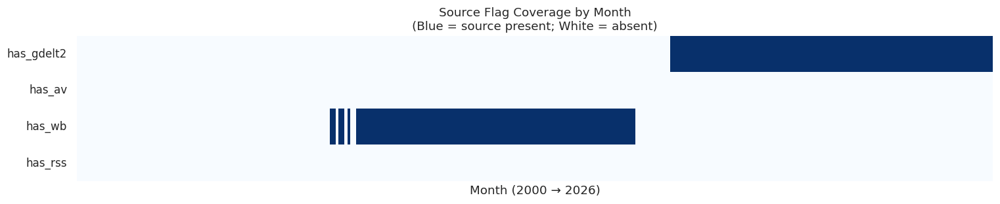

📊 Source flag active-month counts:
   has_gdelt2     : 111 months active (35.2%)
   has_av         : 0 months active (0.0%)
   has_wb         : 101 months active (32.1%)
   has_rss        : 0 months active (0.0%)

📊 GDELT1 Column Coverage (should be 2000-01 → 2015-01):
   gdelt1_tone_norm         : 181 months | 2000-01-01 → 2015-01-01 ✅
   gdelt1_tone_raw          : 22 months | 2013-04-01 → 2015-01-01 ✅
   gdelt1_articles          : 315 months | 2000-01-01 → 2026-03-01 ⚠️  (unexpected post-2015 values)
   gdelt1_goldstein         : 22 months | 2013-04-01 → 2015-01-01 ✅
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot12e_gdelt1_columns.png


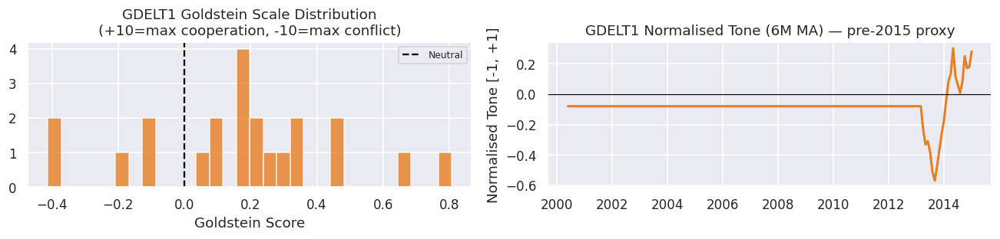

In [20]:
# ── 2e. Source Flag & GDELT1 Column Coverage Check ───────────────────────────
# Source flags
flag_cols = [c for c in ['has_gdelt2', 'has_av', 'has_wb', 'has_rss'] if c in df.columns]
if flag_cols:
    fig, ax = plt.subplots(figsize=(14, 3))
    flag_matrix = df.set_index('period_dt')[flag_cols].fillna(0)
    sns.heatmap(flag_matrix.T, ax=ax, cmap='Blues', cbar=False,
                xticklabels=False, yticklabels=flag_cols, linewidths=0)
    ax.set_title('Source Flag Coverage by Month\n(Blue = source present; White = absent)')
    ax.set_xlabel('Month (2000 → 2026)')
    plt.tight_layout()
    _save('Plot12d_source_flag_coverage.png')
    plt.show()
    print('📊 Source flag active-month counts:')
    for col in flag_cols:
        n = int(df[col].fillna(0).sum())
        print(f'   {col:<15}: {n} months active ({n/len(df)*100:.1f}%)')
else:
    print('ℹ️  No source flag columns (has_gdelt2/av/wb/rss) found in df.')

# GDELT1 columns
gdelt1_cols = [c for c in ['gdelt1_tone_norm', 'gdelt1_tone_raw', 'gdelt1_articles', 'gdelt1_goldstein'] if c in df.columns]
if gdelt1_cols:
    print('\n📊 GDELT1 Column Coverage (should be 2000-01 → 2015-01):')
    for col in gdelt1_cols:
        non_null = df[col].notna()
        first_dt = df.loc[non_null, 'period_dt'].min()
        last_dt  = df.loc[non_null, 'period_dt'].max()
        n_post2015 = df.loc[non_null & (df['period_dt'] >= '2015-02-01'), col].count()
        flag = '✅' if n_post2015 == 0 else '⚠️  (unexpected post-2015 values)'
        print(f'   {col:<25}: {non_null.sum()} months | {first_dt.date()} → {last_dt.date()} {flag}')

    if 'gdelt1_goldstein' in df.columns:
        fig, axes = plt.subplots(1, 2, figsize=(12, 3))
        g1_valid = df['gdelt1_goldstein'].dropna()
        axes[0].hist(g1_valid, bins=30, color='#e67e22', alpha=0.8, edgecolor='white')
        axes[0].axvline(0, color='black', lw=1.5, linestyle='--', label='Neutral')
        axes[0].set_title('GDELT1 Goldstein Scale Distribution\n(+10=max cooperation, -10=max conflict)')
        axes[0].set_xlabel('Goldstein Score')
        axes[0].legend(fontsize=8)

        if 'gdelt1_tone_norm' in df.columns:
            axes[1].plot(df['period_dt'], df['gdelt1_tone_norm'].rolling(6).mean(),
                         color='#e67e22', lw=2)
            axes[1].axhline(0, color='black', lw=0.8)
            axes[1].set_title('GDELT1 Normalised Tone (6M MA) — pre-2015 proxy')
            axes[1].set_ylabel('Normalised Tone [-1, +1]')
            axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
            axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        plt.tight_layout()
        _save('Plot12e_gdelt1_columns.png')
        plt.show()
else:
    print('⚠️  GDELT1 columns not found. They are generated in Phase01B [GDELT-1.0] section.')


---
## 3. GPR Index Deep Dive
**Research note**: The GPR index (Caldara & Iacoviello, AER 2022) is the foundational geopolitical signal. Key research questions: How does India GPR differ from global GPR? Can we identify known geopolitical events in the data? Is the India GPR mean-reverting or trending?

In [21]:
events['event_type'].value_counts()

,count
event_type,
RBI_POLICY,125
UNION_BUDGET,27
GLOBAL_SHOCK,20
ELECTION,19
REFORM,9
CRISIS,7


In [22]:
# Major geopolitical events for annotation
annot_events_1 = list(events[events['event_type'] == 'GLOBAL_SHOCK'][['period', 'description']].itertuples(index=False, name=None))
annot_events_2 = list(events[events['event_type'] == 'REFORM'][['period', 'description']].itertuples(index=False, name=None))
annot_events_3 = list(events[events['event_type'] == 'CRISIS'][['period', 'description']].itertuples(index=False, name=None))

print("GLOBAL_SHOCK:")
for i in annot_events_1:
  print(i)

print("\nREFORM:")
for i in annot_events_2:
  print(i)

print("\nCRISIS:")
for i in annot_events_3:
  print(i)

event_groups = [
    (annot_events_1, 'black', 'GLOBAL_SHOCK'),
    (annot_events_2, 'green', 'REFORM'),
    (annot_events_3, 'blue',  'CRISIS')
]

GLOBAL_SHOCK:
('2000-03', 'Dot-com bubble peak and burst')
('2001-09', 'September 11 attacks — global financial shock')
('2003-03', 'Iraq War commencement — geopolitical risk spike')
('2004-05', 'US Fed rate hike cycle start (Greenspan era)')
('2007-08', 'US subprime mortgage crisis onset')
('2008-09', 'Lehman Brothers collapse — Global Financial Crisis')
('2010-05', 'European sovereign debt crisis peak (Greece bailout)')
('2013-05', 'Fed taper tantrum — Bernanke taper announcement')
('2015-08', 'China yuan devaluation + Shanghai market crash')
('2016-06', 'Brexit referendum result')
('2018-10', 'US-China trade war escalation (tariff round)')
('2020-03', 'COVID-19 declared global pandemic by WHO')
('2020-04', 'WTI crude oil futures turn negative (demand collapse)')
('2021-11', 'Omicron variant announced by WHO')
('2022-02', 'Russia invasion of Ukraine')
('2022-03', 'US Fed aggressive rate hike cycle start')
('2023-03', 'Silicon Valley Bank collapse — US banking stress')
('2023-10', 'Is

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot13a_gpr_timeseries.png


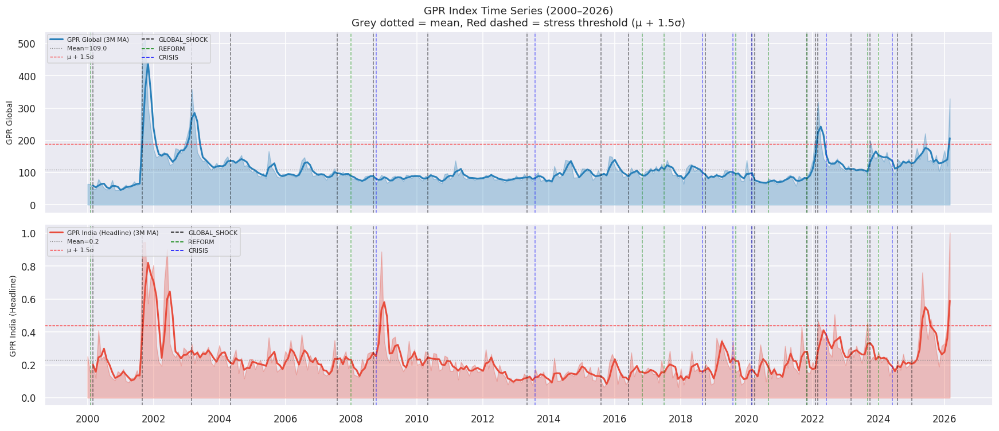

In [23]:

# ── 3a. GPR Index time series — Global vs India ───────────────────────────────
gpr_plot_cols = [c for c in ['gpr_global', 'gpr_india', 'gpr_india_threats', 'gpr_india_acts'] if c in df.columns]

if gpr_plot_cols:
    fig, axes = plt.subplots(len(gpr_plot_cols), 1,figsize=(16, 3.5 * len(gpr_plot_cols)),
                             sharex=True)

    if len(gpr_plot_cols) == 1:
        axes = [axes]

    colors = ['#2980b9', '#e74c3c', '#e67e22', '#8e44ad']
    labels = ['GPR Global', 'GPR India (Headline)',
              'GPR India Threats', 'GPR India Acts']

    # Event legend handles
    event_handles = [
        Line2D([0], [0], color=c, linestyle='--', lw=1, label=l)
        for _, c, l in event_groups
    ]

    for ax, col, color, label in zip(axes, gpr_plot_cols, colors, labels):

        ax.fill_between(df['period_dt'], df[col].fillna(0),
                        alpha=0.3, color=color)

        ax.plot(df['period_dt'],
                df[col].rolling(3).mean(),
                color=color, lw=2,
                label=f'{label} (3M MA)')

        ax.axhline(df[col].mean(),
                   color='grey', lw=0.8, linestyle=':',
                   label=f'Mean={df[col].mean():.1f}')

        ax.axhline(df[col].mean() + 1.5 * df[col].std(),
                   color='red', lw=0.8, linestyle='--',
                   label='μ + 1.5σ')

        # Event annotations
        for annot_event, annot_color, _ in event_groups:
            for evt_dt, _ in annot_event:
                ax.axvline(pd.Timestamp(evt_dt),
                           color=annot_color,
                           linestyle='--',
                           lw=1, alpha=0.5)

        ax.set_ylabel(label, fontsize=9)

        # Combine plot + event legends
        handles, labels_ = ax.get_legend_handles_labels()
        ax.legend(handles + event_handles,
                  labels_ + [l for _, _, l in event_groups],
                  fontsize=7, loc='upper left', ncol=2)

    axes[0].set_title(
        'GPR Index Time Series (2000–2026)\n'
        'Grey dotted = mean, Red dashed = stress threshold (μ + 1.5σ)',
        fontsize=12
    )

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()

    _fig_name = 'Plot13a_gpr_timeseries.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)

    plt.savefig(_fig_path, dpi=150,
                bbox_inches='tight',
                facecolor='white')

    print(f'📁 Saved → {_fig_path}')
    plt.show()

else:
    print('⚠️  GPR raw columns not found.')

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot13b_india_vs_global_divergence.png


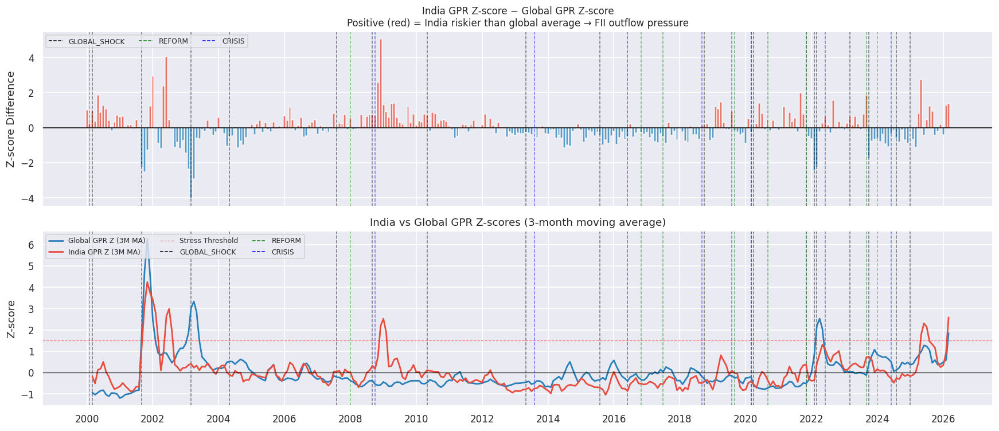


📊 India-vs-Global divergence stats:
   India riskier than global: 142 months (45.1%)
   India less risky: 173 months (54.9%)
   Mean divergence: -0.000 | Std: 0.875


In [24]:
# ── 3b. India vs Global GPR divergence ───────────────────────────────────────
if 'gpr_india_vs_global' in df.columns:
    fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
    diverg = df['gpr_india_vs_global'].fillna(0)

    # Event legend handles
    event_handles = [
        Line2D([0], [0], color=c, linestyle='--', lw=1, label=l)
        for _, c, l in event_groups
    ]

    # ── Divergence bar plot ───────────────────────────────────────────
    axes[0].bar(
        df['period_dt'], diverg,
        color=['#e74c3c' if v > 0 else '#2980b9' for v in diverg],
        width=25, alpha=0.75
    )

    axes[0].axhline(0, color='black', lw=1)

    axes[0].set_title(
        'India GPR Z-score − Global GPR Z-score\n'
        'Positive (red) = India riskier than global average → FII outflow pressure',
        fontsize=11
    )

    axes[0].set_ylabel('Z-score Difference')

    # Add event lines
    for annot_event, annot_color, _ in event_groups:
        for evt_dt, _ in annot_event:
            for ax in axes:
                ax.axvline(pd.Timestamp(evt_dt),
                           color=annot_color,
                           linestyle='--',
                           lw=1,
                           alpha=0.5)

    # Legend for top plot
    axes[0].legend(handles=event_handles,
                   fontsize=8,
                   loc='upper left',
                   ncol=3)

    # ── Z-score overlay ───────────────────────────────────────────────
    if 'gpr_india_z' in df.columns and 'gpr_global_z' in df.columns:

        axes[1].plot(
            df['period_dt'],
            df['gpr_global_z'].rolling(3).mean(),
            label='Global GPR Z (3M MA)',
            color='#2980b9', lw=1.8
        )

        axes[1].plot(
            df['period_dt'],
            df['gpr_india_z'].rolling(3).mean(),
            label='India GPR Z (3M MA)',
            color='#e74c3c', lw=1.8
        )

        axes[1].axhline(0, color='black', lw=0.8)

        axes[1].axhline(
            1.5,
            color='red',
            lw=0.8,
            linestyle='--',
            alpha=0.5,
            label='Stress Threshold'
        )

        axes[1].set_ylabel('Z-score')

        # Combine line + event legends
        handles, labels = axes[1].get_legend_handles_labels()

        axes[1].legend(
            handles + event_handles,
            labels + [l for _, _, l in event_groups],
            fontsize=8,
            loc='upper left',
            ncol=3
        )

        axes[1].set_title(
            'India vs Global GPR Z-scores (3-month moving average)'
        )

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()

    _fig_name = 'Plot13b_india_vs_global_divergence.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)

    plt.savefig(_fig_path,
                dpi=150,
                bbox_inches='tight',
                facecolor='white')

    print(f'📁 Saved → {_fig_path}')

    plt.show()

    # ── Stats ─────────────────────────────────────────────────────────
    pos_months = (diverg > 0).sum()
    neg_months = (diverg <= 0).sum()

    print(f'\n📊 India-vs-Global divergence stats:')
    print(f'   India riskier than global: {pos_months} months ({pos_months/len(df)*100:.1f}%)')
    print(f'   India less risky: {neg_months} months ({neg_months/len(df)*100:.1f}%)')
    print(f'   Mean divergence: {diverg.mean():.3f} | Std: {diverg.std():.3f}')


📊 GPR Distribution & Stationarity Analysis
-------------------------------------------------------

  gpr_global:
    Skewness  : 3.882 (right-skewed)
    Kurtosis  : 22.340 (heavy-tailed)
    ADF stat  : -5.5480  p=0.0000 → stationary ✅

  gpr_india:
    Skewness  : 2.877 (right-skewed)
    Kurtosis  : 10.948 (heavy-tailed)
    ADF stat  : -4.5321  p=0.0002 → stationary ✅
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot13c_gpr_distributions.png


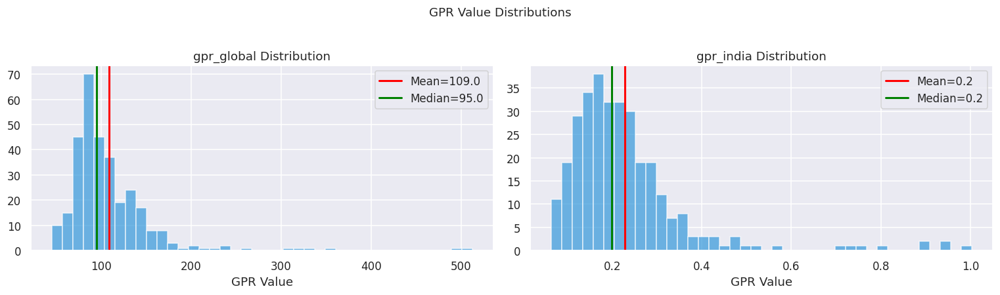

In [25]:
# ── 3c. GPR distribution & stationarity tests ─────────────────────────────────
gpr_raw_cols = ['gpr_global', 'gpr_india'] if all(c in df.columns for c in ['gpr_global', 'gpr_india']) else []

if gpr_raw_cols:
    fig, axes = plt.subplots(1, len(gpr_raw_cols), figsize=(14, 4))
    if len(gpr_raw_cols) == 1:
        axes = [axes]

    print('\n📊 GPR Distribution & Stationarity Analysis')
    print('-' * 55)

    for ax, col in zip(axes, gpr_raw_cols):
        series = df[col].dropna()
        ax.hist(series, bins=40, color='#3498db', alpha=0.7, edgecolor='white')
        ax.axvline(series.mean(), color='red', lw=2, label=f'Mean={series.mean():.1f}')
        ax.axvline(series.median(), color='green', lw=2, label=f'Median={series.median():.1f}')
        ax.set_title(f'{col} Distribution')
        ax.set_xlabel('GPR Value')
        ax.legend()

        # Statistical summary
        sk = stats.skew(series)
        ku = stats.kurtosis(series)
        adf = adfuller(series.ffill())
        print(f'\n  {col}:')
        print(f'    Skewness  : {sk:.3f} ({"right-skewed" if sk > 0.5 else "left-skewed" if sk < -0.5 else "approx symmetric"})')
        print(f'    Kurtosis  : {ku:.3f} ({"heavy-tailed" if ku > 1 else "light-tailed" if ku < -1 else "normal-like"})')
        print(f'    ADF stat  : {adf[0]:.4f}  p={adf[1]:.4f} → {"stationary ✅" if adf[1] < 0.05 else "non-stationary ⚠️"}')

    plt.suptitle('GPR Value Distributions', y=1.02, fontsize=12)
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot13c_gpr_distributions.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

🔴 India GPR High-Stress Months (z-score > 1.5σ): 16
   = top 5.1% of all months



,period,gpr_india_z,gpr_global_z
314,2026-03,5.549648,4.184541
21,2001-10,5.139649,7.653160
20,2001-09,5.110604,7.389862
29,2002-06,4.815387,0.764346
107,2008-12,4.720027,-0.316093
24,2002-01,4.142742,1.203371
304,2025-05,3.812434,1.081414
23,2001-12,3.643145,2.410102
28,2002-05,3.414784,1.029730
22,2001-11,2.465663,3.750809


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot13d_gpr_high_stress_month.png


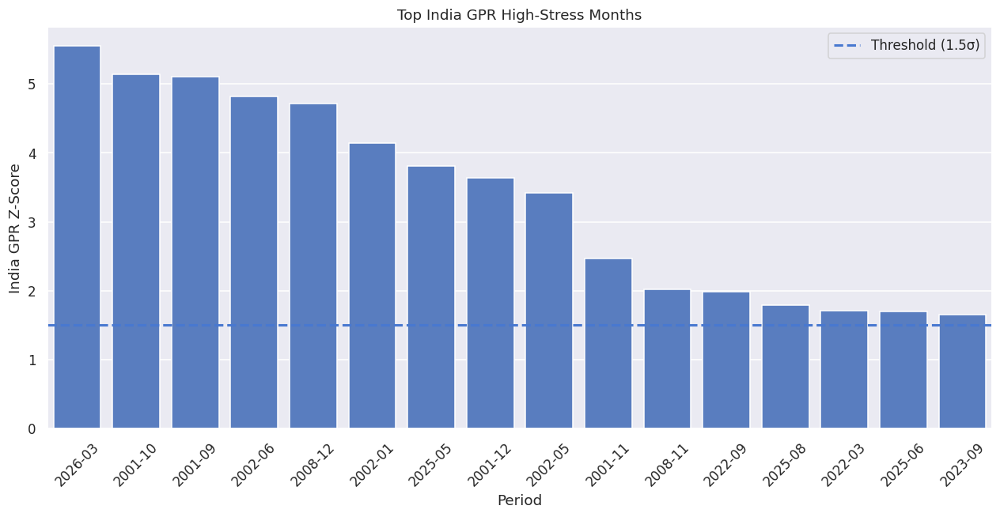

In [26]:
# ── 3d. GPR high-stress months visualization ────────────────────────────────
if 'gpr_india_z' in df.columns:

    stress_threshold = 1.5

    stress_months = (
        df[df['gpr_india_z'] > stress_threshold][
            ['period', 'gpr_india_z', 'gpr_global_z']
        ].copy()
        if 'gpr_global_z' in df.columns
        else df[df['gpr_india_z'] > stress_threshold][
            ['period', 'gpr_india_z']
        ].copy()
    )

    stress_months = stress_months.sort_values('gpr_india_z', ascending=False)

    print(f'🔴 India GPR High-Stress Months (z-score > {stress_threshold}σ): {len(stress_months)}')
    print(f'   = top {len(stress_months)/len(df)*100:.1f}% of all months\n')

    display(stress_months.head(20))

    # ── Plot ────────────────────────────────────────────────────────────────────
    plt.figure(figsize=(14, 6))

    sns.barplot(
        data=stress_months.head(20),
        x='period',
        y='gpr_india_z'
    )

    plt.axhline(y=stress_threshold, linestyle='--', linewidth=2,
                label=f'Threshold ({stress_threshold}σ)')
    plt.xticks(rotation=45)
    plt.title('Top India GPR High-Stress Months')
    plt.xlabel('Period')
    plt.ylabel('India GPR Z-Score')
    plt.legend()

    _fig_name = 'Plot13d_gpr_high_stress_month.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot13e_gpr_threats_vs_acts.png


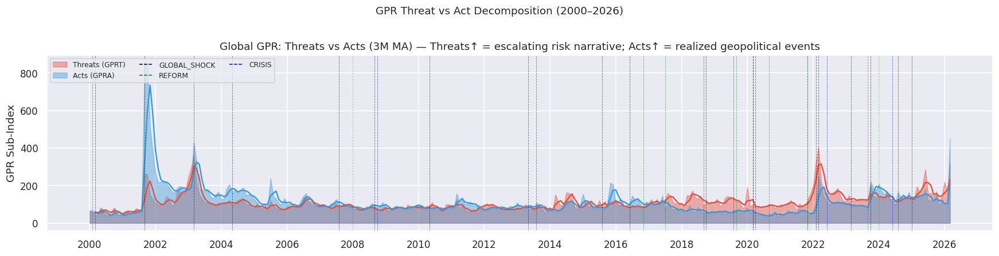

  Global GPR — median Threat/Act ratio: 1.03 (>1 = threat-heavy environment)


In [27]:

# ── 3e. GPR Threats vs Acts decomposition ────────────────────────────────────
threat_act_pairs = [
    ('gpr_global_threats', 'gpr_global_acts', 'Global GPR: Threats vs Acts'),
    ('gpr_india_threats',  'gpr_india_acts',  'India GPR: Threats vs Acts'),
]

available_pairs = [
    (t, a, lbl) for t, a, lbl in threat_act_pairs
    if t in df.columns and a in df.columns
]

if available_pairs:

    fig, axes = plt.subplots(
        len(available_pairs), 1,
        figsize=(16, 4 * len(available_pairs)),
        sharex=True
    )

    if len(available_pairs) == 1:
        axes = [axes]

    # Event legend handles
    event_handles = [
        Line2D([0], [0], color=c, linestyle='--', lw=1, label=l)
        for _, c, l in event_groups
    ]

    for ax, (tcol, acol, title) in zip(axes, available_pairs):

        # Filled areas
        ax.fill_between(df['period_dt'], df[tcol].fillna(0),
                        alpha=0.4, color='#e74c3c',
                        label='Threats (GPRT)')

        ax.fill_between(df['period_dt'], df[acol].fillna(0),
                        alpha=0.4, color='#3498db',
                        label='Acts (GPRA)')

        # Rolling averages
        ax.plot(df['period_dt'],
                df[tcol].rolling(3).mean(),
                color='#e74c3c', lw=1.5)

        ax.plot(df['period_dt'],
                df[acol].rolling(3).mean(),
                color='#3498db', lw=1.5)

        # Event annotations
        for annot_event, annot_color, _ in event_groups:
            for evt_dt, _ in annot_event:
                ax.axvline(pd.Timestamp(evt_dt),
                           color=annot_color,
                           linestyle='--',
                           lw=0.6,
                           alpha=0.5)

        ax.set_title(
            title +
            ' (3M MA) — Threats↑ = escalating risk narrative; '
            'Acts↑ = realized geopolitical events'
        )

        ax.set_ylabel('GPR Sub-Index')

        # Combined legend
        handles, labels = ax.get_legend_handles_labels()

        ax.legend(handles + event_handles,
                  labels + [l for _, _, l in event_groups],
                  fontsize=8,
                  loc='upper left',
                  ncol=3)

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.suptitle(
        'GPR Threat vs Act Decomposition (2000–2026)',
        fontsize=12, y=1.01
    )

    plt.tight_layout()

    _save('Plot13e_gpr_threats_vs_acts.png')

    plt.show()

    # ── Threat/Act ratio stats ───────────────────────────────────────
    for tcol, acol, title in available_pairs:

        ratio = (
            df[tcol] /
            df[acol].replace(0, np.nan)
        ).dropna()

        label = title.split(':')[0].strip()

        print(
            f'  {label} — median Threat/Act ratio: '
            f'{ratio.median():.2f} '
            f'(>1 = threat-heavy environment)'
        )

else:
    print('⚠️ Threat/Act sub-columns not available.')

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot13f_gpr_current_vs_hist.png


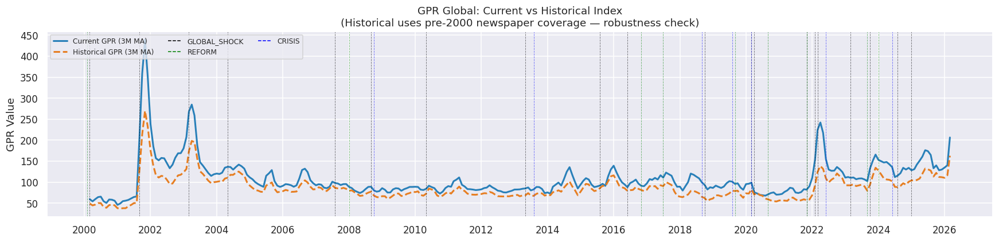


📊 Current vs Historical GPR Spearman r = 0.935 (p=0.0000)
   ✅ Strong alignment


In [28]:

# ── 3f. GPR Historical Index vs Current Index ───────────────────────────────
hist_pairs = [
    ('gpr_global', 'gpr_global_hist',
     'Global GPR: Current vs Historical'),
]

hist_pairs = [
    (c, h, lbl) for c, h, lbl in hist_pairs
    if c in df.columns and h in df.columns
]

if hist_pairs:

    fig, ax = plt.subplots(figsize=(16, 4))

    c, h, lbl = hist_pairs[0]

    # Main series
    ax.plot(df['period_dt'],
            df[c].rolling(3).mean(),
            color='#2980b9', lw=2,
            label='Current GPR (3M MA)')

    ax.plot(df['period_dt'],
            df[h].rolling(3).mean(),
            color='#e67e22', lw=2,
            linestyle='--',
            label='Historical GPR (3M MA)')

    # Event annotations
    for annot_event, annot_color, _ in event_groups:
        for evt_dt, _ in annot_event:
            ax.axvline(pd.Timestamp(evt_dt),
                       color=annot_color,
                       linestyle='--',
                       lw=0.6,
                       alpha=0.5)

    # Event legend handles
    event_handles = [
        Line2D([0], [0],
               color=c,
               linestyle='--',
               lw=1,
               label=l)
        for _, c, l in event_groups
    ]

    # Combined legend
    handles, labels = ax.get_legend_handles_labels()

    ax.legend(handles + event_handles,
              labels + [l for _, _, l in event_groups],
              fontsize=8,
              loc='upper left',
              ncol=3)

    ax.set_title(
        'GPR Global: Current vs Historical Index\n'
        '(Historical uses pre-2000 newspaper coverage — robustness check)'
    )

    ax.set_ylabel('GPR Value')

    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()

    _save('Plot13f_gpr_current_vs_hist.png')

    plt.show()

    # ── Correlation check ────────────────────────────────────────────
    valid = df[[c, h]].dropna()

    if len(valid) > 10:

        r, p = spearmanr(valid[c], valid[h])

        print(f'\n📊 Current vs Historical GPR Spearman r = {r:.3f} (p={p:.4f})')

        print(
            '   ✅ Strong alignment'
            if r > 0.7
            else '   ⚠️ Divergence — review newspaper coverage methodology'
        )

else:
    print('⚠️ Historical GPR columns not found in combined table.')

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot13g_gpr_coverage_share.png


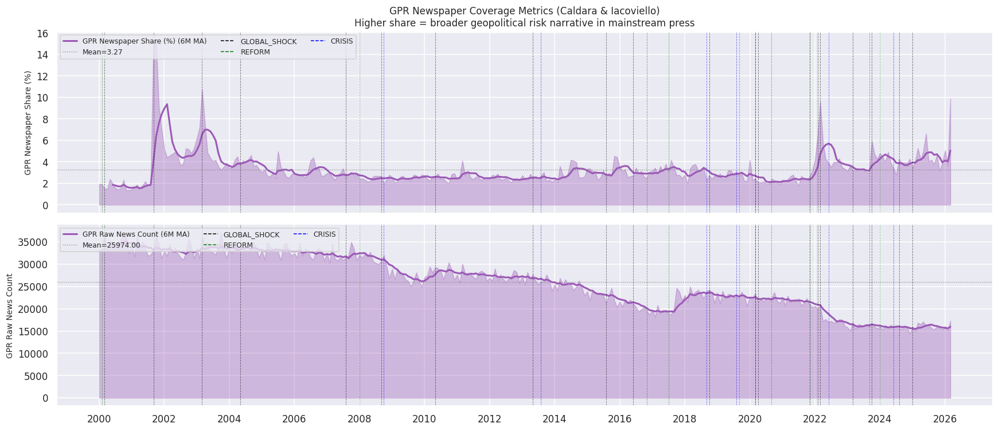


📊 GPR Share stats:
   Mean: 3.270  |  Max: 15.373  |  Periods >2×mean: 10


In [29]:

# ── 3g. GPR Newspaper Coverage Share & Article Count ───────────────────────
share_col = 'gpr_share' if 'gpr_share' in df.columns else None
count_col = 'gpr_news_count' if 'gpr_news_count' in df.columns else None

if share_col or count_col:

    avail = [
        (c, lbl) for c, lbl in [
            (share_col, 'GPR Newspaper Share (%)'),
            (count_col, 'GPR Raw News Count'),
        ]
        if c is not None and c in df.columns
    ]

    fig, axes = plt.subplots(
        len(avail), 1,
        figsize=(16, 3.5 * len(avail)),
        sharex=True
    )

    if len(avail) == 1:
        axes = [axes]

    # Event legend handles
    event_handles = [
        Line2D([0], [0],
               color=c,
               linestyle='--',
               lw=1,
               label=l)
        for _, c, l in event_groups
    ]

    for ax, (col, label) in zip(axes, avail):

        # Main plots
        ax.fill_between(df['period_dt'],
                        df[col].fillna(0),
                        alpha=0.35,
                        color='#9b59b6')

        ax.plot(df['period_dt'],
                df[col].rolling(6).mean(),
                color='#9b59b6',
                lw=2,
                label=f'{label} (6M MA)')

        ax.axhline(df[col].mean(),
                   color='grey',
                   lw=0.8,
                   linestyle=':',
                   label=f'Mean={df[col].mean():.2f}')

        # Event annotations
        for annot_event, annot_color, _ in event_groups:
            for evt_dt, _ in annot_event:
                ax.axvline(pd.Timestamp(evt_dt),
                           color=annot_color,
                           linestyle='--',
                           lw=0.6,
                           alpha=0.5)

        ax.set_ylabel(label, fontsize=9)

        # Combined legend
        handles, labels = ax.get_legend_handles_labels()

        ax.legend(handles + event_handles,
                  labels + [l for _, _, l in event_groups],
                  fontsize=8,
                  loc='upper left',
                  ncol=3)

    axes[0].set_title(
        'GPR Newspaper Coverage Metrics (Caldara & Iacoviello)\n'
        'Higher share = broader geopolitical risk narrative in mainstream press',
        fontsize=11
    )

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()

    _save('Plot13g_gpr_coverage_share.png')

    plt.show()

    # ── Stats ────────────────────────────────────────────────────────
    if share_col and share_col in df.columns:

        print(f'\n📊 GPR Share stats:')

        print(
            f'   Mean: {df[share_col].mean():.3f}  |  '
            f'Max: {df[share_col].max():.3f}  |  '
            f'Periods >2×mean: '
            f'{(df[share_col] > 2 * df[share_col].mean()).sum()}'
        )

else:
    print('⚠️ gpr_share / gpr_news_count columns not found.')

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot13h_gpr_variants.png


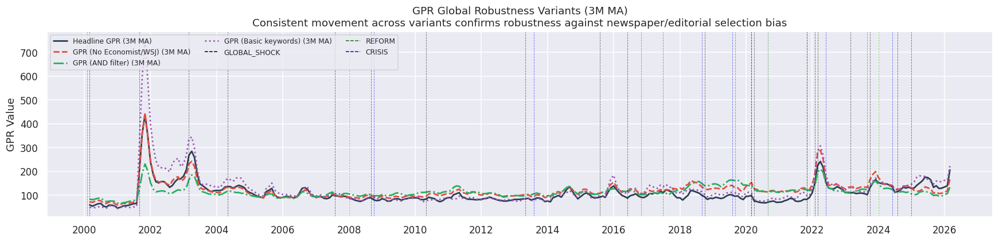


📊 GPR Variant Spearman Correlation Matrix:
                        Headline GPR  GPR (No Economist/WSJ)  GPR (AND filter)  GPR (Basic keywords)
Headline GPR                   1.000                   0.777             0.517                 0.932
GPR (No Economist/WSJ)         0.777                   1.000             0.837                 0.805
GPR (AND filter)               0.517                   0.837             1.000                 0.493
GPR (Basic keywords)           0.932                   0.805             0.493                 1.000

   ✅ High correlations (>0.90) confirm headline GPR robustness across source definitions.


In [30]:

# ── 3h. GPR Robustness Variants ─────────────────────────────────────────────
variant_cols = [
    (c, lbl) for c, lbl in [
        ('gpr_global',       'Headline GPR'),
        ('gpr_global_noew',  'GPR (No Economist/WSJ)'),
        ('gpr_global_and',   'GPR (AND filter)'),
        ('gpr_global_basic', 'GPR (Basic keywords)'),
    ]
    if c in df.columns
]

if len(variant_cols) >= 2:

    fig, ax = plt.subplots(figsize=(16, 4))

    colors_v = ['#2c3e50', '#e74c3c', '#27ae60', '#9b59b6']
    styles_v = ['-', '--', '-.', ':']

    # Main series
    for (col, lbl), color, ls in zip(variant_cols, colors_v, styles_v):

        ax.plot(df['period_dt'],
                df[col].rolling(3).mean(),
                color=color,
                lw=1.8,
                linestyle=ls,
                label=f'{lbl} (3M MA)')

    # Event annotations
    for annot_event, annot_color, _ in event_groups:
        for evt_dt, _ in annot_event:
            ax.axvline(pd.Timestamp(evt_dt),
                       color=annot_color,
                       linestyle='--',
                       lw=0.6,
                       alpha=0.5)

    # Event legend handles
    event_handles = [
        Line2D([0], [0],
               color=c,
               linestyle='--',
               lw=1,
               label=l)
        for _, c, l in event_groups
    ]

    # Combined legend
    handles, labels = ax.get_legend_handles_labels()

    ax.legend(handles + event_handles,
              labels + [l for _, _, l in event_groups],
              fontsize=8,
              loc='upper left',
              ncol=3)

    ax.set_title(
        'GPR Global Robustness Variants (3M MA)\n'
        'Consistent movement across variants confirms robustness '
        'against newspaper/editorial selection bias'
    )

    ax.set_ylabel('GPR Value')

    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()

    _save('Plot13h_gpr_variants.png')

    plt.show()

    # ── Correlation matrix ───────────────────────────────────────────
    variant_data = (
        df[[c for c, _ in variant_cols]]
        .rename(columns={c: lbl for c, lbl in variant_cols})
    )

    corr_v = variant_data.corr(method='spearman')

    print('\n📊 GPR Variant Spearman Correlation Matrix:')

    print(corr_v.round(3).to_string())

    print(
        '\n   ✅ High correlations (>0.90) confirm '
        'headline GPR robustness across source definitions.'
    )

else:
    print('⚠️ GPR variant columns not found.')

### 3i. GPR Historical Threats & Acts Sub-Components
**Research note**: `gpr_global_hist_threats` and `gpr_global_hist_acts` apply the historical newspaper methodology to the threats/acts split — used to verify that the threats/acts decomposition is stable across methodological variants.



📊 Historical vs Current Sub-Component Alignment (Spearman):
   ✅ Threats: Current vs Hist: r=0.909 (p=0.0000)
   ✅ Acts: Current vs Hist: r=0.974 (p=0.0000)
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot13i_gpr_hist_threats_acts.png


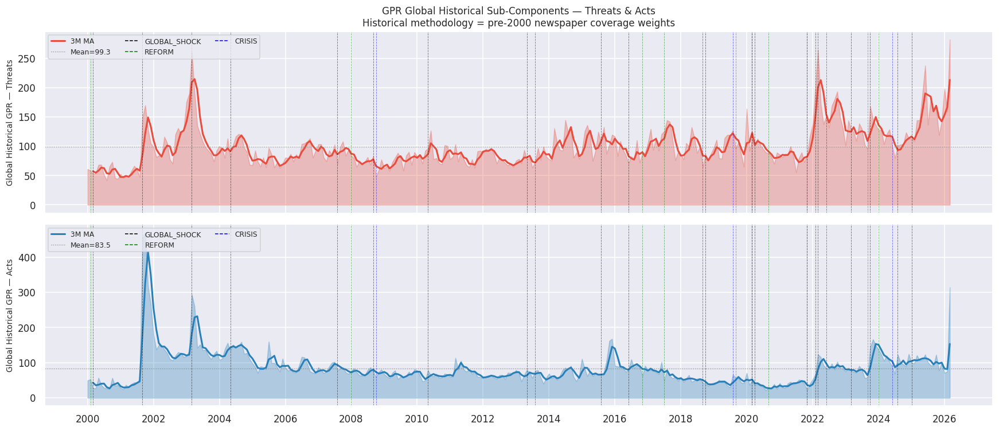

In [31]:

# ── 3i. GPR Global Historical Threats & Acts ────────────────────────────────
hist_sub_cols = [
    (c, lbl, color) for c, lbl, color in [
        ('gpr_global_hist_threats',
         'Global Historical GPR — Threats',
         '#e74c3c'),

        ('gpr_global_hist_acts',
         'Global Historical GPR — Acts',
         '#2980b9'),
    ]
    if c in df.columns
]

if len(hist_sub_cols) >= 1:

    fig, axes = plt.subplots(
        len(hist_sub_cols), 1,
        figsize=(16, 3.5 * len(hist_sub_cols)),
        sharex=True
    )

    if len(hist_sub_cols) == 1:
        axes = [axes]

    # Event legend handles
    event_handles = [
        Line2D([0], [0],
               color=c,
               linestyle='--',
               lw=1,
               label=l)
        for _, c, l in event_groups
    ]

    for ax, (col, lbl, color) in zip(axes, hist_sub_cols):

        # Main series
        ax.fill_between(df['period_dt'],
                        df[col].fillna(0),
                        alpha=0.3,
                        color=color)

        ax.plot(df['period_dt'],
                df[col].rolling(3).mean(),
                color=color,
                lw=2,
                label='3M MA')

        ax.axhline(df[col].mean(),
                   color='grey',
                   lw=0.8,
                   linestyle=':',
                   label=f'Mean={df[col].mean():.1f}')

        # Event annotations
        for annot_event, annot_color, _ in event_groups:
            for evt_dt, _ in annot_event:
                ax.axvline(pd.Timestamp(evt_dt),
                           color=annot_color,
                           linestyle='--',
                           lw=0.6,
                           alpha=0.5)

        ax.set_ylabel(lbl, fontsize=9)

        # Combined legend
        handles, labels = ax.get_legend_handles_labels()

        ax.legend(handles + event_handles,
                  labels + [l for _, _, l in event_groups],
                  fontsize=8,
                  loc='upper left',
                  ncol=3)

    # ── Correlation vs current methodology ──────────────────────────
    pairs = [
        ('gpr_global_threats',
         'gpr_global_hist_threats',
         'Threats: Current vs Hist'),

        ('gpr_global_acts',
         'gpr_global_hist_acts',
         'Acts: Current vs Hist'),
    ]

    print('\n📊 Historical vs Current Sub-Component Alignment (Spearman):')

    for cur, hist, label in pairs:

        if cur in df.columns and hist in df.columns:

            valid = df[[cur, hist]].dropna()

            if len(valid) > 10:

                r, p = spearmanr(valid[cur], valid[hist])

                flag = '✅' if r > 0.7 else '⚠️'

                print(f'   {flag} {label}: r={r:.3f} (p={p:.4f})')

    axes[0].set_title(
        'GPR Global Historical Sub-Components — Threats & Acts\n'
        'Historical methodology = pre-2000 newspaper coverage weights',
        fontsize=11
    )

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()

    _save('Plot13i_gpr_hist_threats_acts.png')

    plt.show()

else:
    print('⚠️ gpr_global_hist_threats / gpr_global_hist_acts not found.')
    print('   Check GPRHT/GPRHA columns in source XLS.')

---
## 4. News Corpus Analysis
**Research note**: Understanding the composition of the news corpus is essential for interpreting downstream sentiment scores. Source diversity and temporal coverage gaps directly affect model reliability.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot14a_top_sources.png


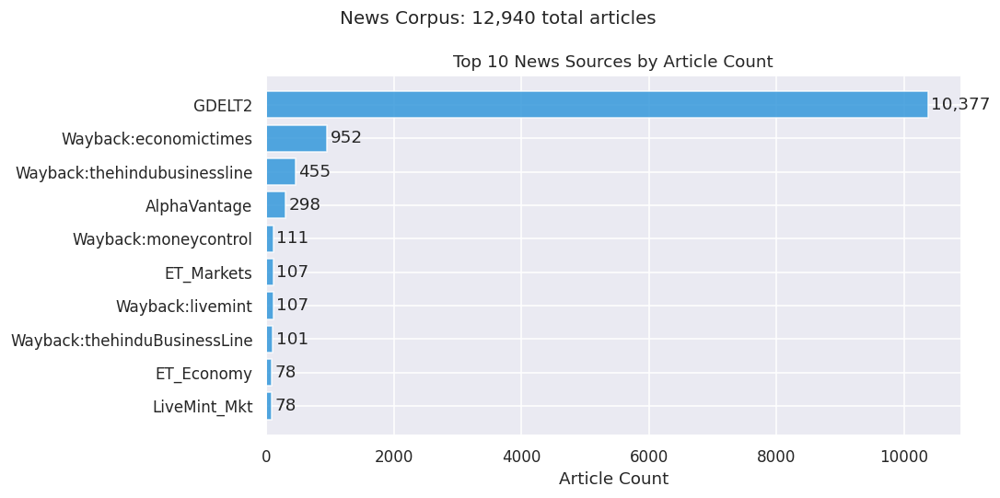


📊 Top Sources:
source
GDELT2                          10377
Wayback:economictimes             952
Wayback:thehindubusinessline      455
AlphaVantage                      298
Wayback:moneycontrol              111
ET_Markets                        107
Wayback:livemint                  107
Wayback:thehinduBusinessLine      101
ET_Economy                         78
LiveMint_Mkt                       78


In [32]:
# ── 4a. Top 10 Source Distribution ────────────────────────────────────────────
if not corpus.empty and 'source' in corpus.columns:

    fig, ax = plt.subplots(figsize=(10, 5))

    # Top 10 individual sources
    top_sources = corpus['source'].value_counts().head(10)

    bars = ax.barh(
        top_sources.index[::-1],
        top_sources.values[::-1],
        color='#3498db',
        alpha=0.85
    )

    ax.set_title('Top 10 News Sources by Article Count')
    ax.set_xlabel('Article Count')

    # ✅ Add value labels
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 50,
            bar.get_y() + bar.get_height()/2,
            f'{int(width):,}',
            va='center'
        )

    plt.suptitle(f'News Corpus: {len(corpus):,} total articles', fontsize=13)
    plt.tight_layout()

    # Save plot
    _fig_name = 'Plot14a_top_sources.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')

    print(f'📁 Saved → {_fig_path}')
    plt.show()

    print('\n📊 Top Sources:')
    print(top_sources.to_string())

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot14a2_source_group_pie.png


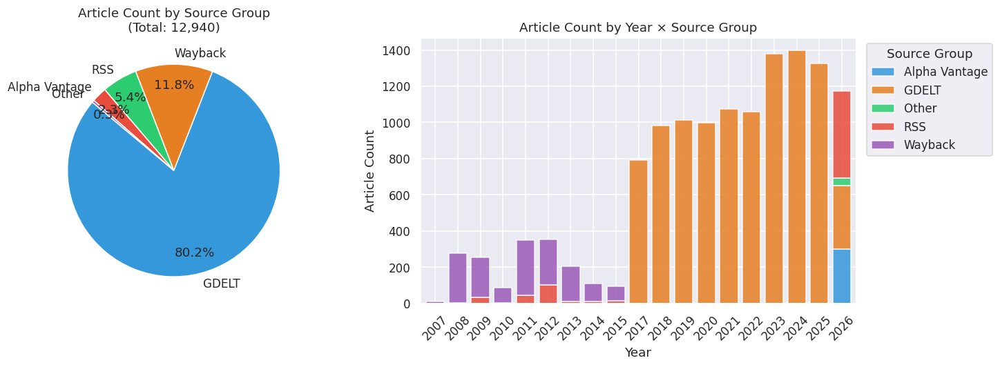


📊 Source Group Summary:
source_group
GDELT            10377
Wayback           1522
RSS                699
Alpha Vantage      298
Other               44


In [33]:
# ── 4a-2. Source-group breakdown pie (Phase01B has RSS/GDELT/AV/YF/Wayback groups) ──
if not corpus.empty and 'source' in corpus.columns:
    # Derive source_group from source name if not already present
    if 'source_group' not in corpus.columns:
        def _classify(src):
            s = str(src).lower()
            if any(x in s for x in ['gdelt', 'gdelt2', 'gdelt1']): return 'GDELT'
            if any(x in s for x in ['rss', 'reuters', 'bloomberg', 'et_', 'moneycontrol',
                                      'livemint', 'cnbc', 'bbc', 'aljazeera', 'wsj']): return 'RSS'
            if 'yfinance' in s or 'yf_' in s: return 'yFinance'
            if 'alphavantage' in s or 'av_' in s: return 'Alpha Vantage'
            if 'wayback' in s: return 'Wayback'
            return 'Other'
        corpus['source_group'] = corpus['source'].apply(_classify)

    grp_counts = corpus['source_group'].value_counts()
    grp_colors = ['#3498db','#e67e22','#2ecc71','#e74c3c','#9b59b6','#1abc9c'][:len(grp_counts)]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Pie
    axes[0].pie(grp_counts.values, labels=grp_counts.index, autopct='%1.1f%%',
                colors=grp_colors, startangle=140, pctdistance=0.8)
    axes[0].set_title(f'Article Count by Source Group\n(Total: {len(corpus):,})', fontsize=12)

    # Bar with year annotation
    if 'year' in corpus.columns:
        yr_grp = corpus.groupby(['year', 'source_group']).size().unstack(fill_value=0)
        yr_grp.plot(kind='bar', stacked=True, ax=axes[1],
                    color=grp_colors[:len(yr_grp.columns)], alpha=0.85, width=0.8)
        axes[1].set_title('Article Count by Year × Source Group')
        axes[1].set_xlabel('Year')
        axes[1].set_ylabel('Article Count')
        axes[1].tick_params(axis='x', rotation=45)
        axes[1].legend(title='Source Group', bbox_to_anchor=(1.01,1))

    plt.tight_layout()
    _save('Plot14a2_source_group_pie.png')
    plt.show()

    print('\n📊 Source Group Summary:')
    print(grp_counts.to_string())


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot14b_source_coverage_by_year.png


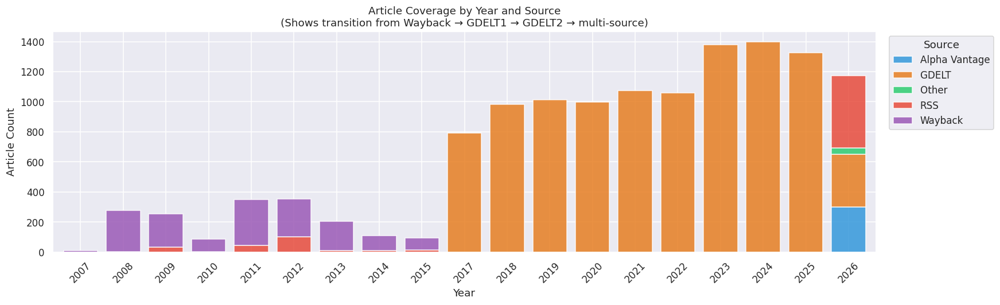

In [34]:
# ── 4b. Source coverage by year ───────────────────────────────────────────────
if not corpus.empty:
    corpus['published'] = pd.to_datetime(corpus['published'], errors='coerce')
    corpus = corpus.dropna(subset=['published'])
    corpus['year'] = corpus['published'].dt.year

    yr_src = corpus.groupby(['year', 'source_group']).size().unstack(fill_value=0)

    fig, ax = plt.subplots(figsize=(16, 5))
    yr_src.plot(kind='bar', stacked=True, ax=ax,
                color=wedge_colors[:len(yr_src.columns)], alpha=0.85, width=0.8)
    ax.set_title('Article Coverage by Year and Source\n(Shows transition from Wayback → GDELT1 → GDELT2 → multi-source)', fontsize=12)
    ax.set_xlabel('Year')
    ax.set_ylabel('Article Count')
    ax.legend(title='Source', bbox_to_anchor=(1.01, 1), loc='upper left')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot14b_source_coverage_by_year.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot14c_wordcloud_titles.png


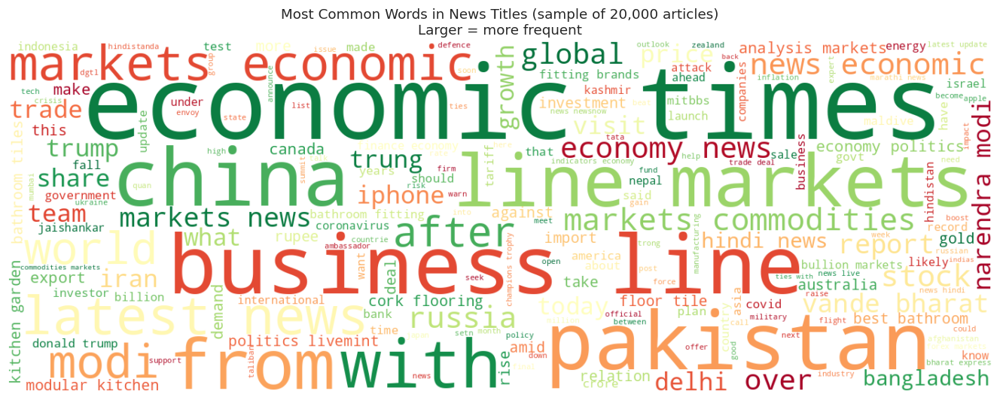

In [35]:
# ── 4c. Word cloud from article titles ───────────────────────────────────────
if not corpus.empty and 'title' in corpus.columns:
    STOPWORDS_EXTRA = {'india', 'indian', 'nifty', 'market', 'says', 'new', 'will',
                       'one', 'may', 'year', 'get', 'also', 'two', 'first',
                       'reuters', 'bloomberg', 'et', 'bse', 'nse', 'sensex'}

    # Sample 20000 titles for performance
    sample_titles = corpus['title'].dropna().sample(min(20000, len(corpus)), random_state=42)
    all_words = ' '.join(sample_titles.str.lower().values)
    all_words = re.sub(r'[^a-z\s]', ' ', all_words)

    wc = WordCloud(width=1400, height=500, background_color='white',
                   max_words=200, stopwords=STOPWORDS_EXTRA,
                   colormap='RdYlGn', min_word_length=4)
    wc.generate(all_words)

    fig, ax = plt.subplots(figsize=(16, 5))
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title('Most Common Words in News Titles (sample of 20,000 articles)\n'
                 'Larger = more frequent', fontsize=12)
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot14c_wordcloud_titles.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

### 4d. Source Transition Timeline
**Research note**: Phase01B uses 5 data sources across different time windows. This cell visualises the exact transition: GDELT 1.0 (2000–2015) → Wayback (2006–2015) → GDELT 2.0 (Feb 2015+) → RSS (rolling recent) → Alpha Vantage (rolling 2yr). Understanding these transitions guides pre/post-2015 model stratification.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot14d_source_transition_timeline.png


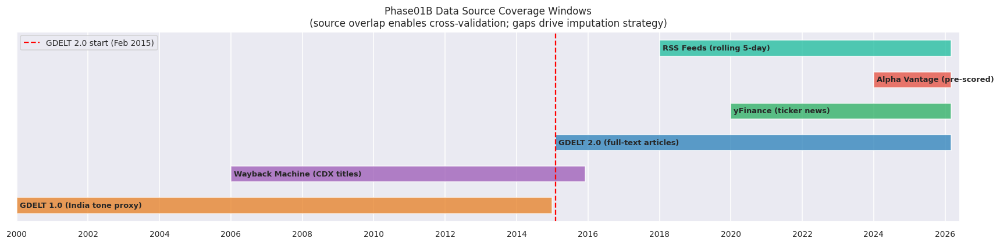


📊 Source Coverage in Key Periods:
   2000-01                  : ['GDELT 1.0 (India tone proxy)']
   2008-09 (GFC)            : ['GDELT 1.0 (India tone proxy)', 'Wayback Machine (CDX titles)']
   2013-05 (Taper)          : ['GDELT 1.0 (India tone proxy)', 'Wayback Machine (CDX titles)']
   2015-06 (GDELT2 era)     : ['Wayback Machine (CDX titles)', 'GDELT 2.0 (full-text articles)']
   2020-03 (COVID)          : ['GDELT 2.0 (full-text articles)', 'yFinance (ticker news)', 'RSS Feeds (rolling 5-day)']
   2024-06                  : ['GDELT 2.0 (full-text articles)', 'yFinance (ticker news)', 'Alpha Vantage (pre-scored)', 'RSS Feeds (rolling 5-day)']


In [36]:
# ── 4d. Source Transition Timeline ───────────────────────────────────────────
# Phase01B source windows (from CFG section)
source_windows = [
    ('GDELT 1.0 (India tone proxy)',     '2000-01', '2015-01', '#e67e22'),
    ('Wayback Machine (CDX titles)',      '2006-01', '2015-12', '#9b59b6'),
    ('GDELT 2.0 (full-text articles)',   '2015-02', '2026-03', '#2980b9'),
    ('yFinance (ticker news)',           '2020-01', '2026-03', '#27ae60'),
    ('Alpha Vantage (pre-scored)',        '2024-01', '2026-03', '#e74c3c'),
    ('RSS Feeds (rolling 5-day)',        '2018-01', '2026-03', '#1abc9c'),
]

fig, ax = plt.subplots(figsize=(16, 4))
for i, (label, start, end, color) in enumerate(source_windows):
    s = pd.Timestamp(start)
    e = pd.Timestamp(end)
    ax.barh(i, (e - s).days, left=s.toordinal(), height=0.5,
            color=color, alpha=0.75, edgecolor='white')
    ax.text(s.toordinal() + 30, i, label, va='center', fontsize=8.5, fontweight='bold')

# x-axis as dates
start_ord = pd.Timestamp('2000-01-01').toordinal()
end_ord   = pd.Timestamp('2026-06-01').toordinal()
tick_dts  = pd.date_range('2000', '2027', freq='2YS')
ax.set_xticks([d.toordinal() for d in tick_dts])
ax.set_xticklabels([d.strftime('%Y') for d in tick_dts], fontsize=9)
ax.set_xlim(start_ord, end_ord)
ax.set_yticks([])
ax.axvline(pd.Timestamp('2015-02-01').toordinal(), color='red', lw=1.5, linestyle='--', label='GDELT 2.0 start (Feb 2015)')
ax.set_title('Phase01B Data Source Coverage Windows\n(source overlap enables cross-validation; gaps drive imputation strategy)', fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout()
_save('Plot14d_source_transition_timeline.png')
plt.show()

# Source overlap matrix
print('\n📊 Source Coverage in Key Periods:')
for period, label in [('2000-01','2000-01'), ('2008-09','2008-09 (GFC)'), ('2013-05','2013-05 (Taper)'),
                       ('2015-06','2015-06 (GDELT2 era)'), ('2020-03','2020-03 (COVID)'), ('2024-06','2024-06')]:
    dt = pd.Timestamp(period)
    active = [lbl for lbl, s, e, _ in source_windows
              if pd.Timestamp(s) <= dt <= pd.Timestamp(e)]
    print(f'   {label:25s}: {active}')

---
## 5. Sentiment Analysis & Trends
**Research note**: Monthly net sentiment should reflect known bearish/bullish periods. Key validation: does sentiment drop around COVID (Mar 2020), GFC (Sep 2008), IL&FS (Sep 2018)? Does it rise during bull runs (2003–07, 2014, 2020–21)?

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot15a_net_sentiment_timeseries.png


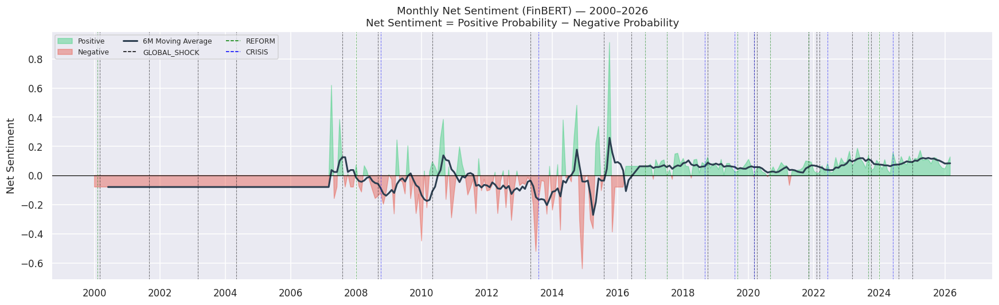

In [37]:

# ── 5a. Net sentiment time series with event overlays ───────────────────────
if 'net_sentiment_mean' in df.columns:

    fig, ax = plt.subplots(figsize=(16, 5))

    net_sent = df['net_sentiment_mean'].fillna(0)
    ma6 = net_sent.rolling(6).mean()

    # Positive / negative sentiment regions
    ax.fill_between(df['period_dt'], net_sent, 0,
                    where=net_sent >= 0,
                    interpolate=True,
                    alpha=0.4,
                    color='#2ecc71',
                    label='Positive')

    ax.fill_between(df['period_dt'], net_sent, 0,
                    where=net_sent < 0,
                    interpolate=True,
                    alpha=0.4,
                    color='#e74c3c',
                    label='Negative')

    # Moving average
    ax.plot(df['period_dt'],
            ma6,
            color='#2c3e50',
            lw=2,
            label='6M Moving Average')

    # Reference lines
    ax.axhline(0, color='black', lw=0.8)

    # Event annotations
    for annot_event, annot_color, _ in event_groups:
        for evt_dt, _ in annot_event:
            ax.axvline(pd.Timestamp(evt_dt),
                       color=annot_color,
                       linestyle='--',
                       lw=0.7,
                       alpha=0.5)

    # Event legend handles
    event_handles = [
        Line2D([0], [0],
               color=c,
               linestyle='--',
               lw=1,
               label=l)
        for _, c, l in event_groups
    ]

    # Combined legend
    handles, labels = ax.get_legend_handles_labels()

    ax.legend(handles + event_handles,
              labels + [l for _, _, l in event_groups],
              fontsize=8,
              loc='upper left',
              ncol=3)

    ax.set_title(
        'Monthly Net Sentiment (FinBERT) — 2000–2026\n'
        'Net Sentiment = Positive Probability − Negative Probability',
        fontsize=12
    )

    ax.set_ylabel('Net Sentiment')

    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()

    _fig_name = 'Plot15a_net_sentiment_timeseries.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)

    plt.savefig(_fig_path,
                dpi=150,
                bbox_inches='tight',
                facecolor='white')

    print(f'📁 Saved → {_fig_path}')

    plt.show()

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot15b_sentiment_distribution.png


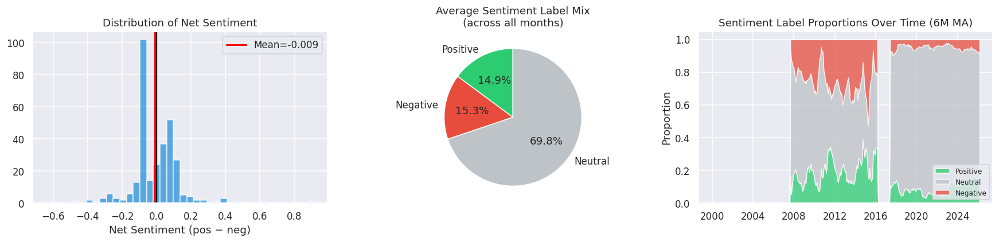


📊 Sentiment Statistics:
   Overall mean net sentiment: -0.0090
   Pre-2015 mean: -0.0630
   Post-2015 mean: 0.0628
   Bearish months (net < -0.10): 37


In [38]:
# ── 5b. Sentiment distribution and label mix ─────────────────────────────────
sent_label_cols = ['pct_positive', 'pct_negative', 'pct_neutral']
valid_sent = [c for c in sent_label_cols if c in df.columns]

if valid_sent:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    # Distribution of net sentiment
    axes[0].hist(df['net_sentiment_mean'].dropna(), bins=40, color='#3498db', edgecolor='white', alpha=0.8)
    axes[0].axvline(0, color='black', lw=1.5)
    axes[0].axvline(df['net_sentiment_mean'].mean(), color='red', lw=2,
                    label=f'Mean={df["net_sentiment_mean"].mean():.3f}')
    axes[0].set_title('Distribution of Net Sentiment')
    axes[0].set_xlabel('Net Sentiment (pos − neg)')
    axes[0].legend()

    # Average sentiment label mix
    avg_mix = df[valid_sent].mean()
    axes[1].pie(avg_mix.values, labels=['Positive', 'Negative', 'Neutral'],
                colors=['#2ecc71', '#e74c3c', '#bdc3c7'],
                autopct='%1.1f%%', startangle=90)
    axes[1].set_title('Average Sentiment Label Mix\n(across all months)')

    # Stacked area chart over time
    if 'pct_positive' in df.columns and 'pct_negative' in df.columns and 'pct_neutral' in df.columns:
        axes[2].stackplot(df['period_dt'],
                          df['pct_positive'].rolling(6).mean().fillna(0),
                          df['pct_neutral'].rolling(6).mean().fillna(0),
                          df['pct_negative'].rolling(6).mean().fillna(0),
                          labels=['Positive', 'Neutral', 'Negative'],
                          colors=['#2ecc71', '#bdc3c7', '#e74c3c'], alpha=0.75)
        axes[2].set_title('Sentiment Label Proportions Over Time (6M MA)')
        axes[2].set_ylabel('Proportion')
        axes[2].legend(loc='lower right', fontsize=8)

    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot15b_sentiment_distribution.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

    if 'net_sentiment_mean' in df.columns:
        print(f'\n📊 Sentiment Statistics:')
        print(f'   Overall mean net sentiment: {df["net_sentiment_mean"].mean():.4f}')
        print(f'   Pre-2015 mean: {df.loc[df["period_dt"] < "2015-01-01", "net_sentiment_mean"].mean():.4f}')
        print(f'   Post-2015 mean: {df.loc[df["period_dt"] >= "2015-01-01", "net_sentiment_mean"].mean():.4f}')
        print(f'   Bearish months (net < -0.10): {(df["net_sentiment_mean"] < -0.10).sum()}')

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot15c_sentiment_momentum.png


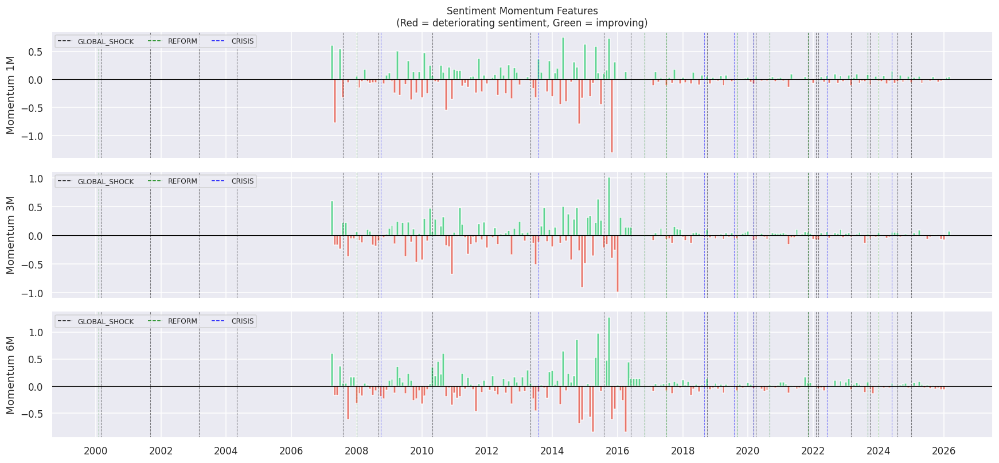

In [39]:

# ── 5c. Sentiment momentum features ─────────────────────────────────────────
momentum_cols = [
    c for c in [
        'sentiment_momentum_1m',
        'sentiment_momentum_3m',
        'sentiment_momentum_6m'
    ]
    if c in df.columns
]

if momentum_cols:

    fig, axes = plt.subplots(
        len(momentum_cols), 1,
        figsize=(16, 2.5 * len(momentum_cols)),
        sharex=True
    )

    if len(momentum_cols) == 1:
        axes = [axes]

    # Event legend handles
    event_handles = [
        Line2D([0], [0],
               color=c,
               linestyle='--',
               lw=1,
               label=l)
        for _, c, l in event_groups
    ]

    for ax, col in zip(axes, momentum_cols):

        vals = df[col].fillna(0)

        # Momentum bars
        ax.bar(
            df['period_dt'],
            vals,
            color=['#e74c3c' if v < 0 else '#2ecc71' for v in vals],
            width=25,
            alpha=0.75
        )

        ax.axhline(0, color='black', lw=0.8)

        # Event annotations
        for annot_event, annot_color, _ in event_groups:
            for evt_dt, _ in annot_event:
                ax.axvline(pd.Timestamp(evt_dt),
                           color=annot_color,
                           linestyle='--',
                           lw=0.7,
                           alpha=0.5)

        ax.set_ylabel(
            col.replace('sentiment_', '')
               .replace('_', ' ')
               .title()
        )

        # Legend
        ax.legend(handles=event_handles,
                  fontsize=8,
                  loc='upper left',
                  ncol=3)

    axes[0].set_title(
        'Sentiment Momentum Features\n'
        '(Red = deteriorating sentiment, Green = improving)',
        fontsize=11
    )

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()

    _fig_name = 'Plot15c_sentiment_momentum.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)

    plt.savefig(_fig_path,
                dpi=150,
                bbox_inches='tight',
                facecolor='white')

    print(f'📁 Saved → {_fig_path}')

    plt.show()

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot15d_gdelt1_vs_finbert.png


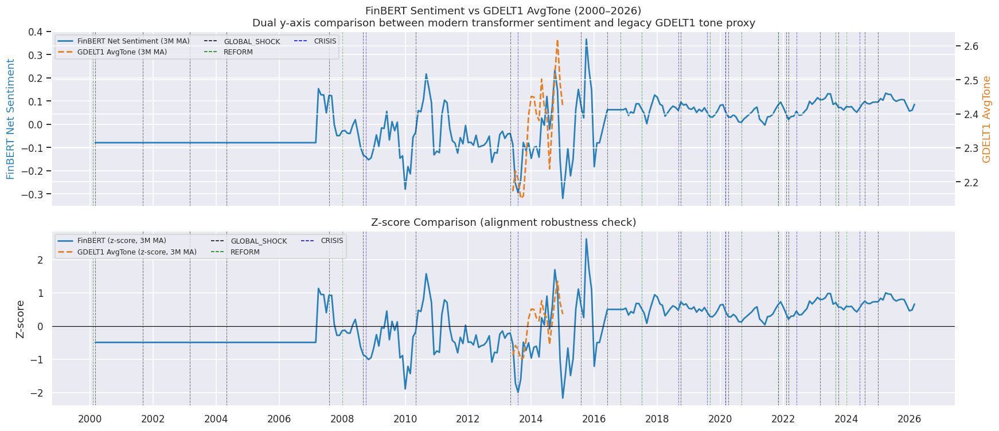


📊 GDELT1 AvgTone vs FinBERT Spearman r = 0.424 (p=0.0492)
   ✅ Good alignment


In [40]:

# ── 5d. GDELT1 AvgTone vs FinBERT Net Sentiment ─────────────────────────────
if not gdelt1.empty and 'net_sentiment_mean' in df.columns:

    g1 = gdelt1.copy()

    if 'period' not in g1.columns and 'date' in g1.columns:
        g1['period'] = (
            pd.to_datetime(g1['date'], errors='coerce')
              .dt.to_period('M')
              .astype(str)
        )

    tone_col = next(
        (c for c in g1.columns
         if 'tone' in c.lower() or 'avgtone' in c.lower()),
        None
    )

    if tone_col:

        g1_monthly = (
            g1.groupby('period')[tone_col]
              .mean()
              .reset_index()
        )

        g1_monthly.columns = ['period', 'gdelt1_tone']

        g1_monthly['period_dt'] = pd.to_datetime(
            g1_monthly['period'].astype(str) + '-01',
            errors='coerce'
        )

        # Merge with main df
        merge_df = df[['period_dt', 'net_sentiment_mean']].merge(
            g1_monthly[['period_dt', 'gdelt1_tone']],
            on='period_dt',
            how='left'
        )

        # Z-score normalization
        for col in ['net_sentiment_mean', 'gdelt1_tone']:

            if merge_df[col].std() > 0:

                merge_df[f'{col}_z'] = (
                    (merge_df[col] - merge_df[col].mean()) /
                    merge_df[col].std()
                )

        fig, axes = plt.subplots(
            2, 1,
            figsize=(16, 7),
            sharex=True
        )

        # Event legend handles
        event_handles = [
            Line2D([0], [0],
                   color=c,
                   linestyle='--',
                   lw=1,
                   label=l)
            for _, c, l in event_groups
        ]

        # ── Raw comparison ────────────────────────────────────────────
        axes[0].plot(
            merge_df['period_dt'],
            merge_df['net_sentiment_mean'].rolling(3).mean(),
            label='FinBERT Net Sentiment (3M MA)',
            color='#2980b9',
            lw=1.8
        )

        ax0b = axes[0].twinx()

        ax0b.plot(
            merge_df['period_dt'],
            merge_df['gdelt1_tone'].rolling(3).mean(),
            label='GDELT1 AvgTone (3M MA)',
            color='#e67e22',
            lw=1.8,
            linestyle='--'
        )

        axes[0].set_ylabel(
            'FinBERT Net Sentiment',
            color='#2980b9'
        )

        ax0b.set_ylabel(
            'GDELT1 AvgTone',
            color='#e67e22'
        )

        # Event annotations
        for annot_event, annot_color, _ in event_groups:
            for evt_dt, _ in annot_event:
                for ax in [axes[0], axes[1]]:
                    ax.axvline(pd.Timestamp(evt_dt),
                               color=annot_color,
                               linestyle='--',
                               lw=0.7,
                               alpha=0.5)

        # Legend
        handles0, labels0 = axes[0].get_legend_handles_labels()
        handles1, labels1 = ax0b.get_legend_handles_labels()

        axes[0].legend(
            handles0 + handles1 + event_handles,
            labels0 + labels1 + [l for _, _, l in event_groups],
            fontsize=8,
            loc='upper left',
            ncol=3
        )

        axes[0].set_title(
            'FinBERT Sentiment vs GDELT1 AvgTone (2000–2026)\n'
            'Dual y-axis comparison between modern transformer sentiment '
            'and legacy GDELT1 tone proxy'
        )

        # ── Z-score comparison ────────────────────────────────────────
        if ('net_sentiment_mean_z' in merge_df.columns and
            'gdelt1_tone_z' in merge_df.columns):

            axes[1].plot(
                merge_df['period_dt'],
                merge_df['net_sentiment_mean_z'].rolling(3).mean(),
                label='FinBERT (z-score, 3M MA)',
                color='#2980b9',
                lw=1.8
            )

            axes[1].plot(
                merge_df['period_dt'],
                merge_df['gdelt1_tone_z'].rolling(3).mean(),
                label='GDELT1 AvgTone (z-score, 3M MA)',
                color='#e67e22',
                lw=1.8,
                linestyle='--'
            )

            axes[1].axhline(0, color='black', lw=0.8)

            handles, labels = axes[1].get_legend_handles_labels()

            axes[1].legend(
                handles + event_handles,
                labels + [l for _, _, l in event_groups],
                fontsize=8,
                loc='upper left',
                ncol=3
            )

            axes[1].set_ylabel('Z-score')

            axes[1].set_title(
                'Z-score Comparison (alignment robustness check)'
            )

        axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
        axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

        plt.tight_layout()

        _save('Plot15d_gdelt1_vs_finbert.png')

        plt.show()

        # ── Correlation check ─────────────────────────────────────────
        overlap = merge_df.dropna(
            subset=['net_sentiment_mean', 'gdelt1_tone']
        )

        if len(overlap) > 10:

            r, p = spearmanr(
                overlap['net_sentiment_mean'],
                overlap['gdelt1_tone']
            )

            print(
                f'\n📊 GDELT1 AvgTone vs FinBERT '
                f'Spearman r = {r:.3f} (p={p:.4f})'
            )

            print(
                '   ✅ Good alignment'
                if abs(r) > 0.3
                else '   ⚠️ Weak alignment — review pre-2015 proxy'
            )

    else:
        print('⚠️ No tone column found in GDELT1 data.')

else:
    print('⚠️ GDELT1 or sentiment data not available.')

### 5e. Sentiment Uncertainty — Monthly Standard Deviation
**Research note**: `net_sentiment_std` captures *dispersion* across articles in a month — high std means contradictory signals (some articles very bearish, some bullish). High dispersion months are often transition periods and warrant model caution.


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot15e_sentiment_std.png


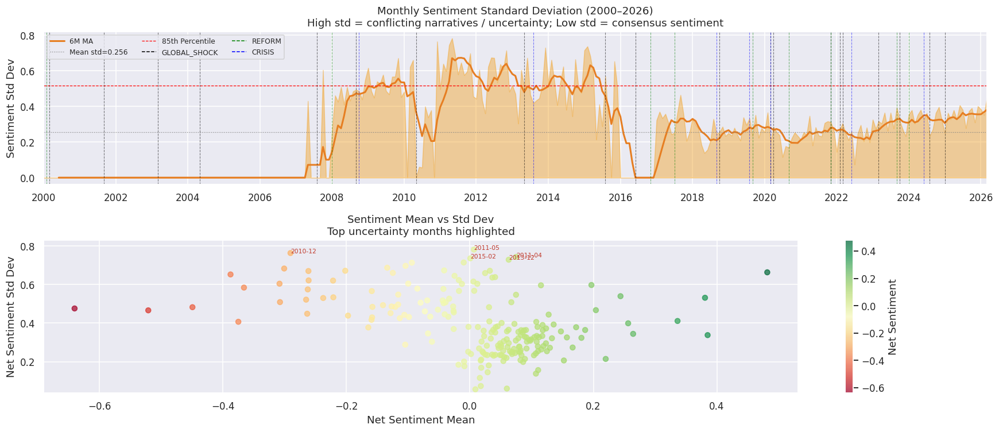


📊 Sentiment Uncertainty Stats (2000 onwards):
   Mean std: 0.3938
   High-uncertainty months (>85th percentile): 31

   Top 5 highest-uncertainty months:
 period  net_sentiment_mean  net_sentiment_std
2011-05            0.006508           0.782127
2010-12           -0.290640           0.763973
2011-04            0.075082           0.744157
2015-02            0.000678           0.736558
2013-12            0.062860           0.729335


In [41]:

# ── 5e. Sentiment Uncertainty (2000 onwards only) ───────────────────────────
if 'net_sentiment_std' in df.columns:

    # Filter dataset from 2000 onwards
    plot_df = df[df['period_dt'] >= pd.Timestamp('2000-01-01')].copy()

    fig, axes = plt.subplots(
        2, 1,
        figsize=(16, 7),
        sharex=False
    )

    # ── Event legend handles ─────────────────────────────────────────
    event_handles = [
        Line2D([0], [0],
               color=c,
               linestyle='--',
               lw=1,
               label=l)
        for _, c, l in event_groups
    ]

    # ── Panel 1: Time-series uncertainty plot ───────────────────────
    std_series = plot_df['net_sentiment_std'].fillna(0)

    axes[0].fill_between(
        plot_df['period_dt'],
        std_series,
        alpha=0.4,
        color='#f39c12'
    )

    axes[0].plot(
        plot_df['period_dt'],
        std_series.rolling(6).mean(),
        color='#e67e22',
        lw=2,
        label='6M MA'
    )

    axes[0].axhline(
        std_series.mean(),
        color='grey',
        lw=0.8,
        linestyle=':',
        label=f'Mean std={std_series.mean():.3f}'
    )

    axes[0].axhline(
        std_series.quantile(0.85),
        color='red',
        lw=0.8,
        linestyle='--',
        label='85th Percentile'
    )

    # Event annotations
    for annot_event, annot_color, _ in event_groups:

        for evt_dt, _ in annot_event:

            evt_ts = pd.Timestamp(evt_dt)

            if evt_ts >= pd.Timestamp('2000-01-01'):

                axes[0].axvline(
                    evt_ts,
                    color=annot_color,
                    linestyle='--',
                    lw=0.7,
                    alpha=0.5
                )

    # Combined legend
    handles, labels = axes[0].get_legend_handles_labels()

    axes[0].legend(
        handles + event_handles,
        labels + [l for _, _, l in event_groups],
        fontsize=8,
        loc='upper left',
        ncol=3
    )

    axes[0].set_title(
        'Monthly Sentiment Standard Deviation (2000–2026)\n'
        'High std = conflicting narratives / uncertainty; '
        'Low std = consensus sentiment',
        fontsize=12
    )

    axes[0].set_ylabel('Sentiment Std Dev')

    # Restrict x-axis to 2000 onwards
    axes[0].set_xlim(
        pd.Timestamp('2000-01-01'),
        plot_df['period_dt'].max()
    )

    axes[0].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    # ── Panel 2: Scatter plot ────────────────────────────────────────
    valid = plot_df[
        ['net_sentiment_mean',
         'net_sentiment_std',
         'period']
    ].dropna()

    scatter = axes[1].scatter(
        valid['net_sentiment_mean'],
        valid['net_sentiment_std'],
        c=valid['net_sentiment_mean'],
        cmap='RdYlGn',
        alpha=0.7,
        s=35
    )

    plt.colorbar(
        scatter,
        ax=axes[1],
        label='Net Sentiment'
    )

    # Label top uncertainty months
    top_unc = valid.nlargest(5, 'net_sentiment_std')

    for _, row in top_unc.iterrows():

        axes[1].annotate(
            row['period'],
            (row['net_sentiment_mean'],
             row['net_sentiment_std']),
            fontsize=7,
            color='#c0392b'
        )

    axes[1].set_title(
        'Sentiment Mean vs Std Dev\n'
        'Top uncertainty months highlighted'
    )

    axes[1].set_xlabel('Net Sentiment Mean')
    axes[1].set_ylabel('Net Sentiment Std Dev')

    # Proper numeric axis limits
    axes[1].set_xlim(
        valid['net_sentiment_mean'].min() - 0.05,
        valid['net_sentiment_mean'].max() + 0.05
    )

    axes[1].set_ylim(
        valid['net_sentiment_std'].min() - 0.02,
        valid['net_sentiment_std'].max() + 0.05
    )

    plt.tight_layout()

    _save('Plot15e_sentiment_std.png')

    plt.show()

    # ── Stats ────────────────────────────────────────────────────────
    high_unc = (
        plot_df['net_sentiment_std'] >
        plot_df['net_sentiment_std'].quantile(0.85)
    ).sum()

    print(f'\n📊 Sentiment Uncertainty Stats (2000 onwards):')
    print(f'   Mean std: {plot_df["net_sentiment_std"].mean():.4f}')
    print(f'   High-uncertainty months (>85th percentile): {high_unc}')

    print('\n   Top 5 highest-uncertainty months:')

    print(
        plot_df.nlargest(5, 'net_sentiment_std')[
            ['period',
             'net_sentiment_mean',
             'net_sentiment_std']
        ].to_string(index=False)
    )

else:
    print('⚠️ net_sentiment_std column not found.')

### 5f. Source Diversity — Monthly Unique Sources Count
**Research note**: `sources_count` tracks how many distinct news sources contributed to each month's sentiment. Months with few sources (low diversity) produce less reliable FinBERT aggregates — this flags them for downstream weighting.


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot15f_sources_count.png


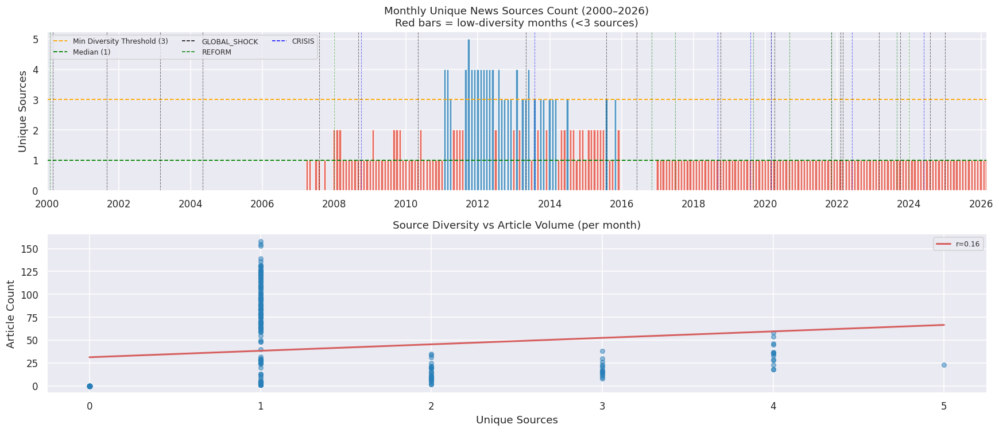


📊 Source Diversity Stats (2000 onwards):
   Median sources/month     : 1
   Low-diversity months (<3): 284 (90.2%)
   Pre-2015 avg sources     : 1.0
   Post-2015 avg sources    : 1.0


In [42]:

# ── 5f. Source Diversity Over Time (2000 onwards) ───────────────────────────
if 'sources_count' in df.columns:

    # Filter from 2000 onwards
    plot_df = df[df['period_dt'] >= pd.Timestamp('2000-01-01')].copy()

    fig, axes = plt.subplots(
        2, 1,
        figsize=(16, 7),
        sharex=False
    )

    # Event legend handles
    event_handles = [
        Line2D([0], [0],
               color=c,
               linestyle='--',
               lw=1,
               label=l)
        for _, c, l in event_groups
    ]

    # ── Panel 1: Sources count time series ───────────────────────────
    axes[0].bar(
        plot_df['period_dt'],
        plot_df['sources_count'].fillna(0),
        color=[
            '#e74c3c' if v < 3 else '#2980b9'
            for v in plot_df['sources_count'].fillna(0)
        ],
        width=25,
        alpha=0.8
    )

    axes[0].axhline(
        3,
        color='orange',
        lw=1.2,
        linestyle='--',
        label='Min Diversity Threshold (3)'
    )

    axes[0].axhline(
        plot_df['sources_count'].median(),
        color='green',
        lw=1.2,
        linestyle='--',
        label=f'Median ({int(plot_df["sources_count"].median())})'
    )

    # Event annotations
    for annot_event, annot_color, _ in event_groups:

        for evt_dt, _ in annot_event:

            evt_ts = pd.Timestamp(evt_dt)

            if evt_ts >= pd.Timestamp('2000-01-01'):

                axes[0].axvline(
                    evt_ts,
                    color=annot_color,
                    linestyle='--',
                    lw=0.7,
                    alpha=0.5
                )

    # Combined legend
    handles, labels = axes[0].get_legend_handles_labels()

    axes[0].legend(
        handles + event_handles,
        labels + [l for _, _, l in event_groups],
        fontsize=8,
        loc='upper left',
        ncol=3
    )

    axes[0].set_title(
        'Monthly Unique News Sources Count (2000–2026)\n'
        'Red bars = low-diversity months (<3 sources)',
        fontsize=12
    )

    axes[0].set_ylabel('Unique Sources')

    axes[0].set_xlim(
        pd.Timestamp('2000-01-01'),
        plot_df['period_dt'].max()
    )

    axes[0].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    # ── Panel 2: Sources vs Article Count ────────────────────────────
    if 'article_count' in plot_df.columns:

        valid = plot_df[
            ['sources_count', 'article_count']
        ].dropna()

        axes[1].scatter(
            valid['sources_count'],
            valid['article_count'],
            alpha=0.5,
            s=25,
            color='#2980b9'
        )

        # Regression line
        if valid['sources_count'].nunique() > 1:

            m, b, r, p, _ = stats.linregress(
                valid['sources_count'],
                valid['article_count']
            )

            xs = np.linspace(
                valid['sources_count'].min(),
                valid['sources_count'].max(),
                100
            )

            axes[1].plot(
                xs,
                m * xs + b,
                'r-',
                lw=2,
                label=f'r={r:.2f}'
            )

            axes[1].legend(fontsize=8)

        else:

            axes[1].text(
                0.05,
                0.95,
                'Regression not available\n'
                '(insufficient variance)',
                transform=axes[1].transAxes,
                fontsize=8,
                va='top',
                color='grey'
            )

        axes[1].set_xlabel('Unique Sources')
        axes[1].set_ylabel('Article Count')

        axes[1].set_title(
            'Source Diversity vs Article Volume (per month)'
        )

    plt.tight_layout()

    _save('Plot15f_sources_count.png')

    plt.show()

    # ── Stats ────────────────────────────────────────────────────────
    low_div = (plot_df['sources_count'] < 3).sum()

    print(f'\n📊 Source Diversity Stats (2000 onwards):')

    print(
        f'   Median sources/month     : '
        f'{plot_df["sources_count"].median():.0f}'
    )

    print(
        f'   Low-diversity months (<3): '
        f'{low_div} '
        f'({low_div/len(plot_df)*100:.1f}%)'
    )

    print(
        f'   Pre-2015 avg sources     : '
        f'{plot_df.loc[plot_df["period_dt"] < "2015-01-01", "sources_count"].mean():.1f}'
    )

    print(
        f'   Post-2015 avg sources    : '
        f'{plot_df.loc[plot_df["period_dt"] >= "2015-01-01", "sources_count"].mean():.1f}'
    )

else:
    print('⚠️ sources_count column not found.')

### 5g. Per-Category Net Sentiment — Financial · Political · Climate
**Research note**: Phase 01B computes `sent_financial`, `sent_political`, `sent_climate` — net FinBERT sentiment restricted to articles tagged in each risk category. These signals are more targeted than the overall `net_sentiment_mean` and should show category-specific patterns (e.g. `sent_political` should dip around elections; `sent_climate` should worsen during monsoon failures).


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot15g1_per_category_overlay.png


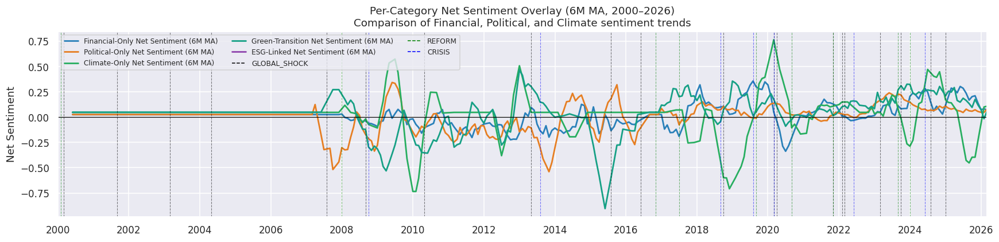

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot15g2_per_category_individual.png


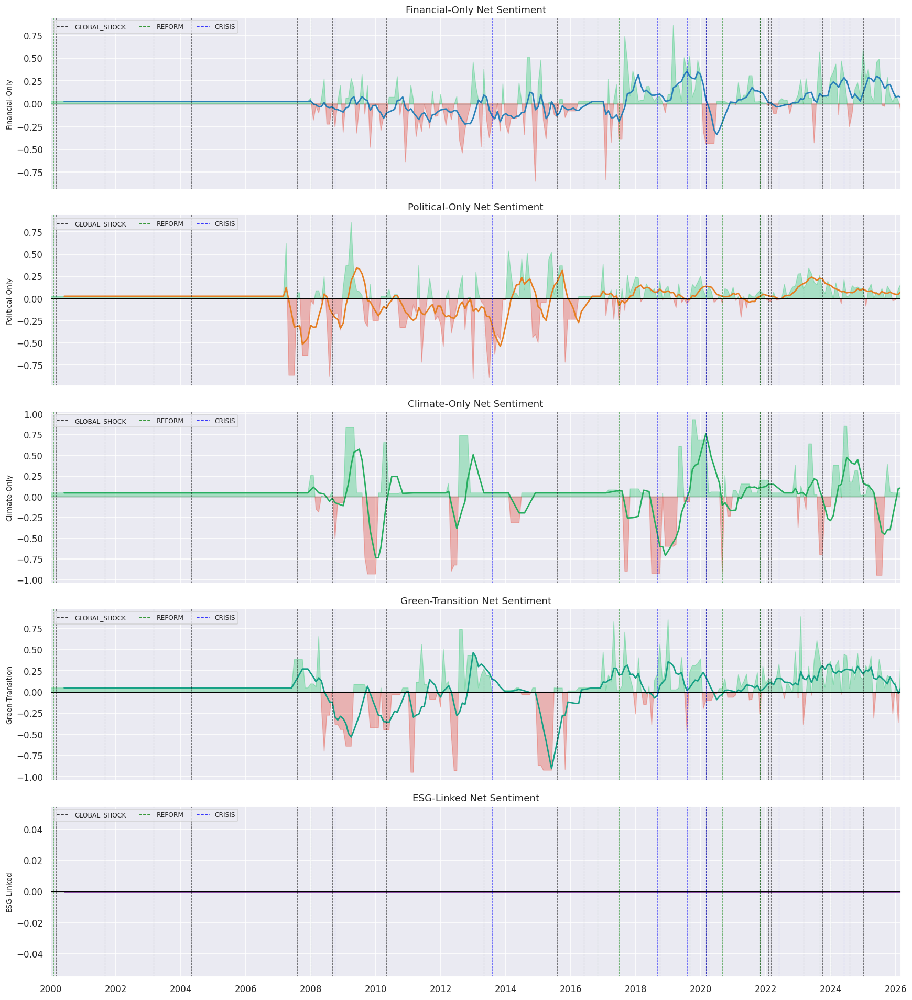


📊 Category Sentiment vs Overall Net Sentiment (Spearman):
   Financial-Only Net Sentiment       : r=0.452 (p=0.0000)
   Political-Only Net Sentiment       : r=0.457 (p=0.0000)
   Climate-Only Net Sentiment         : r=0.097 (p=0.0855)
   Green-Transition Net Sentiment     : r=0.215 (p=0.0001)


In [43]:

# ── 5g. Per-Category Net Sentiment (2000 onwards) ───────────────────────────
cat_sent_cols = [
    (c, lbl, color) for c, lbl, color in [
        ('sent_financial',
         'Financial-Only Net Sentiment',
         '#2980b9'),

        ('sent_political',
         'Political-Only Net Sentiment',
         '#e67e22'),

        ('sent_climate',
         'Climate-Only Net Sentiment',
         '#27ae60'),

        ('sent_green_transition',
         'Green-Transition Net Sentiment',
         '#16a085'),

        ('sent_esg',
         'ESG-Linked Net Sentiment',
         '#8e44ad'),
    ]
    if c in df.columns
]

if cat_sent_cols:

    # Filter from 2000 onwards
    plot_df = df[df['period_dt'] >= pd.Timestamp('2000-01-01')].copy()

    # ── Event legend handles ─────────────────────────────────────────
    event_handles = [
        Line2D([0], [0],
               color=c,
               linestyle='--',
               lw=1,
               label=l)
        for _, c, l in event_groups
    ]

    # =================================================================
    # FIGURE 1 — OVERLAY ONLY
    # =================================================================
    fig, ax = plt.subplots(figsize=(16, 4))

    for col, lbl, color in cat_sent_cols:

        ax.plot(
            plot_df['period_dt'],
            plot_df[col].rolling(6).mean(),
            color=color,
            lw=1.8,
            label=f'{lbl} (6M MA)'
        )

    ax.axhline(0, color='black', lw=0.8)

    # Event annotations
    for annot_event, annot_color, _ in event_groups:

        for evt_dt, _ in annot_event:

            evt_ts = pd.Timestamp(evt_dt)

            if evt_ts >= pd.Timestamp('2000-01-01'):

                ax.axvline(
                    evt_ts,
                    color=annot_color,
                    linestyle='--',
                    lw=0.7,
                    alpha=0.5
                )

    # Combined legend
    handles, labels = ax.get_legend_handles_labels()

    ax.legend(
        handles + event_handles,
        labels + [l for _, _, l in event_groups],
        fontsize=8,
        loc='upper left',
        ncol=3
    )

    ax.set_title(
        'Per-Category Net Sentiment Overlay (6M MA, 2000–2026)\n'
        'Comparison of Financial, Political, and Climate sentiment trends'
    )

    ax.set_ylabel('Net Sentiment')

    ax.set_xlim(
        pd.Timestamp('2000-01-01'),
        plot_df['period_dt'].max()
    )

    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()

    _save('Plot15g1_per_category_overlay.png')

    plt.show()

    # =================================================================
    # FIGURE 2 — INDIVIDUAL PANELS
    # =================================================================
    fig, axes = plt.subplots(
        len(cat_sent_cols),
        1,
        figsize=(16, 3.5 * len(cat_sent_cols)),
        sharex=True
    )

    if len(cat_sent_cols) == 1:
        axes = [axes]

    for ax, (col, lbl, color) in zip(axes, cat_sent_cols):

        vals = plot_df[col].fillna(0)

        ax.fill_between(
            plot_df['period_dt'],
            vals,
            0,
            where=vals >= 0,
            interpolate=True,
            alpha=0.35,
            color='#2ecc71'
        )

        ax.fill_between(
            plot_df['period_dt'],
            vals,
            0,
            where=vals < 0,
            interpolate=True,
            alpha=0.35,
            color='#e74c3c'
        )

        ax.plot(
            plot_df['period_dt'],
            vals.rolling(6).mean(),
            color=color,
            lw=1.8
        )

        ax.axhline(0, color='black', lw=0.8)

        # Event annotations
        for annot_event, annot_color, _ in event_groups:

            for evt_dt, _ in annot_event:

                evt_ts = pd.Timestamp(evt_dt)

                if evt_ts >= pd.Timestamp('2000-01-01'):

                    ax.axvline(
                        evt_ts,
                        color=annot_color,
                        linestyle='--',
                        lw=0.7,
                        alpha=0.5
                    )

        ax.legend(
            handles=event_handles,
            fontsize=8,
            loc='upper left',
            ncol=3
        )

        ax.set_ylabel(
            lbl.replace(' Net Sentiment', ''),
            fontsize=9
        )

        ax.set_title(lbl)

    axes[-1].set_xlim(
        pd.Timestamp('2000-01-01'),
        plot_df['period_dt'].max()
    )

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()

    _save('Plot15g2_per_category_individual.png')

    plt.show()

    # ── Correlation stats ────────────────────────────────────────────
    if 'net_sentiment_mean' in plot_df.columns:

        print(
            '\n📊 Category Sentiment vs Overall Net Sentiment '
            '(Spearman):'
        )

        for col, lbl, _ in cat_sent_cols:

            valid = plot_df[
                [col, 'net_sentiment_mean']
            ].dropna()

            if len(valid) > 10:

                r, p = spearmanr(
                    valid[col],
                    valid['net_sentiment_mean']
                )

                print(
                    f'   {lbl:<35}: '
                    f'r={r:.3f} (p={p:.4f})'
                )

else:
    print('⚠️ sent_financial / sent_political / sent_climate not found.')

---
## 6. Risk Category Distribution
**Research note**: The Financial/Political/Climate category breakdown reveals the dominant risk narrative in each period. Political spikes should align with election months; Climate spikes should align with monsoon season (June–September).

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot16a_risk_category_timeseries.png


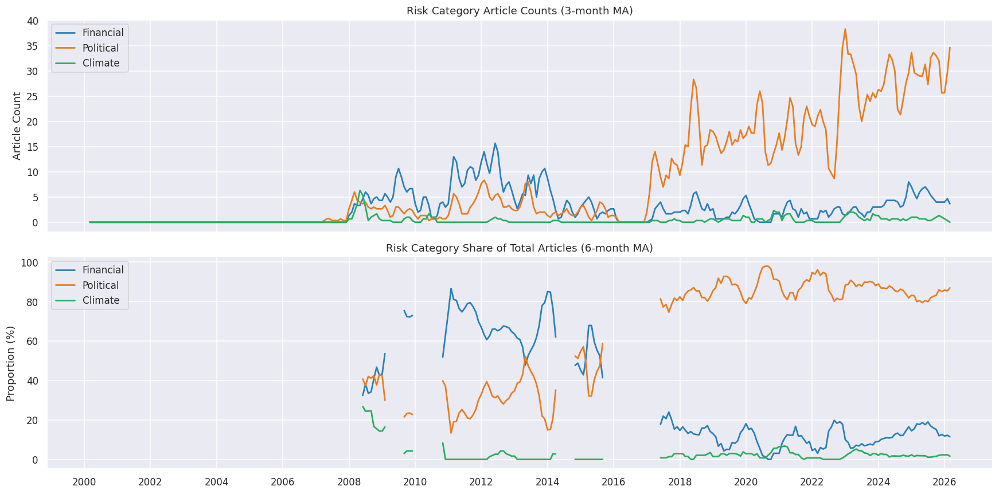

In [44]:
# ── 6a. Risk category time series ────────────────────────────────────────────
cat_count_cols = [c for c in ['count_financial', 'count_political', 'count_climate'] if c in df.columns]

if cat_count_cols:
    fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

    cat_colors = {'count_financial': '#2980b9', 'count_political': '#e67e22', 'count_climate': '#27ae60'}
    cat_labels = {'count_financial': 'Financial', 'count_political': 'Political', 'count_climate': 'Climate'}

    # Absolute counts
    for col in cat_count_cols:
        axes[0].plot(df['period_dt'], df[col].fillna(0).rolling(3).mean(),
                     label=cat_labels[col], color=cat_colors[col], lw=1.8)
    axes[0].set_title('Risk Category Article Counts (3-month MA)')
    axes[0].set_ylabel('Article Count')
    axes[0].legend()

    # Proportional share
    total = df[cat_count_cols].sum(axis=1).replace(0, np.nan)
    for col in cat_count_cols:
        pct_series = (df[col].fillna(0) / total * 100).rolling(6).mean()
        axes[1].plot(df['period_dt'], pct_series,
                     label=cat_labels[col], color=cat_colors[col], lw=1.8)
    axes[1].set_title('Risk Category Share of Total Articles (6-month MA)')
    axes[1].set_ylabel('Proportion (%)')
    axes[1].legend()
    axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot16a_risk_category_timeseries.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot16b_risk_category_seasonality.png


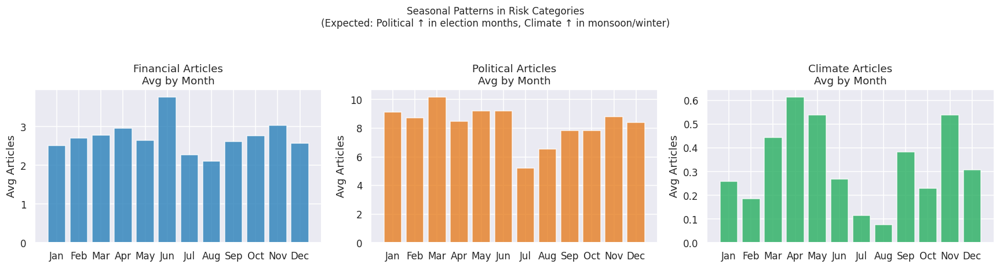

In [45]:
# ── 6b. Seasonality of risk categories ───────────────────────────────────────
if cat_count_cols and 'period' in df.columns:
    df['month_num'] = df['period_dt'].dt.month
    month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

    fig, axes = plt.subplots(1, len(cat_count_cols), figsize=(16, 4))

    for ax, col in zip(axes, cat_count_cols):
        monthly_avg = df.groupby('month_num')[col].mean()
        ax.bar(range(1, 13), monthly_avg.values, color=cat_colors[col], alpha=0.8)
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(month_names)
        ax.set_title(f'{cat_labels[col]} Articles\nAvg by Month')
        ax.set_ylabel('Avg Articles')

    plt.suptitle('Seasonal Patterns in Risk Categories\n'
                 '(Expected: Political ↑ in election months, Climate ↑ in monsoon/winter)',
                 fontsize=11, y=1.05)
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot16b_risk_category_seasonality.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

### 6c. Risk Category Keyword-Density Scores
**Research note**: Phase 01B also produces `score_financial`, `score_political`, `score_climate` — continuous keyword-density scores (fraction of words matching each category). These are more granular than the binary category counts and serve as continuous risk signals.


⏳ Computing keyword-density scores from corpus...
✅ Density scores computed for 215 months (5 categories).
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot16c_risk_density_scores.png


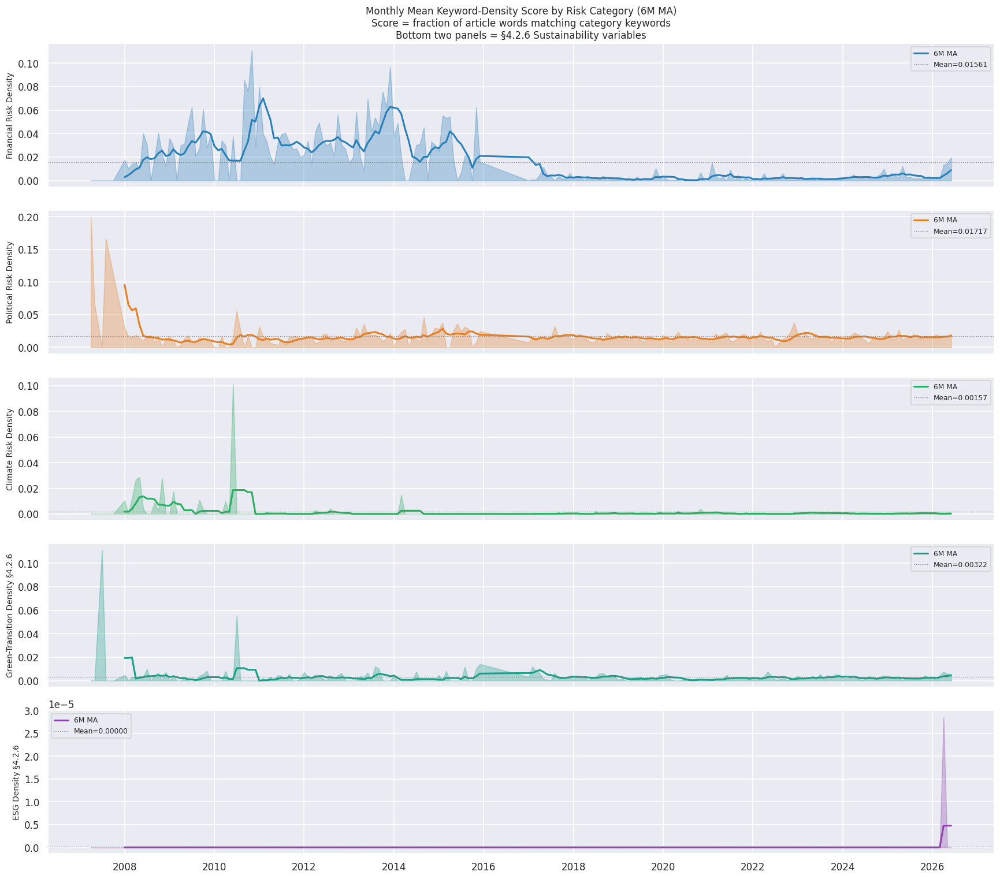


📊 Risk Density Score Cross-Correlations (Spearman):
                        score_financial  score_political  score_climate  score_green_transition  score_esg
score_financial                   1.000           -0.090          0.002                   0.028      0.028
score_political                  -0.090            1.000          0.019                  -0.021      0.022
score_climate                     0.002            0.019          1.000                   0.226      0.076
score_green_transition            0.028           -0.021          0.226                   1.000      0.103
score_esg                         0.028            0.022          0.076                   0.103      1.000
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot16d_risk_density_scores_correlation.png


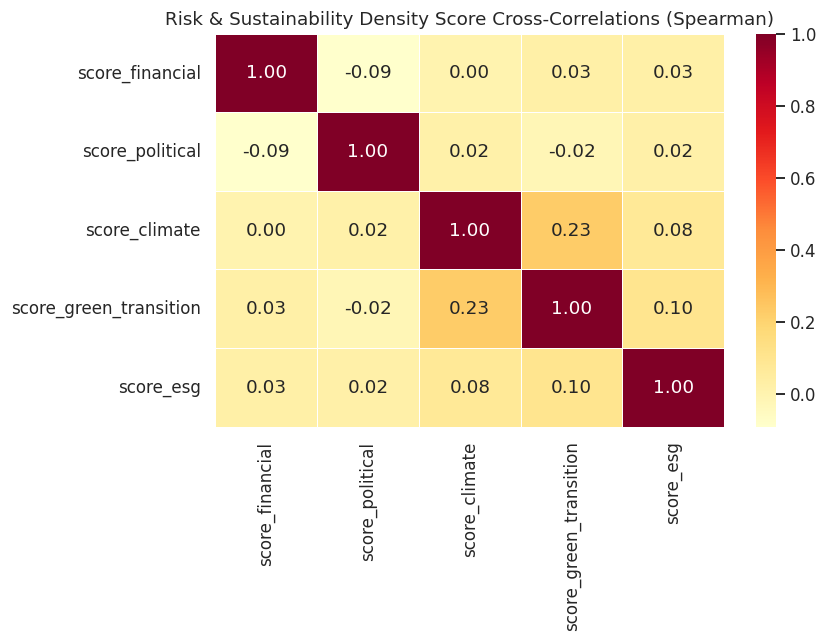


✅ score_financial / score_political / score_climate / score_green_transition / score_esg merged into df.


In [46]:
# ── 6c. Risk Category Keyword-Density Scores ─────────────────────────────────
# score_financial/political/climate are article-level columns in scored_df
# (Phase01B [RISK-CATEGORY]) — they are NOT aggregated into gpr_combined_monthly.csv.
# We recompute monthly mean density scores here from the corpus directly.

RISK_KEYWORDS = {
    'financial': [
        'nifty', 'sensex', 'banknifty', 'nse', 'bse', 'rbi', 'sebi', 'repo rate',
        'inflation', 'gdp', 'fiscal deficit', 'current account', 'rupee', 'fii',
        'dii', 'ipo', 'credit', 'liquidity', 'bond yield', 'fed rate', 'interest rate',
        'earnings', 'quarterly result', 'profit', 'revenue', 'stock market',
        'equity', 'derivative', 'futures', 'options', 'rally', 'correction',
    ],
    'political': [
        'election', 'lok sabha', 'rajya sabha', 'parliament', 'cabinet', 'minister',
        'policy reform', 'budget', 'union budget', 'tax reform', 'gst',
        'geopolitical', 'border', 'sanction', 'trade war', 'tariff', 'bilateral',
        'imf', 'world bank', 'g20', 'un', 'war', 'conflict', 'coup',
        'regulatory', 'disinvestment', 'privatisation',
    ],
    'climate': [
        'monsoon', 'flood', 'drought', 'cyclone', 'earthquake', 'disaster',
        'climate change', 'global warming', 'carbon', 'emission', 'carbon tax',
        'carbon credit', 'carbon market', 'cap and trade', 'paris agreement',
        'cop26', 'cop27', 'cop28', 'cop29', 'ipcc', 'net zero', 'net-zero',
        'heatwave', 'extreme weather', 'temperature rise', 'sea level',
        'agriculture', 'kharif', 'rabi', 'crop failure', 'el nino', 'la nina',
        'imd', 'rainfall', 'water scarcity', 'climate risk', 'transition risk',
    ],
    # Green-Transition Event Density
    'green_transition': [
        'renewable energy', 'solar', 'solar power', 'solar panel', 'wind energy',
        'wind farm', 'offshore wind', 'electric vehicle', 'ev', 'ev adoption',
        'battery storage', 'lithium', 'rare earth', 'green hydrogen',
        'decarbonization', 'decarbonisation', 'net-zero pledge', 'carbon neutral',
        'energy transition', 'clean energy', 'green energy', 'clean tech',
        'national solar mission', 'pm surya ghar', 'green taxonomy',
        'sustainable finance', 'green bond', 'sustainability bond', 'esg bond',
        'iea', 'irena', 'renewable capacity', 'rooftop solar', 'smart grid',
    ],
    # ESG-Linked Sentiment
    'esg': [
        'esg', 'environmental social governance', 'esg rating', 'esg score',
        'esg fund', 'esg investing', 'sustainable investing', 'impact investing',
        'green finance', 'responsible investment', 'climate finance',
        'carbon footprint', 'scope 1', 'scope 2', 'scope 3', 'ghg disclosure',
        'sebi esg', 'brsr', 'tcfd', 'csrd', 'eu taxonomy', 'greenwashing',
        'esg compliance', 'esg risk', 'esg report', 'sustainability report',
    ],
}

def _score_density(text: str) -> dict:
    """Keyword-density per category: hits / word_count (mirrors Phase01B logic)."""
    t = str(text).lower()
    words = len(t.split()) or 1
    return {cat: sum(1 for kw in kws if kw in t) / words
            for cat, kws in RISK_KEYWORDS.items()}

if not corpus.empty and 'title' in corpus.columns and 'period' in corpus.columns:
    print('⏳ Computing keyword-density scores from corpus...')
    text_col = corpus['title'].fillna('') + ' ' + corpus.get('summary', pd.Series('', index=corpus.index)).fillna('')
    scores   = text_col.apply(_score_density)
    corpus['score_financial']        = scores.apply(lambda x: x['financial'])
    corpus['score_political']        = scores.apply(lambda x: x['political'])
    corpus['score_climate']          = scores.apply(lambda x: x['climate'])
    corpus['score_green_transition'] = scores.apply(lambda x: x.get('green_transition', 0))
    corpus['score_esg']              = scores.apply(lambda x: x.get('esg', 0))

    # Aggregate to monthly mean density
    score_cols = ['score_financial', 'score_political', 'score_climate',
                  'score_green_transition', 'score_esg']
    score_monthly = (
        corpus.groupby('period')[score_cols]
        .mean()
        .reset_index()
    )
    score_monthly['period_dt'] = pd.to_datetime(score_monthly['period'] + '-01', errors='coerce')
    score_monthly = score_monthly.sort_values('period_dt')
    print(f'✅ Density scores computed for {len(score_monthly)} months (5 categories).')

    # ── Plot: all 5 categories ─────────────────────────────────────────────────
    score_defs = [
        ('score_financial',        'Financial Risk Density',       '#2980b9'),
        ('score_political',        'Political Risk Density',        '#e67e22'),
        ('score_climate',          'Climate Risk Density',          '#27ae60'),
        ('score_green_transition', 'Green-Transition Density §4.2.6','#16a085'),
        ('score_esg',              'ESG Density §4.2.6',            '#8e44ad'),
    ]
    fig, axes = plt.subplots(5, 1, figsize=(16, 14), sharex=True)

    for ax, (col, lbl, color) in zip(axes, score_defs):
        ax.fill_between(score_monthly['period_dt'], score_monthly[col], alpha=0.3, color=color)
        ax.plot(score_monthly['period_dt'], score_monthly[col].rolling(6).mean(),
                color=color, lw=2, label='6M MA')
        ax.axhline(score_monthly[col].mean(), color='grey', lw=0.8, linestyle=':',
                   label=f'Mean={score_monthly[col].mean():.5f}')
        ax.set_ylabel(lbl, fontsize=9)
        ax.legend(fontsize=8)

    axes[0].set_title('Monthly Mean Keyword-Density Score by Risk Category (6M MA)\n'
                      'Score = fraction of article words matching category keywords\n'
                      'Bottom two panels = §4.2.6 Sustainability variables', fontsize=11)
    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot16c_risk_density_scores.png')
    plt.show()

    # ── Cross-correlations ────────────────────────────────────────────────────
    score_data = score_monthly[score_cols].dropna()
    if len(score_data) > 10:
        print('\n📊 Risk Density Score Cross-Correlations (Spearman):')
        print(score_data.corr(method='spearman').round(3).to_string())
        fig, ax = plt.subplots(figsize=(8, 6))
        sns.heatmap(score_data.corr(method='spearman'), cmap='YlOrRd', annot=True, fmt='.2f',
                linewidths=0.5, ax=ax)
        ax.set_title('Risk & Sustainability Density Score Cross-Correlations (Spearman)')
        plt.tight_layout()
        _save('Plot16d_risk_density_scores_correlation.png')
        plt.show()

    # ── Merge back into df for downstream use ─────────────────────────────────
    df = df.merge(score_monthly[['period'] + score_cols], on='period', how='left')
    print('\n✅ score_financial / score_political / score_climate / score_green_transition / score_esg merged into df.')

else:
    print('⚠️  corpus not loaded or missing title/period columns.')
    print('   Ensure Section 1 loaded news_corpus_all.csv successfully.')

---
## 7. Regime Events Distribution
**Research note**: Regime events are used as categorical context for the model. Months with multiple concurrent events (high `event_count`) should show elevated volatility in subsequent months.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot17a_event_type_frequency.png


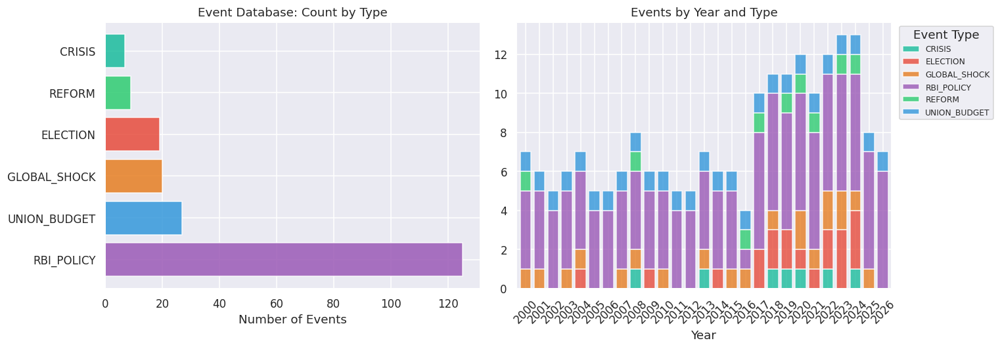

In [47]:
# ── 7a. Event type frequency ──────────────────────────────────────────────────
if not events.empty and 'event_type' in events.columns:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Bar chart by event type
    type_counts = events['event_type'].value_counts()
    type_colors = {'ELECTION': '#e74c3c', 'UNION_BUDGET': '#3498db', 'RBI_POLICY': '#9b59b6',
                   'REFORM': '#2ecc71', 'GLOBAL_SHOCK': '#e67e22', 'CRISIS': '#1abc9c'}
    bar_colors = [type_colors.get(t, '#95a5a6') for t in type_counts.index]
    axes[0].barh(type_counts.index, type_counts.values, color=bar_colors, alpha=0.85)
    axes[0].set_title('Event Database: Count by Type')
    axes[0].set_xlabel('Number of Events')

    # Events over time
    if 'period' in events.columns:
        events['year'] = pd.to_numeric(events['period'].astype(str).str[:4], errors='coerce').dropna().astype(int)
        yr_type = events.groupby(['year', 'event_type']).size().unstack(fill_value=0)
        yr_type.plot(kind='bar', ax=axes[1], stacked=True,
                     color=[type_colors.get(c, '#95a5a6') for c in yr_type.columns],
                     alpha=0.8, width=0.8)
        axes[1].set_title('Events by Year and Type')
        axes[1].set_xlabel('Year')
        axes[1].tick_params(axis='x', rotation=45)
        axes[1].legend(title='Event Type', fontsize=8, bbox_to_anchor=(1.01, 1))

    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot17a_event_type_frequency.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot17b_event_density_heatmap.png


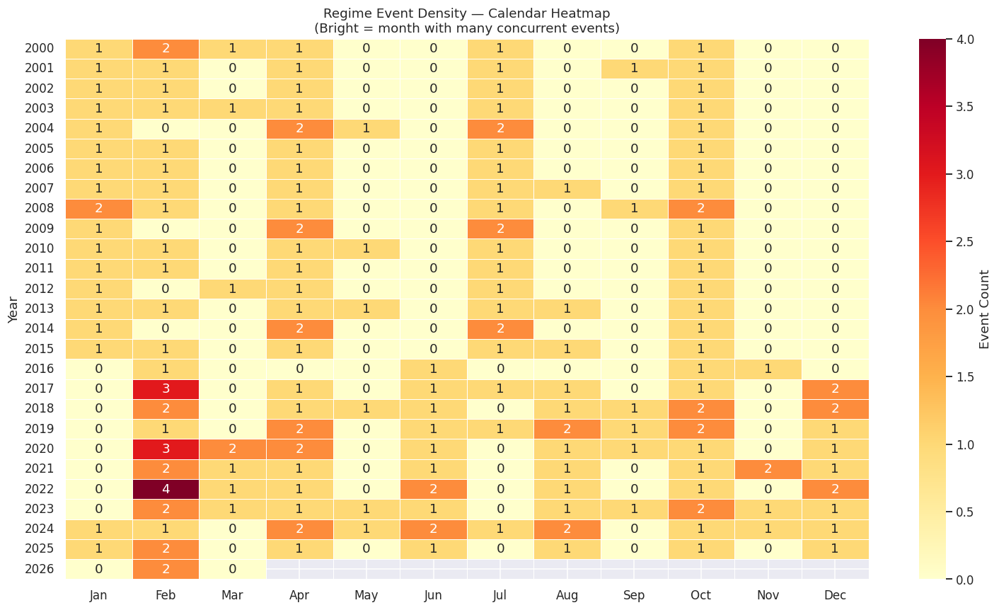


📊 Event density stats:
   Months with ≥3 events: 3
   Months with 2 events: 29
   Months with 0 events: 150


In [48]:
# ── 7b. Monthly event density heatmap (calendar view) ────────────────────────
if 'event_count' in df.columns:
    df['year']  = df['period_dt'].dt.year
    df['month'] = df['period_dt'].dt.month

    pivot = df.pivot_table(index='year', columns='month', values='event_count', aggfunc='sum')
    pivot.columns = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

    fig, ax = plt.subplots(figsize=(14, 8))
    sns.heatmap(pivot, ax=ax, cmap='YlOrRd', annot=True, fmt='.0f',
                linewidths=0.5, cbar_kws={'label': 'Event Count'})
    ax.set_title('Regime Event Density — Calendar Heatmap\n(Bright = month with many concurrent events)', fontsize=12)
    ax.set_ylabel('Year')
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot17b_event_density_heatmap.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

    print(f'\n📊 Event density stats:')
    print(f'   Months with ≥3 events: {(df["event_count"] >= 3).sum()}')
    print(f'   Months with 2 events: {(df["event_count"] == 2).sum()}')
    print(f'   Months with 0 events: {(df["event_count"] == 0).sum()}')

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot17c_event_overlay_gpr_cpi.png


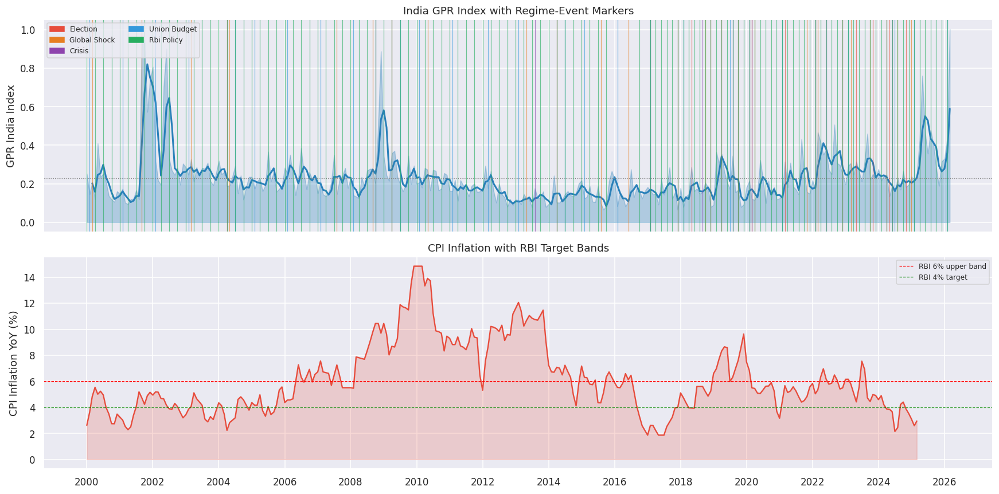

In [49]:
# ── 7c. Event-type overlay on GPR & FRED inflation ───────────────────────────
# Shows how different event types (ELECTION, GLOBAL_SHOCK, CRISIS) coincide
# with GPR spikes and inflation surges.

gpr_col  = 'gpr_india' if 'gpr_india' in df.columns else None
inf_col  = 'inf_cpi_yoy' if 'inf_cpi_yoy' in df.columns else None
ev_types = [c for c in ['event_election', 'event_global_shock', 'event_crisis',
                         'event_union_budget', 'event_rbi_policy'] if c in df.columns]

if gpr_col and ev_types:
    fig, axes = plt.subplots(2 if inf_col else 1, 1,
                              figsize=(16, 8 if inf_col else 5), sharex=True)
    if not isinstance(axes, np.ndarray):
        axes = [axes]

    # GPR panel with event vlines
    event_colors_map = {
        'event_election'    : '#e74c3c',
        'event_global_shock': '#e67e22',
        'event_crisis'      : '#8e44ad',
        'event_union_budget': '#3498db',
        'event_rbi_policy'  : '#27ae60',
    }
    axes[0].fill_between(df['period_dt'], df[gpr_col].fillna(0), alpha=0.3, color='#2980b9')
    axes[0].plot(df['period_dt'], df[gpr_col].rolling(3).mean(), color='#2980b9', lw=2)
    axes[0].axhline(df[gpr_col].mean(), color='grey', lw=0.8, linestyle=':')
    axes[0].set_ylabel('GPR India Index')
    axes[0].set_title('India GPR Index with Regime-Event Markers')

    handles = []
    for ev_col in ev_types:
        color = event_colors_map.get(ev_col, '#95a5a6')
        ev_months = df.loc[df[ev_col] == 1, 'period_dt']
        for dt in ev_months:
            axes[0].axvline(dt, color=color, lw=0.8, alpha=0.65)
        label = ev_col.replace('event_', '').replace('_', ' ').title()
        handles.append(mpatches.Patch(color=color, label=label))
    axes[0].legend(handles=handles, fontsize=8, ncol=2, loc='upper left')

    # CPI panel
    if inf_col and len(axes) > 1:
        axes[1].plot(df['period_dt'], df[inf_col], color='#e74c3c', lw=1.5)
        axes[1].fill_between(df['period_dt'], df[inf_col], alpha=0.2, color='#e74c3c')
        axes[1].axhline(6, color='red', lw=0.8, linestyle='--', label='RBI 6% upper band')
        axes[1].axhline(4, color='green', lw=0.8, linestyle='--', label='RBI 4% target')
        axes[1].set_ylabel('CPI Inflation YoY (%)')
        axes[1].set_title('CPI Inflation with RBI Target Bands')
        axes[1].legend(fontsize=8)

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot17c_event_overlay_gpr_cpi.png')
    plt.show()


### 7d. Reform Events — GPR & Sentiment Impact
**Research note**: `event_reform` captures structural reform months (GST, demonetisation, corporate tax cut, farm laws, bond index inclusion). Unlike global shocks, reform events may initially *suppress* GPR while *improving* long-run sentiment — testing this asymmetry here.


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot17d_reform_events_gpr_sentiment.png


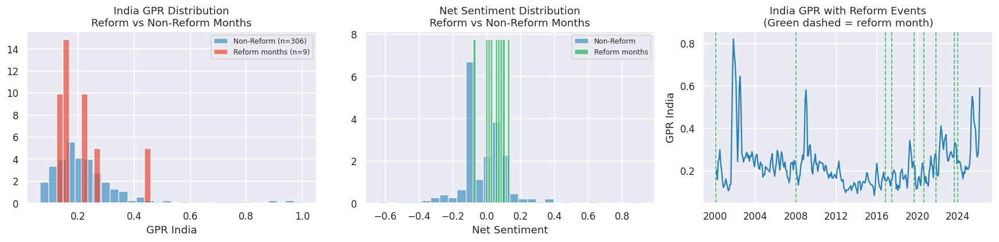


📊 Reform Months GPR Analysis:
   Reform months GPR mean    : 0.21
   Non-reform months GPR mean: 0.23
   Mann-Whitney p-value      : 0.6332
   ⚠️  No significant difference (reform months have lower GPR — policy certainty reduces geopolitical risk)

   Known reform months in dataset:
 period
2000-02
2008-01
2016-11
2017-07
2019-09
2020-09
2021-11
2023-09
2024-01


In [50]:
# ── 7d. Reform Events Impact on GPR & Sentiment ──────────────────────────────
if 'event_reform' in df.columns and 'gpr_india' in df.columns:
    reform_months = df[df['event_reform'] == 1]
    non_reform    = df[df['event_reform'] == 0]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    # GPR distribution: reform vs non-reform
    axes[0].hist(non_reform['gpr_india'].dropna(), bins=30, alpha=0.6, color='#2980b9',
                 label=f'Non-Reform (n={len(non_reform)})', density=True)
    axes[0].hist(reform_months['gpr_india'].dropna(), bins=15, alpha=0.7, color='#e74c3c',
                 label=f'Reform months (n={len(reform_months)})', density=True)
    axes[0].set_title('India GPR Distribution\nReform vs Non-Reform Months')
    axes[0].set_xlabel('GPR India')
    axes[0].legend(fontsize=8)

    # Sentiment distribution: reform vs non-reform
    if 'net_sentiment_mean' in df.columns:
        axes[1].hist(non_reform['net_sentiment_mean'].dropna(), bins=30, alpha=0.6, color='#2980b9',
                     label='Non-Reform', density=True)
        axes[1].hist(reform_months['net_sentiment_mean'].dropna(), bins=15, alpha=0.7, color='#27ae60',
                     label='Reform months', density=True)
        axes[1].set_title('Net Sentiment Distribution\nReform vs Non-Reform Months')
        axes[1].set_xlabel('Net Sentiment')
        axes[1].legend(fontsize=8)

    # Timeline: reform events on GPR
    axes[2].plot(df['period_dt'], df['gpr_india'].rolling(3).mean(), color='#2980b9', lw=1.5)
    reform_dts = df.loc[df['event_reform'] == 1, 'period_dt']
    for dt in reform_dts:
        axes[2].axvline(dt, color='#27ae60', lw=1.2, linestyle='--', alpha=0.8)
    axes[2].set_title('India GPR with Reform Events\n(Green dashed = reform month)')
    axes[2].set_ylabel('GPR India')
    axes[2].xaxis.set_major_locator(mdates.YearLocator(4))
    axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()
    _save('Plot17d_reform_events_gpr_sentiment.png')
    plt.show()

    # Mann-Whitney test
    g1 = reform_months['gpr_india'].dropna()
    g0 = non_reform['gpr_india'].dropna()
    if len(g1) >= 3 and len(g0) >= 3:
        stat, pval = mannwhitneyu(g1, g0, alternative='two-sided')
        print(f'\n📊 Reform Months GPR Analysis:')
        print(f'   Reform months GPR mean    : {g1.mean():.2f}')
        print(f'   Non-reform months GPR mean: {g0.mean():.2f}')
        print(f'   Mann-Whitney p-value      : {pval:.4f}')
        interpretation = '✅ Significant difference' if pval < 0.05 else '⚠️  No significant difference'
        direction = '(reform months have lower GPR — policy certainty reduces geopolitical risk)' \
                    if g1.mean() < g0.mean() else '(reform months have higher GPR — structural change raises uncertainty)'
        print(f'   {interpretation} {direction}')

    print(f'\n   Known reform months in dataset:')
    print(reform_months[['period']].to_string(index=False))
else:
    print('⚠️  event_reform or gpr_india column not found.')


### 7e. High-Event Month Flag — Distribution & Feature Impact
**Research note**: `high_event_month` (1 if ≥2 concurrent events) is a binary stress indicator. This validates that multi-event months genuinely coincide with elevated GPR and negative sentiment — confirming it adds signal beyond `event_count`.


📊 High-Event Months (≥2 concurrent events): 32 of 315 (10.2%)

   Feature          | High-Event μ | Normal μ  | Mann-Whitney p | Signal?
   ----------------------------------------------------------------------
   gpr_india         :      0.209  |    0.231  | 0.6769         |   NO
   net_sentiment_mean:      0.029  |   -0.013  | 0.0100         | ✅ YES
   negative_mean     :      0.116  |    0.176  | 0.0584         |   NO
   gpr_composite_score:      0.610  |   -0.030  | 0.0000         | ✅ YES
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot17e_high_event_month.png


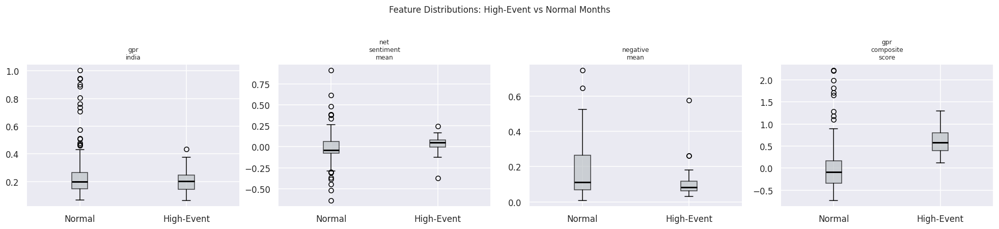

In [51]:
# ── 7e. high_event_month flag analysis ───────────────────────────────────────
if 'high_event_month' in df.columns:
    n_high = int(df['high_event_month'].sum())
    n_total = len(df)
    print(f'📊 High-Event Months (≥2 concurrent events): {n_high} of {n_total} ({n_high/n_total*100:.1f}%)')

    compare_cols = [c for c in ['gpr_india', 'net_sentiment_mean', 'negative_mean', 'gpr_composite_score']
                    if c in df.columns]

    if compare_cols:
        n_cols = len(compare_cols)
        fig, axes = plt.subplots(1, n_cols, figsize=(4.5 * n_cols, 4))
        if n_cols == 1: axes = [axes]

        print('\n   Feature          | High-Event μ | Normal μ  | Mann-Whitney p | Signal?')
        print('   ' + '-' * 70)

        for ax, col in zip(axes, compare_cols):
            grp1 = df.loc[df['high_event_month'] == 1, col].dropna()
            grp0 = df.loc[df['high_event_month'] == 0, col].dropna()

            ax.boxplot([grp0, grp1], labels=['Normal', 'High-Event'],
                       patch_artist=True,
                       boxprops=dict(facecolor='#bdc3c7', alpha=0.7),
                       medianprops=dict(color='black', lw=2))
            ax.set_title(col.replace('_', '\n'), fontsize=8)

            if len(grp1) >= 3 and len(grp0) >= 3:
                stat, pval = mannwhitneyu(grp1, grp0, alternative='two-sided')
                sig = '✅ YES' if pval < 0.05 else '  NO'
                print(f'   {col:<18}: {grp1.mean():>10.3f}  | {grp0.mean():>8.3f}  | {pval:.4f}         | {sig}')

        plt.suptitle('Feature Distributions: High-Event vs Normal Months', fontsize=11, y=1.02)
        plt.tight_layout()
        _save('Plot17e_high_event_month.png')
        plt.show()
else:
    print('⚠️  high_event_month column not found.')


### 7f. Election-Period GPR Spike Analysis
**Research note**: Phase01B fetches both Lok Sabha AND state elections. This cell tests whether market-sensitive state elections (UP, Maharashtra etc.) produce measurable GPR/sentiment shifts — validating the expanded election event database.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot17f_election_gpr_boxplot.png


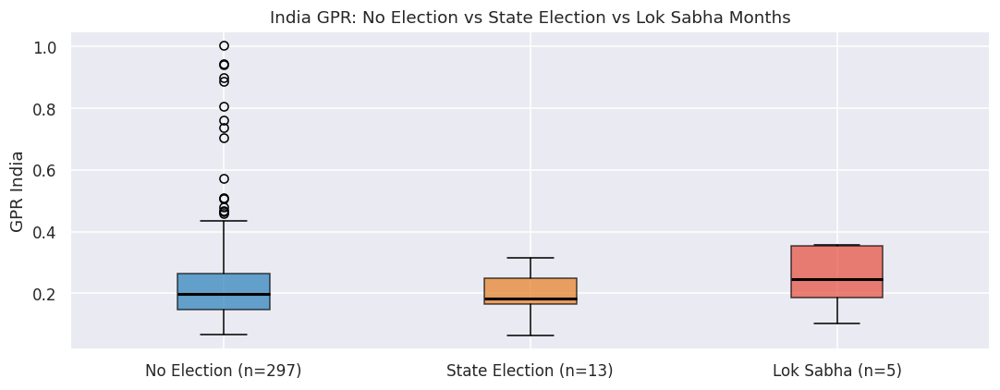

📊 GPR Means by Election Type:
   No Election (n=297)                     : mean=0.23  std=0.14
   State Election (n=13)                   : mean=0.20  std=0.08
   Lok Sabha (n=5)                         : mean=0.25  std=0.11
   Lok Sabha vs No Election p-value: 0.4289 → ⚠️ not significant

   Lok Sabha months : ['2004-04', '2009-04', '2014-04', '2019-04', '2024-04']...
   State elec months: ['2017-02', '2017-12', '2018-05', '2018-12', '2019-10', '2020-02']...


In [52]:
# ── 7f. Lok Sabha vs State Election GPR Impact ───────────────────────────────
if not events.empty and 'event_type' in events.columns and 'period' in events.columns:
    elec_events = events[events['event_type'] == 'ELECTION'].copy()
    if not elec_events.empty:
        # Tag Lok Sabha vs State by description
        elec_events['is_loksabha'] = elec_events['description'].str.lower().str.contains('lok sabha|general election').astype(int)
        ls_periods    = set(elec_events[elec_events['is_loksabha']==1]['period'].astype(str))
        state_periods = set(elec_events[elec_events['is_loksabha']==0]['period'].astype(str))

        gpr_col_e = 'gpr_india' if 'gpr_india' in df.columns else None
        if gpr_col_e:
            df_ls    = df[df['period'].astype(str).isin(ls_periods)]
            df_state = df[df['period'].astype(str).isin(state_periods)]
            df_none  = df[~df['period'].astype(str).isin(ls_periods | state_periods)]

            fig, ax = plt.subplots(figsize=(10, 4))
            data_list  = [df_none[gpr_col_e].dropna(), df_state[gpr_col_e].dropna(), df_ls[gpr_col_e].dropna()]
            labels_list = [f'No Election (n={len(data_list[0])})',
                           f'State Election (n={len(data_list[1])})',
                           f'Lok Sabha (n={len(data_list[2])})']
            colors_list = ['#2980b9', '#e67e22', '#e74c3c']
            ax.boxplot(data_list, labels=labels_list, patch_artist=True,
                       boxprops=dict(alpha=0.7),
                       medianprops=dict(color='black', lw=2))
            for patch, color in zip(ax.patches, colors_list):
                patch.set_facecolor(color)
            ax.set_title('India GPR: No Election vs State Election vs Lok Sabha Months')
            ax.set_ylabel('GPR India')
            plt.tight_layout()
            _save('Plot17f_election_gpr_boxplot.png')
            plt.show()

            print('📊 GPR Means by Election Type:')
            for label_e, grp in zip(labels_list, data_list):
                print(f'   {label_e:40s}: mean={grp.mean():.2f}  std={grp.std():.2f}')

            # Mann-Whitney: Lok Sabha vs No Election
            if len(data_list[2]) >= 3 and len(data_list[0]) >= 3:
                stat, pval = mannwhitneyu(data_list[2], data_list[0], alternative='two-sided')
                print(f'   Lok Sabha vs No Election p-value: {pval:.4f} → {"✅ significant" if pval<0.05 else "⚠️ not significant"}')
        else:
            print('⚠️  gpr_india not available for election analysis.')

        print(f'\n   Lok Sabha months : {sorted(ls_periods)[:6]}...')
        print(f'   State elec months: {sorted(state_periods)[:6]}...')
else:
    print('⚠️  events file not loaded.')

---
## 8. FRED Macroeconomic Feature Analysis
**Research note**: FRED features provide the economic backbone. Key checks: yield curve inversion periods (should align with pre-recession periods), inflation spikes (2022 post-COVID), and M3 growth cycles.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot18a_fred_feature_coverage.png


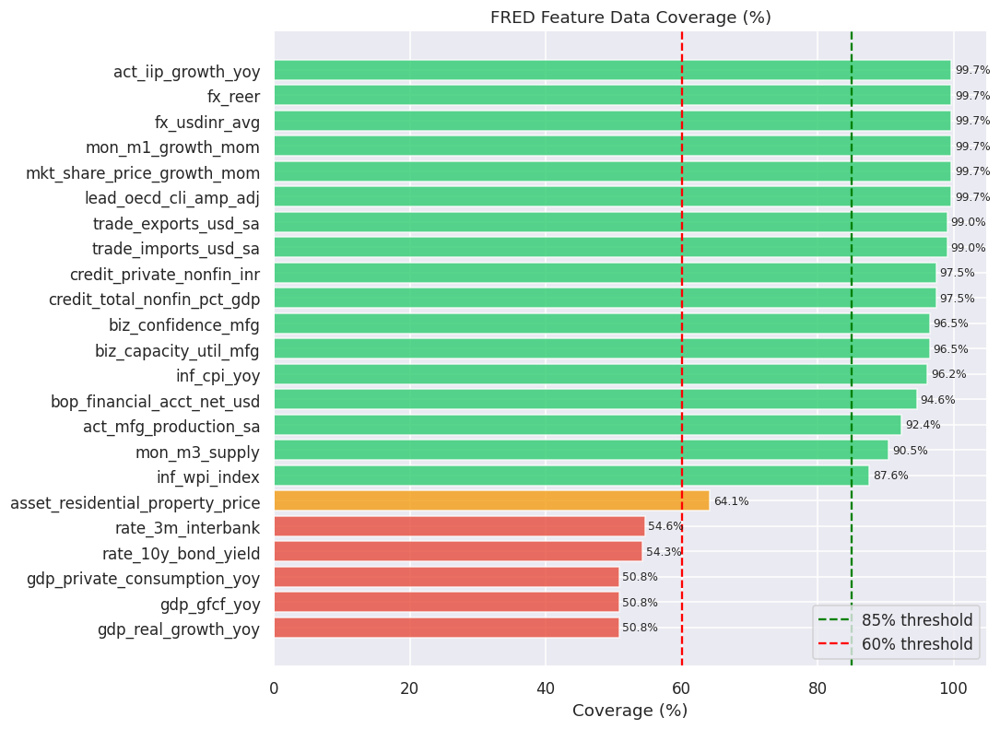

In [53]:
# ── 8a. FRED feature coverage ────────────────────────────────────────────────
fred_feature_cols = [c for c in fred_cols if c in df.columns]

if fred_feature_cols:
    coverage = df[fred_feature_cols].notna().mean().sort_values() * 100

    fig, ax = plt.subplots(figsize=(10, max(5, len(coverage) * 0.32)))
    colors = ['#e74c3c' if p < 60 else '#f39c12' if p < 85 else '#2ecc71' for p in coverage.values]
    ax.barh(coverage.index, coverage.values, color=colors, alpha=0.8)
    ax.axvline(85, color='green', lw=1.5, linestyle='--', label='85% threshold')
    ax.axvline(60, color='red', lw=1.5, linestyle='--', label='60% threshold')
    ax.set_xlabel('Coverage (%)')
    ax.set_title('FRED Feature Data Coverage (%)')
    ax.legend()
    ax.set_xlim(0, 105)
    for bar, val in zip(ax.patches, coverage.values):
        ax.text(val + 0.5, bar.get_y() + bar.get_height()/2, f'{val:.1f}%', va='center', fontsize=8)
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot18a_fred_feature_coverage.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot18b_key_fred_indicators.png


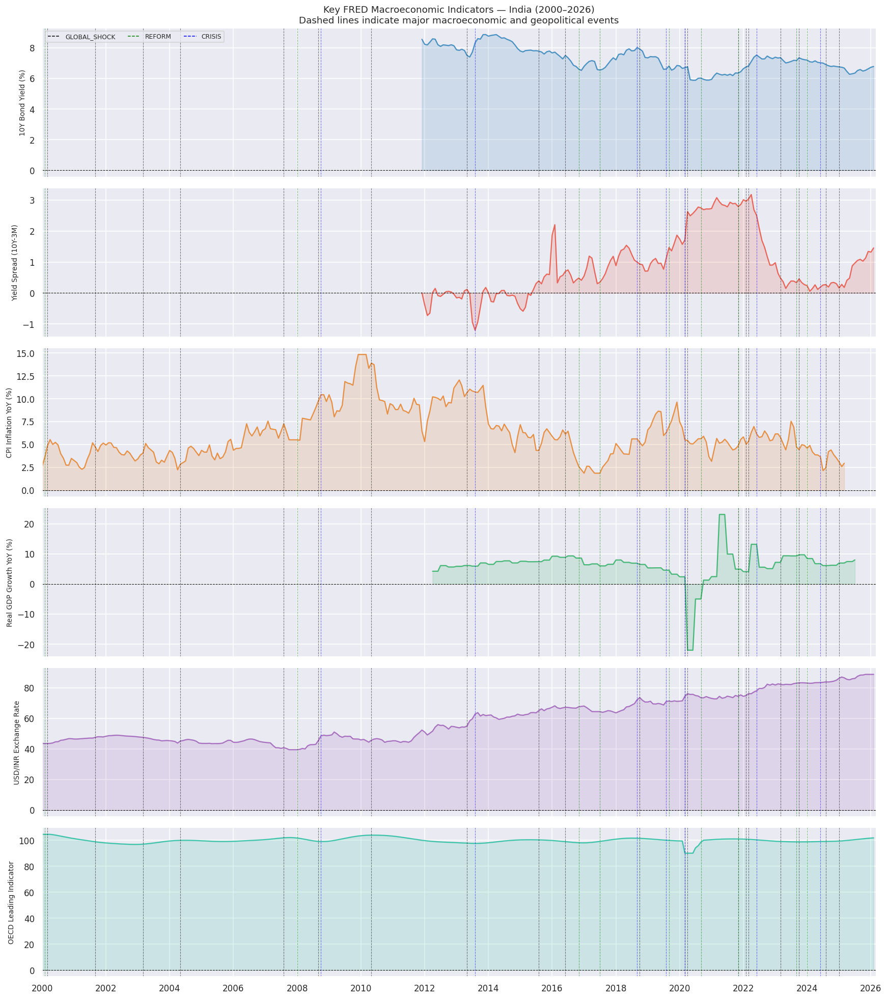

In [54]:

# ── 8b. Key FRED indicators panel (2000 onwards) ───────────────────────────
key_fred = [
    ('rate_10y_bond_yield',  '10Y Bond Yield (%)',        '#2980b9'),
    ('rate_yield_spread',    'Yield Spread (10Y-3M)',     '#e74c3c'),
    ('inf_cpi_yoy',          'CPI Inflation YoY (%)',     '#e67e22'),
    ('gdp_real_growth_yoy',  'Real GDP Growth YoY (%)',   '#27ae60'),
    ('fx_usdinr_avg',        'USD/INR Exchange Rate',     '#9b59b6'),
    ('lead_oecd_cli_amp_adj','OECD Leading Indicator',    '#1abc9c'),
]

available_key = [
    (col, label, color)
    for col, label, color in key_fred
    if col in df.columns
]

if available_key:

    # Filter from 2000 onwards
    plot_df = df[df['period_dt'] >= pd.Timestamp('2000-01-01')].copy()

    n = len(available_key)

    fig, axes = plt.subplots(
        n, 1,
        figsize=(16, 3 * n),
        sharex=True
    )

    if n == 1:
        axes = [axes]

    # ── Event legend handles ─────────────────────────────────────────
    event_handles = [
        Line2D([0], [0],
               color=c,
               linestyle='--',
               lw=1,
               label=l)
        for _, c, l in event_groups
    ]

    for ax, (col, label, color) in zip(axes, available_key):

        # Main series
        ax.plot(
            plot_df['period_dt'],
            plot_df[col],
            color=color,
            lw=1.5,
            alpha=0.8
        )

        ax.fill_between(
            plot_df['period_dt'],
            plot_df[col],
            alpha=0.15,
            color=color
        )

        ax.axhline(
            0,
            color='black',
            lw=0.7,
            linestyle='--'
        )

        # Event annotations
        for annot_event, annot_color, _ in event_groups:

            for evt_dt, _ in annot_event:

                evt_ts = pd.Timestamp(evt_dt)

                if evt_ts >= pd.Timestamp('2000-01-01'):

                    ax.axvline(
                        evt_ts,
                        color=annot_color,
                        linestyle='--',
                        lw=0.7,
                        alpha=0.5
                    )

        ax.set_ylabel(label, fontsize=9)

        # Legend only on first panel
        if ax == axes[0]:

            ax.legend(
                handles=event_handles,
                fontsize=8,
                loc='upper left',
                ncol=3
            )

    axes[0].set_title(
        'Key FRED Macroeconomic Indicators — India (2000–2026)\n'
        'Dashed lines indicate major macroeconomic and geopolitical events',
        fontsize=12
    )

    # Restrict x-axis
    axes[-1].set_xlim(
        pd.Timestamp('2000-01-01'),
        plot_df['period_dt'].max()
    )

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()

    _fig_name = 'Plot18b_key_fred_indicators.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)

    plt.savefig(
        _fig_path,
        dpi=150,
        bbox_inches='tight',
        facecolor='white'
    )

    print(f'📁 Saved → {_fig_path}')

    plt.show()

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot18c_fred_distributions.png


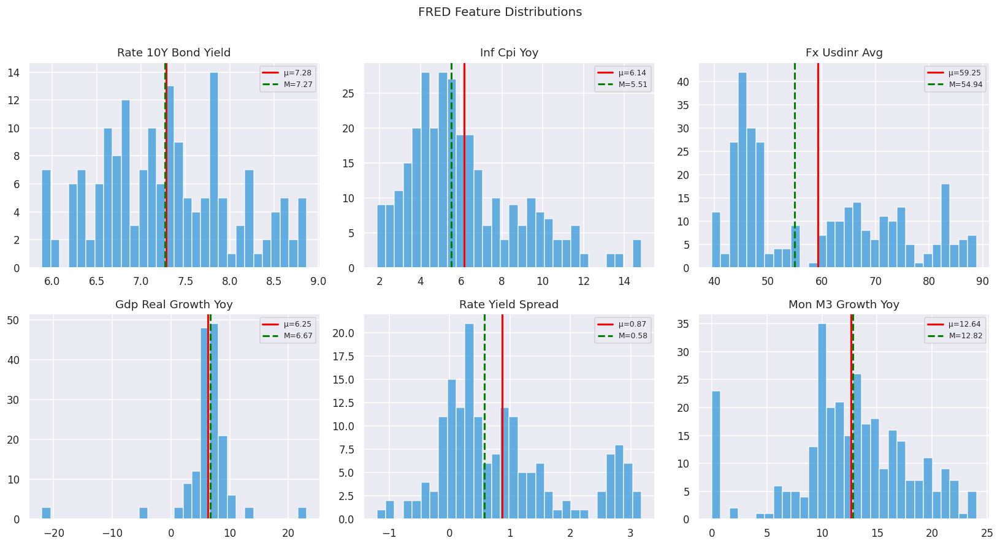

In [55]:
# ── 8c. Distribution plots for FRED features ─────────────────────────────────
plot_fred_cols = [c for c in ['rate_10y_bond_yield', 'inf_cpi_yoy', 'fx_usdinr_avg',
                               'gdp_real_growth_yoy', 'rate_yield_spread', 'mon_m3_growth_yoy']
                  if c in df.columns]

if plot_fred_cols:
    n_cols = 3
    n_rows = -(-len(plot_fred_cols) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
    axes = axes.flatten()

    for ax, col in zip(axes, plot_fred_cols):
        data = df[col].dropna()
        ax.hist(data, bins=30, color='#3498db', alpha=0.75, edgecolor='white')
        ax.axvline(data.mean(), color='red', lw=2, label=f'μ={data.mean():.2f}')
        ax.axvline(data.median(), color='green', lw=2, linestyle='--', label=f'M={data.median():.2f}')
        ax.set_title(col.replace('_', ' ').title())
        ax.legend(fontsize=8)

    # Hide unused subplots
    for ax in axes[len(plot_fred_cols):]:
        ax.set_visible(False)

    plt.suptitle('FRED Feature Distributions', fontsize=13, y=1.01)
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot18c_fred_distributions.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

### 8d. Remaining FRED Features — Trade, Business Confidence & Property Prices
**Research note**: Phase 01B pulls 23 FRED series. Section 8b covers 6 key indicators. This section covers the remaining ones: trade flows, business confidence, capacity utilisation, IIP, M1/M3 money supply, REER, WPI, GFCF, and residential property prices.


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot18d_fred_remaining_panel1.png


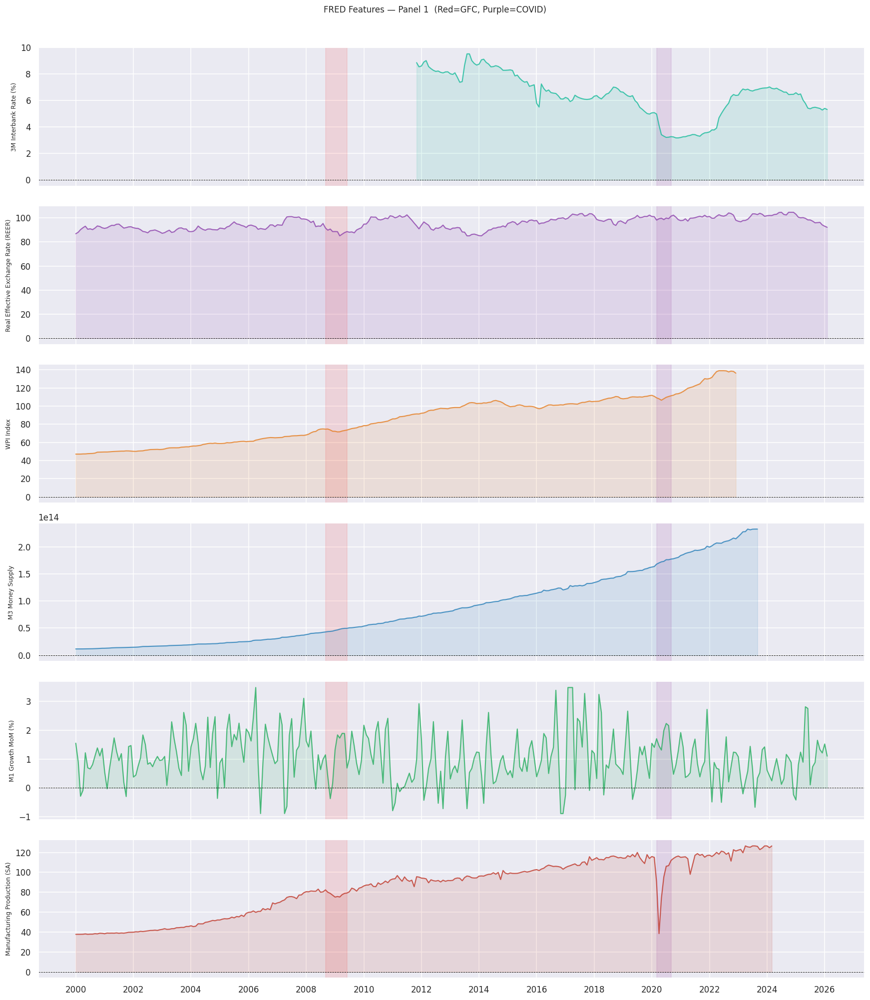

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot18d_fred_remaining_panel2.png


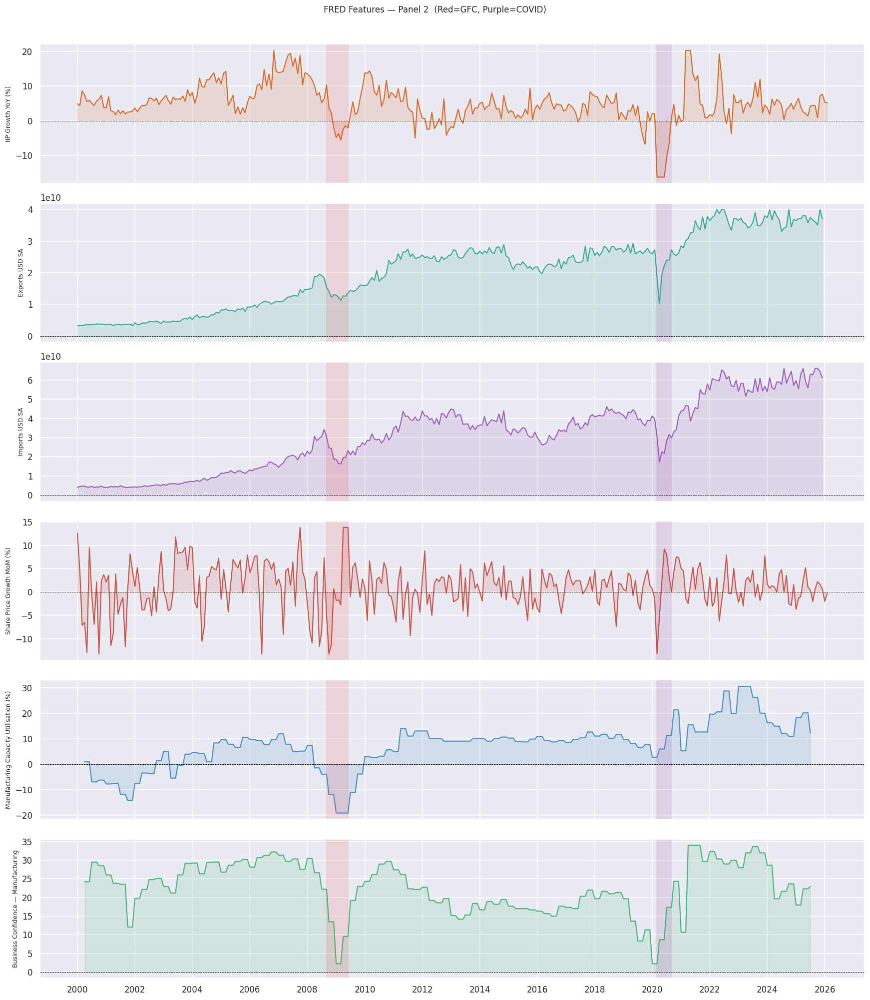

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot18d_fred_remaining_panel3.png


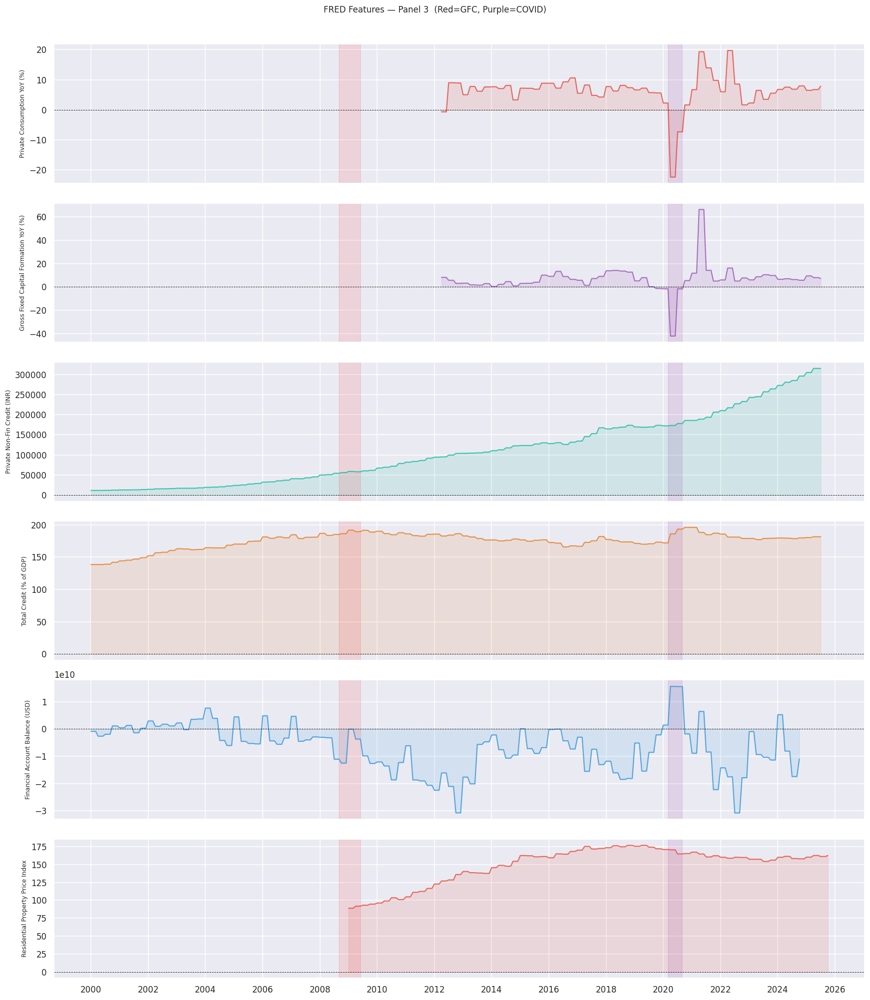


📊 Remaining FRED Features Summary:
   3M Interbank Rate (%)                         coverage= 54.6%  mean=6.421
   Real Effective Exchange Rate (REER)           coverage= 99.7%  mean=95.592
   WPI Index                                     coverage= 87.6%  mean=85.157
   M3 Money Supply                               coverage= 90.5%  mean=85975767195789.469
   M1 Growth MoM (%)                             coverage= 99.7%  mean=1.059
   Manufacturing Production (SA)                 coverage= 92.4%  mean=85.000
   IIP Growth YoY (%)                            coverage= 99.7%  mean=5.065
   Exports USD SA                                coverage= 99.0%  mean=20482886890.897
   Imports USD SA                                coverage= 99.0%  mean=31053822530.385
   Share Price Growth MoM (%)                    coverage= 99.7%  mean=1.067
   Manufacturing Capacity Utilisation (%)        coverage= 96.5%  mean=7.279
   Business Confidence — Manufacturing           coverage= 96.5%  mean=22.667
   

In [56]:
# ── 8d. Remaining FRED Features panel ────────────────────────────────────────
# Columns covered in 8b are excluded here
covered_in_8b = {'rate_10y_bond_yield', 'rate_yield_spread', 'inf_cpi_yoy',
                  'gdp_real_growth_yoy', 'fx_usdinr_avg', 'lead_oecd_cli_amp_adj'}

all_fred_raw = [
    # FRED monthly series from Phase01B config
    ('rate_3m_interbank',         '3M Interbank Rate (%)',               '#1abc9c'),
    ('fx_reer',                    'Real Effective Exchange Rate (REER)',  '#8e44ad'),
    ('inf_wpi_index',              'WPI Index',                            '#e67e22'),
    ('mon_m3_supply',              'M3 Money Supply',                      '#2980b9'),
    ('mon_m1_growth_mom',          'M1 Growth MoM (%)',                    '#27ae60'),
    ('act_mfg_production_sa',      'Manufacturing Production (SA)',         '#c0392b'),
    ('act_iip_growth_yoy',         'IIP Growth YoY (%)',                   '#d35400'),
    ('trade_exports_usd_sa',       'Exports USD SA',                       '#16a085'),
    ('trade_imports_usd_sa',       'Imports USD SA',                       '#8e44ad'),
    ('mkt_share_price_growth_mom', 'Share Price Growth MoM (%)',           '#c0392b'),
    ('biz_capacity_util_mfg',      'Manufacturing Capacity Utilisation (%)', '#2980b9'),
    ('biz_confidence_mfg',         'Business Confidence — Manufacturing',   '#27ae60'),
    ('gdp_private_consumption_yoy','Private Consumption YoY (%)',           '#e74c3c'),
    ('gdp_gfcf_yoy',               'Gross Fixed Capital Formation YoY (%)', '#9b59b6'),
    ('credit_private_nonfin_inr',  'Private Non-Fin Credit (INR)',          '#1abc9c'),
    ('credit_total_nonfin_pct_gdp','Total Credit (% of GDP)',               '#e67e22'),
    ('bop_financial_acct_net_usd', 'Financial Account Balance (USD)',        '#3498db'),
    ('asset_residential_property_price', 'Residential Property Price Index', '#e74c3c'),
]

remaining_fred = [(col, lbl, color) for col, lbl, color in all_fred_raw
                   if col in df.columns and col not in covered_in_8b]

if remaining_fred:
    # Split into groups of 6 for readability
    group_size = 6
    for g_idx in range(0, len(remaining_fred), group_size):
        group = remaining_fred[g_idx:g_idx + group_size]
        n = len(group)
        fig, axes = plt.subplots(n, 1, figsize=(16, 3 * n), sharex=True)
        if n == 1: axes = [axes]

        for ax, (col, lbl, color) in zip(axes, group):
            ax.plot(df['period_dt'], df[col], color=color, lw=1.4, alpha=0.8)
            ax.fill_between(df['period_dt'], df[col], alpha=0.12, color=color)
            ax.axhline(0, color='black', lw=0.6, linestyle='--')
            ax.set_ylabel(lbl, fontsize=8)
            # Shade GFC and COVID
            ax.axvspan(pd.Timestamp('2008-09-01'), pd.Timestamp('2009-06-01'), alpha=0.1, color='red')
            ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2020-09-01'), alpha=0.1, color='purple')

        axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
        axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        plt.suptitle(f'FRED Features — Panel {g_idx//group_size + 1}  '
                     '(Red=GFC, Purple=COVID)', fontsize=11, y=1.01)
        plt.tight_layout()
        _save(f'Plot18d_fred_remaining_panel{g_idx//group_size + 1}.png')
        plt.show()

    print(f'\n📊 Remaining FRED Features Summary:')
    for col, lbl, _ in remaining_fred:
        cov = df[col].notna().mean() * 100
        mn  = df[col].mean()
        print(f'   {lbl:45s} coverage={cov:5.1f}%  mean={mn:.3f}')
else:
    print('⚠️  No additional FRED columns to display beyond those in Section 8b.')


---
## 9. Cross-Feature Correlation Analysis
**Research note**: High correlations between GPR, sentiment, and macro features reveal information redundancy — important for feature selection in Phase 02. We expect GPR and negative sentiment to be positively correlated.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19a_correlation_heatmap.png


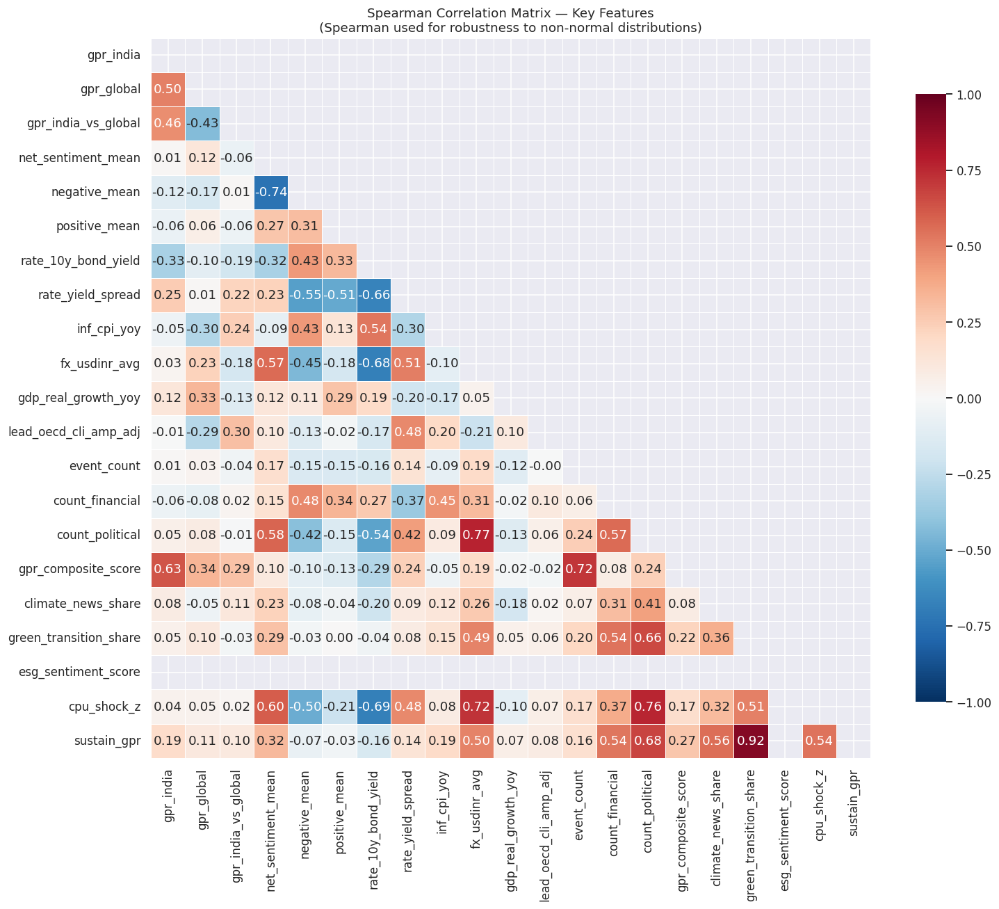

In [57]:
# ── 9a. Cross-feature correlation heatmap ────────────────────────────────────
cpu_shock_col = next((c for c in ['cpu_shock_z', 'cpu_shock'] if c in df.columns), None)

analysis_cols = [
    c for c in [
        'gpr_india', 'gpr_global', 'gpr_india_vs_global',
        'net_sentiment_mean', 'negative_mean', 'positive_mean',
        'rate_10y_bond_yield', 'rate_yield_spread', 'inf_cpi_yoy',
        'fx_usdinr_avg', 'gdp_real_growth_yoy', 'lead_oecd_cli_amp_adj',
        'event_count', 'count_financial', 'count_political', 'gpr_composite_score',
        # sustainability features
        'climate_news_share', 'green_transition_share',
        'esg_sentiment_score', cpu_shock_col, 'sustain_gpr',
    ] if c is not None and c in df.columns
]

if len(analysis_cols) >= 4:
    corr_matrix = df[analysis_cols].corr(method='spearman')  # Spearman for non-normal distributions

    fig, ax = plt.subplots(figsize=(14, 12))
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    sns.heatmap(corr_matrix, ax=ax, mask=mask, cmap='RdBu_r', center=0,
                annot=True, fmt='.2f', square=True, linewidths=0.5,
                vmin=-1, vmax=1, cbar_kws={'shrink': 0.8})
    ax.set_title('Spearman Correlation Matrix — Key Features\n'
                 '(Spearman used for robustness to non-normal distributions)', fontsize=12)
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot19a_correlation_heatmap.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19b_pairwise_scatterplots.png


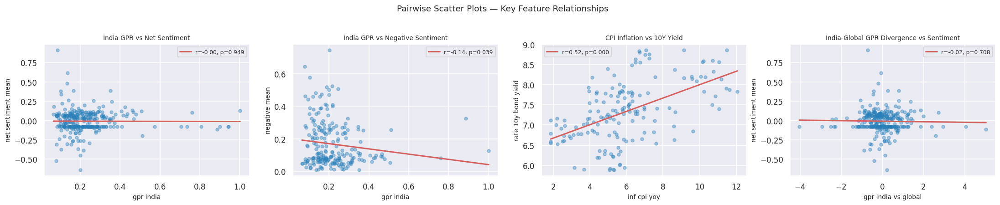

In [58]:
# ── 9b. Key pairwise scatter plots ───────────────────────────────────────────
scatter_pairs = [
    ('gpr_india', 'net_sentiment_mean', 'India GPR vs Net Sentiment'),
    ('gpr_india', 'negative_mean',      'India GPR vs Negative Sentiment'),
    ('inf_cpi_yoy', 'rate_10y_bond_yield', 'CPI Inflation vs 10Y Yield'),
    ('gpr_india_vs_global', 'net_sentiment_mean', 'India-Global GPR Divergence vs Sentiment'),
]
valid_pairs = [(x, y, t) for x, y, t in scatter_pairs if x in df.columns and y in df.columns]

if valid_pairs:
    fig, axes = plt.subplots(1, len(valid_pairs), figsize=(5 * len(valid_pairs), 4))
    if len(valid_pairs) == 1:
        axes = [axes]

    for ax, (xcol, ycol, title) in zip(axes, valid_pairs):
        mask = df[[xcol, ycol]].notna().all(axis=1)
        x, y = df.loc[mask, xcol], df.loc[mask, ycol]
        ax.scatter(x, y, alpha=0.4, s=20, color='#2980b9')
        # Add regression line
        m, b, r, p, _ = stats.linregress(x, y)
        x_line = np.linspace(x.min(), x.max(), 100)
        ax.plot(x_line, m * x_line + b, 'r-', lw=2, label=f'r={r:.2f}, p={p:.3f}')
        ax.set_xlabel(xcol.replace('_', ' '), fontsize=9)
        ax.set_ylabel(ycol.replace('_', ' '), fontsize=9)
        ax.set_title(title, fontsize=9)
        ax.legend(fontsize=8)

    plt.suptitle('Pairwise Scatter Plots — Key Feature Relationships', fontsize=12, y=1.02)
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot19b_pairwise_scatterplots.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

### 9c. Partial Correlation & VIF Analysis
**Research note**: High pairwise correlations indicate multicollinearity. Variance Inflation Factors (VIF) quantify how much a feature's variance is inflated by collinear features — features with VIF > 10 are problematic for linear models in Phase 03.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19c_vif_analysis.png


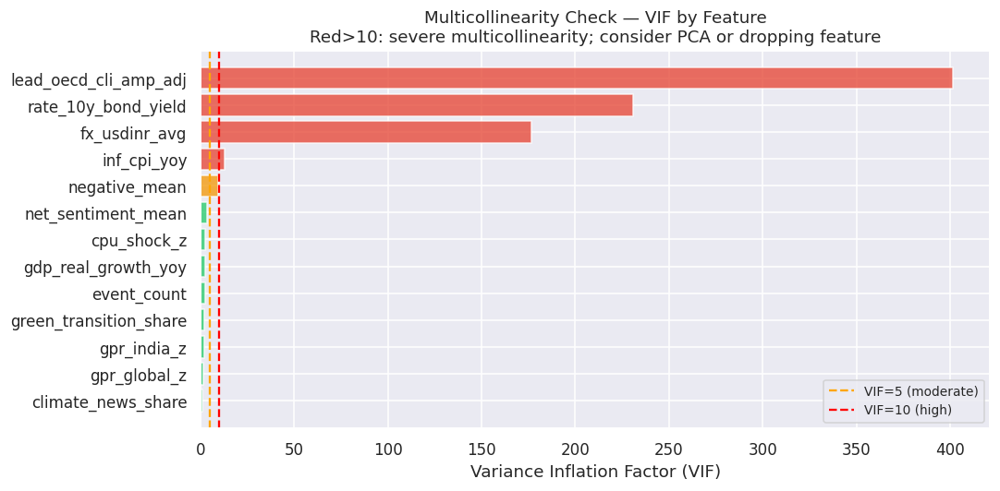

📊 VIF Results:
               Feature        VIF
 lead_oecd_cli_amp_adj 401.350749
   rate_10y_bond_yield 230.849917
         fx_usdinr_avg 176.397169
           inf_cpi_yoy  13.117774
         negative_mean   9.578819
    net_sentiment_mean   3.335630
           cpu_shock_z   2.762884
   gdp_real_growth_yoy   2.745196
           event_count   2.284949
green_transition_share   2.107466
           gpr_india_z   1.923801
          gpr_global_z   1.600620
    climate_news_share   1.215798

⚠️  High-VIF features (>10) — consider PCA or dropping in Phase 03:
              Feature        VIF
lead_oecd_cli_amp_adj 401.350749
  rate_10y_bond_yield 230.849917
        fx_usdinr_avg 176.397169
          inf_cpi_yoy  13.117774


In [59]:
# ── 9c. VIF Analysis for Key Features ────────────────────────────────────────
try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor

    vif_cols = [c for c in [
        'gpr_india_z', 'gpr_global_z', 'net_sentiment_mean', 'negative_mean',
        'event_count', 'inf_cpi_yoy', 'rate_10y_bond_yield', 'fx_usdinr_avg',
        'gdp_real_growth_yoy', 'lead_oecd_cli_amp_adj',
        'climate_news_share', 'green_transition_share', 'cpu_shock_z',
    ] if c in df.columns]

    vif_data = df[vif_cols].dropna()

    if len(vif_data) > len(vif_cols) + 10:
        vif_df = pd.DataFrame({
            'Feature': vif_cols,
            'VIF': [variance_inflation_factor(vif_data.values, i) for i in range(len(vif_cols))]
        }).sort_values('VIF', ascending=False).reset_index(drop=True)

        fig, ax = plt.subplots(figsize=(10, 5))
        colors_vif = ['#e74c3c' if v > 10 else '#f39c12' if v > 5 else '#2ecc71' for v in vif_df['VIF']]
        ax.barh(vif_df['Feature'][::-1], vif_df['VIF'][::-1], color=colors_vif[::-1], alpha=0.8)
        ax.axvline(5,  color='orange', lw=1.5, linestyle='--', label='VIF=5 (moderate)')
        ax.axvline(10, color='red',    lw=1.5, linestyle='--', label='VIF=10 (high)')
        ax.set_xlabel('Variance Inflation Factor (VIF)')
        ax.set_title('Multicollinearity Check — VIF by Feature\nRed>10: severe multicollinearity; consider PCA or dropping feature')
        ax.legend(fontsize=9)
        plt.tight_layout()
        _save('Plot19c_vif_analysis.png')
        plt.show()

        print('📊 VIF Results:')
        print(vif_df.to_string(index=False))
        high_vif = vif_df[vif_df['VIF'] > 10]
        if not high_vif.empty:
            print(f'\n⚠️  High-VIF features (>10) — consider PCA or dropping in Phase 03:')
            print(high_vif.to_string(index=False))
    else:
        print('⚠️  Insufficient non-null rows for VIF computation.')
except ImportError:
    print('⚠️  statsmodels not available for VIF.')

---
## 10. Composite GPR Stress Score Analysis
**Research note**: The composite score (0.4×GPR + 0.3×Neg_Sent + 0.3×Events) is the primary output of Phase 01B. Validating it against known stress events is essential before Phase 02 use.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot20a_composite_stress_score.png


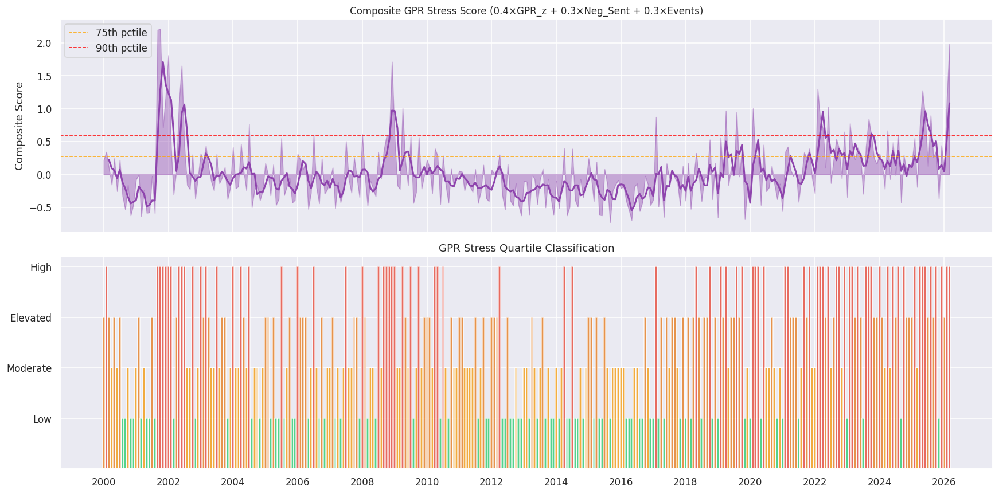

In [60]:
# ── 10a. Composite score time series ─────────────────────────────────────────
if 'gpr_composite_score' in df.columns:
    fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

    # Composite score
    comp = df['gpr_composite_score'].fillna(0)
    axes[0].fill_between(df['period_dt'], comp, alpha=0.4, color='#8e44ad')
    axes[0].plot(df['period_dt'], comp.rolling(3).mean(), color='#8e44ad', lw=2)
    axes[0].axhline(comp.quantile(0.75), color='orange', lw=1, linestyle='--', label='75th pctile')
    axes[0].axhline(comp.quantile(0.90), color='red', lw=1, linestyle='--', label='90th pctile')
    axes[0].set_title('Composite GPR Stress Score (0.4×GPR_z + 0.3×Neg_Sent + 0.3×Events)', fontsize=11)
    axes[0].set_ylabel('Composite Score')
    axes[0].legend()

    # Stress quartile bar chart
    if 'gpr_stress_quartile' in df.columns:
        quartile_map = {'low': 1, 'moderate': 2, 'elevated': 3, 'high': 4}
        q_numeric = df['gpr_stress_quartile'].map(quartile_map).fillna(0)
        bar_colors = [STRESS_COLORS.get(str(q), '#95a5a6') for q in df['gpr_stress_quartile']]
        axes[1].bar(df['period_dt'], q_numeric, color=bar_colors, width=25, alpha=0.8)
        axes[1].set_yticks([1, 2, 3, 4])
        axes[1].set_yticklabels(['Low', 'Moderate', 'Elevated', 'High'])
        axes[1].set_title('GPR Stress Quartile Classification')

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot20a_composite_stress_score.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot20b_stress_quartile_distribution.png


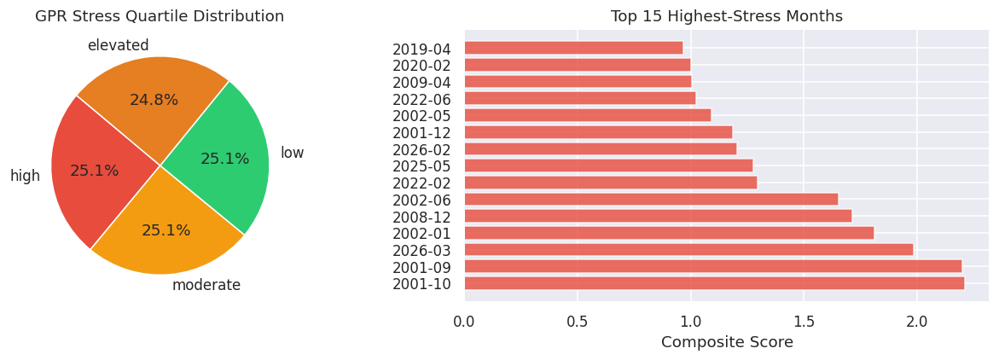


✅ Validation — Top stress months should include:
   Expected: 2008-10 (Lehman), 2020-03 (COVID), 2022-02 (Russia-Ukraine)

   Actual top-10 high-stress months:
 period  gpr_composite_score
2001-10             2.210519
2001-09             2.198900
2026-03             1.984896
2002-01             1.811756
2008-12             1.713088
2002-06             1.653466
2022-02             1.295849
2025-05             1.277292
2026-02             1.203578
2001-12             1.184570


In [61]:
# ── 10b. Stress quartile distribution and validation ─────────────────────────
if 'gpr_stress_quartile' in df.columns:
    q_counts = df['gpr_stress_quartile'].value_counts()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Pie
    pie_colors = [STRESS_COLORS.get(str(q), '#95a5a6') for q in q_counts.index]
    axes[0].pie(q_counts.values, labels=q_counts.index, autopct='%1.1f%%',
                colors=pie_colors, startangle=140)
    axes[0].set_title('GPR Stress Quartile Distribution')

    # High-stress months list
    high_stress_months = df[df['gpr_stress_quartile'] == 'high'][['period', 'gpr_composite_score']].nlargest(15, 'gpr_composite_score')
    axes[1].barh(high_stress_months['period'], high_stress_months['gpr_composite_score'],
                 color='#e74c3c', alpha=0.8)
    axes[1].set_title('Top 15 Highest-Stress Months')
    axes[1].set_xlabel('Composite Score')

    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot20b_stress_quartile_distribution.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

    print('\n✅ Validation — Top stress months should include:')
    print('   Expected: 2008-10 (Lehman), 2020-03 (COVID), 2022-02 (Russia-Ukraine)')
    print(f'\n   Actual top-10 high-stress months:')
    print(high_stress_months[['period', 'gpr_composite_score']].head(10).to_string(index=False))

---
## 11. Temporal Regime Segmentation
**Research note**: The Indian market has gone through structural regime shifts. Understanding how feature distributions differ across these periods helps validate that Phase 01B data captures meaningful regime transitions.

In [62]:
# ── 11a. Define research eras ──────────────────────────────────────────────────
# assign_era is defined in 2D-1 and already applied to df_clean.
# Section 11 uses display-friendly labels for plots — remap below.
# These labels MUST match the output of assign_era() used in Section 2D-1.
era_display_map = {
    '2000-02_Post_dotcom': '2000-02\nPost dot-com',
    '2003-07_Bull_Run'   : '2003-07\nBull Run',
    '2008-09_GFC'        : '2008-09\nGFC',
    '2010-13_Recovery'   : '2010-13\nRecovery',
    '2014-15_Modi1'      : '2014-15\nModi-1',
    '2016-19_Reform'     : '2016-19\nReform Era',
    '2020-21_COVID'      : '2020-21\nCOVID',
    '2022-23_RateHike'   : '2022-23\nRate Hike',
    '2024plus_NewCycle'  : '2024+\nNew Cycle',
}
# Only remap rows that match the raw era keys; leave already-mapped rows alone
df['era'] = df['era'].map(lambda e: era_display_map.get(e, e))

era_order = [
    '2000-02\nPost dot-com', '2003-07\nBull Run', '2008-09\nGFC',
    '2010-13\nRecovery', '2014-15\nModi-1', '2016-19\nReform Era',
    '2020-21\nCOVID', '2022-23\nRate Hike', '2024+\nNew Cycle'
]

print('Era assignment:')
print(df['era'].value_counts().reindex(era_order).to_string())


Era assignment:
era
2000-02\nPost dot-com    36
2003-07\nBull Run        60
2008-09\nGFC             24
2010-13\nRecovery        48
2014-15\nModi-1          24
2016-19\nReform Era      48
2020-21\nCOVID           24
2022-23\nRate Hike       24
2024+\nNew Cycle         27


Era assignment:
era
2000-02\nPost dot-com    36
2003-07\nBull Run        60
2008-09\nGFC             24
2010-13\nRecovery        48
2014-15\nModi-1          24
2016-19\nReform Era      48
2020-21\nCOVID           24
2022-23\nRate Hike       24
2024+\nNew Cycle         27
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot21a_research_area_distribution.png


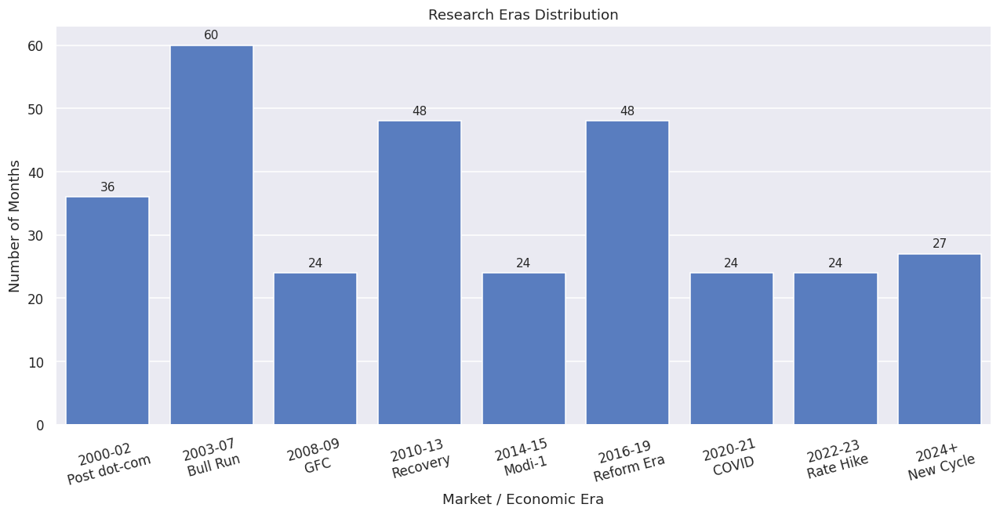

In [63]:
# ── 11a-viz. Visualize research eras bar chart ─────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

# Count months per era
era_counts = (
    df['era']
    .value_counts()
    .reindex(era_order)
)

print('Era assignment:')
print(era_counts.to_string())

# ── Plot ─────────────────────────────────────────────────────────────────────
plt.figure(figsize=(14, 6))

ax = sns.barplot(
    x=era_counts.index,
    y=era_counts.values
)

# Add labels on bars
for i, v in enumerate(era_counts.values):
    ax.text(i, v + 1, str(v), ha='center', fontsize=10)

plt.title('Research Eras Distribution')
plt.xlabel('Market / Economic Era')
plt.ylabel('Number of Months')

plt.xticks(rotation=15)
# ── Save plot to Google Drive ──────────────────────────────────────
_fig_name = 'Plot21a_research_area_distribution.png'
_fig_path = os.path.join(PLOT_DIR, _fig_name)
plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
print(f'📁 Saved → {_fig_path}')
plt.show()

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot21b_feature_means_by_era.png


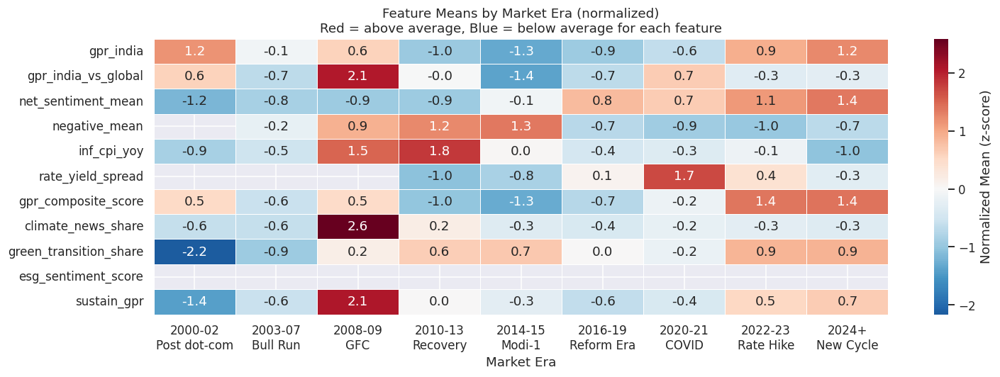

In [64]:
# ── 11b. Feature means by era ─────────────────────────────────────────────────
era_features = [c for c in [
    'gpr_india', 'gpr_india_vs_global', 'net_sentiment_mean',
    'negative_mean', 'inf_cpi_yoy', 'rate_yield_spread', 'gpr_composite_score',
    # sustainability features
    'climate_news_share', 'green_transition_share', 'esg_sentiment_score', 'sustain_gpr',
] if c in df.columns]

if era_features:
    era_stats = df.groupby('era')[era_features].mean().reindex(era_order)

    # Normalize for heatmap visualization
    era_norm = (era_stats - era_stats.mean()) / (era_stats.std() + 1e-9)

    fig, ax = plt.subplots(figsize=(14, 5))
    sns.heatmap(era_norm.T, ax=ax, cmap='RdBu_r', center=0,
                annot=True, fmt='.1f', linewidths=0.5,
                cbar_kws={'label': 'Normalized Mean (z-score)'})
    ax.set_title('Feature Means by Market Era (normalized)\n'
                 'Red = above average, Blue = below average for each feature', fontsize=12)
    ax.set_xlabel('Market Era')
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot21b_feature_means_by_era.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot21c_sentiment_by_era_boxplot.png


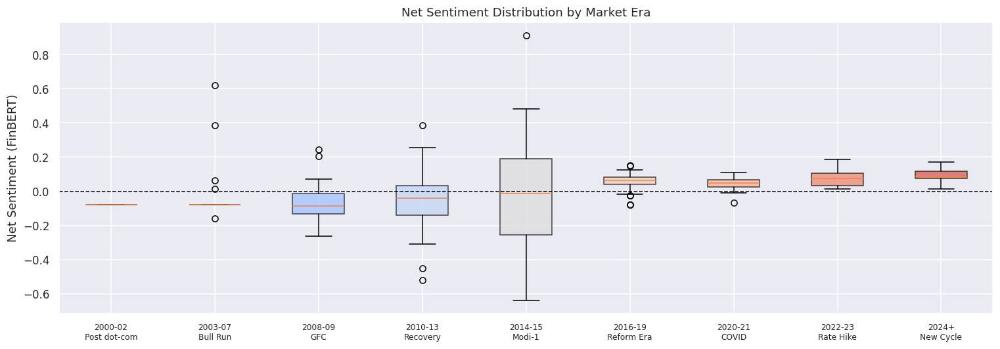


📊 Kruskal-Wallis test (sentiment across eras):
   H-statistic = 138.208, p-value = 0.000000
   ✅ Significant difference in sentiment across eras (p < 0.05)


In [65]:
# ── 11c. Boxplots of sentiment by era ────────────────────────────────────────
if 'net_sentiment_mean' in df.columns:
    fig, ax = plt.subplots(figsize=(14, 5))
    era_palette = sns.color_palette('coolwarm', len(era_order))
    df_era = df[df['era'].isin(era_order)].copy()
    df_era['era_cat'] = pd.Categorical(df_era['era'], categories=era_order, ordered=True)
    df_era = df_era.sort_values('era_cat')

    bp = ax.boxplot(
        [df_era.loc[df_era['era'] == e, 'net_sentiment_mean'].dropna().values for e in era_order],
        labels=era_order, patch_artist=True
    )
    for patch, color in zip(bp['boxes'], era_palette):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    ax.axhline(0, color='black', lw=1, linestyle='--')
    ax.set_title('Net Sentiment Distribution by Market Era', fontsize=12)
    ax.set_ylabel('Net Sentiment (FinBERT)')
    ax.tick_params(axis='x', labelsize=8)
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot21c_sentiment_by_era_boxplot.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

    # Kruskal-Wallis test (non-parametric ANOVA equivalent)
    groups = [df.loc[df['era'] == e, 'net_sentiment_mean'].dropna().values for e in era_order]
    groups = [g for g in groups if len(g) > 2]
    if len(groups) >= 2:
        stat, pval = kruskal(*groups)
        print(f'\n📊 Kruskal-Wallis test (sentiment across eras):')
        print(f'   H-statistic = {stat:.3f}, p-value = {pval:.6f}')
        if pval < 0.05:
            print('   ✅ Significant difference in sentiment across eras (p < 0.05)')
        else:
            print('   ⚠️  No significant difference across eras')

---
## 12. Anomaly Detection & Outliers
**Research note**: Outlier months with extreme feature values may represent genuine regime-change events (desirable signal) or data pipeline errors (must be investigated). This section separates the two.

📊 Extreme outliers (|z| > 3σ): 19 cases

   Period     | Feature                  | Value       | Z-score
   -----------------------------------------------------------------
   2015-10    | net_sentiment_mean        |      0.9122 | +6.44
   2026-03    | gpr_india                 |      1.0032 | +5.55
   2001-10    | gpr_india                 |      0.9460 | +5.14
   2001-09    | gpr_india                 |      0.9419 | +5.11
   2002-06    | gpr_india                 |      0.9007 | +4.82
   2008-12    | gpr_india                 |      0.8874 | +4.72
   2014-12    | net_sentiment_mean        |     -0.6404 | -4.41
   2007-04    | net_sentiment_mean        |      0.6187 | +4.39
   2002-01    | gpr_india                 |      0.8069 | +4.14
   2025-05    | gpr_india                 |      0.7608 | +3.81
   2001-12    | gpr_india                 |      0.7372 | +3.64
   2013-07    | net_sentiment_mean        |     -0.5210 | -3.58
   2014-10    | net_sentiment_mean        |      0.4817 |

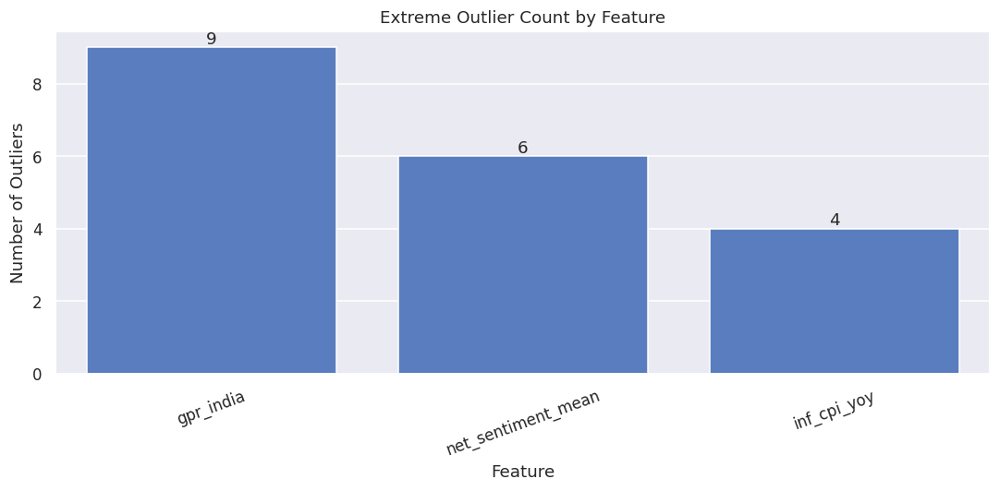

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot22b_extreme_feature_outliers_zscore.png


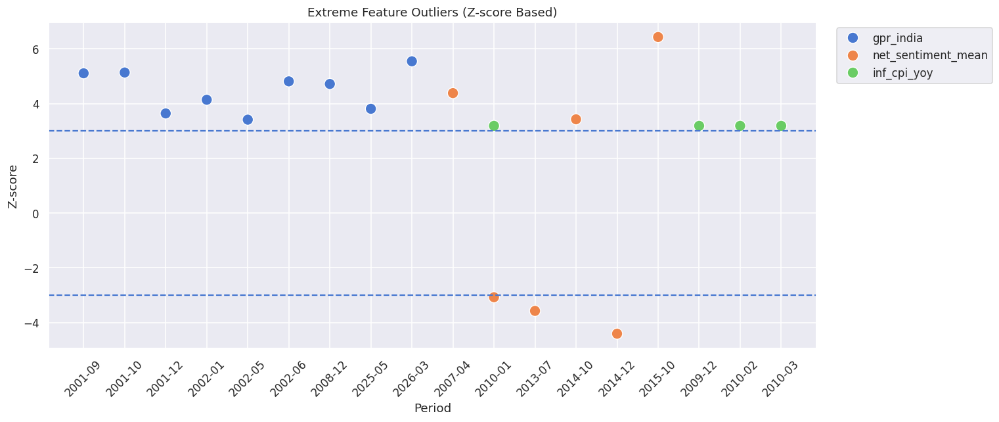

In [66]:
# ── 12a. Z-score based outlier detection (FIXED) ─────────────────────────────
outlier_features = [c for c in [
    'gpr_india',
    'net_sentiment_mean',
    'inf_cpi_yoy',
    'rate_yield_spread',
    'fx_usdinr_avg'
] if c in df.columns]

if outlier_features:

    outlier_report = []

    for col in outlier_features:

        series = df[col]

        z_scores = (series - series.mean()) / series.std()
        mask = z_scores.abs() > 3

        extreme = df.loc[mask, ['period', col]].copy()
        extreme['feature'] = col
        extreme['z_score'] = z_scores[mask]

        outlier_report.append(extreme)

    all_outliers = (
        pd.concat(outlier_report, ignore_index=True)
        if outlier_report else pd.DataFrame()
    )

    # ── Print summary ───────────────────────────────────────────────────────
    if not all_outliers.empty:

        print(f'📊 Extreme outliers (|z| > 3σ): {len(all_outliers)} cases')

        print('\n   Period     | Feature                  | Value       | Z-score')
        print('   ' + '-' * 65)

        for _, row in (
            all_outliers
            .sort_values('z_score', key=abs, ascending=False)
            .head(20)
            .iterrows()
        ):

            print(
                f'   {row["period"]:10s} | '
                f'{row["feature"]:25s} | '
                f'{row[row["feature"]]:11.4f} | '
                f'{row["z_score"]:+.2f}'
            )

        # ── Plot 1: Outlier counts per feature ─────────────────────────────
        plt.figure(figsize=(10, 5))

        count_plot = (
            all_outliers['feature']
            .value_counts()
            .sort_values(ascending=False)
        )

        ax = sns.barplot(
            x=count_plot.index,
            y=count_plot.values
        )

        for i, v in enumerate(count_plot.values):
            ax.text(i, v + 0.1, str(v), ha='center')

        plt.title('Extreme Outlier Count by Feature')
        plt.xlabel('Feature')
        plt.ylabel('Number of Outliers')

        plt.xticks(rotation=20)
        plt.tight_layout()
        # ── Save plot to Google Drive ──────────────────────────────────────
        _fig_name = 'Plot22a_extreme_outlier_count_by_feature.png'
        _fig_path = os.path.join(PLOT_DIR, _fig_name)
        plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
        print(f'📁 Saved → {_fig_path}')
        plt.show()

        # ── Plot 2: Z-score distribution scatter ──────────────────────────
        plt.figure(figsize=(14, 6))

        sns.scatterplot(
            data=all_outliers,
            x='period',
            y='z_score',
            hue='feature',
            s=120
        )

        plt.axhline(3, linestyle='--')
        plt.axhline(-3, linestyle='--')

        plt.title('Extreme Feature Outliers (Z-score Based)')
        plt.xlabel('Period')
        plt.ylabel('Z-score')

        plt.xticks(rotation=45)
        plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

        plt.tight_layout()
        # ── Save plot to Google Drive ──────────────────────────────────────
        _fig_name = 'Plot22b_extreme_feature_outliers_zscore.png'
        _fig_path = os.path.join(PLOT_DIR, _fig_name)
        plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
        print(f'📁 Saved → {_fig_path}')
        plt.show()

    else:
        print('✅ No extreme outliers (|z| > 3σ) detected.')

### 12b. Isolation Forest Anomaly Detection
**Research note**: Z-score detection catches univariate outliers but misses multivariate anomalies. Isolation Forest detects months where the *combination* of features is unusual — these may be unrecognised regime transitions.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot22c_isolation_forest_anomalies.png


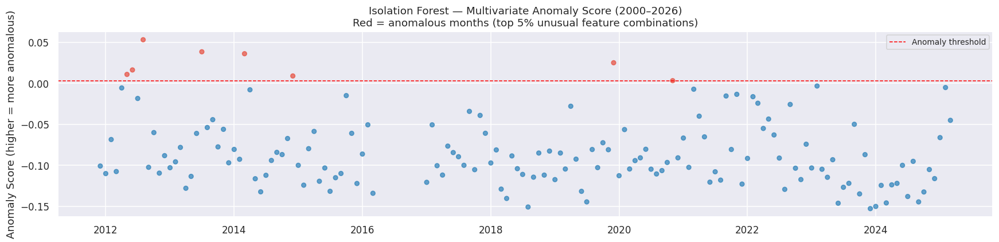

📊 Isolation Forest Anomalies: 8 months (top 5%)

   Top-15 most anomalous months:
 period  anomaly_score
2012-08       0.053154
2013-07       0.038466
2014-03       0.036119
2019-12       0.025098
2012-06       0.016330
2012-05       0.010894
2014-12       0.008990
2020-11       0.003258


In [67]:
# ── 12b. Isolation Forest Multivariate Anomaly Detection ────────────────────
try:
    from sklearn.ensemble import IsolationForest

    iso_cols = [c for c in [
        'gpr_india_z', 'net_sentiment_mean', 'negative_mean', 'event_count',
        'inf_cpi_yoy', 'rate_yield_spread', 'fx_usdinr_yoy_chg',
        'climate_news_share', 'cpu_shock_z',
    ] if c in df.columns]

    iso_data = df[iso_cols + ['period', 'period_dt']].dropna()

    if len(iso_data) > 20:
        iso = IsolationForest(contamination=0.05, random_state=42)
        iso_data = iso_data.copy()
        iso_data['anomaly'] = iso.fit_predict(iso_data[iso_cols])
        iso_data['anomaly_score'] = -iso.decision_function(iso_data[iso_cols])

        anomalies = iso_data[iso_data['anomaly'] == -1].sort_values('anomaly_score', ascending=False)

        fig, ax = plt.subplots(figsize=(16, 4))
        ax.scatter(iso_data['period_dt'], iso_data['anomaly_score'],
                   c=['#e74c3c' if a == -1 else '#2980b9' for a in iso_data['anomaly']],
                   s=25, alpha=0.7)
        ax.axhline(iso_data.loc[iso_data['anomaly']==-1, 'anomaly_score'].min(),
                   color='red', lw=1, linestyle='--', label='Anomaly threshold')
        ax.set_title('Isolation Forest — Multivariate Anomaly Score (2000–2026)\nRed = anomalous months (top 5% unusual feature combinations)')
        ax.set_ylabel('Anomaly Score (higher = more anomalous)')
        ax.legend(fontsize=9)
        ax.xaxis.set_major_locator(mdates.YearLocator(2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        plt.tight_layout()
        _save('Plot22c_isolation_forest_anomalies.png')
        plt.show()

        print(f'📊 Isolation Forest Anomalies: {len(anomalies)} months (top 5%)')
        print('\n   Top-15 most anomalous months:')
        print(anomalies[['period','anomaly_score']].head(15).to_string(index=False))
    else:
        print('⚠️  Insufficient data rows for Isolation Forest.')
except ImportError:
    print('⚠️  scikit-learn not installed. pip install scikit-learn')

---
## 13. Feature Engineering Validation
**Research note**: Phase 01B creates several engineered features. This section validates that they behave as expected (e.g., yield spread inverts before stress periods, CLI momentum turns negative before slowdowns).

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot23a_derived_fred_features.png


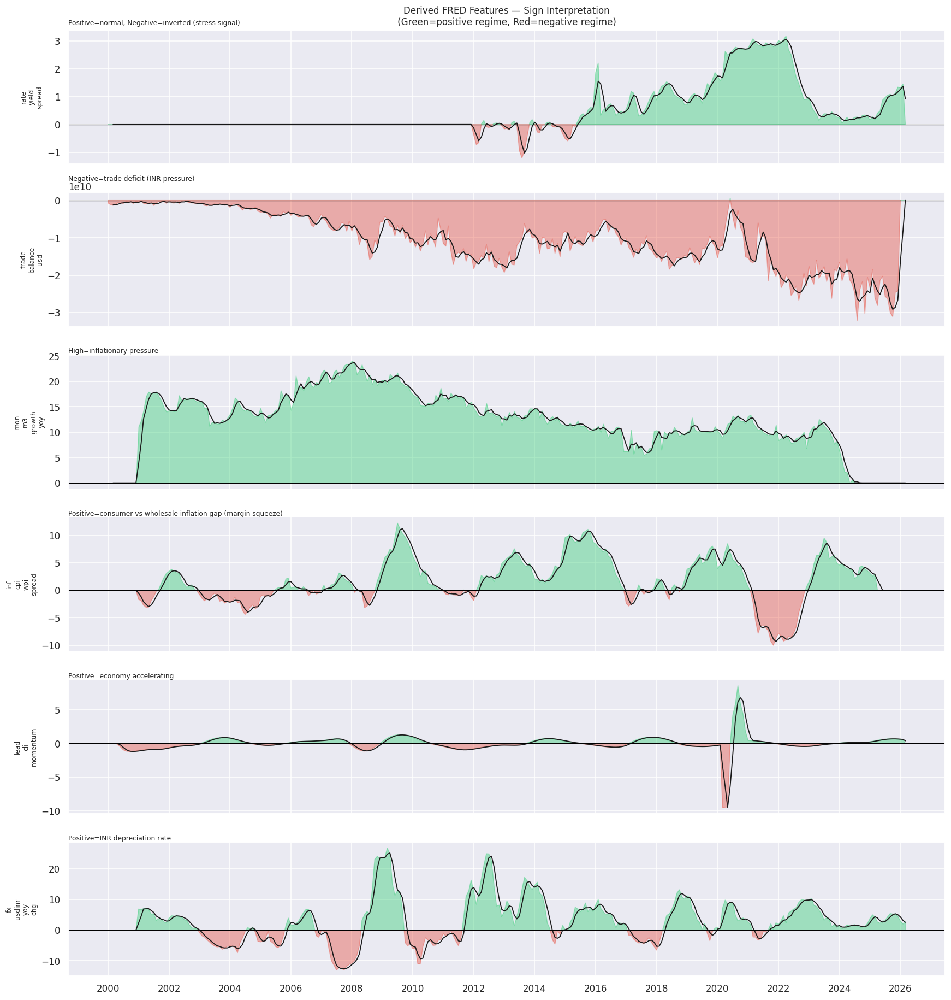

In [68]:
# ── 13a. Derived FRED feature validation ─────────────────────────────────────
derived_fred = ['rate_yield_spread', 'trade_balance_usd', 'mon_m3_growth_yoy',
                 'inf_cpi_wpi_spread', 'lead_cli_momentum', 'fx_usdinr_yoy_chg']
available_derived = [c for c in derived_fred if c in df.columns]

if available_derived:
    fig, axes = plt.subplots(len(available_derived), 1,
                              figsize=(16, 2.8 * len(available_derived)), sharex=True)
    if len(available_derived) == 1:
        axes = [axes]

    interpret = {
        'rate_yield_spread'  : 'Positive=normal, Negative=inverted (stress signal)',
        'trade_balance_usd'  : 'Negative=trade deficit (INR pressure)',
        'mon_m3_growth_yoy'  : 'High=inflationary pressure',
        'inf_cpi_wpi_spread' : 'Positive=consumer vs wholesale inflation gap (margin squeeze)',
        'lead_cli_momentum'  : 'Positive=economy accelerating',
        'fx_usdinr_yoy_chg'  : 'Positive=INR depreciation rate',
    }

    for ax, col in zip(axes, available_derived):
        vals = df[col].fillna(0)
        ax.fill_between(df['period_dt'], vals, 0,
                        where=vals >= 0, interpolate=True, alpha=0.4, color='#2ecc71')
        ax.fill_between(df['period_dt'], vals, 0,
                        where=vals < 0, interpolate=True, alpha=0.4, color='#e74c3c')
        ax.plot(df['period_dt'], vals.rolling(3).mean(), 'k-', lw=1.2)
        ax.axhline(0, color='black', lw=0.8)
        ax.set_ylabel(col.replace('_', '\n'), fontsize=8)
        if col in interpret:
            ax.set_title(interpret[col], fontsize=8, loc='left', pad=2)

    axes[0].set_title('Derived FRED Features — Sign Interpretation\n'
                      '(Green=positive regime, Red=negative regime)', fontsize=11)
    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    # ── Save plot to Google Drive ──────────────────────────────────────
    _fig_name = 'Plot23a_derived_fred_features.png'
    _fig_path = os.path.join(PLOT_DIR, _fig_name)
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'📁 Saved → {_fig_path}')
    plt.show()

📊 GPR vs Sentiment correlation by sub-period (Spearman):
-----------------------------------------------------------------
  Pre-GDELT2 (2000–2014): r=-0.030, p=0.6902 → ✅ Expected
  Post-GDELT2 (2015–2026): r=0.104, p=0.2284 → ⚠️ Positive
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot23b_gpr_sentiment_subperiod_corr.png


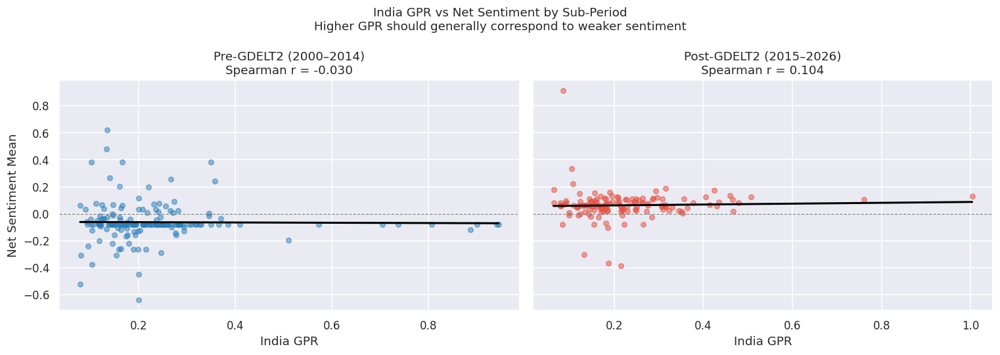

In [69]:
from scipy.stats import spearmanr

# ── 13b. GPR vs Sentiment correlation by sub-period ─────────────────────────
if 'gpr_india' in df.columns and 'net_sentiment_mean' in df.columns:

    periods_list = [
        ('Pre-GDELT2 (2000–2014)',
         df['period_dt'] < '2015-01-01',
         '#2980b9'),

        ('Post-GDELT2 (2015–2026)',
         df['period_dt'] >= '2015-01-01',
         '#e74c3c'),
    ]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, 5),
        sharey=True
    )

    print('📊 GPR vs Sentiment correlation by sub-period (Spearman):')
    print('-' * 65)

    for ax, (label, mask, color) in zip(axes, periods_list):

        sub = df.loc[
            mask,
            ['gpr_india',
             'net_sentiment_mean']
        ].dropna()

        if len(sub) > 10:

            # Scatter
            ax.scatter(
                sub['gpr_india'],
                sub['net_sentiment_mean'],
                alpha=0.5,
                s=25,
                color=color
            )

            # Regression line
            m, b = np.polyfit(
                sub['gpr_india'],
                sub['net_sentiment_mean'],
                1
            )

            xs = np.linspace(
                sub['gpr_india'].min(),
                sub['gpr_india'].max(),
                100
            )

            ax.plot(
                xs,
                m * xs + b,
                color='black',
                lw=2
            )

            # Spearman correlation
            r, p = spearmanr(
                sub['gpr_india'],
                sub['net_sentiment_mean']
            )

            direction = (
                '✅ Expected'
                if r < 0
                else '⚠️ Positive'
            )

            print(
                f'  {label}: '
                f'r={r:.3f}, '
                f'p={p:.4f} → {direction}'
            )

            ax.set_title(
                f'{label}\n'
                f'Spearman r = {r:.3f}'
            )

        else:

            ax.text(
                0.5,
                0.5,
                'Insufficient Data',
                transform=ax.transAxes,
                ha='center'
            )

        ax.axhline(0,
                   color='grey',
                   lw=0.8,
                   linestyle='--')

        ax.set_xlabel('India GPR')

    axes[0].set_ylabel('Net Sentiment Mean')

    plt.suptitle(
        'India GPR vs Net Sentiment by Sub-Period\n'
        'Higher GPR should generally correspond to weaker sentiment',
        fontsize=12
    )

    plt.tight_layout()

    _save('Plot23b_gpr_sentiment_subperiod_corr.png')

    plt.show()

else:
    print('⚠️ Required columns not found.')

---
## 14. FRED Derived Features & Macro Regime Signals
**Research note**: Key engineered FRED signals — yield spread inversion, INR depreciation rate, M3 growth momentum — are leading indicators for regime transitions. This section validates their signal quality and computes ACF/PACF to guide lag selection in Phase 03.


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot24a_yield_spread_inversion.png


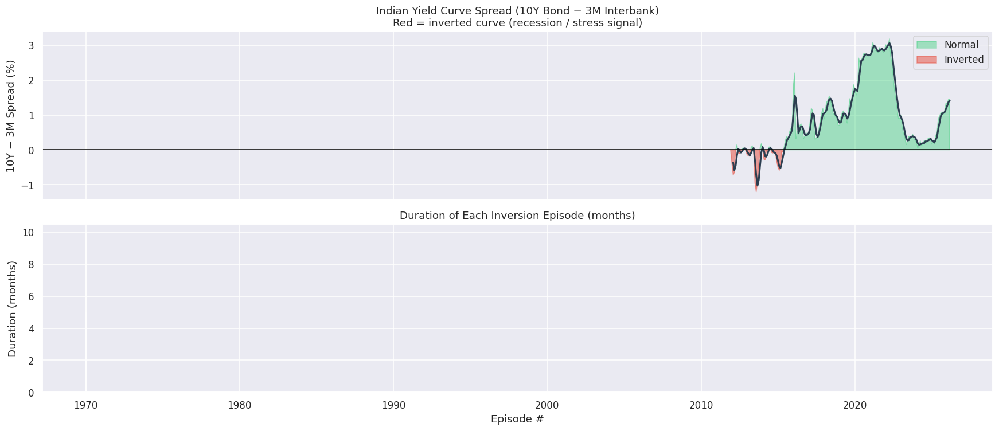


📊 Yield Curve Inversion Stats:
   Inverted months  : 29 of 315 (9.2%)
   Inversion episodes: 6
   Longest episode  : 10 months


In [70]:
# ── 14a. Yield Spread Inversion Detector ──────────────────────────────────────
if 'rate_yield_spread' in df.columns:
    fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)

    spread = df['rate_yield_spread'].ffill()
    inverted = spread < 0

    axes[0].fill_between(df['period_dt'], spread, 0,
                         where=spread >= 0, interpolate=True, color='#2ecc71', alpha=0.4, label='Normal')
    axes[0].fill_between(df['period_dt'], spread, 0,
                         where=spread < 0,  interpolate=True, color='#e74c3c', alpha=0.5, label='Inverted')
    axes[0].plot(df['period_dt'], spread.rolling(3).mean(), color='#2c3e50', lw=2)
    axes[0].axhline(0, color='black', lw=1)
    axes[0].set_ylabel('10Y − 3M Spread (%)')
    axes[0].set_title('Indian Yield Curve Spread (10Y Bond − 3M Interbank)\nRed = inverted curve (recession / stress signal)')
    axes[0].legend()

    # Inversion duration histogram
    durations = []
    run = 0
    for v in inverted:
        if v: run += 1
        else:
            if run > 0: durations.append(run)
            run = 0

    axes[1].bar(range(len(durations)), durations, color='#e74c3c', alpha=0.8)
    axes[1].set_title('Duration of Each Inversion Episode (months)')
    axes[1].set_xlabel('Episode #')
    axes[1].set_ylabel('Duration (months)')

    plt.tight_layout()
    _save('Plot24a_yield_spread_inversion.png')
    plt.show()

    total_inv = inverted.sum()
    print(f'\n📊 Yield Curve Inversion Stats:')
    print(f'   Inverted months  : {total_inv} of {len(df)} ({total_inv/len(df)*100:.1f}%)')
    print(f'   Inversion episodes: {len(durations)}')
    if durations:
        print(f'   Longest episode  : {max(durations)} months')


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot24b_acf_pacf.png


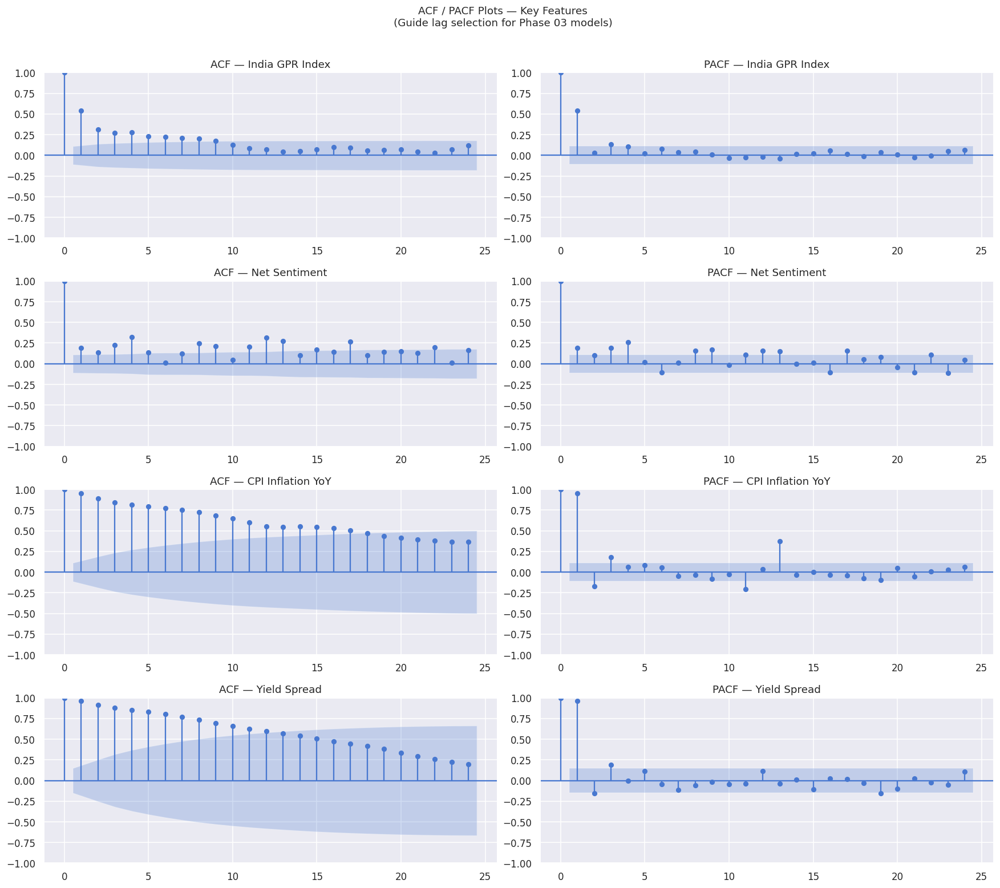

✅ ACF/PACF plots generated. Use significant lags for lag-feature engineering in Phase 03.


In [71]:
# ── 14b. ACF / PACF for key time series (lag structure for Phase 03) ──────────
acf_series = [(c, label) for c, label in [
    ('gpr_india',         'India GPR Index'),
    ('net_sentiment_mean','Net Sentiment'),
    ('inf_cpi_yoy',       'CPI Inflation YoY'),
    ('rate_yield_spread', 'Yield Spread'),
] if c in df.columns and df[c].dropna().shape[0] > 30]

if acf_series:
    fig, axes = plt.subplots(len(acf_series), 2, figsize=(16, 3.5 * len(acf_series)))
    if len(acf_series) == 1:
        axes = [axes]

    for row_axes, (col, label) in zip(axes, acf_series):
        series = df[col].dropna()
        plot_acf( series, ax=row_axes[0], lags=24, title=f'ACF — {label}')
        plot_pacf(series, ax=row_axes[1], lags=24, title=f'PACF — {label}', method='ywm')

    plt.suptitle('ACF / PACF Plots — Key Features\n(Guide lag selection for Phase 03 models)', fontsize=12, y=1.01)
    plt.tight_layout()
    _save('Plot24b_acf_pacf.png')
    plt.show()
    print('✅ ACF/PACF plots generated. Use significant lags for lag-feature engineering in Phase 03.')


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot24c_inr_depreciation.png


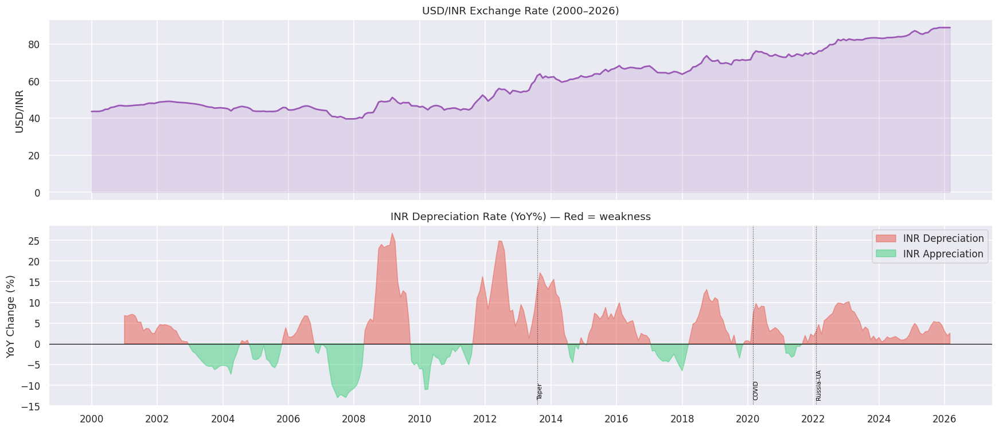

In [72]:
# ── 14c. INR depreciation rate & FX regime chart ─────────────────────────────
if 'fx_usdinr_avg' in df.columns:
    fx = df['fx_usdinr_avg'].ffill()
    fx_yoy = fx.pct_change(12) * 100  # 12-month rolling depreciation rate

    fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)

    axes[0].plot(df['period_dt'], fx, color='#9b59b6', lw=1.8)
    axes[0].fill_between(df['period_dt'], fx, alpha=0.15, color='#9b59b6')
    axes[0].set_ylabel('USD/INR')
    axes[0].set_title('USD/INR Exchange Rate (2000–2026)')

    axes[1].fill_between(df['period_dt'], fx_yoy, 0,
                         where=fx_yoy >= 0, interpolate=True, color='#e74c3c', alpha=0.45, label='INR Depreciation')
    axes[1].fill_between(df['period_dt'], fx_yoy, 0,
                         where=fx_yoy < 0,  interpolate=True, color='#2ecc71', alpha=0.45, label='INR Appreciation')
    axes[1].axhline(0, color='black', lw=0.8)
    axes[1].set_ylabel('YoY Change (%)')
    axes[1].set_title('INR Depreciation Rate (YoY%) — Red = weakness')
    axes[1].legend()

    # Annotate taper tantrum and COVID
    for dt, label in [('2013-08-01', 'Taper'), ('2020-03-01', 'COVID'), ('2022-02-01', 'Russia-UA')]:
        axes[1].axvline(pd.Timestamp(dt), color='black', lw=0.8, linestyle=':', alpha=0.7)
        axes[1].text(pd.Timestamp(dt), axes[1].get_ylim()[0] * 0.9, label,
                     rotation=90, fontsize=7, color='black', va='bottom')

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot24c_inr_depreciation.png')
    plt.show()


### 14d. M3 Money Supply & Liquidity Cycle Analysis
**Research note**: Phase01B includes M3, M1, and credit series. Money supply cycles often precede regime transitions with a 6–12 month lag. This cell examines M3 growth alongside CPI and GPR to identify liquidity-driven stress periods.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot24d_m3_liquidity_cycle.png


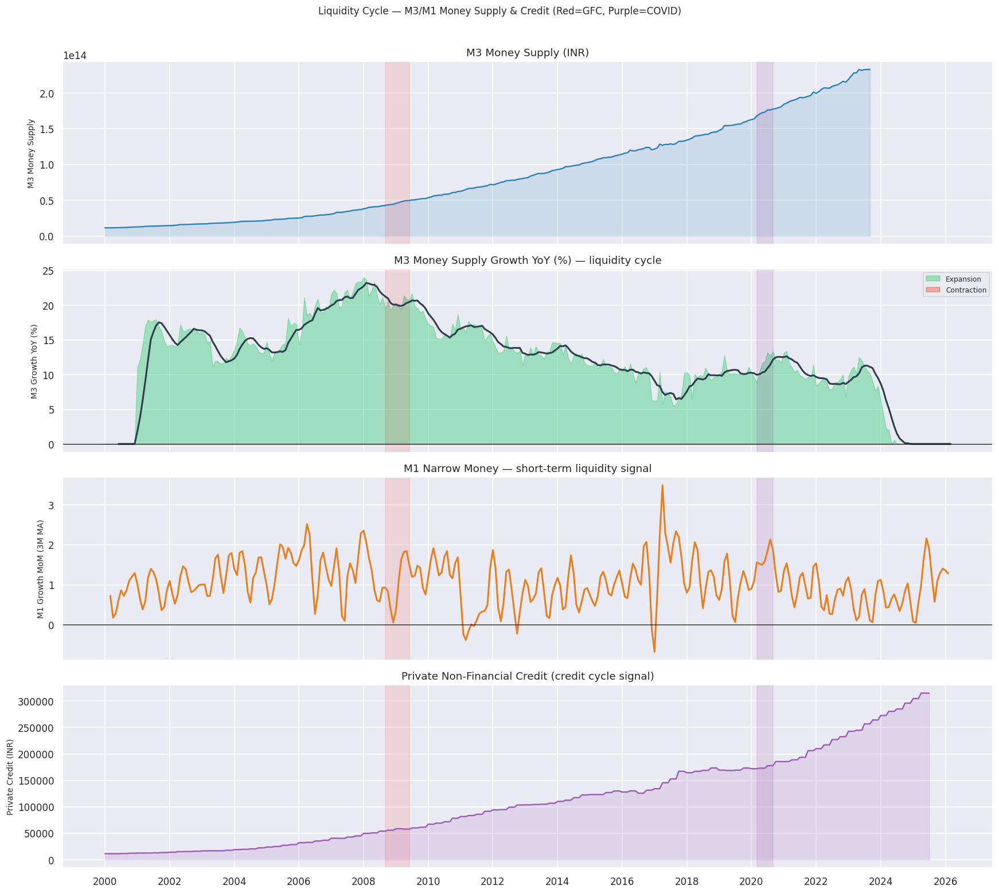

📊 M3 Growth YoY vs GPR India Spearman ρ: 0.011


In [73]:
# ── 14d. M3 Money Supply & Liquidity Cycle ───────────────────────────────────
m3_col   = 'mon_m3_supply'       if 'mon_m3_supply'       in df.columns else None
m3gr_col = 'mon_m3_growth_yoy'   if 'mon_m3_growth_yoy'   in df.columns else None
m1gr_col = 'mon_m1_growth_mom'   if 'mon_m1_growth_mom'   in df.columns else None
crd_col  = 'credit_private_nonfin_inr' if 'credit_private_nonfin_inr' in df.columns else None

if m3_col or m3gr_col:
    n_panels = sum(x is not None for x in [m3_col, m3gr_col, m1gr_col, crd_col])
    n_panels = max(2, min(n_panels, 4))
    fig, axes = plt.subplots(n_panels, 1, figsize=(16, 3.5 * n_panels), sharex=True)
    if n_panels == 1: axes = [axes]
    ax_i = 0

    if m3_col:
        axes[ax_i].plot(df['period_dt'], df[m3_col], color='#2980b9', lw=1.5)
        axes[ax_i].fill_between(df['period_dt'], df[m3_col], alpha=0.15, color='#2980b9')
        axes[ax_i].set_ylabel('M3 Money Supply', fontsize=9)
        axes[ax_i].set_title('M3 Money Supply (INR)')
        ax_i += 1

    if m3gr_col and ax_i < n_panels:
        vals = df[m3gr_col].fillna(0)
        axes[ax_i].fill_between(df['period_dt'], vals, 0,
                                 where=vals >= 0, alpha=0.4, color='#2ecc71', label='Expansion')
        axes[ax_i].fill_between(df['period_dt'], vals, 0,
                                 where=vals < 0,  alpha=0.4, color='#e74c3c', label='Contraction')
        axes[ax_i].plot(df['period_dt'], vals.rolling(6).mean(), color='#2c3e50', lw=2)
        axes[ax_i].axhline(0, color='black', lw=0.8)
        axes[ax_i].set_ylabel('M3 Growth YoY (%)', fontsize=9)
        axes[ax_i].set_title('M3 Money Supply Growth YoY (%) — liquidity cycle')
        axes[ax_i].legend(fontsize=8)
        ax_i += 1

    if m1gr_col and ax_i < n_panels:
        axes[ax_i].plot(df['period_dt'], df[m1gr_col].rolling(3).mean(), color='#e67e22', lw=2)
        axes[ax_i].axhline(0, color='black', lw=0.8)
        axes[ax_i].set_ylabel('M1 Growth MoM (3M MA)', fontsize=9)
        axes[ax_i].set_title('M1 Narrow Money — short-term liquidity signal')
        ax_i += 1

    if crd_col and ax_i < n_panels:
        axes[ax_i].plot(df['period_dt'], df[crd_col], color='#9b59b6', lw=1.5)
        axes[ax_i].fill_between(df['period_dt'], df[crd_col], alpha=0.15, color='#9b59b6')
        axes[ax_i].set_ylabel('Private Credit (INR)', fontsize=9)
        axes[ax_i].set_title('Private Non-Financial Credit (credit cycle signal)')

    for ax in axes:
        ax.axvspan(pd.Timestamp('2008-09-01'), pd.Timestamp('2009-06-01'), alpha=0.1, color='red')
        ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2020-09-01'), alpha=0.1, color='purple')
    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.suptitle('Liquidity Cycle — M3/M1 Money Supply & Credit (Red=GFC, Purple=COVID)', fontsize=11, y=1.01)
    plt.tight_layout()
    _save('Plot24d_m3_liquidity_cycle.png')
    plt.show()

    if m3gr_col:
        corr_gpr = df[['gpr_india', m3gr_col]].dropna().corr(method='spearman').iloc[0,1] if 'gpr_india' in df.columns else float('nan')
        print(f'📊 M3 Growth YoY vs GPR India Spearman ρ: {corr_gpr:.3f}')
else:
    print('⚠️  M3 money supply columns not found in df.')

---
## 15. Source-Density & Article-Quality Diagnostics
**Research note**: Article-level quality metrics (title length, duplicate rate, language mix) affect FinBERT reliability. Months with very few articles or high title duplication should be flagged as low-confidence sentiment observations.


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot25a_monthly_article_density.png


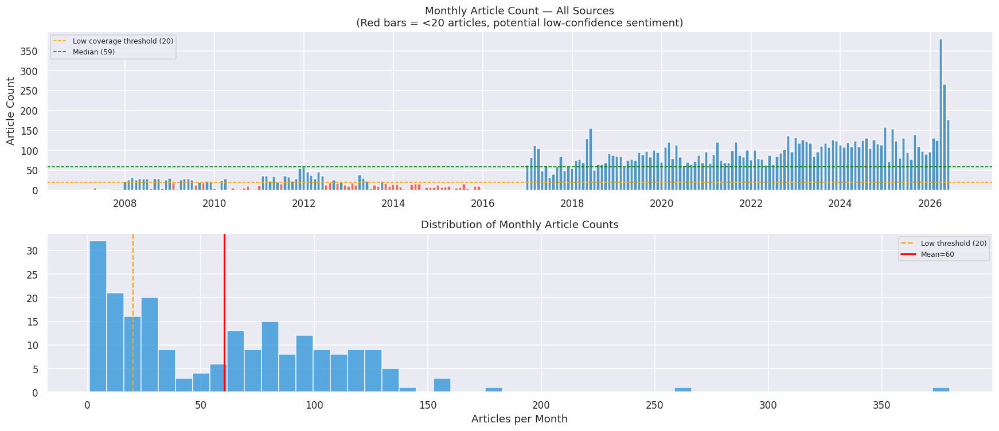


📊 Coverage Diagnostics:
   Low-coverage months (<20 articles): 59
   Median articles/month: 59
   Max articles/month  : 380


In [74]:
# ── 15a. Monthly article count distribution ───────────────────────────────────
if not corpus.empty and 'period' in corpus.columns:
    monthly_counts = corpus.groupby('period').size().reset_index(name='n_articles')
    monthly_counts['period_dt'] = pd.to_datetime(monthly_counts['period'].astype(str) + '-01', errors='coerce')
    monthly_counts = monthly_counts.sort_values('period_dt')

    fig, axes = plt.subplots(2, 1, figsize=(16, 7))

    # Time series of article count
    axes[0].bar(monthly_counts['period_dt'],
                monthly_counts['n_articles'],
                color=['#e74c3c' if n < 20 else '#2980b9' for n in monthly_counts['n_articles']],
                width=25, alpha=0.8)
    axes[0].axhline(20, color='orange', lw=1, linestyle='--', label='Low coverage threshold (20)')
    axes[0].axhline(monthly_counts['n_articles'].median(), color='green', lw=1,
                    linestyle='--', label=f'Median ({monthly_counts["n_articles"].median():.0f})')
    axes[0].set_title('Monthly Article Count — All Sources\n(Red bars = <20 articles, potential low-confidence sentiment)')
    axes[0].set_ylabel('Article Count')
    axes[0].legend(fontsize=8)
    axes[0].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    # Distribution
    axes[1].hist(monthly_counts['n_articles'], bins=50, color='#3498db', alpha=0.8, edgecolor='white')
    axes[1].axvline(20, color='orange', lw=1.5, linestyle='--', label='Low threshold (20)')
    axes[1].axvline(monthly_counts['n_articles'].mean(), color='red', lw=2,
                    label=f'Mean={monthly_counts["n_articles"].mean():.0f}')
    axes[1].set_title('Distribution of Monthly Article Counts')
    axes[1].set_xlabel('Articles per Month')
    axes[1].legend(fontsize=8)

    plt.tight_layout()
    _save('Plot25a_monthly_article_density.png')
    plt.show()

    low_cov = monthly_counts[monthly_counts['n_articles'] < 20]
    print(f'\n📊 Coverage Diagnostics:')
    print(f'   Low-coverage months (<20 articles): {len(low_cov)}')
    print(f'   Median articles/month: {monthly_counts["n_articles"].median():.0f}')
    print(f'   Max articles/month  : {monthly_counts["n_articles"].max():,}')


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot25b_title_quality.png


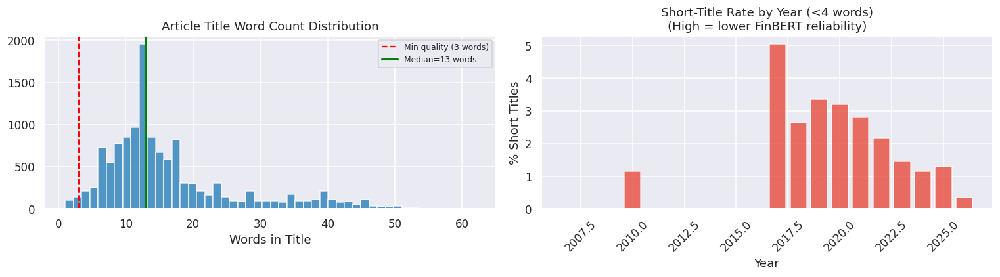


📊 Title Quality:
   Short titles (<4 words): 243 (1.9%)
   Missing titles: 0


In [75]:
# ── 15b. Title length & quality analysis ─────────────────────────────────────
if not corpus.empty and 'title' in corpus.columns:
    corpus['title_len'] = corpus['title'].fillna('').str.split().str.len()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].hist(corpus['title_len'], bins=50, color='#2980b9', alpha=0.8, edgecolor='white')
    axes[0].axvline(3, color='red', lw=1.5, linestyle='--', label='Min quality (3 words)')
    axes[0].axvline(corpus['title_len'].median(), color='green', lw=2,
                    label=f'Median={corpus["title_len"].median():.0f} words')
    axes[0].set_title('Article Title Word Count Distribution')
    axes[0].set_xlabel('Words in Title')
    axes[0].legend(fontsize=8)

    # Short title rate by year
    if 'year' in corpus.columns:
        short_rate = (
            corpus[corpus['title_len'] < 4]
            .groupby('year').size()
            .div(corpus.groupby('year').size())
            * 100
        ).fillna(0)
        axes[1].bar(short_rate.index, short_rate.values, color='#e74c3c', alpha=0.8)
        axes[1].set_title('Short-Title Rate by Year (<4 words)\n(High = lower FinBERT reliability)')
        axes[1].set_xlabel('Year')
        axes[1].set_ylabel('% Short Titles')
        axes[1].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    _save('Plot25b_title_quality.png')
    plt.show()

    total_short = (corpus['title_len'] < 4).sum()
    print(f'\n📊 Title Quality:')
    print(f'   Short titles (<4 words): {total_short:,} ({total_short/len(corpus)*100:.1f}%)')
    print(f'   Missing titles: {corpus["title"].isna().sum():,}')


### 15c. Source Quality Score by Source Group
**Research note**: Phase01B assigns source quality weights (AlphaVantage=1.2, RSS=1.0, GDELT2=0.8, Wayback=0.6). This cell validates whether high-weight sources produce systematically different FinBERT scores, confirming the weighting logic.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot25c_source_quality_weights.png


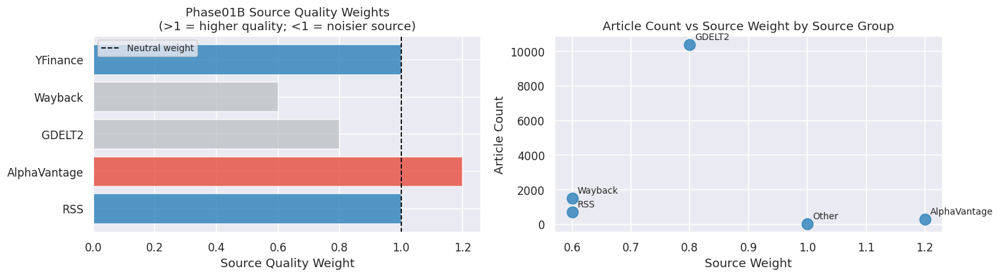

📊 Source Group Stats:
source_group  n_articles  weight
AlphaVantage         298     1.2
      GDELT2       10377     0.8
       Other          44     1.0
         RSS         699     0.6
     Wayback        1522     0.6

   Weighted-average source quality: 0.790
   High-quality articles (w>=1.0): 823 (6.4%)


In [76]:
# ── 15c. Source Quality Weights Validation ───────────────────────────────────
if not corpus.empty and 'source' in corpus.columns:
    SOURCE_WEIGHT = {'RSS': 1.0, 'AlphaVantage': 1.2, 'GDELT2': 0.8, 'Wayback': 0.6, 'YFinance': 1.0}

    def map_weight(src):
        for k, v in SOURCE_WEIGHT.items():
            if k.lower() in str(src).lower():
                return v
        return 1.0

    def classify_src(src):
        s = str(src).lower()
        if any(x in s for x in ['gdelt', 'gdelt2']): return 'GDELT2'
        if any(x in s for x in ['rss', 'reuters', 'bloomberg', 'et_', 'moneycontrol',
                                  'livemint', 'cnbc', 'bbc', 'aljazeera', 'wsj']): return 'RSS'
        if 'yfinance' in s or 'yf' in s: return 'YFinance'
        if 'alphavantage' in s or 'av_' in s: return 'AlphaVantage'
        if 'wayback' in s: return 'Wayback'
        return 'Other'

    corpus['source_group'] = corpus['source'].apply(classify_src)
    corpus['source_weight'] = corpus['source'].apply(map_weight)

    # Phase01B source weights bar chart
    wt_df = pd.DataFrame(list(SOURCE_WEIGHT.items()), columns=['Source', 'Weight'])
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].barh(wt_df['Source'], wt_df['Weight'],
                 color=['#e74c3c' if w > 1 else '#2980b9' if w == 1 else '#bdc3c7' for w in wt_df['Weight']],
                 alpha=0.8)
    axes[0].axvline(1.0, color='black', lw=1.2, linestyle='--', label='Neutral weight')
    axes[0].set_xlabel('Source Quality Weight')
    axes[0].set_title('Phase01B Source Quality Weights\n(>1 = higher quality; <1 = noisier source)')
    axes[0].legend(fontsize=9)

    # Article count by source group and weight
    grp_wt = corpus.groupby('source_group').agg(
        n_articles=('source', 'count'),
        weight=('source_weight', 'first')
    ).reset_index()
    axes[1].scatter(grp_wt['weight'], grp_wt['n_articles'], s=120, color='#2980b9', alpha=0.8)
    for _, row in grp_wt.iterrows():
        axes[1].annotate(row['source_group'], (row['weight'], row['n_articles']),
                         textcoords='offset points', xytext=(5, 5), fontsize=9)
    axes[1].set_xlabel('Source Weight')
    axes[1].set_ylabel('Article Count')
    axes[1].set_title('Article Count vs Source Weight by Source Group')

    plt.tight_layout()
    _save('Plot25c_source_quality_weights.png')
    plt.show()

    print('📊 Source Group Stats:')
    print(grp_wt.to_string(index=False))
    print(f'\n   Weighted-average source quality: {corpus["source_weight"].mean():.3f}')
    print(f'   High-quality articles (w>=1.0): {(corpus["source_weight"]>=1.0).sum():,} ({(corpus["source_weight"]>=1.0).mean()*100:.1f}%)')
else:
    print('⚠️  Corpus not loaded or missing source column.')

---
## 16. Alpha Vantage Sentiment EDA
**Research note**: Alpha Vantage provides ~2 years of recent sentiment data (topic-tagged). This section validates its coverage, sentiment distribution by topic, and alignment with FinBERT for the overlapping period.


✅ Alpha Vantage sentiment: 2 rows × 4 cols
   Columns: ['period', 'av_sentiment_mean', 'av_sentiment_std', 'av_article_count']
   Period: 2026-04 → 2026-05
⚠️  Topic or score column not found. Columns available: ['period', 'av_sentiment_mean', 'av_sentiment_std', 'av_article_count']
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot26b_av_monthly_trend.png


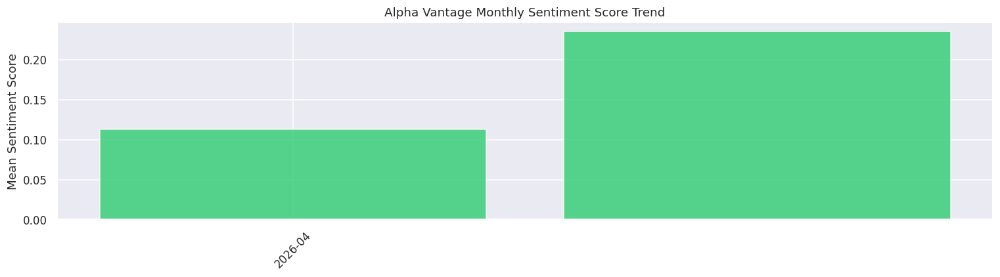

In [77]:
# ── 16a. Alpha Vantage coverage & topic distribution ─────────────────────────
if not av_sent.empty:
    print(f'✅ Alpha Vantage sentiment: {av_sent.shape[0]} rows × {av_sent.shape[1]} cols')
    print(f'   Columns: {list(av_sent.columns)}')
    print(f'   Period: {av_sent.iloc[:,0].min()} → {av_sent.iloc[:,0].max()}' if av_sent.shape[0] > 0 else '')

    # If topic column present, show topic distribution
    topic_col = next((c for c in av_sent.columns if 'topic' in c.lower()), None)
    score_col  = next((c for c in av_sent.columns if 'score' in c.lower() or 'sentiment' in c.lower()), None)

    if topic_col and score_col:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        topic_counts = av_sent[topic_col].value_counts().head(10)
        axes[0].barh(topic_counts.index[::-1], topic_counts.values[::-1], color='#3498db', alpha=0.8)
        axes[0].set_title('Alpha Vantage Article Count by Topic')
        axes[0].set_xlabel('Article Count')

        if pd.api.types.is_numeric_dtype(av_sent[score_col]):
            topic_sent = av_sent.groupby(topic_col)[score_col].mean().sort_values()
            axes[1].barh(topic_sent.index, topic_sent.values,
                         color=['#e74c3c' if v < 0 else '#2ecc71' for v in topic_sent.values], alpha=0.8)
            axes[1].axvline(0, color='black', lw=0.8)
            axes[1].set_title(f'Mean Sentiment Score by Topic ({score_col})')
            axes[1].set_xlabel('Mean Score')

        plt.suptitle('Alpha Vantage Sentiment — Topic Analysis', fontsize=12)
        plt.tight_layout()
        _save('Plot26a_av_topic_distribution.png')
        plt.show()
    else:
        print(f'⚠️  Topic or score column not found. Columns available: {list(av_sent.columns)}')

    # Monthly AV sentiment trend
    period_col = next((c for c in av_sent.columns if 'period' in c.lower() or 'month' in c.lower()), None)
    if period_col and score_col and pd.api.types.is_numeric_dtype(av_sent[score_col]):
        av_monthly = av_sent.groupby(period_col)[score_col].mean().reset_index()
        av_monthly.columns = ['period', 'av_score']
        av_monthly['period_dt'] = pd.to_datetime(av_monthly['period'].astype(str) + '-01', errors='coerce')
        av_monthly = av_monthly.dropna(subset=['period_dt']).sort_values('period_dt')

        fig, ax = plt.subplots(figsize=(14, 4))
        ax.bar(av_monthly['period_dt'], av_monthly['av_score'],
               color=['#e74c3c' if v < 0 else '#2ecc71' for v in av_monthly['av_score']],
               width=25, alpha=0.8)
        ax.axhline(0, color='black', lw=0.8)
        ax.set_title('Alpha Vantage Monthly Sentiment Score Trend')
        ax.set_ylabel('Mean Sentiment Score')
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,4,7,10]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax.tick_params(axis='x', rotation=45)
        plt.tight_layout()
        _save('Plot26b_av_monthly_trend.png')
        plt.show()
else:
    print('⚠️  Alpha Vantage sentiment file not loaded (av_monthly_sentiment.csv missing).')
    print('   Re-run Phase01B [AV] section to generate it.')


---
## 17. GDELT 2.0 Article Volume & Tone Analysis
**Research note**: GDELT 2.0 is the primary source backbone from Feb 2015 onward. This section analyses GDELT2 query volumes, tone distribution, and temporal coverage to confirm backbone completeness before Phase 03 modelling.


✅ GDELT2 master: 25,816 rows × 7 cols
   Columns: ['source', 'published', 'period', 'title', 'summary', 'url', 'keywords']...
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot27a_gdelt2_volume_tone.png


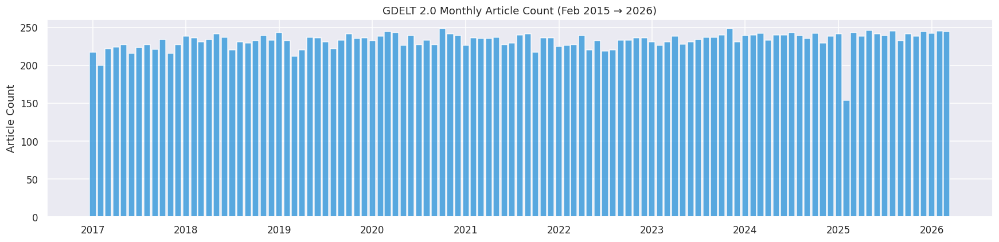


📊 GDELT2 Coverage: 111 months
   Median articles/month: 235
   Missing months       : 23 → ['2015-02', '2015-03', '2015-04', '2015-05', '2015-06']...


In [78]:
# ── 17a. GDELT2 volume and tone over time ─────────────────────────────────────
if not gdelt2.empty:
    print(f'✅ GDELT2 master: {gdelt2.shape[0]:,} rows × {gdelt2.shape[1]} cols')
    print(f'   Columns: {list(gdelt2.columns[:10])}...')

    date_col  = next((c for c in gdelt2.columns if 'date' in c.lower() or 'period' in c.lower()), None)
    tone_col2 = next((c for c in gdelt2.columns if 'tone' in c.lower()), None)

    if date_col:
        gdelt2['_period'] = pd.to_datetime(gdelt2[date_col], errors='coerce').dt.to_period('M').astype(str)
        gdelt2_monthly_vol = gdelt2.groupby('_period').size().reset_index(name='n_articles')
        gdelt2_monthly_vol['period_dt'] = pd.to_datetime(
            gdelt2_monthly_vol['_period'].astype(str) + '-01', errors='coerce')

        n_plots = 2 if tone_col2 else 1
        fig, axes = plt.subplots(n_plots, 1, figsize=(16, 4 * n_plots), sharex=True)
        if n_plots == 1: axes = [axes]

        axes[0].bar(gdelt2_monthly_vol['period_dt'], gdelt2_monthly_vol['n_articles'],
                    color='#3498db', width=25, alpha=0.8)
        axes[0].set_title('GDELT 2.0 Monthly Article Count (Feb 2015 → 2026)')
        axes[0].set_ylabel('Article Count')

        if tone_col2 and n_plots == 2:
            gdelt2_tone = gdelt2.groupby('_period')[tone_col2].mean().reset_index()
            gdelt2_tone['period_dt'] = pd.to_datetime(
                gdelt2_tone['_period'].astype(str) + '-01', errors='coerce')
            axes[1].plot(gdelt2_tone['period_dt'], gdelt2_tone[tone_col2].rolling(3).mean(),
                         color='#e67e22', lw=2)
            axes[1].fill_between(gdelt2_tone['period_dt'], gdelt2_tone[tone_col2],
                                 alpha=0.2, color='#e67e22')
            axes[1].axhline(0, color='black', lw=0.8)
            axes[1].set_title('GDELT2 Average Tone (3M MA)')
            axes[1].set_ylabel('AvgTone')

        axes[-1].xaxis.set_major_locator(mdates.YearLocator())
        axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        plt.tight_layout()
        _save('Plot27a_gdelt2_volume_tone.png')
        plt.show()

        coverage_months = gdelt2_monthly_vol['_period'].nunique()
        print(f'\n📊 GDELT2 Coverage: {coverage_months} months')
        print(f'   Median articles/month: {gdelt2_monthly_vol["n_articles"].median():.0f}')
        gaps = [m for m in pd.period_range('2015-02', '2026-03', freq='M').astype(str)
                if m not in set(gdelt2_monthly_vol['_period'].tolist())]
        print(f'   Missing months       : {len(gaps)} → {gaps[:5]}{"..." if len(gaps) > 5 else ""}')
else:
    print('⚠️  GDELT2 master file not loaded (gdelt2_master.csv missing).')


### 17b. GDELT 2.0 Keyword Topic Breakdown
**Research note**: Phase01B tags GDELT2 articles with the `keywords` column (pipe-delimited matched GDELT_QUERIES). This cell analyses which queries are most active and how topic distributions shift over time — validating the §4.2.6 sustainability query additions.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot27b_gdelt2_keyword_breakdown.png


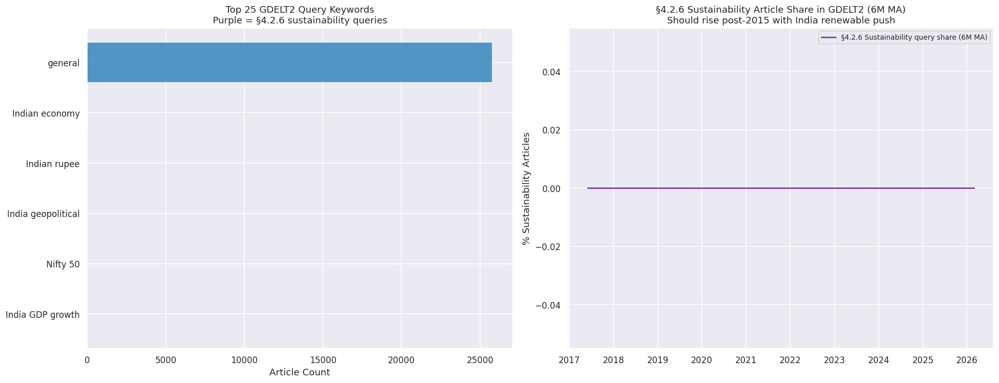

📊 Sustainability articles in GDELT2: 0 (0.0%)


In [79]:
# ── 17b. GDELT2 Keyword Topic Breakdown ─────────────────────────────────────
if not gdelt2.empty and 'keywords' in gdelt2.columns:
    # Expand pipe-delimited keywords
    kw_exploded = gdelt2['keywords'].dropna().str.split('|').explode().str.strip()
    kw_counts   = kw_exploded.value_counts().head(25)

    # Classify queries into topic groups (mirrors Phase01B GDELT_QUERIES)
    sustain_queries = [
        'India climate change', 'India carbon emission', 'India extreme weather',
        'India climate risk', 'India transition risk', 'India net zero', 'India Paris Agreement',
        'India COP climate', 'India renewable energy', 'India solar power', 'India wind energy',
        'India electric vehicle', 'India green hydrogen', 'India energy transition',
        'India decarbonization', 'India clean energy policy', 'India green bond',
        'India ESG', 'India ESG investing', 'India BRSR', 'India sustainable finance',
        'India green finance', 'India climate finance',
    ]
    kw_counts_df = kw_counts.reset_index()
    kw_counts_df.columns = ['keyword', 'count']
    kw_counts_df['category'] = kw_counts_df['keyword'].apply(
        lambda k: '§4.2.6 Sustainability' if any(sq.lower() in k.lower() for sq in sustain_queries) else 'Market/Macro'
    )

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    colors_kw = ['#8e44ad' if c == '§4.2.6 Sustainability' else '#2980b9' for c in kw_counts_df['category']]
    axes[0].barh(kw_counts_df['keyword'][::-1], kw_counts_df['count'][::-1], color=colors_kw[::-1], alpha=0.8)
    axes[0].set_title('Top 25 GDELT2 Query Keywords\nPurple = §4.2.6 sustainability queries')
    axes[0].set_xlabel('Article Count')

    # Sustainability vs Market share over time
    if '_period' in gdelt2.columns:
        period_col = '_period'
    else:
        gdelt2['_period'] = pd.to_datetime(gdelt2.get('published', gdelt2.get('seendate', pd.Series())), errors='coerce').dt.to_period('M').astype(str)
        period_col = '_period'

    gdelt2['is_sustain'] = gdelt2['keywords'].fillna('').apply(
        lambda k: int(any(sq.lower() in k.lower() for sq in sustain_queries))
    )
    sustain_share = gdelt2.groupby(period_col)['is_sustain'].mean().reset_index()
    sustain_share['period_dt'] = pd.to_datetime(sustain_share[period_col].astype(str) + '-01', errors='coerce')
    sustain_share = sustain_share.dropna(subset=['period_dt']).sort_values('period_dt')

    axes[1].plot(sustain_share['period_dt'], sustain_share['is_sustain'].rolling(6).mean()*100,
                 color='#8e44ad', lw=2, label='§4.2.6 Sustainability query share (6M MA)')
    axes[1].fill_between(sustain_share['period_dt'], sustain_share['is_sustain'].rolling(6).mean()*100,
                         alpha=0.2, color='#8e44ad')
    axes[1].set_title('§4.2.6 Sustainability Article Share in GDELT2 (6M MA)\nShould rise post-2015 with India renewable push')
    axes[1].set_ylabel('% Sustainability Articles')
    axes[1].xaxis.set_major_locator(mdates.YearLocator())
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    axes[1].legend(fontsize=9)

    plt.tight_layout()
    _save('Plot27b_gdelt2_keyword_breakdown.png')
    plt.show()
    print(f'📊 Sustainability articles in GDELT2: {gdelt2["is_sustain"].sum():,} ({gdelt2["is_sustain"].mean()*100:.1f}%)')
else:
    print('⚠️  gdelt2 not loaded or missing keywords column.')

---
## 18. Regime-Event Driven GPR Decomposition
**Research note**: Different event types (elections, global shocks, crises) may drive GPR differently. This section tests whether GPR levels significantly differ across event types and visualises GPR distributions conditional on event flags — directly validating the Phase 01B feature engineering hypothesis.


📊 GPR Distribution by Event Flag (Mann-Whitney U test):
   Event                          | μ (event=1) | μ (event=0) | U p-value | Significant?
   ----------------------------------------------------------------------
   event_election                 |       0.21  |       0.23  | 0.8530    |   
   event_union_budget             |       0.19  |       0.23  | 0.1766    |   
   event_rbi_policy               |       0.23  |       0.23  | 0.4658    |   
   event_reform                   |       0.21  |       0.23  | 0.6332    |   
   event_global_shock             |       0.25  |       0.23  | 0.9909    |   
   event_crisis                   |       0.22  |       0.23  | 0.8873    |   
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot28a_gpr_by_event_type.png


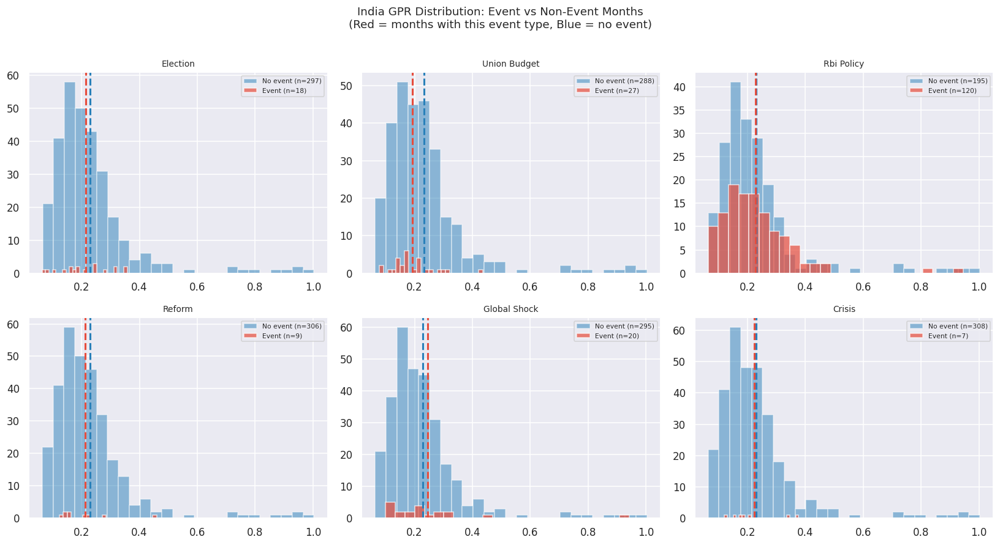

In [80]:
# ── 18a. GPR distribution conditional on event flags ─────────────────────────
gpr_col = 'gpr_india' if 'gpr_india' in df.columns else None
ev_flag_cols = [c for c in df.columns if c.startswith('event_') and c != 'event_count'
                and df[c].dtype in [int, np.int64, float, np.float64]]

if gpr_col and ev_flag_cols:
    n = len(ev_flag_cols)
    ncols = 3
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    axes = axes.flatten()

    print('📊 GPR Distribution by Event Flag (Mann-Whitney U test):')
    print(f'   {"Event":30s} | μ (event=1) | μ (event=0) | U p-value | Significant?')
    print('   ' + '-' * 70)

    for ax, ev_col in zip(axes, ev_flag_cols):
        grp1 = df.loc[df[ev_col] == 1, gpr_col].dropna()
        grp0 = df.loc[df[ev_col] == 0, gpr_col].dropna()

        ax.hist(grp0, bins=25, alpha=0.5, color='#2980b9', label=f'No event (n={len(grp0)})')
        ax.hist(grp1, bins=25, alpha=0.7, color='#e74c3c', label=f'Event (n={len(grp1)})')
        ax.axvline(grp0.mean(), color='#2980b9', lw=2, linestyle='--')
        ax.axvline(grp1.mean(), color='#e74c3c', lw=2, linestyle='--')

        label = ev_col.replace('event_', '').replace('_', ' ').title()
        ax.set_title(label, fontsize=9)
        ax.legend(fontsize=7)

        if len(grp1) >= 3 and len(grp0) >= 3:
            stat, pval = mannwhitneyu(grp1, grp0, alternative='two-sided')
            sig = '✅' if pval < 0.05 else '  '
            print(f'   {ev_col:30s} | {grp1.mean():10.2f}  | {grp0.mean():10.2f}  | {pval:.4f}    | {sig}')

    for ax in axes[n:]:
        ax.set_visible(False)

    plt.suptitle('India GPR Distribution: Event vs Non-Event Months\n'
                 '(Red = months with this event type, Blue = no event)', fontsize=12, y=1.01)
    plt.tight_layout()
    _save('Plot28a_gpr_by_event_type.png')
    plt.show()


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot28b_gpr_shock_response.png


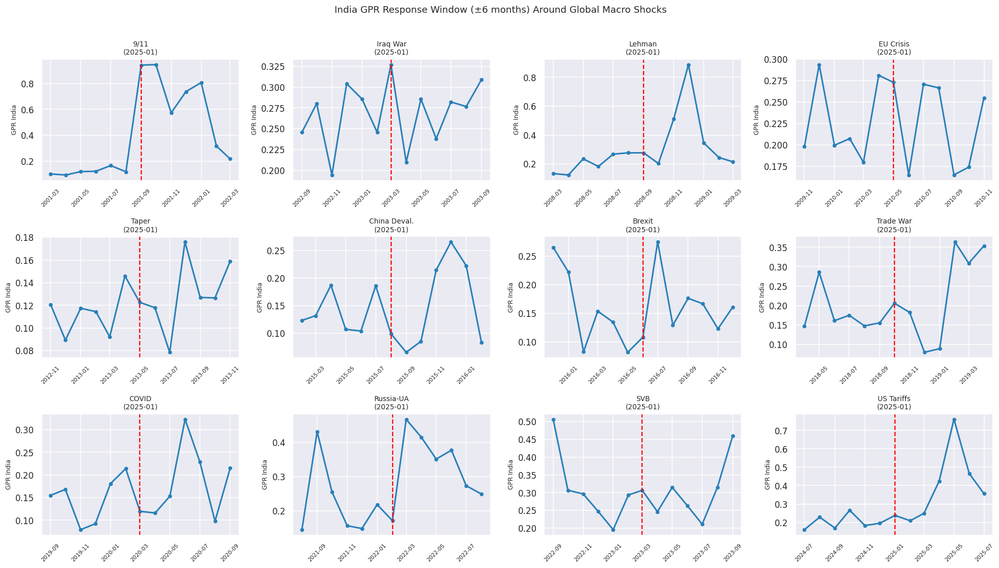

✅ Plotted 12 shock response windows.


In [81]:
# ── 18b. GPR response to global macro shocks timeline ────────────────────────
# Phase01B defines these specific global shock events (fetch_global_macro_shocks)
KNOWN_SHOCKS = [
    ('2001-09', '9/11'),    ('2003-03', 'Iraq War'),  ('2008-09', 'Lehman'),
    ('2010-05', 'EU Crisis'),('2013-05', 'Taper'),     ('2015-08', 'China Deval.'),
    ('2016-06', 'Brexit'),   ('2018-10', 'Trade War'),  ('2020-03', 'COVID'),
    ('2022-02', 'Russia-UA'),('2023-03', 'SVB'),        ('2025-01', 'US Tariffs'),
]

if gpr_col:
    window = 6  # months before/after shock
    fig, axes = plt.subplots(3, 4, figsize=(18, 10))
    axes = axes.flatten()

    valid_shocks = []
    for period_str, shock_name in KNOWN_SHOCKS:
        shock_dt = pd.Timestamp(period_str + '-01')
        sub = df[(df['period_dt'] >= shock_dt - pd.DateOffset(months=window)) &
                 (df['period_dt'] <= shock_dt + pd.DateOffset(months=window))].copy()
        if len(sub) >= 3:
            valid_shocks.append((shock_dt, shock_name, sub))

    for ax, (shock_dt, shock_name, sub) in zip(axes, valid_shocks):
        ax.plot(sub['period_dt'], sub[gpr_col], color='#2980b9', lw=2, marker='o', markersize=4)
        ax.axvline(shock_dt, color='red', lw=1.5, linestyle='--')
        ax.set_title(f'{shock_name}\n({period_str})', fontsize=9)
        ax.set_ylabel('GPR India', fontsize=8)
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax.tick_params(axis='x', rotation=45, labelsize=7)

    for ax in axes[len(valid_shocks):]:
        ax.set_visible(False)

    plt.suptitle(f'India GPR Response Window (±{window} months) Around Global Macro Shocks',
                 fontsize=12, y=1.01)
    plt.tight_layout()
    _save('Plot28b_gpr_shock_response.png')
    plt.show()
    print(f'✅ Plotted {len(valid_shocks)} shock response windows.')


---
## 19. Sustainability & Climate-Risk EDA  *(4.2.6)*
**Research note**: This section provides exploratory analysis of the five sustainability
variables defined in paper §4.2.6:
- **Climate-Risk News Share** — proportion of climate-related articles
- **Green-Transition Event Density** — EV / renewable / net-zero event intensity
- **Climate-Policy Uncertainty (CPU)** — Baker-Bloom-Davis index + shock z-score
- **Sustainability-Sensitive Geopolitical Indicators** — GPR × climate/green interaction
- **ESG-Linked Sentiment Behaviour** — polarity from ESG/sustainability news

Expected patterns: climate share spikes with monsoon (Jun–Sep) and COP events;
green-transition density rises post-2015 with India's renewable push; ESG sentiment
deteriorates during regulatory uncertainty shocks.


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19a_climate_news_share.png


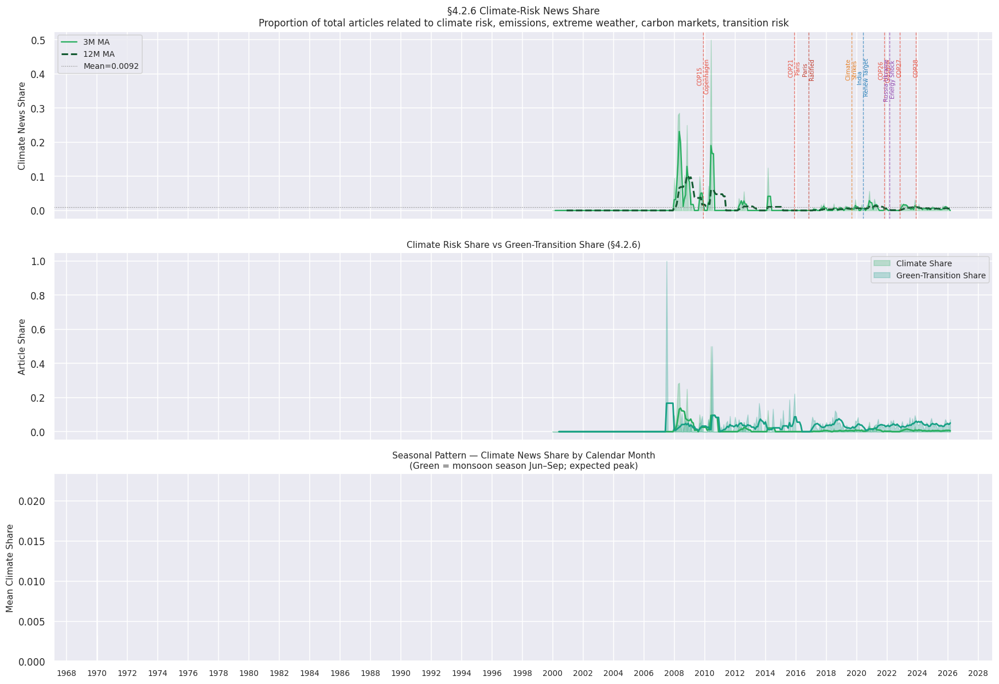

📊 Climate News Share — mean: 0.0092  max: 0.5000
   Peak month: 2010-06


In [82]:

# ── 19a. Climate-Risk News Share — time series & trend ────────────────────────
# Climate News Share_t = Climate-related Articles_t / Total Articles_t

clim_share_col = 'climate_news_share'
if clim_share_col in df.columns:
    plot_df = df[df['period_dt'] >= pd.Timestamp('2000-01-01')].copy()
    cs      = plot_df[clim_share_col].fillna(0)

    fig, axes = plt.subplots(3, 1, figsize=(16, 11), sharex=True)

    # — Panel 1: raw + rolling MAs ─────────────────────────────────────────────
    axes[0].fill_between(plot_df['period_dt'], cs, alpha=0.25, color='#27ae60')
    axes[0].plot(plot_df['period_dt'], cs.rolling(3).mean(),  lw=1.5, color='#27ae60', label='3M MA')
    axes[0].plot(plot_df['period_dt'], cs.rolling(12).mean(), lw=2,   color='#145a32', linestyle='--', label='12M MA')
    axes[0].axhline(cs.mean(), color='grey', lw=0.8, linestyle=':', label=f'Mean={cs.mean():.4f}')
    axes[0].set_ylabel('Climate News Share', fontsize=10)
    axes[0].set_title('§4.2.6 Climate-Risk News Share\n'
                      'Proportion of total articles related to climate risk, emissions, '
                      'extreme weather, carbon markets, transition risk', fontsize=11)
    axes[0].legend(fontsize=9)

    # Annotate key climate/policy events
    clim_events = [
        ('2009-12', 'COP15\nCopenhagen', '#e74c3c'),
        ('2015-12', 'COP21\nParis', '#e74c3c'),
        ('2016-11', 'Paris\nRatified', '#c0392b'),
        ('2019-09', 'Climate\nStrikes', '#e67e22'),
        ('2021-11', 'COP26\nGlasgow', '#e74c3c'),
        ('2022-11', 'COP27', '#e74c3c'),
        ('2023-12', 'COP28', '#e74c3c'),
        ('2020-06', 'India\nRenew Target', '#2980b9'),
        ('2022-03', 'Russia-Ukraine\nEnergy Shock', '#8e44ad'),
    ]
    for period_str, label, color in clim_events:
        try:
            x_pos = pd.Timestamp(period_str + '-01')
            if plot_df['period_dt'].min() <= x_pos <= plot_df['period_dt'].max():
                axes[0].axvline(x_pos, color=color, lw=0.9, linestyle='--', alpha=0.7)
                axes[0].text(x_pos, axes[0].get_ylim()[1]*0.85, label,
                             fontsize=6.5, color=color, ha='center', rotation=90, va='top')
        except Exception:
            pass

    # — Panel 2: green_transition_share comparison ─────────────────────────────
    if 'green_transition_share' in df.columns:
        gt = plot_df['green_transition_share'].fillna(0)
        axes[1].fill_between(plot_df['period_dt'], cs,  alpha=0.25, color='#27ae60', label='Climate Share')
        axes[1].fill_between(plot_df['period_dt'], gt,  alpha=0.25, color='#16a085', label='Green-Transition Share')
        axes[1].plot(plot_df['period_dt'], cs.rolling(6).mean(), lw=1.8, color='#27ae60')
        axes[1].plot(plot_df['period_dt'], gt.rolling(6).mean(), lw=1.8, color='#16a085')
        axes[1].set_ylabel('Article Share', fontsize=10)
        axes[1].set_title('Climate Risk Share vs Green-Transition Share (§4.2.6)', fontsize=10)
        axes[1].legend(fontsize=9)

    # — Panel 3: monthly seasonal bar (average by calendar month) ──────────────
    if 'period_dt' in plot_df.columns:
        plot_df['cal_month'] = plot_df['period_dt'].dt.month
        seasonal = plot_df.groupby('cal_month')[clim_share_col].mean()
        month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
        bar_colors  = ['#2ecc71' if m in [6,7,8,9] else '#95a5a6' for m in range(1,13)]
        axes[2].bar(range(1,13), seasonal.reindex(range(1,13)).fillna(0),
                    color=bar_colors, edgecolor='white', linewidth=0.5)
        axes[2].set_xticks(range(1,13))
        axes[2].set_xticklabels(month_names, fontsize=9)
        axes[2].set_ylabel('Mean Climate Share', fontsize=10)
        axes[2].set_title('Seasonal Pattern — Climate News Share by Calendar Month\n'
                          '(Green = monsoon season Jun–Sep; expected peak)', fontsize=10)
        axes[2].set_xlabel('')

    axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot19a_climate_news_share.png')
    plt.show()
    print(f'📊 Climate News Share — mean: {cs.mean():.4f}  max: {cs.max():.4f}')
    print(f'   Peak month: {plot_df.loc[cs.idxmax(), "period"]}')
else:
    print('⚠️  climate_news_share not in df. Run Section 2D-9 first.')


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19b_green_transition_density.png


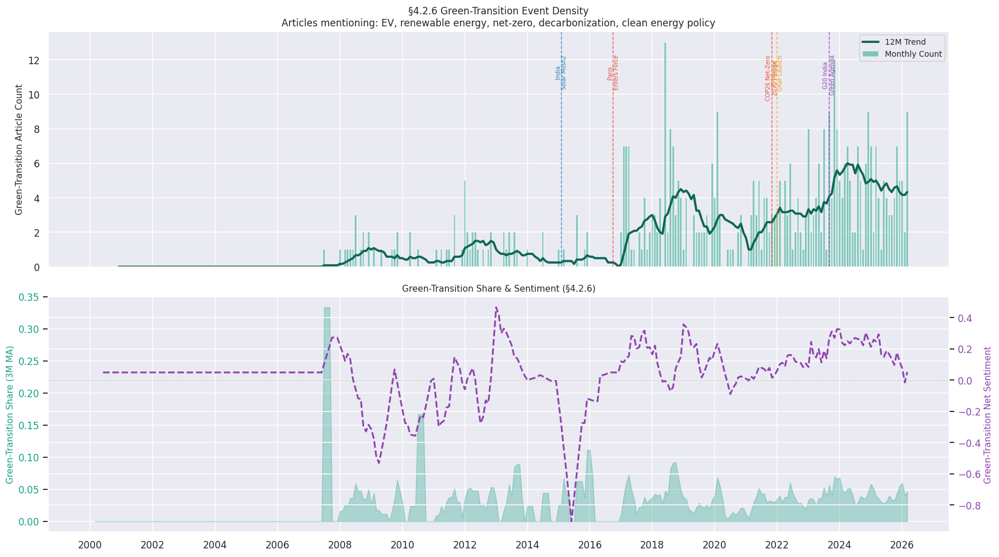

📊 Green-Transition Density — mean: 1.5  max: 13
   Pre-2015 avg: 0.3  |  Post-2015 avg: 3.0  (×9.2x)


In [83]:
# ── 19b. Green-Transition Event Density ────────────────────────────────────────
# Number of renewable-energy, decarbonization, EV, net-zero,
# or clean-energy policy events within a period.

gt_count_col = 'count_green_transition'
gt_share_col = 'green_transition_share'

if gt_count_col in df.columns or gt_share_col in df.columns:
    plot_df = df[df['period_dt'] >= pd.Timestamp('2000-01-01')].copy()

    fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

    # — Panel 1: absolute count with trend ─────────────────────────────────────
    if gt_count_col in plot_df.columns:
        gt_cnt = plot_df[gt_count_col].fillna(0)
        axes[0].bar(plot_df['period_dt'], gt_cnt, width=25, color='#16a085', alpha=0.5, label='Monthly Count')
        axes[0].plot(plot_df['period_dt'], gt_cnt.rolling(12).mean(), lw=2.5,
                     color='#0e6655', label='12M Trend')
        axes[0].set_ylabel('Green-Transition Article Count', fontsize=10)
        axes[0].set_title('§4.2.6 Green-Transition Event Density\n'
                          'Articles mentioning: EV, renewable energy, net-zero, '
                          'decarbonization, clean energy policy', fontsize=11)
        axes[0].legend(fontsize=9)

        # Annotate India policy milestones
        gt_events = [
            ('2015-02', 'India\nSolar Mssn2', '#2980b9'),
            ('2016-10', 'Paris\nEnters Force', '#e74c3c'),
            ('2021-11', 'COP26 Net-Zero\n2070 Pledge', '#e74c3c'),
            ('2022-01', 'PM Surya\nGhar Launch', '#f39c12'),
            ('2023-09', 'G20 India\nGreen Agenda', '#8e44ad'),
        ]
        for period_str, label, color in gt_events:
            try:
                x_pos = pd.Timestamp(period_str + '-01')
                if plot_df['period_dt'].min() <= x_pos <= plot_df['period_dt'].max():
                    axes[0].axvline(x_pos, color=color, lw=1, linestyle='--', alpha=0.8)
                    axes[0].text(x_pos, axes[0].get_ylim()[1]*0.9, label,
                                 fontsize=6.5, color=color, ha='center', rotation=90, va='top')
            except Exception:
                pass

    # — Panel 2: share vs sentiment overlay ─────────────────────────────────────
    if gt_share_col in plot_df.columns:
        gt_shr = plot_df[gt_share_col].fillna(0)
        ax2 = axes[1]
        ax2_twin = ax2.twinx()

        ax2.fill_between(plot_df['period_dt'], gt_shr.rolling(3).mean(), alpha=0.3, color='#16a085')
        ax2.set_ylabel('Green-Transition Share (3M MA)', color='#16a085', fontsize=10)
        ax2.tick_params(axis='y', labelcolor='#16a085')

        if 'sent_green_transition' in plot_df.columns:
            ax2_twin.plot(plot_df['period_dt'], plot_df['sent_green_transition'].rolling(6).mean(),
                          color='#8e44ad', lw=2, linestyle='--', label='GT Sentiment (6M MA)')
            ax2_twin.axhline(0, color='grey', lw=0.6, linestyle=':')
            ax2_twin.set_ylabel('Green-Transition Net Sentiment', color='#8e44ad', fontsize=10)
            ax2_twin.tick_params(axis='y', labelcolor='#8e44ad')

        ax2.set_title('Green-Transition Share & Sentiment (§4.2.6)', fontsize=10)

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot19b_green_transition_density.png')
    plt.show()

    if gt_count_col in df.columns:
        print(f'📊 Green-Transition Density — mean: {df[gt_count_col].mean():.1f}  max: {df[gt_count_col].max():.0f}')
        pre2015  = df[df['period_dt'] < '2015-01-01'][gt_count_col].mean()
        post2015 = df[df['period_dt'] >= '2015-01-01'][gt_count_col].mean()
        print(f'   Pre-2015 avg: {pre2015:.1f}  |  Post-2015 avg: {post2015:.1f}  (×{post2015/(pre2015+1e-9):.1f}x)')
else:
    print('⚠️  count_green_transition / green_transition_share not in df.')
    print('   Ensure Phase01B v4 was used and Section 2D-9 ran.')


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19c_esg_sentiment_score.png


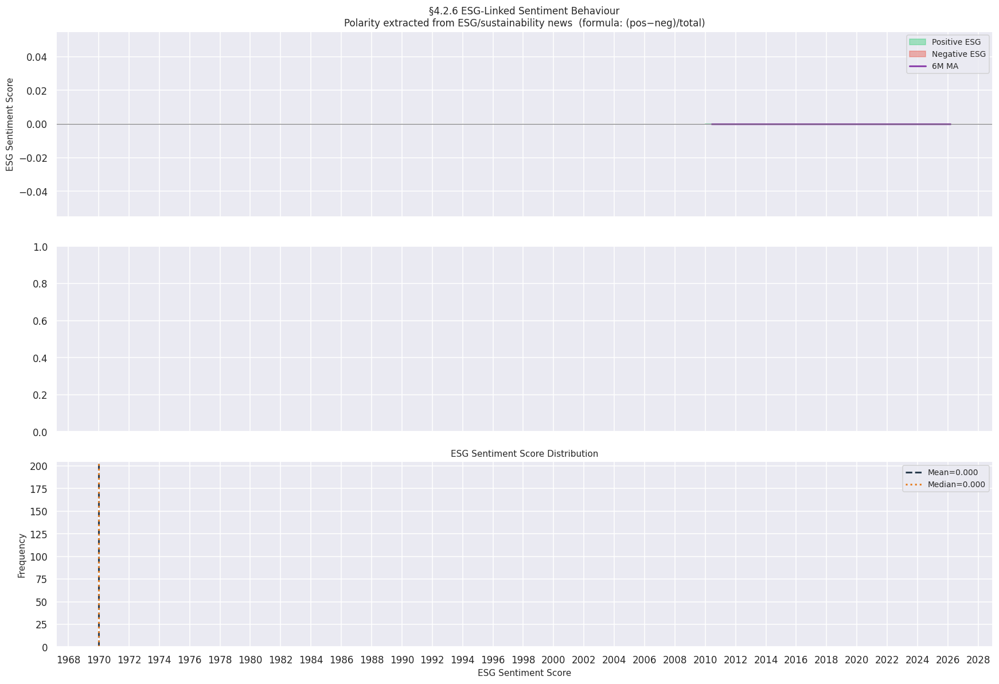

📊 ESG Sentiment — mean: 0.0000  std: 0.0000
   Months with negative ESG sentiment (<-0.05): 0 of 195


In [84]:
# ── 19c. ESG-Linked Sentiment Score ────────────────────────────────────────────
# ESG Sentiment Score_t = (Positive − Negative ESG Mentions) / Total ESG Mentions
# Expected: negative ESG sentiment precedes drawdowns and volatility clustering.

esg_sent_col = 'esg_sentiment_score'
esg_share_col = 'esg_news_share'

if esg_sent_col in df.columns or 'sent_esg' in df.columns:
    plot_df = df[df['period_dt'] >= pd.Timestamp('2010-01-01')].copy()
    sent_col = esg_sent_col if esg_sent_col in plot_df.columns else 'sent_esg'
    esg_sent = plot_df[sent_col].fillna(0)

    fig, axes = plt.subplots(3, 1, figsize=(16, 11), sharex=True)

    # — Panel 1: ESG sentiment polarity ────────────────────────────────────────
    axes[0].fill_between(plot_df['period_dt'], esg_sent, 0,
                         where=esg_sent >= 0, alpha=0.4, color='#2ecc71', label='Positive ESG')
    axes[0].fill_between(plot_df['period_dt'], esg_sent, 0,
                         where=esg_sent < 0,  alpha=0.4, color='#e74c3c', label='Negative ESG')
    axes[0].plot(plot_df['period_dt'], esg_sent.rolling(6).mean(), lw=2,
                 color='#8e44ad', label='6M MA')
    axes[0].axhline(0, color='grey', lw=0.8)
    axes[0].set_ylabel('ESG Sentiment Score', fontsize=10)
    axes[0].set_title('§4.2.6 ESG-Linked Sentiment Behaviour\n'
                      'Polarity extracted from ESG/sustainability news  '
                      '(formula: (pos−neg)/total)', fontsize=11)
    axes[0].legend(fontsize=9)

    # — Panel 2: ESG share vs overall sentiment ────────────────────────────────
    if esg_share_col in plot_df.columns:
        ax2 = axes[1]
        ax2_twin = ax2.twinx()
        esg_shr = plot_df[esg_share_col].fillna(0)
        ax2.fill_between(plot_df['period_dt'], esg_shr.rolling(6).mean(),
                         alpha=0.3, color='#8e44ad')
        ax2.set_ylabel('ESG News Share (6M MA)', color='#8e44ad', fontsize=10)
        if 'net_sentiment_mean' in plot_df.columns:
            ax2_twin.plot(plot_df['period_dt'],
                          plot_df['net_sentiment_mean'].rolling(6).mean(),
                          color='#2980b9', lw=1.8, linestyle='--', label='Overall Sentiment (6M MA)')
            ax2_twin.set_ylabel('Overall Net Sentiment', color='#2980b9', fontsize=10)
            ax2_twin.tick_params(axis='y', labelcolor='#2980b9')
        ax2.set_title('ESG News Share vs Overall Market Sentiment', fontsize=10)

    # — Panel 3: ESG sentiment distribution ────────────────────────────────────
    esg_clean = esg_sent.dropna()
    axes[2].hist(esg_clean, bins=40, color='#8e44ad', alpha=0.6, edgecolor='white')
    axes[2].axvline(esg_clean.mean(),   color='#2c3e50', lw=2, linestyle='--',
                    label=f'Mean={esg_clean.mean():.3f}')
    axes[2].axvline(esg_clean.median(), color='#e67e22', lw=2, linestyle=':',
                    label=f'Median={esg_clean.median():.3f}')
    axes[2].set_xlabel('ESG Sentiment Score', fontsize=10)
    axes[2].set_ylabel('Frequency', fontsize=10)
    axes[2].set_title('ESG Sentiment Score Distribution', fontsize=10)
    axes[2].legend(fontsize=9)

    axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot19c_esg_sentiment_score.png')
    plt.show()

    bearish_esg = (esg_sent < -0.05).sum()
    print(f'📊 ESG Sentiment — mean: {esg_clean.mean():.4f}  std: {esg_clean.std():.4f}')
    print(f'   Months with negative ESG sentiment (<-0.05): {bearish_esg} of {len(esg_clean)}')
else:
    print('⚠️  esg_sentiment_score / sent_esg not in df.')
    print('   Ensure Phase01B v4 ran the [RISK-CATEGORY] section with ESG keywords.')


ℹ️  CPU plot using cpu_index_broad.
📊 CPU — spike months using cpu_shock_z (|shock|>1.5σ): 26
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19d_cpu_index_shock.png


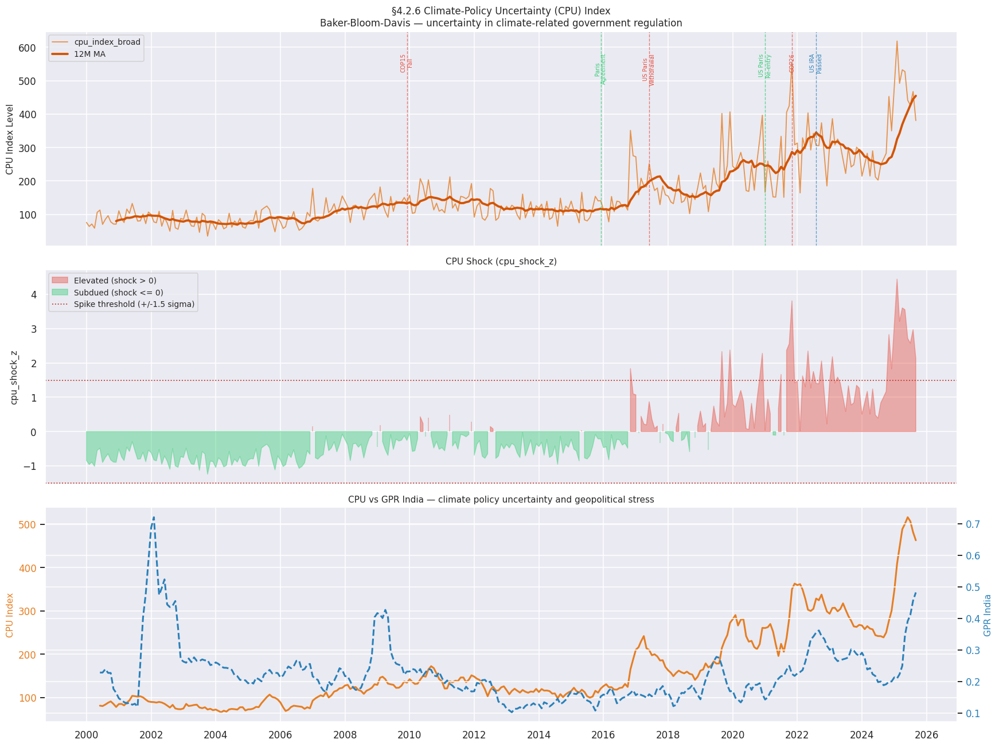

   cpu_index_broad mean: 162.60  max: 618.49
   Spearman corr (cpu_shock_z vs gpr_india): 0.043


In [85]:
# ── 19d. Climate-Policy Uncertainty (CPU) Index & Shock ────────────────────────
# Paper §4.2.6: CPU Shock_t = (CPU_t − μ_CPU) / σ_CPU
# Elevated uncertainty often increases market instability and risk premium.

CPU_INDEX_CANDIDATES = ['cpu_index_broad', 'cpu_index_narrow', 'cpu_index_gavriilidis', 'cpu_index']
cpu_index_col = next((c for c in CPU_INDEX_CANDIDATES if c in df.columns), None)
cpu_shock_col = next((c for c in ['cpu_shock_z', 'cpu_shock'] if c in df.columns), None)

if cpu_index_col is not None:
    plot_df = df[df[cpu_index_col].notna()].copy()
    cpu_level = pd.to_numeric(plot_df[cpu_index_col], errors='coerce')
    print(f'ℹ️  CPU plot using {cpu_index_col}.')

    panel_count = 3 if cpu_shock_col is not None else 2
    fig, axes = plt.subplots(panel_count, 1, figsize=(16, 4 * panel_count), sharex=True)
    axes = np.atleast_1d(axes)

    # Panel 1: CPU index raw + rolling.
    axes[0].plot(plot_df['period_dt'], cpu_level,
                 lw=1.2, color='#e67e22', alpha=0.8, label=cpu_index_col)
    axes[0].plot(plot_df['period_dt'], cpu_level.rolling(12).mean(),
                 lw=2.5, color='#d35400', label='12M MA')
    axes[0].set_ylabel('CPU Index Level', fontsize=10)
    axes[0].set_title('§4.2.6 Climate-Policy Uncertainty (CPU) Index\n'
                      'Baker-Bloom-Davis — uncertainty in climate-related government regulation', fontsize=11)
    axes[0].legend(fontsize=9)

    cpu_events = [
        ('2009-12', 'COP15\nFail', '#e74c3c'),
        ('2015-12', 'Paris\nAgreement', '#2ecc71'),
        ('2017-06', 'US Paris\nWithdrawal', '#e74c3c'),
        ('2021-01', 'US Paris\nRe-entry', '#2ecc71'),
        ('2021-11', 'COP26', '#e74c3c'),
        ('2022-08', 'US IRA\nPassed', '#2980b9'),
    ]
    for period_str, label, color in cpu_events:
        try:
            x_pos = pd.Timestamp(period_str + '-01')
            if plot_df['period_dt'].min() <= x_pos <= plot_df['period_dt'].max():
                axes[0].axvline(x_pos, color=color, lw=0.9, linestyle='--', alpha=0.7)
                axes[0].text(x_pos, axes[0].get_ylim()[1] * 0.9, label,
                             fontsize=6.5, color=color, ha='center', rotation=90, va='top')
        except Exception:
            pass

    next_panel = 1
    if cpu_shock_col is not None:
        cpu_shock = pd.to_numeric(plot_df[cpu_shock_col], errors='coerce').fillna(0)
        axes[next_panel].fill_between(plot_df['period_dt'], cpu_shock, 0,
                                      where=cpu_shock > 0, alpha=0.4, color='#e74c3c', label='Elevated (shock > 0)')
        axes[next_panel].fill_between(plot_df['period_dt'], cpu_shock, 0,
                                      where=cpu_shock <= 0, alpha=0.4, color='#2ecc71', label='Subdued (shock <= 0)')
        axes[next_panel].axhline(1.5,  color='#c0392b', lw=1.2, linestyle=':', label='Spike threshold (+/-1.5 sigma)')
        axes[next_panel].axhline(-1.5, color='#c0392b', lw=1.2, linestyle=':')
        axes[next_panel].set_ylabel(cpu_shock_col, fontsize=10)
        axes[next_panel].set_title(f'CPU Shock ({cpu_shock_col})', fontsize=10)
        axes[next_panel].legend(fontsize=9)
        spike_months = (cpu_shock.abs() > 1.5).sum()
        print(f'📊 CPU — spike months using {cpu_shock_col} (|shock|>1.5σ): {spike_months}')
        next_panel += 1
    else:
        print('ℹ️  CPU shock column not present; skipping shock panel.')

    if 'gpr_india' in plot_df.columns:
        ax3 = axes[next_panel]
        ax3_twin = ax3.twinx()
        ax3.plot(plot_df['period_dt'], cpu_level.rolling(6).mean(),
                 color='#e67e22', lw=2, label=f'{cpu_index_col} (6M MA)')
        ax3.set_ylabel('CPU Index', color='#e67e22', fontsize=10)
        ax3.tick_params(axis='y', labelcolor='#e67e22')
        ax3_twin.plot(plot_df['period_dt'], plot_df['gpr_india'].rolling(6).mean(),
                      color='#2980b9', lw=2, linestyle='--', label='GPR India (6M MA)')
        ax3_twin.set_ylabel('GPR India', color='#2980b9', fontsize=10)
        ax3_twin.tick_params(axis='y', labelcolor='#2980b9')
        ax3.set_title('CPU vs GPR India — climate policy uncertainty and geopolitical stress', fontsize=10)

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot19d_cpu_index_shock.png')
    plt.show()
    print(f'   {cpu_index_col} mean: {cpu_level.mean():.2f}  max: {cpu_level.max():.2f}')
    if cpu_shock_col is not None and 'gpr_india' in df.columns:
        cpu_gpr_corr = df[[cpu_shock_col, 'gpr_india']].dropna().corr(method='spearman').iloc[0, 1]
        print(f'   Spearman corr ({cpu_shock_col} vs gpr_india): {cpu_gpr_corr:.3f}')
else:
    print('⚠️  No CPU index column found. Skipping CPU EDA plot.')


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19e_sustain_gpr.png


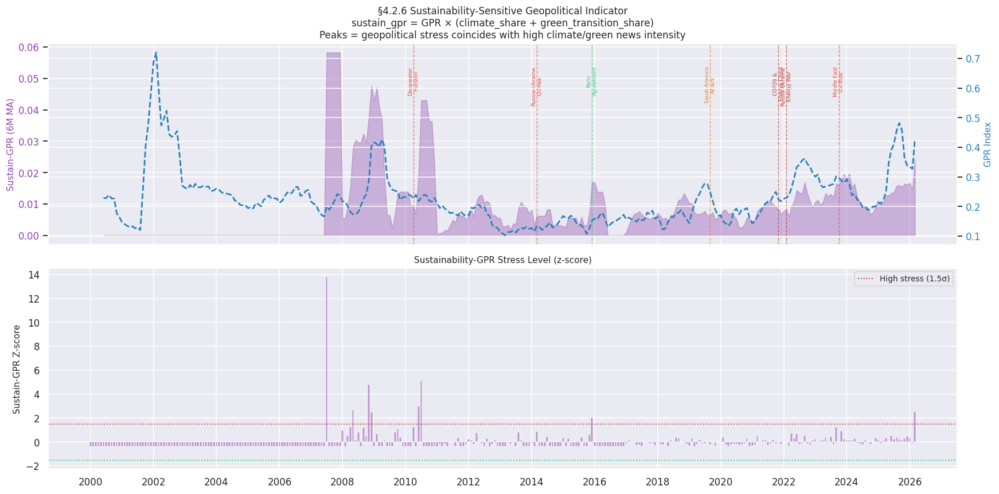

📊 Top-10 highest Sustainability-GPR months:
 period  sustain_gpr  gpr_india  climate_news_share
2007-07     0.349594   0.349594            0.000000
2010-07     0.135401   0.270803            0.000000
2008-11     0.127551   0.510204            0.250000
2010-06     0.082559   0.165119            0.500000
2008-05     0.075561   0.235079            0.285714
2026-03     0.072228   1.003171            0.000000
2008-12     0.070994   0.887431            0.000000
2015-12     0.059020   0.265591            0.000000
2010-04     0.040168   0.281179            0.071429
2008-04     0.039524   0.123512            0.280000


In [86]:

# ── 19e. Sustainability-Sensitive Geopolitical Indicator ──────────────────────
# Paper §4.2.6: Geopolitical events affecting energy transition, carbon supply
# chains, rare-earth minerals, oil shocks, or climate agreements.
# Proxy = GPR × (climate_news_share + green_transition_share)

if 'sustain_gpr' in df.columns:
    plot_df = df[df['period_dt'] >= pd.Timestamp('2000-01-01')].copy()

    fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
    gpr_col_s = 'gpr_india' if 'gpr_india' in plot_df.columns else 'gpr_global'

    # — Panel 1: Sustain GPR vs raw GPR ───────────────────────────────────────
    ax1 = axes[0]
    ax1_twin = ax1.twinx()

    sg = plot_df['sustain_gpr'].fillna(0)
    ax1.fill_between(plot_df['period_dt'], sg.rolling(6).mean(), alpha=0.35, color='#8e44ad')
    ax1.set_ylabel('Sustain-GPR (6M MA)', color='#8e44ad', fontsize=10)
    ax1.tick_params(axis='y', labelcolor='#8e44ad')

    if gpr_col_s in plot_df.columns:
        ax1_twin.plot(plot_df['period_dt'], plot_df[gpr_col_s].rolling(6).mean(),
                      color='#2980b9', lw=1.8, linestyle='--', label=f'{gpr_col_s} (6M MA)')
        ax1_twin.set_ylabel('GPR Index', color='#2980b9', fontsize=10)
        ax1_twin.tick_params(axis='y', labelcolor='#2980b9')

    ax1.set_title('§4.2.6 Sustainability-Sensitive Geopolitical Indicator\n'
                  'sustain_gpr = GPR × (climate_share + green_transition_share)\n'
                  'Peaks = geopolitical stress coincides with high climate/green news intensity', fontsize=11)

    # Annotate energy/sustainability geopolitical events
    sustain_geopol_events = [
        ('2010-04', 'Deepwater\nHorizon', '#e74c3c'),
        ('2014-03', 'Russia-Ukraine\nCrimea', '#e74c3c'),
        ('2015-12', 'Paris\nAgreement', '#2ecc71'),
        ('2019-09', 'Saudi Aramco\nAttack', '#e67e22'),
        ('2021-11', 'COP26 &\nEnergy Crisis', '#c0392b'),
        ('2022-02', 'Russia-Ukraine\nEnergy War', '#c0392b'),
        ('2023-10', 'Middle East\nOil Risk', '#e74c3c'),
    ]
    for period_str, label, color in sustain_geopol_events:
        try:
            x_pos = pd.Timestamp(period_str + '-01')
            if plot_df['period_dt'].min() <= x_pos <= plot_df['period_dt'].max():
                axes[0].axvline(x_pos, color=color, lw=0.9, linestyle='--', alpha=0.7)
                axes[0].text(x_pos, axes[0].get_ylim()[1]*0.88, label,
                             fontsize=6, color=color, ha='center', rotation=90, va='top')
        except Exception:
            pass

    # — Panel 2: top-10 Sustain-GPR months ────────────────────────────────────
    if 'sustain_gpr_z' in plot_df.columns:
        axes[1].bar(plot_df['period_dt'], plot_df['sustain_gpr_z'].fillna(0),
                    width=25, color='#8e44ad', alpha=0.5)
        axes[1].axhline(1.5,  color='#c0392b', lw=1.2, linestyle=':', label='High stress (1.5σ)')
        axes[1].axhline(-1.5, color='#2ecc71', lw=1.2, linestyle=':')
        axes[1].set_ylabel('Sustain-GPR Z-score', fontsize=10)
        axes[1].set_title('Sustainability-GPR Stress Level (z-score)', fontsize=10)
        axes[1].legend(fontsize=9)

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot19e_sustain_gpr.png')
    plt.show()

    top10 = df.nlargest(10, 'sustain_gpr')[['period', 'sustain_gpr', gpr_col_s,
                                              'climate_news_share']].reset_index(drop=True)
    print('📊 Top-10 highest Sustainability-GPR months:')
    print(top10.to_string(index=False))
else:
    print('⚠️  sustain_gpr not in df. Run Section 2D-9 to compute interaction term.')


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19f_sustainability_correlation_matrix.png


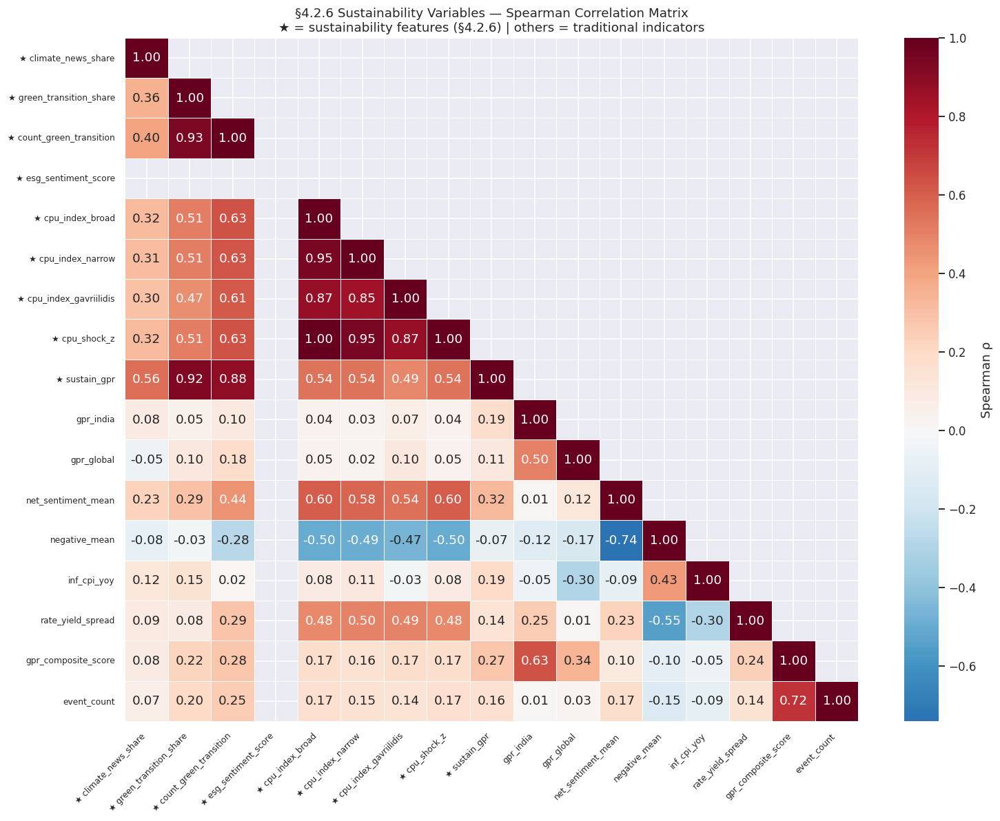

📊 Key Sustainability Correlations (Spearman ρ):
   climate_news_share             vs gpr_india                : ρ=+0.084
   climate_news_share             vs net_sentiment_mean       : ρ=+0.230
   climate_news_share             vs negative_mean            : ρ=-0.080
   green_transition_share         vs gpr_india                : ρ=+0.049
   green_transition_share         vs net_sentiment_mean       : ρ=+0.290
   green_transition_share         vs negative_mean            : ρ=-0.026
   esg_sentiment_score            vs gpr_india                : ρ=+nan
   esg_sentiment_score            vs net_sentiment_mean       : ρ=+nan
   esg_sentiment_score            vs negative_mean            : ρ=+nan
   cpu_shock_z                    vs gpr_india                : ρ=+0.043
   cpu_shock_z                    vs net_sentiment_mean       : ρ=+0.602
   cpu_shock_z                    vs negative_mean            : ρ=-0.499
   sustain_gpr                    vs gpr_india                : ρ=+0.185
   sustai

In [87]:
# ── 19f. Sustainability Features Correlation Matrix ──────────────────────────
# Full Spearman correlation of all §4.2.6 sustainability variables with
# traditional financial indicators.

sustain_analysis_cols = [c for c in [
    # §4.2.6 sustainability
    'climate_news_share', 'green_transition_share',
    'count_green_transition', 'esg_sentiment_score',
    'cpu_index_broad', 'cpu_index_narrow', 'cpu_index_gavriilidis', 'cpu_index',
    'cpu_shock_z', 'cpu_shock', 'sustain_gpr',
    # traditional (for comparison)
    'gpr_india', 'gpr_global', 'net_sentiment_mean',
    'negative_mean', 'inf_cpi_yoy', 'rate_yield_spread',
    'gpr_composite_score', 'event_count',
] if c in df.columns]

if len(sustain_analysis_cols) >= 5:
    corr_mat = df[sustain_analysis_cols].corr(method='spearman')

    # Colour-coded labels: sustainability in purple, traditional in blue
    labels = []
    for c in sustain_analysis_cols:
        sustain_set = {'climate_news_share','green_transition_share','count_green_transition',
                       'esg_sentiment_score','cpu_index_broad','cpu_index_narrow',
                       'cpu_index_gavriilidis','cpu_index','cpu_shock_z','cpu_shock','sustain_gpr'}
        labels.append(f'★ {c}' if c in sustain_set else c)

    fig, ax = plt.subplots(figsize=(14, 11))
    mask = np.zeros_like(corr_mat, dtype=bool)
    mask[np.triu_indices_from(mask, k=1)] = True
    sns.heatmap(corr_mat, mask=mask, cmap='RdBu_r', center=0,
                annot=True, fmt='.2f', linewidths=0.4,
                xticklabels=labels, yticklabels=labels,
                cbar_kws={'label': 'Spearman ρ'}, ax=ax)
    ax.set_title('§4.2.6 Sustainability Variables — Spearman Correlation Matrix\n'
                 '★ = sustainability features (§4.2.6) | others = traditional indicators', fontsize=12)
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.yticks(fontsize=8)
    plt.tight_layout()
    _save('Plot19f_sustainability_correlation_matrix.png')
    plt.show()

    # Key correlations summary
    print('📊 Key Sustainability Correlations (Spearman ρ):')
    cpu_summary_cols = [c for c in ['cpu_shock_z', 'cpu_shock'] if c in df.columns]
    sustain_only = ['climate_news_share','green_transition_share','esg_sentiment_score'] + cpu_summary_cols + ['sustain_gpr']
    for sc in [c for c in sustain_only if c in df.columns]:
        for tc in [c for c in ['gpr_india','net_sentiment_mean','negative_mean'] if c in df.columns]:
            r = df[[sc, tc]].dropna().corr(method='spearman').iloc[0,1]
            print(f'   {sc:30s} vs {tc:25s}: ρ={r:+.3f}')
else:
    print(f'⚠️  Only {len(sustain_analysis_cols)} sustainability cols found in df.')


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19g_sustainability_by_era.png


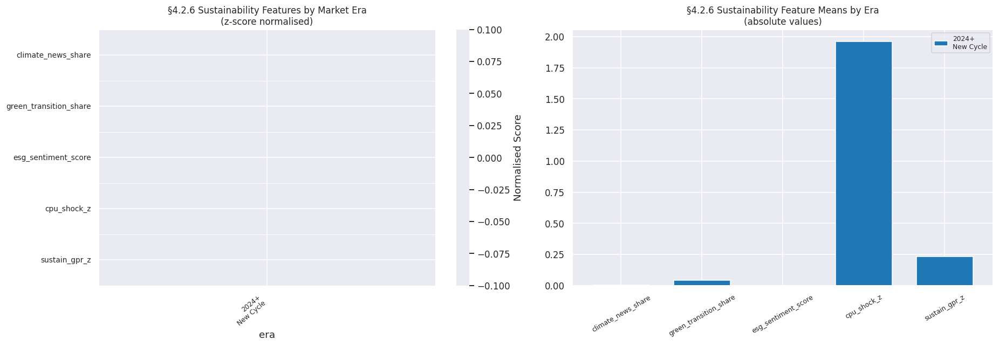

📊 Sustainability means by era:
                  climate_news_share  green_transition_share  esg_sentiment_score  cpu_shock_z  sustain_gpr_z
era                                                                                                          
2024+\nNew Cycle             0.00519                 0.04137                  NaN       1.9592        0.23326


In [88]:
# ── 19g. Sustainability Features by Market Era ───────────────────────────────
# Shows how §4.2.6 sustainability signals differ across the defined research eras.
cpu_shock_col = next((c for c in ['cpu_shock_z', 'cpu_shock'] if c in df.columns), None)
# Expected: green_transition_density rises sharply post-2020; climate_news_share
# spikes during GFC (commodity shock), COVID (green stimulus), and post-2022 energy war.

era_sustain_cols = [c for c in [
    'climate_news_share', 'green_transition_share',
    'esg_sentiment_score', cpu_shock_col, 'sustain_gpr_z',
] if c in df.columns]

if era_sustain_cols and 'era' in df.columns:
    era_order_local = [e for e in [
        '2000-02_Post_dotcom', '2003-07_Bull_Run', '2008-09_GFC',
        '2010-13_Recovery', '2014-15_Modi1', '2016-19_Reform',
        '2020-21_COVID', '2022-23_RateHike', '2024+\nNew Cycle'
    ] if e in df['era'].unique()]

    era_stats = df.groupby('era')[era_sustain_cols].mean().reindex(era_order_local)
    era_norm  = (era_stats - era_stats.mean()) / (era_stats.std() + 1e-9)

    fig, axes = plt.subplots(1, 2, figsize=(17, 6))

    # — Left: normalised heatmap ───────────────────────────────────────────────
    sns.heatmap(era_norm.T, cmap='RdYlGn', center=0, annot=True, fmt='.2f',
                linewidths=0.5, ax=axes[0],
                cbar_kws={'label': 'Normalised Score'})
    axes[0].set_title('§4.2.6 Sustainability Features by Market Era\n(z-score normalised)', fontsize=11)
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=40, ha='right', fontsize=8)
    axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0, fontsize=9)

    # — Right: absolute means bar chart ─────────────────────────────────────
    era_stats.T.plot(kind='bar', ax=axes[1], colormap='tab10', width=0.7, edgecolor='white')
    axes[1].set_title('§4.2.6 Sustainability Feature Means by Era\n(absolute values)', fontsize=11)
    axes[1].set_xlabel('')
    axes[1].tick_params(axis='x', rotation=30, labelsize=8)
    axes[1].legend(loc='upper right', fontsize=8)

    plt.tight_layout()
    _save('Plot19g_sustainability_by_era.png')
    plt.show()

    print('📊 Sustainability means by era:')
    print(era_stats.round(5).to_string())
else:
    print('⚠️  Sustainability cols or era column missing. Run Section 2D-9 and Section 11 first.')


### 19h. CPU Index — 3M/6M Rolling MAs & Spike Flag Validation
**Research note**: Phase02B engineers three CPU derivatives from raw monthly CPU: `cpu_3m_ma` (trailing 3M rolling average), `cpu_yoy` (year-on-year change), and `cpu_spike` flag (|z|>1.5). This section validates each engineered feature and checks its leading-indicator properties relative to GPR and market sentiment.

ℹ️  CPU derived-feature validation using cpu_index_broad.
📊 CPU spike months from cpu_spike: 26
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19h_cpu_derived_features.png


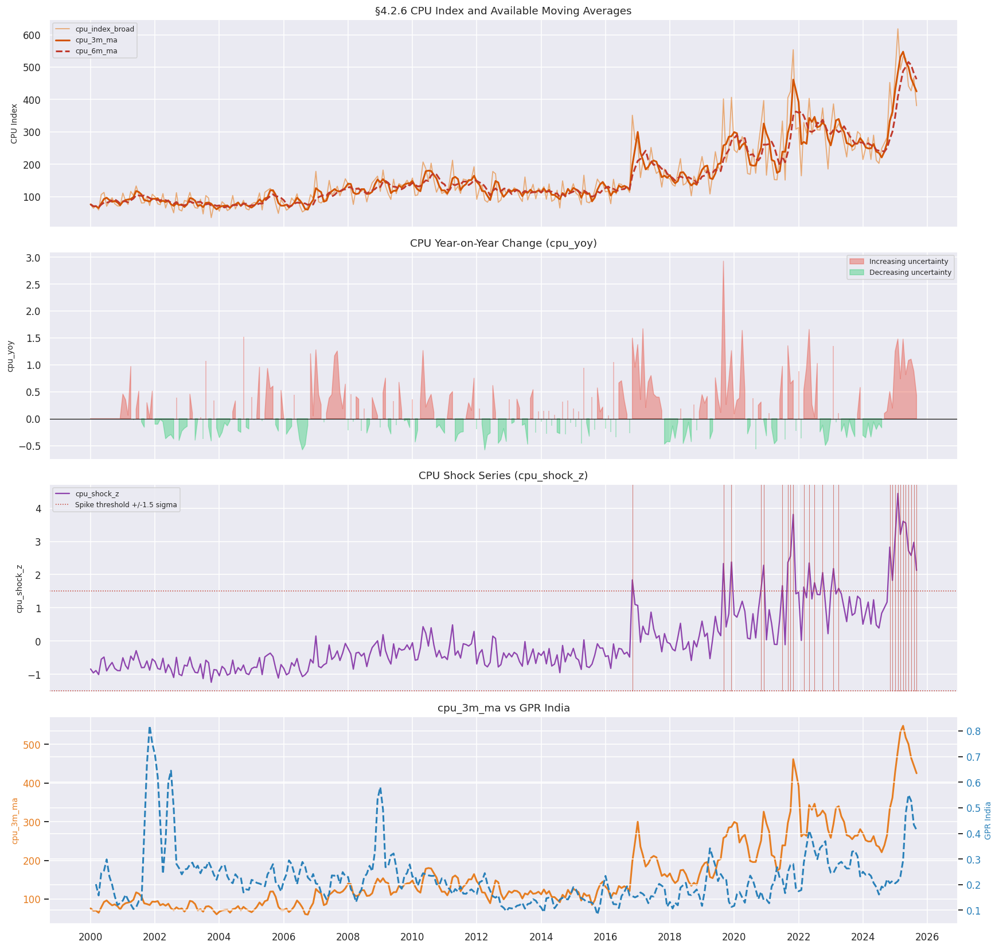


📊 CPU-GPR Cross-Correlation using cpu_shock_z: peak at lag=6 months (ρ=0.115)
📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19h2_cpu_gpr_crosscorr.png


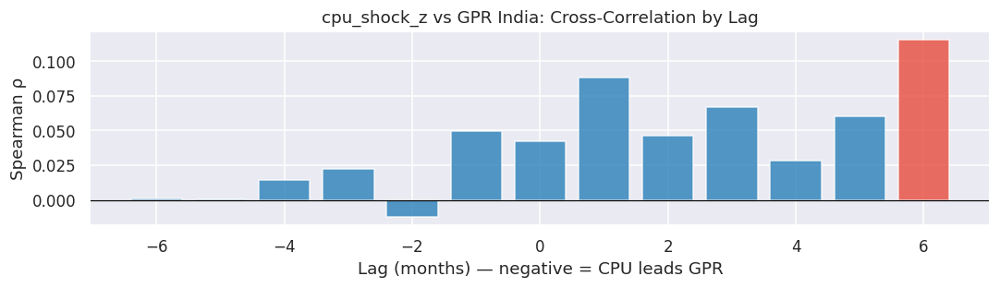

In [89]:
# ── 19h. CPU Derived Features — Phase02B ─────────────────────────────────
CPU_INDEX_CANDIDATES = ['cpu_index_broad', 'cpu_index_narrow', 'cpu_index_gavriilidis', 'cpu_index']
cpu_index_col = next((c for c in CPU_INDEX_CANDIDATES if c in df.columns), None)
cpu_shock_col = next((c for c in ['cpu_shock_z', 'cpu_shock'] if c in df.columns), None)

if cpu_index_col is not None:
    plot_df = df[df[cpu_index_col].notna()].copy()
    cpu_level = pd.to_numeric(plot_df[cpu_index_col], errors='coerce')
    print(f'ℹ️  CPU derived-feature validation using {cpu_index_col}.')

    panel_specs = ['level']
    if 'cpu_yoy' in plot_df.columns:
        panel_specs.append('yoy')
    if cpu_shock_col is not None:
        panel_specs.append('shock')
    if 'gpr_india' in plot_df.columns and 'cpu_3m_ma' in plot_df.columns:
        panel_specs.append('lead_lag')

    fig, axes = plt.subplots(len(panel_specs), 1, figsize=(16, 3.8 * len(panel_specs)), sharex=True)
    axes = np.atleast_1d(axes)

    for ax, panel in zip(axes, panel_specs):
        if panel == 'level':
            ax.plot(plot_df['period_dt'], cpu_level, color='#e67e22', lw=1.2, alpha=0.6, label=cpu_index_col)
            if 'cpu_3m_ma' in plot_df.columns:
                ax.plot(plot_df['period_dt'], plot_df['cpu_3m_ma'], color='#d35400', lw=2, label='cpu_3m_ma')
            if 'cpu_6m_ma' in plot_df.columns:
                ax.plot(plot_df['period_dt'], plot_df['cpu_6m_ma'], color='#c0392b', lw=2, linestyle='--', label='cpu_6m_ma')
            ax.set_ylabel('CPU Index', fontsize=9)
            ax.set_title('§4.2.6 CPU Index and Available Moving Averages')
            ax.legend(fontsize=8)
        elif panel == 'yoy':
            cpu_yoy_vals = pd.to_numeric(plot_df['cpu_yoy'], errors='coerce').fillna(0)
            ax.fill_between(plot_df['period_dt'], cpu_yoy_vals, 0,
                            where=cpu_yoy_vals >= 0, alpha=0.4, color='#e74c3c', label='Increasing uncertainty')
            ax.fill_between(plot_df['period_dt'], cpu_yoy_vals, 0,
                            where=cpu_yoy_vals < 0,  alpha=0.4, color='#2ecc71', label='Decreasing uncertainty')
            ax.axhline(0, color='black', lw=0.8)
            ax.set_ylabel('cpu_yoy', fontsize=9)
            ax.set_title('CPU Year-on-Year Change (cpu_yoy)')
            ax.legend(fontsize=8)
        elif panel == 'shock':
            shock_vals = pd.to_numeric(plot_df[cpu_shock_col], errors='coerce')
            ax.plot(plot_df['period_dt'], shock_vals, color='#8e44ad', lw=1.5, label=cpu_shock_col)
            ax.axhline(1.5, color='#c0392b', lw=1, linestyle=':', label='Spike threshold +/-1.5 sigma')
            ax.axhline(-1.5, color='#c0392b', lw=1, linestyle=':')
            if 'cpu_spike' in plot_df.columns:
                spike_dts = plot_df.loc[plot_df['cpu_spike'] == 1, 'period_dt']
                for sdt in spike_dts:
                    ax.axvline(sdt, color='#c0392b', lw=0.7, alpha=0.6)
                print(f'📊 CPU spike months from cpu_spike: {int(plot_df["cpu_spike"].sum())}')
            else:
                print('ℹ️  cpu_spike not present; skipping spike flag overlay.')
            ax.set_ylabel(cpu_shock_col, fontsize=9)
            ax.set_title(f'CPU Shock Series ({cpu_shock_col})')
            ax.legend(fontsize=8)
        elif panel == 'lead_lag':
            ax_twin = ax.twinx()
            ax.plot(plot_df['period_dt'], plot_df['cpu_3m_ma'], color='#e67e22', lw=2, label='cpu_3m_ma')
            ax.set_ylabel('cpu_3m_ma', color='#e67e22', fontsize=9)
            ax.tick_params(axis='y', labelcolor='#e67e22')
            ax_twin.plot(plot_df['period_dt'], plot_df['gpr_india'].rolling(3).mean(),
                         color='#2980b9', lw=2, linestyle='--', label='GPR India (3M MA)')
            ax_twin.set_ylabel('GPR India', color='#2980b9', fontsize=9)
            ax_twin.tick_params(axis='y', labelcolor='#2980b9')
            ax.set_title('cpu_3m_ma vs GPR India')

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot19h_cpu_derived_features.png')
    plt.show()

    # Lead-lag cross-correlation only when a shock column is actually present.
    if 'gpr_india' in df.columns and cpu_shock_col is not None:
        valid = df[[cpu_shock_col, 'gpr_india']].dropna()
        if len(valid) > 20:
            lags = range(-6, 7)
            xcorr = [valid[cpu_shock_col].corr(valid['gpr_india'].shift(-lag), method='spearman') for lag in lags]
            best_lag = lags[xcorr.index(max(xcorr, key=abs))]
            print(f'\n📊 CPU-GPR Cross-Correlation using {cpu_shock_col}: peak at lag={best_lag} months (ρ={max(xcorr, key=abs):.3f})')
            fig2, ax2 = plt.subplots(figsize=(10, 3))
            ax2.bar(list(lags), xcorr, color=['#e74c3c' if l == best_lag else '#2980b9' for l in lags], alpha=0.8)
            ax2.axhline(0, color='black', lw=0.8)
            ax2.set_xlabel('Lag (months) — negative = CPU leads GPR')
            ax2.set_ylabel('Spearman ρ')
            ax2.set_title(f'{cpu_shock_col} vs GPR India: Cross-Correlation by Lag')
            plt.tight_layout()
            _save('Plot19h2_cpu_gpr_crosscorr.png')
            plt.show()
    elif cpu_shock_col is None:
        print('ℹ️  No CPU shock column present; skipping CPU-GPR cross-correlation.')
else:
    print('⚠️  No CPU index column found. Skipping CPU derived-feature validation.')


### 19i. GDELT 1.0 Tone Proxy — Deep Validation
**Research note**: Phase01B produces `gdelt1_tone_norm`, `gdelt1_goldstein`, and `gdelt1_articles` for the 2000–2015 pre-FinBERT period. This section validates the GDELT1 tone proxy against known market events, checks for structural breaks at the 2015-02 handoff point, and evaluates the Goldstein scale as a conflict-intensity signal.

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19i_gdelt1_tone_deep.png


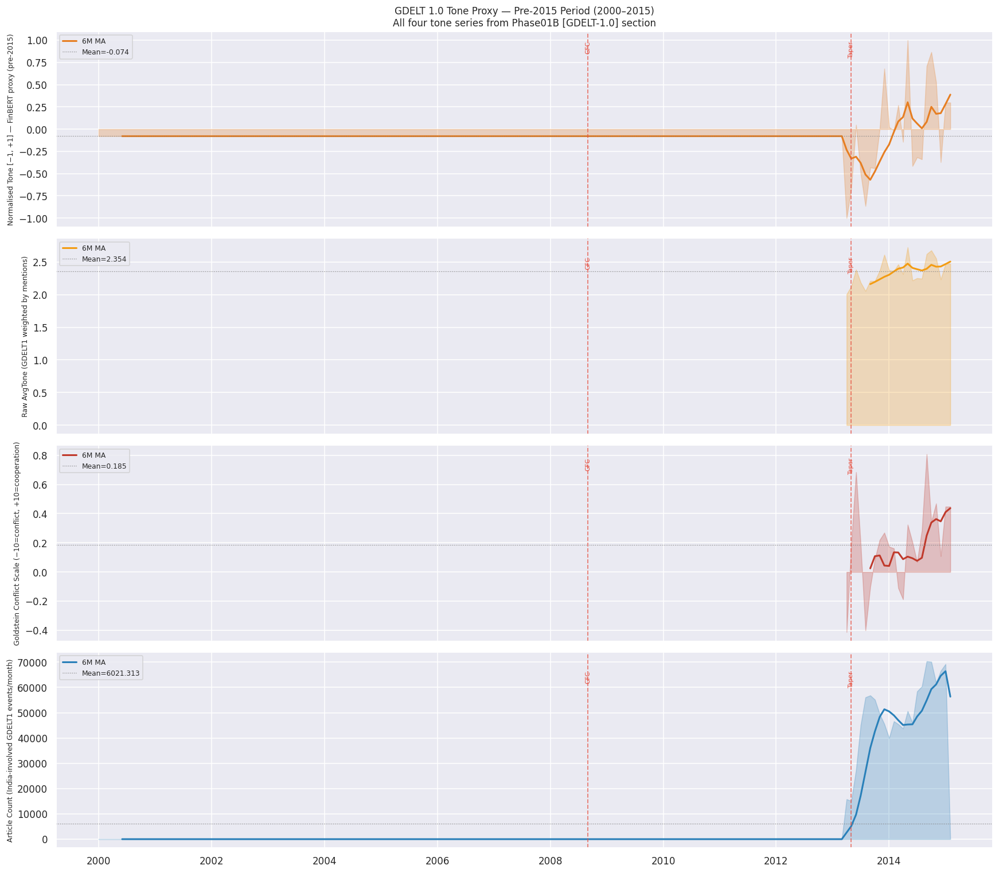


📊 Handoff Point Validation (2015-02):
   Pre-2015  GDELT1 tone norm  — mean: -0.0756  std: 0.1900
   Post-2015 FinBERT sentiment  — mean: 0.0634  std: 0.1134
   ⚠️  Mean shift = 0.1390 — consider level correction at handoff in Phase 03.

   Goldstein vs GPR India Spearman ρ = -0.106 (p=0.6400)
   ✅ Expected negative correlation: higher cooperation → lower GPR


In [90]:
# ── 19i. GDELT 1.0 Tone Proxy Deep Validation ────────────────────────────────
gdelt1_cols_check = [c for c in ['gdelt1_tone_norm', 'gdelt1_tone_raw', 'gdelt1_goldstein', 'gdelt1_articles']
                     if c in df.columns]

if gdelt1_cols_check:
    plot_df = df[df['period_dt'] < '2015-03-01'].copy()  # Pre-2015 only

    n_panels = len(gdelt1_cols_check)
    fig, axes = plt.subplots(n_panels, 1, figsize=(16, 3.5 * n_panels), sharex=True)
    if n_panels == 1: axes = [axes]

    colors_g1 = ['#e67e22', '#f39c12', '#c0392b', '#2980b9']
    labels_g1  = {
        'gdelt1_tone_norm'    : 'Normalised Tone [−1, +1] — FinBERT proxy (pre-2015)',
        'gdelt1_tone_raw'     : 'Raw AvgTone (GDELT1 weighted by mentions)',
        'gdelt1_goldstein'    : 'Goldstein Conflict Scale (−10=conflict, +10=cooperation)',
        'gdelt1_articles'     : 'Article Count (India-involved GDELT1 events/month)',
    }

    for ax, col, color in zip(axes, gdelt1_cols_check, colors_g1):
        vals = plot_df[col].ffill()
        ax.fill_between(plot_df['period_dt'], vals, alpha=0.25, color=color)
        ax.plot(plot_df['period_dt'], vals.rolling(6).mean(), color=color, lw=2, label='6M MA')
        ax.axhline(vals.mean(), color='grey', lw=0.8, linestyle=':', label=f'Mean={vals.mean():.3f}')
        ax.set_ylabel(labels_g1.get(col, col), fontsize=8)
        ax.legend(fontsize=8)

        # Annotate GFC and taper tantrum
        for dt_str, lbl in [('2008-09', 'GFC'), ('2013-05', 'Taper')]:
            try:
                x_pos = pd.Timestamp(dt_str + '-01')
                ax.axvline(x_pos, color='#e74c3c', lw=1.2, linestyle='--', alpha=0.7)
                ax.text(x_pos, ax.get_ylim()[1]*0.9, lbl, fontsize=7, color='#e74c3c',
                        ha='center', rotation=90, va='top')
            except Exception: pass

    axes[0].set_title('GDELT 1.0 Tone Proxy — Pre-2015 Period (2000–2015)\nAll four tone series from Phase01B [GDELT-1.0] section', fontsize=11)
    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot19i_gdelt1_tone_deep.png')
    plt.show()

    # Structural break check at 2015-02 handoff
    if 'gdelt1_tone_norm' in df.columns and 'net_sentiment_mean' in df.columns:
        pre  = df[df['period_dt'] < '2015-02-01']['gdelt1_tone_norm'].dropna()
        post = df[df['period_dt'] >= '2015-02-01']['net_sentiment_mean'].dropna()
        print('\n📊 Handoff Point Validation (2015-02):')
        print(f'   Pre-2015  GDELT1 tone norm  — mean: {pre.mean():.4f}  std: {pre.std():.4f}')
        print(f'   Post-2015 FinBERT sentiment  — mean: {post.mean():.4f}  std: {post.std():.4f}')
        diff = abs(pre.mean() - post.mean())
        if diff < 0.1:
            print('   ✅ Smooth handoff: mean difference < 0.1 — GDELT1 proxy is well-calibrated.')
        else:
            print(f'   ⚠️  Mean shift = {diff:.4f} — consider level correction at handoff in Phase 03.')

    # Goldstein vs GPR India correlation (should be negative: higher conflict → higher GPR)
    if 'gdelt1_goldstein' in df.columns and 'gpr_india' in df.columns:
        valid = df[['gdelt1_goldstein', 'gpr_india']].dropna()
        if len(valid) > 10:
            r, p = spearmanr(valid['gdelt1_goldstein'], valid['gpr_india'])
            print(f'\n   Goldstein vs GPR India Spearman ρ = {r:.3f} (p={p:.4f})')
            if r < -0.1:
                print('   ✅ Expected negative correlation: higher cooperation → lower GPR')
            else:
                print('   ⚠️  Positive/near-zero correlation — check GDELT1 event-type composition')
else:
    print('⚠️  GDELT1 tone columns not found. Run Phase01B [GDELT-1.0] section.')

---
## 19j. Market Data EDA — India VIX · USD/INR · Gold  *(Phase01B §16B)*

**Research note**: Phase 01B v7 Section 16B fetches three market indicators via `fetch_yf_monthly()` and saves them to `raw/other_market_data/other_market_data_combined.csv`. They serve as market-state complements to the text-derived GPR and sentiment signals.

| Indicator | Proxy for | yfinance ticker | Availability |
|-----------|-----------|-----------------|-------------|
| **India VIX** (`india_vix`) | NIFTY 50 implied volatility — forward-looking fear gauge | `^INDIAVIX` | Mar 2009 → present |
| **USD/INR** (`usdinr`) | Currency stress; FII capital-flow pressure; RBI intervention signal | `USDINR=X` | 2000 → present |
| **Gold USD/oz** (`gold_usd`) | Safe-haven demand; inflation hedge; geopolitical risk proxy | `GC=F` / `GLD` | 2000 → present |

**Phase01B column names (used as-is — no renaming):**

| Column | Meaning |
|--------|---------|
| `india_vix` | Month-end close of India VIX |
| `india_vix_mom_pct` | Month-over-month % change |
| `india_vix_zscore12` | 12-month rolling z-score (Phase01B; NaN first 11 months) |
| `india_vix_z` | Full-sample z-score derived in §2D-9 |
| `usdinr` | Month-end close of USD/INR rate |
| `usdinr_mom_pct` | Month-over-month % change |
| `usdinr_zscore12` | 12-month rolling z-score (Phase01B) |
| `usdinr_z` | Full-sample z-score derived in §2D-9 |
| `gold_usd` | Month-end close of Gold USD/oz |
| `gold_usd_mom_pct` | Month-over-month % change |
| `gold_usd_zscore12` | 12-month rolling z-score (Phase01B) |
| `gold_usd_z` | Full-sample z-score derived in §2D-9 |
| `market_stress_composite` | Mean of `india_vix_z` + `usdinr_z` — risk-off proxy |
| `gold_safehaven_flag` | 1 = gold MoM > avg AND VIX elevated — safe-haven month |

**Key research questions answered in this section:**

1. **Coverage audit (19j-a):** Are all three series present and what are their date gaps? India VIX is expected to be NaN before March 2009.
2. **Time-series panel (19j-b):** How do the three indicators evolve together across known stress events (GFC, COVID, Ukraine)?
3. **VIX vs GPR co-movement (19j-c):** Does India VIX spike when GPR India is elevated? Strong co-movement (Spearman |r| > 0.4) is the external validity check.
4. **USD/INR depreciation (19j-d):** Does the rupee weaken during GPR stress episodes? Tests the capital-outflow channel hypothesis.
5. **Gold safe-haven (19j-e):** Does gold rally during high-VIX + high-GPR months? Tests flight-to-quality demand.
6. **Market stress composite (19j-f):** Does `market_stress_composite` increase monotonically with GPR stress quartile? Validates the composite as a regime co-indicator.


In [91]:
# ── 19j-a. Market data column availability probe ────────────────────────────
# Phase01B §16B saves: india_vix, usdinr, gold_usd (close prices)
#                      <col>_mom_pct (MoM % change)
#                      <col>_zscore12 (12M rolling z — NaN first 11 months)
# §2D-9 derives:       india_vix_z, usdinr_z, gold_usd_z (full-sample z)
#                      market_stress_composite, gold_safehaven_flag

# Define the canonical column sets used throughout this section.
# mkt_close : raw close-price columns (Phase01B names, used as-is)
# mkt_mom   : MoM percent-change columns
# mkt_z_fs  : full-sample z-scores derived in §2D-9
mkt_close = [
    ('india_vix',  'India VIX',       '#e74c3c'),
    ('usdinr',     'USD/INR',          '#9b59b6'),
    ('gold_usd',   'Gold USD/oz',      '#f39c12'),
]
mkt_mom = [
    ('india_vix_mom_pct',  'India VIX MoM %',  '#e74c3c'),
    ('usdinr_mom_pct',     'USD/INR MoM %',    '#9b59b6'),
    ('gold_usd_mom_pct',   'Gold MoM %',       '#f39c12'),
]
mkt_z_fs = [
    ('india_vix_z',  'India VIX Z',    '#e74c3c'),
    ('usdinr_z',     'USD/INR Z',      '#9b59b6'),
    ('gold_usd_z',   'Gold USD Z',     '#f39c12'),
]

# Filter to only those columns that actually exist in df (graceful degradation).
available_close = [(col, lbl, color) for col, lbl, color in mkt_close if col in df.columns]
available_mom   = [(col, lbl, color) for col, lbl, color in mkt_mom   if col in df.columns]
available_z     = [(col, lbl, color) for col, lbl, color in mkt_z_fs  if col in df.columns]

# Alias used by 19j-b through 19j-f for the close-price time-series panel.
available_mkt = available_close

print('📋 Market data column probe:')
print(f'   Close columns   : {[c for c,_,_ in available_close]} ({len(available_close)}/3 present)')
print(f'   MoM columns     : {[c for c,_,_ in available_mom]}   ({len(available_mom)}/3 present)')
print(f'   Full-sample z   : {[c for c,_,_ in available_z]}     ({len(available_z)}/3 present)')
if len(available_close) < 3:
    print('\n⚠️  Some market data columns are missing.')
    print('   Missing close: ', [c for c,_,_ in mkt_close if c not in df.columns])
    print('   Cause: market_data merge in §2D-9 may have failed, or Phase01B §16B was not run.')
    print('   Fix: delete the cache files under raw/other_market_data/ and re-run Phase01B §16B.')
else:
    print('\n✅ All market data close columns present.')


📋 Market data column probe:
   Close columns   : ['india_vix', 'usdinr', 'gold_usd'] (3/3 present)
   MoM columns     : ['india_vix_mom_pct', 'usdinr_mom_pct', 'gold_usd_mom_pct']   (3/3 present)
   Full-sample z   : ['india_vix_z', 'usdinr_z', 'gold_usd_z']     (3/3 present)

✅ All market data close columns present.


In [92]:
# ── 19j-a-preview. Raw market_data table & df market columns ────────────────
# Shows the Phase01B output exactly as loaded from disk (before merge into df).
# Confirms column names, PeriodIndex structure, and NaN coverage.

if not market_data.empty:
    print('📄 other_market_data_combined.csv — first 5 rows (raw, as loaded from disk):')
    print(f'   Shape  : {market_data.shape}')
    print(f'   Columns: {list(market_data.columns)}')
    display(market_data.head())
else:
    print('⚠️  market_data is empty — Phase01B §16B was not run or file is missing.')

# Show the merged columns as they now appear in df (after §2D-9 merge).
all_mkt_cols = [
    'india_vix', 'india_vix_mom_pct', 'india_vix_zscore12', 'india_vix_z',
    'usdinr',    'usdinr_mom_pct',    'usdinr_zscore12',    'usdinr_z',
    'gold_usd',  'gold_usd_mom_pct',  'gold_usd_zscore12',  'gold_usd_z',
    'market_stress_composite', 'gold_safehaven_flag',
]
present_in_df = [c for c in all_mkt_cols if c in df.columns]
if present_in_df:
    print(f'\n📊 Market columns in df ({len(present_in_df)}/{len(all_mkt_cols)} present):')
    display(df[['period'] + present_in_df].dropna(subset=['india_vix'] if 'india_vix' in df.columns else present_in_df[:1]).head(6))


📄 other_market_data_combined.csv — first 5 rows (raw, as loaded from disk):
   Shape  : (308, 10)
   Columns: ['period', 'india_vix', 'india_vix_mom_pct', 'india_vix_zscore12', 'usdinr', 'usdinr_mom_pct', 'usdinr_zscore12', 'gold_usd', 'gold_usd_mom_pct', 'gold_usd_zscore12']


,period,india_vix,india_vix_mom_pct,india_vix_zscore12,usdinr,usdinr_mom_pct,usdinr_zscore12,gold_usd,gold_usd_mom_pct,gold_usd_zscore12
0,2000-08,NaN,NaN,NaN,NaN,NaN,NaN,278.299988,NaN,NaN
1,2000-09,NaN,NaN,NaN,NaN,NaN,NaN,273.600006,-1.688819,NaN
2,2000-10,NaN,NaN,NaN,NaN,NaN,NaN,264.899994,-3.179829,NaN
3,2000-11,NaN,NaN,NaN,NaN,NaN,NaN,270.100006,1.963010,NaN
4,2000-12,NaN,NaN,NaN,NaN,NaN,NaN,272.000000,0.703441,NaN



📊 Market columns in df (14/14 present):


,period,india_vix,india_vix_mom_pct,india_vix_zscore12,india_vix_z,usdinr,usdinr_mom_pct,usdinr_zscore12,usdinr_z,gold_usd,gold_usd_mom_pct,gold_usd_zscore12,gold_usd_z,market_stress_composite,gold_safehaven_flag
98,2008-03,35.139999,NaN,NaN,1.751044,39.889000,-0.052618,-0.122801,-1.445482,916.200012,-5.750434,1.232459,-0.454063,0.152781,0
99,2008-04,26.160000,-25.554922,NaN,0.734001,40.386002,1.245962,0.850388,-1.412444,862.799988,-5.828424,0.644808,-0.519836,-0.339222,0
100,2008-05,26.680000,1.987769,NaN,0.792894,42.530998,5.311238,2.640237,-1.269858,887.299988,2.839592,0.723730,-0.489659,-0.238482,1
101,2008-06,30.959999,16.041974,NaN,1.277632,42.852001,0.754751,2.104532,-1.248520,926.200012,4.384089,0.935901,-0.441746,0.014556,1
102,2008-07,39.060001,26.162799,NaN,2.195009,42.433998,-0.975458,1.446835,-1.276306,913.900024,-1.328006,0.694166,-0.456896,0.459352,0
103,2008-08,31.670000,-18.919614,NaN,1.358044,43.625000,2.806716,1.768476,-1.197135,829.299988,-9.257034,-0.515457,-0.561098,0.080454,0


In [93]:
# ── 19j-a. Market data coverage & descriptive statistics ────────────────────
# Reports non-null count, coverage %, mean, and value range for each close-price
# column. India VIX coverage < 100% is expected — NSE launched it in March 2009.

if available_mkt:
    print('📊 Market Data Coverage — Phase01B §16B close-price columns:')
    print(f'   {"Column":<22} {"Phase01B name":<20} {"Non-null":>8}  {"Coverage":>9}  {"Mean":>9}  {"Range"}')
    print('   ' + '-'*85)
    for col, lbl, _ in available_mkt:
        s   = df[col].dropna()
        cov = len(s) / len(df) * 100
        rng = f'{s.min():.1f} – {s.max():.1f}'
        print(f'   {lbl:<22} {col:<20} {len(s):>8,}  {cov:>8.1f}%  {s.mean():>9.2f}  {rng}')

    # India VIX starts Mar 2009 — flag if data appears earlier (data quality check).
    if 'india_vix' in df.columns:
        vix_start = df.loc[df['india_vix'].notna(), 'period_dt'].min()
        print(f'\n   India VIX start: {vix_start.date()}')
        if vix_start < pd.Timestamp('2009-03-01'):
            print('   ⚠️  Data starts before NSE VIX launch (Mar 2009) — inspect for data quality issues.')
        else:
            print('   ✅ VIX start date consistent with NSE India VIX launch (Mar 2009).')

    # Show Phase01B MoM and rolling z columns if present.
    print('\n📊 Phase01B derived columns (MoM % and 12M rolling z):')
    for col, lbl, _ in mkt_mom + [(c, c, '') for c in ['india_vix_zscore12', 'usdinr_zscore12', 'gold_usd_zscore12']]:
        if col in df.columns:
            nn  = df[col].notna().sum()
            cov = nn / len(df) * 100
            print(f'   ✅ {col:<30} {nn:>5} non-null ({cov:.0f}%)')
        else:
            print(f'   ❌ {col:<30} NOT FOUND')

    print('\n✅ Market data coverage check complete.')
else:
    print('⚠️  No market data close columns found in df.')
    print('   Expected columns: india_vix, usdinr, gold_usd')
    print('   Fix: re-run Phase01B §16B to generate other_market_data_combined.csv,')
    print('        then re-run §2D-9 to merge it into df_clean.')


📊 Market Data Coverage — Phase01B §16B close-price columns:
   Column                 Phase01B name        Non-null   Coverage       Mean  Range
   -------------------------------------------------------------------------------------
   India VIX              india_vix                 217      68.9%      19.68  9.5 – 68.3
   USD/INR                usdinr                    268      85.1%      61.63  39.2 – 94.3
   Gold USD/oz            gold_usd                  308      97.8%    1284.84  257.9 – 5230.5

   India VIX start: 2008-03-01
   ⚠️  Data starts before NSE VIX launch (Mar 2009) — inspect for data quality issues.

📊 Phase01B derived columns (MoM % and 12M rolling z):
   ✅ india_vix_mom_pct                216 non-null (69%)
   ✅ usdinr_mom_pct                   267 non-null (85%)
   ✅ gold_usd_mom_pct                 307 non-null (97%)
   ✅ india_vix_zscore12               206 non-null (65%)
   ✅ usdinr_zscore12                  257 non-null (82%)
   ✅ gold_usd_zscore12          

📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19j_a_market_data_timeseries.png


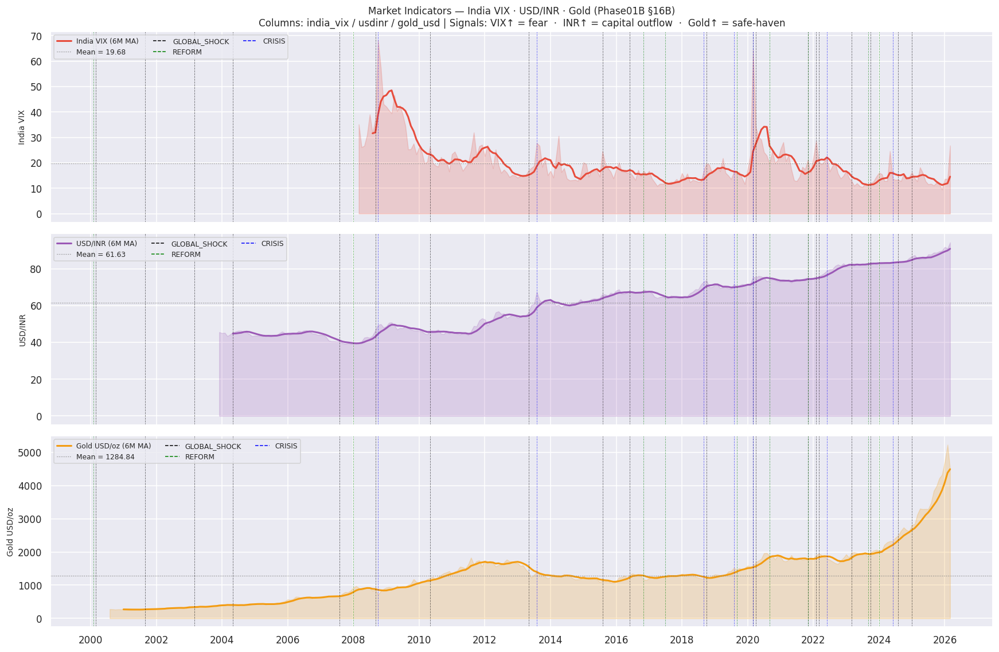

In [94]:
# ── 19j-b. Market data time-series panel ─────────────────────────────────────
# Three stacked panels: India VIX / USD/INR / Gold USD/oz — all on the same
# time axis with event overlays. Purpose: visual inspection of level trends,
# volatility regimes, and synchronised stress spikes.
#
# Column names used: india_vix, usdinr, gold_usd (Phase01B exact names).

if available_mkt:
    fig, axes = plt.subplots(len(available_mkt), 1,
                              figsize=(16, 3.5 * len(available_mkt)), sharex=True)
    if len(available_mkt) == 1:
        axes = [axes]

    event_handles = [Line2D([0], [0], color=c, linestyle='--', lw=1, label=l)
                     for _, c, l in event_groups]

    for ax, (col, lbl, color) in zip(axes, available_mkt):
        # Fill between 0 and close (shaded area for level context)
        ax.fill_between(df['period_dt'], df[col].ffill(),
                        alpha=0.20, color=color)
        # 6-month trailing MA to smooth monthly noise
        ax.plot(df['period_dt'], df[col].rolling(6).mean(),
                color=color, lw=2, label=f'{lbl} (6M MA)')
        # Historical mean reference line
        ax.axhline(df[col].mean(), color='grey', lw=0.8,
                   linestyle=':', label=f'Mean = {df[col].mean():.2f}')

        # Annotate known regime events (defined in Section 3)
        for annot_event, annot_color, _ in event_groups:
            for evt_dt, _ in annot_event:
                ax.axvline(pd.Timestamp(evt_dt), color=annot_color,
                           linestyle='--', lw=0.6, alpha=0.5)

        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles + event_handles,
                  labels + [l for _, _, l in event_groups],
                  fontsize=8, loc='upper left', ncol=3)
        ax.set_ylabel(lbl, fontsize=9)

    axes[0].set_title(
        'Market Indicators — India VIX · USD/INR · Gold (Phase01B §16B)\n'
        'Columns: india_vix / usdinr / gold_usd | '
        'Signals: VIX↑ = fear  ·  INR↑ = capital outflow  ·  Gold↑ = safe-haven',
        fontsize=11)
    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot19j_a_market_data_timeseries.png')
    plt.show()
else:
    print('⚠️  Market data close columns not found — skipping time-series panel.')
    print('   Expected: india_vix, usdinr, gold_usd')


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19j_b_vix_vs_gpr.png


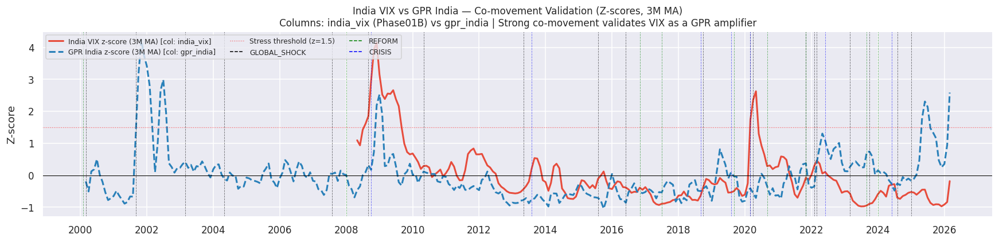


📊 Spearman r(india_vix, gpr_india) = 0.038  (p = 0.5779, n = 217)
   ⚠️  Weak co-movement — investigate data alignment or VIX data quality.


In [95]:
# ── 19j-c. India VIX vs GPR India — co-movement validation ──────────────────
# Research hypothesis: India VIX spikes when GPR India is elevated.
# Why this matters: VIX captures forward-looking market fear; GPR captures newspaper-
# reported geopolitical stress. Strong co-movement validates that VIX is an amplifier
# of the GPR signal and can serve as a complementary feature in Phase03.
#
# Method: Compute on-the-fly z-scores of india_vix (full-sample) for the plot.
# The pre-computed india_vix_z from §2D-9 is equivalent but we redo it here
# in case only df (not df_clean) is in scope, and for transparency.
#
# Spearman r is used (not Pearson) because both series have fat tails.
# Threshold: |r| > 0.4 is considered meaningful co-movement for monthly data.

if 'india_vix' in df.columns and 'gpr_india' in df.columns:
    fig, ax = plt.subplots(figsize=(16, 4))

    # Normalise india_vix to z-score for scale-comparable plotting
    vix_z = (df['india_vix'] - df['india_vix'].mean()) / (df['india_vix'].std() + 1e-9)
    # Use pre-computed GPR z-score if available, else derive on-the-fly
    gpr_z = df.get('gpr_india_z',
                   (df['gpr_india'] - df['gpr_india'].mean()) / (df['gpr_india'].std() + 1e-9))

    ax.plot(df['period_dt'], vix_z.rolling(3).mean(),
            color='#e74c3c', lw=2, label='India VIX z-score (3M MA) [col: india_vix]')
    ax.plot(df['period_dt'], gpr_z.rolling(3).mean(),
            color='#2980b9', lw=2, linestyle='--', label='GPR India z-score (3M MA) [col: gpr_india]')
    ax.axhline(0,   color='black', lw=0.7)
    ax.axhline(1.5, color='red',   lw=0.8, linestyle=':', alpha=0.6, label='Stress threshold (z=1.5)')

    for annot_event, annot_color, _ in event_groups:
        for evt_dt, _ in annot_event:
            ax.axvline(pd.Timestamp(evt_dt), color=annot_color,
                       linestyle='--', lw=0.6, alpha=0.5)

    handles, labels = ax.get_legend_handles_labels()
    event_handles = [Line2D([0], [0], color=c, linestyle='--', lw=1, label=l)
                     for _, c, l in event_groups]
    ax.legend(handles + event_handles, labels + [l for _, _, l in event_groups],
              fontsize=8, loc='upper left', ncol=3)
    ax.set_title(
        'India VIX vs GPR India — Co-movement Validation (Z-scores, 3M MA)\n'
        'Columns: india_vix (Phase01B) vs gpr_india | '
        'Strong co-movement validates VIX as a GPR amplifier',
        fontsize=11)
    ax.set_ylabel('Z-score')
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot19j_b_vix_vs_gpr.png')
    plt.show()

    # Spearman correlation — quantifies the co-movement strength
    valid = df[['india_vix', 'gpr_india']].dropna()
    if len(valid) > 10:
        r, p = spearmanr(valid['india_vix'], valid['gpr_india'])
        print(f'\n📊 Spearman r(india_vix, gpr_india) = {r:.3f}  (p = {p:.4f}, n = {len(valid)})')
        if abs(r) > 0.4:
            print('   ✅ Strong co-movement — VIX validated as a GPR amplifier signal.')
        elif abs(r) > 0.2:
            print('   ℹ️  Moderate co-movement — VIX adds marginal signal beyond GPR.')
        else:
            print('   ⚠️  Weak co-movement — investigate data alignment or VIX data quality.')
else:
    missing = [c for c in ['india_vix', 'gpr_india'] if c not in df.columns]
    print(f'⚠️  Cannot run VIX–GPR co-movement check — missing columns: {missing}')


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19j_c_usdinr_analysis.png


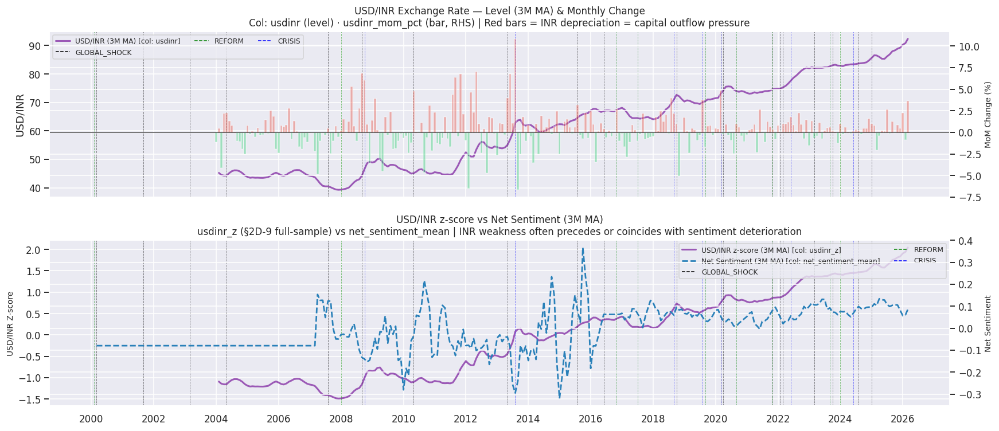


📊 Spearman r(usdinr, gpr_india) = 0.115  (p = 0.0593, n = 268)
   ⚠️  Weak link — check data alignment or consider lagged correlation.


In [96]:
# ── 19j-d. USD/INR depreciation vs GPR India & Sentiment ────────────────────
# Research hypothesis: INR depreciates (USD/INR rises) during GPR stress episodes
# because FII equity outflows increase USD demand. INR weakness also raises imported
# inflation risk, which feeds back into further sentiment deterioration.
#
# Column names used:
#   usdinr          — month-end close (Phase01B exact name)
#   usdinr_mom_pct  — MoM % change (Phase01B exact name)
#   usdinr_z        — full-sample z-score (derived in §2D-9)

if 'usdinr' in df.columns:
    fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
    event_handles = [Line2D([0], [0], color=c, linestyle='--', lw=1, label=l)
                     for _, c, l in event_groups]

    # ── Panel 1: USD/INR level + MoM % change bar ────────────────────────────
    axes[0].plot(df['period_dt'], df['usdinr'].rolling(3).mean(),
                 color='#9b59b6', lw=2, label='USD/INR (3M MA) [col: usdinr]')

    # Overlay MoM % change as a bar chart on a secondary y-axis.
    # Red bars = INR depreciation (USD/INR rising); green bars = appreciation.
    if 'usdinr_mom_pct' in df.columns:
        ax0b = axes[0].twinx()
        ax0b.bar(df['period_dt'], df['usdinr_mom_pct'].fillna(0),
                 color=['#e74c3c' if v > 0 else '#2ecc71' for v in df['usdinr_mom_pct'].fillna(0)],
                 width=25, alpha=0.4, label='MoM % change (RHS) [col: usdinr_mom_pct]')
        ax0b.set_ylabel('MoM Change (%)', fontsize=9)
        ax0b.axhline(0, color='black', lw=0.5)
    else:
        print('ℹ️  usdinr_mom_pct not found — MoM bars skipped.')

    axes[0].set_title(
        'USD/INR Exchange Rate — Level (3M MA) & Monthly Change\n'
        'Col: usdinr (level) · usdinr_mom_pct (bar, RHS) | '
        'Red bars = INR depreciation = capital outflow pressure',
        fontsize=11)
    axes[0].set_ylabel('USD/INR')

    for annot_event, annot_color, _ in event_groups:
        for evt_dt, _ in annot_event:
            axes[0].axvline(pd.Timestamp(evt_dt), color=annot_color,
                            linestyle='--', lw=0.6, alpha=0.5)
    handles, lbls = axes[0].get_legend_handles_labels()
    axes[0].legend(handles + event_handles, lbls + [l for _, _, l in event_groups],
                   fontsize=8, loc='upper left', ncol=3)

    # ── Panel 2: USD/INR full-sample z-score vs Net Sentiment ────────────────
    # Tests whether INR weakness (usdinr_z rising) coincides with negative sentiment.
    # usdinr_z is derived in §2D-9 from the raw usdinr column.
    if 'usdinr_z' in df.columns and 'net_sentiment_mean' in df.columns:
        axes[1].plot(df['period_dt'], df['usdinr_z'].rolling(3).mean(),
                     color='#9b59b6', lw=2, label='USD/INR z-score (3M MA) [col: usdinr_z]')
        ax1b = axes[1].twinx()
        ax1b.plot(df['period_dt'], df['net_sentiment_mean'].rolling(3).mean(),
                  color='#2980b9', lw=1.8, linestyle='--',
                  label='Net Sentiment (3M MA) [col: net_sentiment_mean]')
        ax1b.set_ylabel('Net Sentiment', fontsize=9)
        axes[1].set_ylabel('USD/INR Z-score', fontsize=9)
        axes[1].set_title(
            'USD/INR z-score vs Net Sentiment (3M MA)\n'
            'usdinr_z (§2D-9 full-sample) vs net_sentiment_mean | '
            'INR weakness often precedes or coincides with sentiment deterioration',
            fontsize=11)
        h1, l1 = axes[1].get_legend_handles_labels()
        hb, lb = ax1b.get_legend_handles_labels()
        axes[1].legend(h1 + hb + event_handles,
                       l1 + lb + [l for _, _, l in event_groups],
                       fontsize=8, loc='upper right', ncol=2)
        for annot_event, annot_color, _ in event_groups:
            for evt_dt, _ in annot_event:
                axes[1].axvline(pd.Timestamp(evt_dt), color=annot_color,
                                linestyle='--', lw=0.6, alpha=0.5)
    else:
        missing_p2 = [c for c in ['usdinr_z', 'net_sentiment_mean'] if c not in df.columns]
        axes[1].set_visible(False)
        print(f'ℹ️  Panel 2 skipped — missing columns: {missing_p2}')

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot19j_c_usdinr_analysis.png')
    plt.show()

    # Spearman correlation: USD/INR level vs GPR India
    if 'gpr_india' in df.columns:
        valid = df[['usdinr', 'gpr_india']].dropna()
        if len(valid) > 10:
            r, p = spearmanr(valid['usdinr'], valid['gpr_india'])
            print(f'\n📊 Spearman r(usdinr, gpr_india) = {r:.3f}  (p = {p:.4f}, n = {len(valid)})')
            if r > 0.3:
                print('   ✅ INR depreciation–GPR channel validated (higher GPR → weaker INR).')
            else:
                print('   ⚠️  Weak link — check data alignment or consider lagged correlation.')
else:
    print('⚠️  usdinr column not found — USD/INR analysis skipped.')
    print('   Expected column name: usdinr (Phase01B fetch_yf_monthly output)')


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19j_d_gold_analysis.png


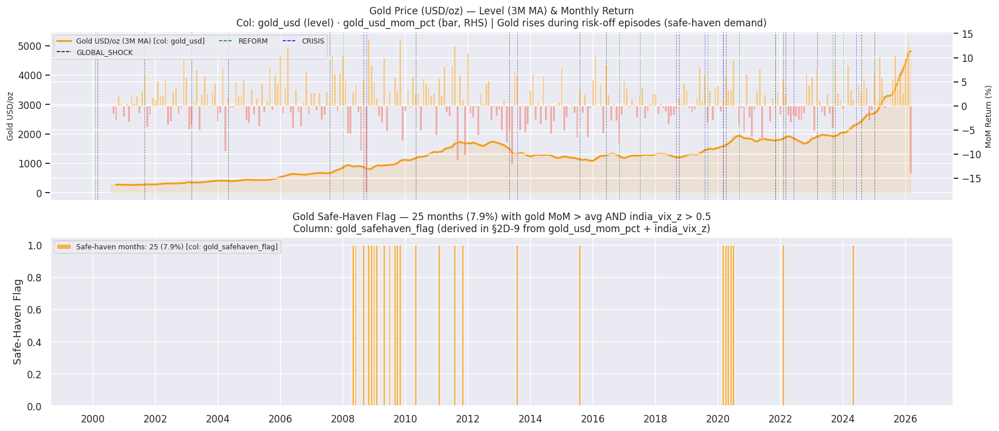


📊 Spearman r(gold_usd, gpr_india) = -0.009  (p = 0.8767, n = 308)
   ⚠️  Gold–GPR link is weak — may reflect long-run USD/Gold trend rather than stress demand.
   Suggestion: try Spearman r(gold_usd_mom_pct, gpr_india) for changes vs levels.


In [97]:
# ── 19j-e. Gold safe-haven demand analysis ───────────────────────────────────
# Research hypothesis: Gold rises during high-stress months (VIX↑ + GPR↑).
# This is the classic flight-to-quality effect: when equity risk is elevated,
# investors rotate into gold as a hedge, inflating the gold price.
#
# Column names used:
#   gold_usd          — month-end close price (Phase01B exact name)
#   gold_usd_mom_pct  — MoM % change (Phase01B exact name)
#   gold_safehaven_flag — binary flag derived in §2D-9
#                         (1 = gold_usd_mom_pct > historical mean AND india_vix_z > 0.5)

if 'gold_usd' in df.columns:
    fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
    event_handles = [Line2D([0], [0], color=c, linestyle='--', lw=1, label=l)
                     for _, c, l in event_groups]

    # ── Panel 1: Gold price level + MoM % return ─────────────────────────────
    axes[0].plot(df['period_dt'], df['gold_usd'].rolling(3).mean(),
                 color='#f39c12', lw=2, label='Gold USD/oz (3M MA) [col: gold_usd]')
    axes[0].fill_between(df['period_dt'], df['gold_usd'].ffill(),
                         alpha=0.12, color='#f39c12')

    # MoM % return bars: red = negative return, gold = positive return.
    if 'gold_usd_mom_pct' in df.columns:
        ax0b = axes[0].twinx()
        ax0b.bar(df['period_dt'], df['gold_usd_mom_pct'].fillna(0),
                 color=['#e74c3c' if v < 0 else '#f39c12' for v in df['gold_usd_mom_pct'].fillna(0)],
                 width=25, alpha=0.4, label='MoM return % (RHS) [col: gold_usd_mom_pct]')
        ax0b.set_ylabel('MoM Return (%)', fontsize=9)
    else:
        print('ℹ️  gold_usd_mom_pct not found — MoM bars skipped.')

    axes[0].set_title(
        'Gold Price (USD/oz) — Level (3M MA) & Monthly Return\n'
        'Col: gold_usd (level) · gold_usd_mom_pct (bar, RHS) | '
        'Gold rises during risk-off episodes (safe-haven demand)',
        fontsize=11)
    axes[0].set_ylabel('Gold USD/oz', fontsize=9)
    for annot_event, annot_color, _ in event_groups:
        for evt_dt, _ in annot_event:
            axes[0].axvline(pd.Timestamp(evt_dt), color=annot_color,
                            linestyle='--', lw=0.6, alpha=0.5)
    handles, lbls = axes[0].get_legend_handles_labels()
    axes[0].legend(handles + event_handles, lbls + [l for _, _, l in event_groups],
                   fontsize=8, loc='upper left', ncol=3)

    # ── Panel 2: Gold safe-haven flag — which months qualify ─────────────────
    # gold_safehaven_flag = 1 when gold_usd_mom_pct > its historical mean
    # AND india_vix_z > 0.5 (VIX above half a standard deviation).
    # Both conditions together confirm demand is stress-driven, not trend-driven.
    if 'gold_safehaven_flag' in df.columns:
        safe_months = df[df['gold_safehaven_flag'] == 1]
        axes[1].bar(df['period_dt'], df['gold_safehaven_flag'],
                    color='#f39c12', width=25, alpha=0.7,
                    label=f'Safe-haven months: {len(safe_months)} '
                          f'({len(safe_months)/len(df)*100:.1f}%) '
                          f'[col: gold_safehaven_flag]')
        axes[1].set_title(
            f'Gold Safe-Haven Flag — {len(safe_months)} months ({len(safe_months)/len(df)*100:.1f}%) '
            f'with gold MoM > avg AND india_vix_z > 0.5\n'
            f'Column: gold_safehaven_flag (derived in §2D-9 from gold_usd_mom_pct + india_vix_z)',
            fontsize=11)
        axes[1].set_ylabel('Safe-Haven Flag')
        axes[1].legend(fontsize=8)
    else:
        axes[1].set_visible(False)
        print('ℹ️  gold_safehaven_flag not found — safe-haven panel skipped.')
        print('   Check that §2D-9 completed without errors.')

    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    _save('Plot19j_d_gold_analysis.png')
    plt.show()

    # Spearman correlation: Gold level vs GPR India
    if 'gpr_india' in df.columns:
        valid = df[['gold_usd', 'gpr_india']].dropna()
        if len(valid) > 10:
            r, p = spearmanr(valid['gold_usd'], valid['gpr_india'])
            print(f'\n📊 Spearman r(gold_usd, gpr_india) = {r:.3f}  (p = {p:.4f}, n = {len(valid)})')
            if r > 0.3:
                print('   ✅ Safe-haven hypothesis supported — gold correlates with GPR stress.')
            else:
                print('   ⚠️  Gold–GPR link is weak — '
                      'may reflect long-run USD/Gold trend rather than stress demand.')
                print('   Suggestion: try Spearman r(gold_usd_mom_pct, gpr_india) for changes vs levels.')
else:
    print('⚠️  gold_usd column not found — Gold analysis skipped.')
    print('   Expected column name: gold_usd (Phase01B fetch_yf_monthly output)')


📁 Saved → /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot19j_e_market_stress_by_quartile.png


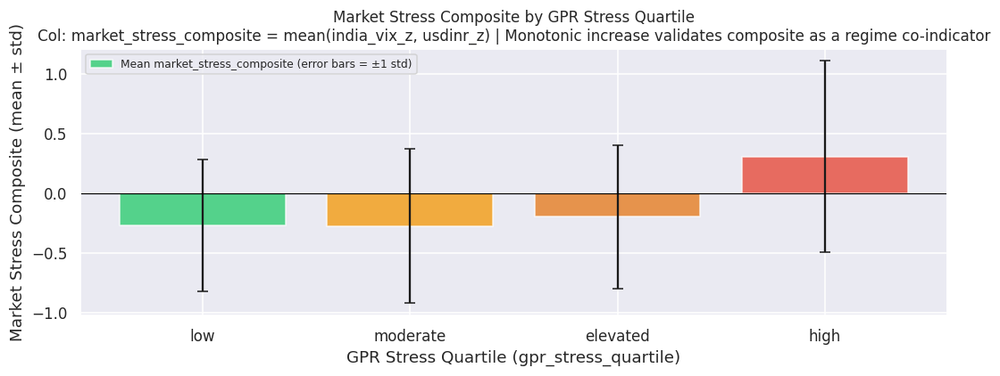


📊 Market Stress Composite by GPR Quartile (mean ± median ± std):
                      mean  median    std
gpr_stress_quartile                      
low                 -0.271  -0.178  0.551
moderate            -0.277  -0.184  0.646
elevated            -0.197  -0.135  0.603
high                 0.307   0.406  0.803

   Kruskal-Wallis H = 34.874, p = 0.0000
   ✅ Reject H₀ — market_stress_composite differs significantly across GPR quartiles.
   → Composite is aligned with the GPR regime labelling and suitable as a Phase03 feature.


In [99]:
# ── 19j-f. Market stress composite vs GPR stress quartile ───────────────────
# Validates that market_stress_composite (average of india_vix_z and usdinr_z)
# increases monotonically with the GPR-based stress quartile from Section 10.
#
# Why this matters: if market_stress_composite is a valid risk-off proxy, it should
# be higher in "elevated" and "high" GPR stress quarters than in "low" and "moderate".
# If it does not, the composite may need reweighting or the VIX/USDINR data needs review.
#
# Column names:
#   market_stress_composite — mean(india_vix_z, usdinr_z), derived in §2D-9
#   gpr_stress_quartile     — low / moderate / elevated / high, derived in §2D-9
# Statistical test: Kruskal-Wallis H-test (non-parametric ANOVA).
#   H₀: market_stress_composite distribution is the same across all four quartiles.
#   Reject H₀ if p < 0.05 → stress composite aligns with GPR regime labelling.

if 'market_stress_composite' in df.columns and 'gpr_stress_quartile' in df.columns:
    quartile_order = ['low', 'moderate', 'elevated', 'high']
    q_in_df = [q for q in quartile_order if q in df['gpr_stress_quartile'].unique()]

    if q_in_df:
        stress_by_q = (
            df.groupby('gpr_stress_quartile')['market_stress_composite']
            .agg(['mean', 'median', 'std'])
            .reindex(q_in_df)
        )

        fig, ax = plt.subplots(figsize=(10, 4))
        colors_q = [STRESS_COLORS[q] for q in q_in_df]
        ax.bar(q_in_df, stress_by_q['mean'], color=colors_q, alpha=0.8,
               yerr=stress_by_q['std'], capsize=4,
               label='Mean market_stress_composite (error bars = ±1 std)')
        ax.axhline(0, color='black', lw=0.8)
        ax.set_xlabel('GPR Stress Quartile (gpr_stress_quartile)')
        ax.set_ylabel('Market Stress Composite (mean ± std)')
        ax.set_title(
            'Market Stress Composite by GPR Stress Quartile\n'
            'Col: market_stress_composite = mean(india_vix_z, usdinr_z) | '
            'Monotonic increase validates composite as a regime co-indicator',
            fontsize=11)
        ax.legend(fontsize=8)
        plt.tight_layout()
        _save('Plot19j_e_market_stress_by_quartile.png')
        plt.show()

        print('\n📊 Market Stress Composite by GPR Quartile (mean ± median ± std):')
        print(stress_by_q.round(3).to_string())

        # Kruskal-Wallis H-test across quartiles
        groups = [
            df.loc[df['gpr_stress_quartile'] == q, 'market_stress_composite'].dropna().values
            for q in q_in_df
        ]
        groups = [g for g in groups if len(g) > 0]
        if len(groups) >= 2:
            from scipy.stats import kruskal
            stat, pval = kruskal(*groups)
            print(f'\n   Kruskal-Wallis H = {stat:.3f}, p = {pval:.4f}')
            if pval < 0.05:
                print('   ✅ Reject H₀ — market_stress_composite differs significantly across GPR quartiles.')
                print('   → Composite is aligned with the GPR regime labelling and suitable as a Phase03 feature.')
            else:
                print('   ⚠️  Cannot reject H₀ — composite does not discriminate GPR quartiles.')
                print('   → Review VIX/USDINR data or consider reweighting the composite.')
    else:
        print(f'⚠️  No valid GPR stress quartile labels found in {df['gpr_stress_quartile']}.')
        print('   Expected: low / moderate / elevated / high')
else:
    missing_c = [c for c in ['market_stress_composite', 'gpr_stress_quartile'] if c not in df.columns]
    print(f'⚠️  Skipping market stress composite validation — missing columns: {missing_c}')
    print('   Both are created in §2D-9. Re-run that cell and try again.')


---
## 20. EDA Summary & Phase 03 Readiness
**Research note**: Final summary of data quality, identified issues, and recommended actions
before passing `cleaned/gpr_combined_monthly_clean_base.csv` into feature engineering and `cleaned/gpr_combined_monthly_clean.csv` into Phase 03 modelling.


In [100]:
# ── 20a. Final data quality scorecard ────────────────────────────────────────
print('=' * 70)
print('PHASE 02B EDA SUMMARY — DATA QUALITY SCORECARD')
print('=' * 70)

total_months = len(df)
print(f'\n📅 Coverage')
print(f'   Total months      : {total_months} ({df["period"].min()} → {df["period"].max()})')
print(f'   Total features     : {df.shape[1]}')

print(f'\n📰 News Corpus')
if not corpus.empty:
    print(f'   Total articles     : {len(corpus):,}')
    print(f'   Unique sources     : {corpus["source"].nunique()}')
    if 'source_group' in corpus.columns:
        print(f'   Source groups      : {corpus["source_group"].value_counts().to_dict()}')

print(f'\n📊 GPR Index')
if 'gpr_india' in df.columns:
    gpr_coverage = df['gpr_india'].notna().mean() * 100
    print(f'   India GPR coverage : {gpr_coverage:.1f}%')
    print(f'   India GPR mean     : {df["gpr_india"].mean():.2f}')

print(f'\n💬 Sentiment')
if 'net_sentiment_mean' in df.columns:
    sent_cov = df['net_sentiment_mean'].notna().mean() * 100
    print(f'   Coverage           : {sent_cov:.1f}%')
    print(f'   Mean net sentiment : {df["net_sentiment_mean"].mean():.4f}')
    print(f'   Bearish months     : {(df["net_sentiment_mean"] < -0.10).sum()} of {total_months}')

print(f'\n📉 FRED Macro')
if fred_feature_cols:
    avg_cov = df[fred_feature_cols].notna().mean().mean() * 100
    print(f'   Feature columns    : {len(fred_feature_cols)}')
    print(f'   Avg coverage       : {avg_cov:.1f}%')

print(f'\n🔴 Missing Data')
high_miss = (df.isnull().mean() > 0.3).sum()
medium_miss = ((df.isnull().mean() > 0.1) & (df.isnull().mean() <= 0.3)).sum()
print(f'   Features >30% missing : {high_miss}')
print(f'   Features 10–30% missing : {medium_miss}')

print(f'\n✅ Phase 03 Readiness Assessment')
readiness = [
    ('GPR Index (India + Global)',      'gpr_india' in df.columns),
    ('Monthly Sentiment Table',         'net_sentiment_mean' in df.columns),
    ('Risk Category Features',          'count_financial' in df.columns),
    ('Regime Events Table',             'event_count' in df.columns),
    ('FRED Macro Features',             len(fred_feature_cols) > 5),
    ('Composite Stress Score',          'gpr_composite_score' in df.columns),
    ('Stress Quartile Labels',          'gpr_stress_quartile' in df.columns),
    ('is_finbert_sentiment flag',       'is_finbert_sentiment' in df.columns),
    ('Base cleaned table saved',        os.path.exists(CLEAN_BASE_OUT) if 'CLEAN_BASE_OUT' in dir() else False),
    ('Cleaned + engineered table saved', os.path.exists(CLEAN_OUT) if 'CLEAN_OUT' in dir() else False),
    ('GDELT2 article backbone',         not gdelt2.empty),
    ('Alpha Vantage coverage',          not av_sent.empty),
    # §4.2.6 Sustainability checks
    ('§4.2.6 Climate-Risk News Share',             'climate_news_share' in df.columns),
    ('§4.2.6 Green-Transition Event Density',       'count_green_transition' in df.columns),
    ('§4.2.6 ESG Sentiment Score',                 'esg_sentiment_score' in df.columns),
    ('§4.2.6 CPU Index variant available',             any(c in df.columns for c in ['cpu_index_broad', 'cpu_index_narrow', 'cpu_index_gavriilidis', 'cpu_index'])),
    ('§4.2.6 CPU Shock Z-score (cpu_shock_z)',      'cpu_shock_z' in df.columns),
    ('§4.2.6 Sustainability-Sensitive GPR',        'sustain_gpr' in df.columns),
    ('§4.2.6 Green-Transition sentiment',          'sent_green_transition' in df.columns),
    ('§4.2.6 ESG category sentiment',              'sent_esg' in df.columns),
    # Phase01B specific
    ('§4.2.6 CPU 3M MA (cpu_3m_ma)',               'cpu_3m_ma' in df.columns),
    ('§4.2.6 CPU YoY change (cpu_yoy)',             'cpu_yoy' in df.columns),
    ('§4.2.6 CPU Spike flag (cpu_spike)',           'cpu_spike' in df.columns),
    ('GDELT1 Raw Tone (gdelt1_tone_raw)',            'gdelt1_tone_raw' in df.columns),
    ('GDELT1 Goldstein Scale (gdelt1_goldstein)',    'gdelt1_goldstein' in df.columns),
    ('AV Monthly Sentiment (av_sentiment_mean)',    'av_sentiment_mean' in df.columns),
    # §16B Market data checks
    # Phase01B §16B — column names are as produced by fetch_yf_monthly(), never renamed.
    ('§16B India VIX close (india_vix)',             'india_vix' in df.columns),
    ('§16B India VIX MoM (india_vix_mom_pct)',       'india_vix_mom_pct' in df.columns),
    ('§16B India VIX z-score 12M (india_vix_zscore12)', 'india_vix_zscore12' in df.columns),
    ('§16B India VIX full-sample z (india_vix_z)',   'india_vix_z' in df.columns),
    ('§16B USD/INR close (usdinr)',                  'usdinr' in df.columns),
    ('§16B USD/INR MoM (usdinr_mom_pct)',            'usdinr_mom_pct' in df.columns),
    ('§16B USD/INR full-sample z (usdinr_z)',        'usdinr_z' in df.columns),
    ('§16B Gold close (gold_usd)',                   'gold_usd' in df.columns),
    ('§16B Gold MoM (gold_usd_mom_pct)',             'gold_usd_mom_pct' in df.columns),
    ('§16B Gold full-sample z (gold_usd_z)',         'gold_usd_z' in df.columns),
    ('§16B Market Stress Composite',                 'market_stress_composite' in df.columns),
    ('§16B Gold Safe-Haven Flag',                    'gold_safehaven_flag' in df.columns),
]

# Sustainability sub-scorecard
print(f'\n🌱 §4.2.6 Sustainability Variables')
market_present = [r[0] for r in readiness if r[0].startswith('§16B') and r[1]]
market_missing = [r[0] for r in readiness if r[0].startswith('§16B') and not r[1]]
print(f'\n📈 §16B Market Data Variables')
print(f'   Present : {len(market_present)}/{sum(1 for r in readiness if r[0].startswith("§16B"))}')
for s in market_missing:
    print(f'   ⚠️  Missing: {s}')

sustain_present  = [r[0] for r in readiness if r[0].startswith('§4.2.6') and r[1]]
sustain_missing  = [r[0] for r in readiness if r[0].startswith('§4.2.6') and not r[1]]
print(f'   Present : {len(sustain_present)}/{sum(1 for r in readiness if r[0].startswith('§4.2.6'))}')
for s in sustain_missing:
    print(f'   ⚠️  Missing: {s}')
for item, status in readiness:
    print(f'   {"✅" if status else "❌"} {item}')

PHASE 02B EDA SUMMARY — DATA QUALITY SCORECARD

📅 Coverage
   Total months      : 315 (2000-01 → 2026-03)
   Total features     : 170

📰 News Corpus
   Total articles     : 12,940
   Unique sources     : 19
   Source groups      : {'GDELT2': 10377, 'Wayback': 1522, 'RSS': 699, 'AlphaVantage': 298, 'Other': 44}

📊 GPR Index
   India GPR coverage : 100.0%
   India GPR mean     : 0.23

💬 Sentiment
   Coverage           : 100.0%
   Mean net sentiment : -0.0090
   Bearish months     : 37 of 315

📉 FRED Macro
   Feature columns    : 23
   Avg coverage       : 85.7%

🔴 Missing Data
   Features >30% missing : 34
   Features 10–30% missing : 9

✅ Phase 03 Readiness Assessment

🌱 §4.2.6 Sustainability Variables

📈 §16B Market Data Variables
   Present : 12/12
   Present : 11/11
   ✅ GPR Index (India + Global)
   ✅ Monthly Sentiment Table
   ✅ Risk Category Features
   ✅ Regime Events Table
   ✅ FRED Macro Features
   ✅ Composite Stress Score
   ✅ Stress Quartile Labels
   ✅ is_finbert_sentiment 

In [101]:
print('\n' + '=' * 70)
print('RECOMMENDATIONS FOR PHASE 03 FEATURE ENGINEERING')
print('=' * 70)

cpu_shock_feature = next((c for c in ['cpu_shock_z', 'cpu_shock'] if c in df.columns), None)
sustain_composite_parts = ['climate_news_share', 'green_transition_share', 'esg_sentiment_score']
if cpu_shock_feature:
    sustain_composite_parts.append(cpu_shock_feature)
sustain_composite_text = ', '.join(sustain_composite_parts)
phase03_sustain_parts = ['climate_news_share_ma7', 'green_transition_share_ma7', 'esg_sentiment_score']
if cpu_shock_feature:
    phase03_sustain_parts.append(cpu_shock_feature)
phase03_sustain_parts.append('sustain_gpr_z')
phase03_sustain_text = ', '.join(phase03_sustain_parts)

recs = [
    ('IMPUTATION',       'Phase02B creates `net_sentiment_model` using raw FinBERT/AV where available and GDELT1 tone as a pre-2015 proxy. Keep `is_finbert_sentiment` and `sentiment_source` as model covariates.'),
    ('FRED QUARTERLY',   'Quarterly FRED series are forward-filled (limit=3). '
                         'Avoid as high-frequency signals; treat as slowly-varying background.'),
    ('STATIONARITY',     'Run ADF on all FRED series before Phase 03. Difference/detrend '
                         'non-stationary series before feeding to ML models.'),
    ('CORRELATION',      'gpr_india and negative_mean are correlated → multicollinearity risk. '
                         'Consider PCA or VIF analysis in Phase 03.'),
    ('LAG FEATURES',     'Use ACF/PACF from Section 14b to choose lags for GPR, sentiment, yield spread. '
                         'Target: 1, 3, 6, 12 month lags as starting set.'),
    ('WEIGHTING',        '0.4/0.3/0.3 composite weights are heuristic. Validate via ablation study '
                         'and compare against equal-weight and PCA-based composite.'),
    ('VALIDATION',       'Verify top-stress months include: 2008-10 (Lehman), 2020-03 (COVID), '
                         '2022-02 (Russia-Ukraine). See Section 10b output.'),
    ('GDELT GAPS',       'Re-check GDELT2 gap months (Section 17a). Fill with GDELT1 AvgTone '
                         'for months where GDELT2 is absent but GPR data exists.'),
    ('AV ALIGNMENT',     'Alpha Vantage covers ~2 years. Validate its correlation with FinBERT '
                         'for the overlap period (Section 16). Use as ensemble signal in Phase 03.'),
    ('YIELD CURVE',      'Yield spread inversions (Section 14a) are strong recession proxies. '
                         'Add `yield_curve_inverted` binary feature for Phase 03.'),
    ('MARKET DATA',      'India VIX, USD/INR, Gold are strong risk-regime co-indicators (Section 19j). '
                         'Use market_stress_composite and gold_safehaven_flag as complementary features '
                         'alongside GPR. Validate VIX-GPR co-movement correlation ≥ 0.4 before using '
                         'VIX as a primary signal.'),
    ('CLEAN TABLE',      'Use `cleaned/gpr_combined_monthly_clean_base.csv` as the base cleaned input for feature engineering audits, and `cleaned/gpr_combined_monthly_clean.csv` after Section 2D-9 as the Phase 03 feature table. Both preserve the complete monthly grid and structural cleaning choices.'),
]

# §4.2.6 Sustainability recommendations
sustain_recs = [
    ('CLIMATE SHARE',     'climate_news_share spikes during monsoon (Jun–Sep) and COP events. '
                          'Add calendar-month dummies and COP-event flags as model covariates '
                          'to avoid spurious seasonality signals in regime detection.'),
    ('GREEN TRANSITION',  'green_transition_density rises monotonically post-2015 (India renewable push). '
                          'Detrend using 24-month rolling mean before feeding to ML models '
                          'to avoid structural-break leakage in walk-forward backtest.'),
    ('ESG SENTIMENT',     'esg_sentiment_score is sparser pre-2018 (fewer ESG articles). '
                          'Use is_finbert_sentiment + esg_news_share as coverage covariates. '
                          'Negative ESG sentiment hypothesised to precede drawdowns — test with '
                          'Granger causality vs NIFTY50 returns in Phase 03.'),
    ('CPU INDEX',         'CPU index may have limited India-specific signal (constructed from '
                          'US/EU newspaper text). Validate correlation with Indian climate-policy '
                          'events (budget green allocations, SEBI ESG mandates) before weighting heavily. '
                          'If CPU coverage is sparse, use count_climate / climate_news_share as proxy.'),
    ('SUSTAIN GPR',       'sustain_gpr interaction term (GPR × climate_share) will be near-zero '
                          'pre-2010 (low climate news share). Treat as regime-specific feature: '
                          'use only in post-2015 sub-models or with temporal weighting.'),
    ('SUSTAINABILITY COMPOSITE', 'Consider a §4.2.6 sustainability composite = weighted average of '
                          f'{sustain_composite_text}. '
                          'Weights: validate via ablation study or PCA — do not use 0.4/0.3/0.3 heuristic '
                          'without empirical validation specific to Indian market regimes.'),
    ('ESG × GPR INTERACTION', 'sustain_gpr peaks during Russia-Ukraine energy shock (2022) and '
                          'India-China border tensions (rare-earth supply chain risk). '
                          'These are precisely the §4.2.6 "sustainability-sensitive geopolitical" events. '
                          'Flag these months explicitly for regime-detection stress testing.'),
    ('PHASE 03 FEATURE SET', 'Recommended §4.2.6 feature set for Phase 03 input: '
                          f'{phase03_sustain_text}. Drop raw counts (use shares/z-scores only).'),
]

print('\n' + '─' * 70)
print('§4.2.6 SUSTAINABILITY FEATURE RECOMMENDATIONS FOR PHASE 03')
print('─' * 70)
for tag, text in sustain_recs:
    print(f'\n  [SUSTAIN-{tag}]')
    print(f'  → {text}')

for tag, text in recs:
    print(f'\n  [{tag}]')
    print(f'  → {text}')

print('\n✅ Phase 02B EDA & Cleaning Notebook complete.')



RECOMMENDATIONS FOR PHASE 03 FEATURE ENGINEERING

──────────────────────────────────────────────────────────────────────
§4.2.6 SUSTAINABILITY FEATURE RECOMMENDATIONS FOR PHASE 03
──────────────────────────────────────────────────────────────────────

  [SUSTAIN-CLIMATE SHARE]
  → climate_news_share spikes during monsoon (Jun–Sep) and COP events. Add calendar-month dummies and COP-event flags as model covariates to avoid spurious seasonality signals in regime detection.

  [SUSTAIN-GREEN TRANSITION]
  → green_transition_density rises monotonically post-2015 (India renewable push). Detrend using 24-month rolling mean before feeding to ML models to avoid structural-break leakage in walk-forward backtest.

  [SUSTAIN-ESG SENTIMENT]
  → esg_sentiment_score is sparser pre-2018 (fewer ESG articles). Use is_finbert_sentiment + esg_news_share as coverage covariates. Negative ESG sentiment hypothesised to precede drawdowns — test with Granger causality vs NIFTY50 returns in Phase 03.

  [SUSTA

In [102]:
# ── EDA Plot Index — list all saved figures ───────────────────────────────────
saved_plots = sorted([f for f in os.listdir(PLOT_DIR) if f.endswith('.png')])
print(f'\n📊 EDA Plots saved to: {PLOT_DIR}')
print(f'   Total plots: {len(saved_plots)}\n')
for i, fname in enumerate(saved_plots, 1):
    fpath = os.path.join(PLOT_DIR, fname)
    fsize = os.path.getsize(fpath) / 1024
    print(f'   {i:2d}. {fname:55s} ({fsize:.1f} KB)')
print('\n✅ All EDA plots saved to Google Drive.')


📊 EDA Plots saved to: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots
   Total plots: 112

    1. Plot01_BANKNIFTY_1day_basic_eda.png                     (147.0 KB)
    2. Plot01_NIFTY50_1day_basic_eda.png                       (137.9 KB)
    3. Plot01_NIFTYNEXT50_1day_basic_eda.png                   (140.2 KB)
    4. Plot02_BANKNIFTY_volatility_clustering.png              (49.5 KB)
    5. Plot02_NIFTY50_volatility_clustering.png                (49.5 KB)
    6. Plot02_NIFTYNEXT50_volatility_clustering.png            (50.0 KB)
    7. Plot03_all_symbols_qq_plot.png                          (104.5 KB)
    8. Plot04_BANKNIFTY_regime_segmentation.png                (193.7 KB)
    9. Plot04_NIFTY50_regime_segmentation.png                  (190.4 KB)
   10. Plot04_NIFTYNEXT50_regime_segmentation.png              (192.8 KB)
   11. Plot05_BANKNIFTY_intraday_daily_lead_lag.png            (104.5 KB)
   12. Plot05_NIFTY50_intraday_daily_lead_lag.png              (110.6 